In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

BASE = Path(r"C:\livinglab")
DATA = BASE / "데이터"

print("데이터 폴더 존재:", DATA.exists())
print("\n파일 목록:")

for p in DATA.rglob("*"):
    if p.is_file():
        print(p.relative_to(DATA))

데이터 폴더 존재: True

파일 목록:
2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv
tnSubwayEntrc.csv
서울시 교차로 및 횡단보도 시설·위치정보_20260824.xlsx
서울시 대규모점포 인허가 정보.csv
서울시 전통시장 현황(2026년 하반기).xlsx
서울시 지하철 출입구 리프트 위치정보.csv
서울시 지하철역 연계 지하도 공간정보.csv
서울시버스정류소위치정보(20260902) (1).xlsx
컬럼정의_서울시 버스정류소 위치정보.xlsx
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260901.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260902.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260903.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260904.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260905.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260906.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260907.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260908.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260909.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260910.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260911.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260912.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260913.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260914.csv
[내국인] 서울 생활인구(250m)\250_LOCAL_RESD_20260915.csv
[내국인

In [2]:
from pathlib import Path
import pandas as pd
import pyogrio

BASE = Path(r"C:\livinglab")
DATA = BASE / "데이터"

# --------------------------------------------------
# 1. 생활인구 파일 개수 확인
# --------------------------------------------------
pop_dirs = {
    "내국인": DATA / "[내국인] 서울 생활인구(250m)",
    "장기외국인": DATA / "[장기외국인] 서울 생활인구(250m)",
    "단기외국인": DATA / "[단기외국인] 서울 생활인구(250m)",
}

print("=== 생활인구 파일 개수 ===")
for name, folder in pop_dirs.items():
    files = sorted(folder.glob("*.csv"))
    print(f"{name}: {len(files)}개")
    if files:
        print("  첫 파일:", files[0].name)
        print("  마지막 파일:", files[-1].name)


# --------------------------------------------------
# 2. CSV를 안전하게 조금만 읽는 함수
# --------------------------------------------------
def read_csv_sample(path, nrows=5):
    encodings = ["utf-8-sig", "cp949", "euc-kr", "utf-8"]

    for enc in encodings:
        try:
            df = pd.read_csv(path, encoding=enc, nrows=nrows)
            return df, enc
        except UnicodeDecodeError:
            continue

    raise ValueError(f"인코딩을 찾지 못함: {path}")


# --------------------------------------------------
# 3. 주요 CSV 구조 확인
# --------------------------------------------------
csv_files = {
    "버스 시간대별 승하차": DATA / "2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv",
    "지하철 출입구": DATA / "tnSubwayEntrc.csv",
    "대규모점포": DATA / "서울시 대규모점포 인허가 정보.csv",
    "지하철 리프트": DATA / "서울시 지하철 출입구 리프트 위치정보.csv",
    "지하철 연계 지하도": DATA / "서울시 지하철역 연계 지하도 공간정보.csv",
}

print("\n=== 주요 CSV ===")

for name, path in csv_files.items():
    print(f"\n[{name}]")
    print("파일 크기:", round(path.stat().st_size / 1024**2, 2), "MB")

    try:
        df, enc = read_csv_sample(path)
        print("인코딩:", enc)
        print("컬럼:")
        print(df.columns.tolist())
        print("\n앞 2행:")
        display(df.head(2))
    except Exception as e:
        print("오류:", e)


# --------------------------------------------------
# 4. 주요 Excel 구조 확인
# --------------------------------------------------
excel_files = {
    "횡단보도": DATA / "서울시 교차로 및 횡단보도 시설·위치정보_20260824.xlsx",
    "버스정류장": DATA / "서울시버스정류소위치정보(20260902) (1).xlsx",
    "전통시장": DATA / "서울시 전통시장 현황(2026년 하반기).xlsx",
}

print("\n=== 주요 Excel ===")

for name, path in excel_files.items():
    print(f"\n[{name}]")
    try:
        df = pd.read_excel(path, nrows=5)
        print("컬럼:")
        print(df.columns.tolist())
        print("\n앞 2행:")
        display(df.head(2))
    except Exception as e:
        print("오류:", e)


# --------------------------------------------------
# 5. 생활인구 샘플 구조 확인
# --------------------------------------------------
print("\n=== 생활인구 샘플 ===")

for name, folder in pop_dirs.items():
    files = sorted(folder.glob("*.csv"))

    if not files:
        print(f"{name}: 파일 없음")
        continue

    # 9월 30일 파일이 있으면 그것 사용
    target = [p for p in files if "20260930" in p.name]
    path = target[0] if target else files[0]

    print(f"\n[{name}] {path.name}")

    try:
        df, enc = read_csv_sample(path)
        print("인코딩:", enc)
        print("컬럼:")
        print(df.columns.tolist())
        print("\n앞 2행:")
        display(df.head(2))
    except Exception as e:
        print("오류:", e)


# --------------------------------------------------
# 6. 250m 격자 shapefile 정보 확인
# --------------------------------------------------
grid_path = DATA / "빈격자(250m)" / "빈격자(250m).shp"

print("\n=== 250m 격자 SHP ===")

try:
    info = pyogrio.read_info(grid_path)

    print("Geometry type:", info.get("geometry_type"))
    print("CRS:", info.get("crs"))
    print("Feature 수:", info.get("features"))
    print("속성 컬럼:")
    print(info.get("fields"))

except Exception as e:
    print("오류:", e)


=== 생활인구 파일 개수 ===
내국인: 30개
  첫 파일: 250_LOCAL_RESD_20260901.csv
  마지막 파일: 250_LOCAL_RESD_20260930.csv
장기외국인: 30개
  첫 파일: 250_FORN_LONG_20260901.csv
  마지막 파일: 250_FORN_LONG_20260930.csv
단기외국인: 30개
  첫 파일: 250_FORN_TEMP_20260901.csv
  마지막 파일: 250_FORN_TEMP_20260930.csv

=== 주요 CSV ===

[버스 시간대별 승하차]
파일 크기: 14.74 MB
인코딩: cp949
컬럼:
['사용년월', '노선번호', '노선명', '표준버스정류장ID', '버스정류장ARS번호', '역명', '00시승차총승객수', '00시하차총승객수', '1시승차총승객수', '1시하차총승객수', '2시승차총승객수', '2시하차총승객수', '3시승차총승객수', '3시하차총승객수', '4시승차총승객수', '4시하차총승객수', '5시승차총승객수', '5시하차총승객수', '6시승차총승객수', '6시하차총승객수', '7시승차총승객수', '7시하차총승객수', '8시승차총승객수', '8시하차총승객수', '9시승차총승객수', '9시하차총승객수', '10시승차총승객수', '10시하차총승객수', '11시승차총승객수', '11시하차총승객수', '12시승차총승객수', '12시하차총승객수', '13시승차총승객수', '13시하차총승객수', '14시승차총승객수', '14시하차총승객수', '15시승차총승객수', '15시하차총승객수', '16시승차총승객수', '16시하차총승객수', '17시승차총승객수', '17시하차총승객수', '18시승차총승객수', '18시하차총승객수', '19시승차총승객수', '19시하차총승객수', '20시승차총승객수', '20시하차총승객수', '21시승차총승객수', '21시하차총승객수', '22시승차총승객수', '22시하차총승객수', '23시승차총승객수', '23시하차총승객수', '교통수단타입

,사용년월,노선번호,노선명,표준버스정류장ID,버스정류장ARS번호,역명,00시승차총승객수,00시하차총승객수,1시승차총승객수,1시하차총승객수,...,20시하차총승객수,21시승차총승객수,21시하차총승객수,22시승차총승객수,22시하차총승객수,23시승차총승객수,23시하차총승객수,교통수단타입코드,교통수단타입명,등록일자
0,202609,470,470번(상암차고지~안골마을),100000001,1001,종로2가사거리(00063),196,170,0,0,...,436,363,256,346,313,322,232,10,서울간선버스,20261003
1,202609,N37,N37번(송파공영차고지~진관공영차고지),100000001,1001,종로2가사거리(00032),30,19,258,200,...,0,0,0,0,0,0,0,51,서울심야버스,20261003



[지하철 출입구]
파일 크기: 2.66 MB
인코딩: utf-8-sig
컬럼:
['지하철역ID', '출입구번호', '정류장ID', '주변건물', '출구와정류장간이동거리', '지하철역X좌표', '지하철역Y좌표']

앞 2행:


,지하철역ID,출입구번호,정류장ID,주변건물,출구와정류장간이동거리,지하철역X좌표,지하철역Y좌표
0,﻿1002000228,﻿2,﻿6858,﻿서울법학원.국민은행. 농협.굿모닝신한증권.디오슈페리어빌딩.KFC.대우슈페리움,﻿189,﻿195710.0,﻿442518.2
1,﻿1007000715,﻿4,﻿110000662,﻿장미아파트.중현초등학교.하계2동사무소.하계5단지아파트.하계사회복지관,﻿51,﻿206032.1,﻿459511.0



[대규모점포]
파일 크기: 0.41 MB
인코딩: cp949
컬럼:
['개방자치단체코드', '관리번호', '인허가일자', '인허가취소일자', '영업상태코드', '영업상태명', '상세영업상태코드', '상세영업상태명', '폐업일자', '휴업시작일자', '휴업종료일자', '재개업일자', '전화번호', '소재지면적', '소재지우편번호', '지번주소', '도로명주소', '도로명우편번호', '사업장명', '최종수정일자', '데이터갱신구분', '데이터갱신일자', '업태구분명', '좌표정보(X)', '좌표정보(Y)', '점포구분명']

앞 2행:


...


[장기외국인] 250_FORN_LONG_20260930.csv
인코딩: cp949
컬럼:
['일자', '시간', '행정동코드', '250M격자', '생활인구합계', '네팔', '러시아', '몽골', '미국', '미얀마', '방글라데시', '베트남', '스리랑카', '우즈베키스탄', '인도 ', '인도네시아', '일본', '중국', '카자흐스탄', '캄보디아', '캐나다', '태국', '파키스탄', '프랑스', '필리핀', '기타']

앞 2행:


일자    시간 행정동코드 250M격자 생활인구합계 네팔  \
20260930 0 11470550 다사45504825 15.44 * *  *     *     *      *      *  *   
           11110515 다사52755325 26.26 * *  *  4.99     *      *      *  *   

                                           러시아 몽골 미국 미얀마  ...    일본 중국 카자흐스탄  \
20260930 0 11470550 다사45504825 15.44 * *  5.85  *  *   *  ...     *  *     *   
           11110515 다사52755325 26.26 * *     *  *  *   *  ...  7.72  *  7.72   

                                         캄보디아 캐나다  태국 파키스탄 프랑스 필리핀  기타  
20260930 0 11470550 다사45504825 15.44 * *  NaN NaN NaN  NaN NaN NaN NaN  
           11110515 다사52755325 26.26 * *  NaN NaN NaN  NaN NaN NaN NaN  

[2 rows x 26 columns]


[단기외국인] 250_FORN_TEMP_20260930.csv
인코딩: cp949
컬럼:
['일자', '시간', '행정동코드', '250M격자', '생활인구합계', '네팔', '러시아', '몽골', '미국', '베트남', '스리랑카', '우즈베키스탄', '인도', '인도네시아', '일본', '중국', '카자흐스탄', '캄보디아', '캐나다', '태국', '파키스탄', '프랑스', '필리핀', '기타']

앞 2행:


일자 시간 행정동코드 250M격자 생활인구합계 네팔  \
20260930 0 11110515 다사52505350 33.58 * * * *     *  *     *      *      *  *   
                    다사52755325 24.82 * * * 7.36  *  *     *      *      *  *   

                                                  러시아 몽골 미국 베트남  ...    일본  \
20260930 0 11110515 다사52505350 33.58 * * * *        *  *  *   *  ...  5.06   
                    다사52755325 24.82 * * * 7.36  5.86  *  *   *  ...  4.14   

                                                 중국 카자흐스탄 캄보디아 캐나다  태국  파키스탄  \
20260930 0 11110515 다사52505350 33.58 * * * *    NaN   NaN  NaN NaN NaN   NaN   
                    다사52755325 24.82 * * * 7.36 NaN   NaN  NaN NaN NaN   NaN   

                                                 프랑스  필리핀  기타  
20260930 0 11110515 다사52505350 33.58 * * * *     NaN  NaN NaN  
                    다사52755325 24.82 * * * 7.36  NaN  NaN NaN  

[2 rows x 24 columns]


=== 250m 격자 SHP ===
Geometry type: Polygon
CRS: EPSG:5179
Feature 수: 1693148
속성 컬럼:
['SPO_NO_CD' 'SECT_CD']


In [3]:
import re
import pandas as pd
import pyogrio
from pathlib import Path

BASE = Path(r"C:\livinglab")
DATA = BASE / "데이터"

# -----------------------------------
# 1. 9/30 내국인 생활인구 격자 ID
# -----------------------------------
pop_path = (
    DATA
    / "[내국인] 서울 생활인구(250m)"
    / "250_LOCAL_RESD_20260930.csv"
)

pop = pd.read_csv(
    pop_path,
    encoding="cp949",
    usecols=["250M격자"]
)

pop_ids = set(pop["250M격자"].astype(str).unique())

print("생활인구 고유 격자 수:", len(pop_ids))


# -----------------------------------
# 2. 전국 빈격자 중 서울만 읽기
# SECT_CD가 11로 시작 = 서울
# -----------------------------------
grid_path = DATA / "빈격자(250m)" / "빈격자(250m).shp"

grid = pyogrio.read_dataframe(
    grid_path,
    where="SECT_CD LIKE '11%'",
    columns=["SPO_NO_CD", "SECT_CD"],
    encoding="UTF-8"
)

print("서울 격자 수:", len(grid))


# -----------------------------------
# 3. SHP 격자코드 → 생활인구 격자코드 변환
# -----------------------------------
quarter_map = {
    "aa": "00",
    "ab": "25",
    "ba": "50",
    "bb": "75"
}

def convert_grid_code(code):
    pattern = r"(.{2})(\d{2})(aa|ab|ba|bb)(\d{2})(aa|ab|ba|bb)$"
    m = re.match(pattern, str(code))

    if m is None:
        return None

    return (
        m.group(1)
        + m.group(2)
        + quarter_map[m.group(3)]
        + m.group(4)
        + quarter_map[m.group(5)]
    )

grid["250M격자"] = grid["SPO_NO_CD"].apply(convert_grid_code)

display(grid[["SPO_NO_CD", "250M격자", "SECT_CD"]].head(10))


# -----------------------------------
# 4. 실제 매칭률
# -----------------------------------
grid_ids = set(grid["250M격자"].dropna())

matched = pop_ids & grid_ids
unmatched = pop_ids - grid_ids

print("매칭된 생활인구 격자:", len(matched))
print("매칭 안 된 생활인구 격자:", len(unmatched))
print("매칭률:", round(len(matched) / len(pop_ids) * 100, 4), "%")

print("\n매칭 안 된 격자:")
print(sorted(unmatched))

생활인구 고유 격자 수: 8570
서울 격자 수: 11309


,SPO_NO_CD,250M격자,SECT_CD
0,다사52aa54ba,다사52005450,11110
1,다사52ba57ab,다사52505725,11110
2,다사53aa55ab,다사53005525,11110
3,다사53ab55ab,다사53255525,11110
4,다사55ab51ab,다사55255125,11140
5,다사51aa47bb,다사51004775,11170
6,다사52aa48bb,다사52004875,11170
7,다사53aa46bb,다사53004675,11170
8,다사54aa49aa,다사54004900,11170
9,다사55aa48ba,다사55004850,11170


매칭된 생활인구 격자: 8568
매칭 안 된 생활인구 격자: 2
매칭률: 99.9767 %

매칭 안 된 격자:
['다사47256125', '다사67254075']


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

BASE = Path(r"C:\livinglab")
DATA = BASE / "데이터"

pop_dirs = {
    "내국인": DATA / "[내국인] 서울 생활인구(250m)",
    "장기외국인": DATA / "[장기외국인] 서울 생활인구(250m)",
    "단기외국인": DATA / "[단기외국인] 서울 생활인구(250m)",
}

KEYS = ["일자", "시간", "250M격자"]


def load_population_month(folder, label):

    files = sorted(folder.glob("*.csv"))
    parts = []

    total_suppressed = 0

    for path in tqdm(files, desc=label):

        # 중요:
        # 외국인 CSV는 행 끝에 불필요한 빈 필드가 더 있어서
        # 앞 5개 컬럼만 위치 기준으로 읽는다.
        df = pd.read_csv(
            path,
            encoding="cp949",
            usecols=range(5),
            index_col=False,
            dtype="string"
        )

        # 앞 5개 컬럼 이름을 확실히 통일
        df.columns = [
            "일자",
            "시간",
            "행정동코드",
            "250M격자",
            "생활인구합계"
        ]

        # 문자열 공백 제거
        for col in df.columns:
            df[col] = df[col].str.strip()

        # 시간 숫자화
        df["시간"] = pd.to_numeric(
            df["시간"],
            errors="coerce"
        )

        # 기본 키가 정상인 행만 유지
        valid = (
            df["일자"].str.match(r"^\d{8}$", na=False)
            & df["시간"].between(0, 23)
            & df["250M격자"].str.match(r"^[가-힣]{2}\d{8}$", na=False)
        )

        if (~valid).any():
            print(
                f"{path.name}: 비정상 키 행 {(~valid).sum()}개"
            )

        df = df.loc[valid].copy()

        df["시간"] = df["시간"].astype("int8")

        # '*' 여부는 따로 보존
        df["비공개"] = df["생활인구합계"].eq("*")

        total_suppressed += df["비공개"].sum()

        # 숫자로 공개된 값만 숫자화
        df["생활인구값"] = pd.to_numeric(
            df["생활인구합계"],
            errors="coerce"
        )

        # 같은 격자가 행정동 경계에 걸쳐 여러 행이면 합산
        daily = (
            df.groupby(
                KEYS,
                as_index=False,
                observed=True
            )
            .agg(
                **{
                    label: (
                        "생활인구값",
                        lambda x: x.sum(min_count=1)
                    ),
                    f"{label}_비공개": (
                        "비공개",
                        "any"
                    )
                }
            )
        )

        parts.append(daily)

    result = pd.concat(
        parts,
        ignore_index=True
    )

    print(f"\n{label} 완료: {result.shape}")
    print(
        "시간:",
        result["시간"].min(),
        "~",
        result["시간"].max(),
        "/ 고유값",
        result["시간"].nunique(),
        "개"
    )
    print("비공개 원자료 행:", total_suppressed)

    # 잘못 읽혔으면 여기서 바로 중단
    assert set(result["시간"].unique()).issubset(set(range(24)))
    assert not result["250M격자"].eq("*").any()

    return result


local = load_population_month(
    pop_dirs["내국인"],
    "내국인"
)

foreign_long = load_population_month(
    pop_dirs["장기외국인"],
    "장기외국인"
)

foreign_temp = load_population_month(
    pop_dirs["단기외국인"],
    "단기외국인"
)

내국인:   0%|          | 0/30 [00:00<?, ?it/s]


내국인 완료: (6145108, 5)
시간: 0 ~ 23 / 고유값 24 개
비공개 원자료 행: 415806


장기외국인:   0%|          | 0/30 [00:00<?, ?it/s]


장기외국인 완료: (3607414, 5)
시간: 0 ~ 23 / 고유값 24 개
비공개 원자료 행: 455757


단기외국인:   0%|          | 0/30 [00:00<?, ?it/s]


단기외국인 완료: (3704715, 5)
시간: 0 ~ 23 / 고유값 24 개
비공개 원자료 행: 881363


In [9]:
# 각 인구 유형을 250m격자 × 시간대별 9월 평균으로 축약

def make_monthly_hourly(df, label):
    
    result = (
        df.groupby(
            ["시간", "250M격자"],
            as_index=False,
            observed=True
        )
        .agg(
            **{
                f"{label}_평균": (label, "mean"),
                f"{label}_공개일수": (label, "count"),
                f"{label}_비공개일수": (f"{label}_비공개", "sum")
            }
        )
    )
    
    return result


local_hourly = make_monthly_hourly(local, "내국인")
long_hourly = make_monthly_hourly(foreign_long, "장기외국인")
temp_hourly = make_monthly_hourly(foreign_temp, "단기외국인")


print("내국인:", local_hourly.shape)
print("장기외국인:", long_hourly.shape)
print("단기외국인:", temp_hourly.shape)

display(local_hourly.head())

내국인: (205782, 5)
장기외국인: (138073, 5)
단기외국인: (134245, 5)


,시간,250M격자,내국인_평균,내국인_공개일수,내국인_비공개일수
0,0,다사35005075,<NA>,0,30
1,0,다사35005100,<NA>,0,30
2,0,다사35255050,6.002667,30,0
3,0,다사35255075,45.134667,30,0
4,0,다사35255100,23.093667,30,0


In [10]:
# 세 유형 합치기

pop_hourly = (
    local_hourly
    .merge(
        long_hourly,
        on=["시간", "250M격자"],
        how="outer"
    )
    .merge(
        temp_hourly,
        on=["시간", "250M격자"],
        how="outer"
    )
)

# 공개된 평균값들을 이용한 총 생활인구
avg_cols = [
    "내국인_평균",
    "장기외국인_평균",
    "단기외국인_평균"
]

pop_hourly["총생활인구_공개값기준"] = (
    pop_hourly[avg_cols]
    .fillna(0)
    .sum(axis=1)
)

# 비공개 값이 하나라도 있었는지 표시
pop_hourly["비공개값포함"] = (
    pop_hourly[
        [
            "내국인_비공개일수",
            "장기외국인_비공개일수",
            "단기외국인_비공개일수"
        ]
    ]
    .fillna(0)
    .sum(axis=1)
    > 0
)

print("최종 크기:", pop_hourly.shape)
print("시간 고유값:", sorted(pop_hourly["시간"].unique()))
print("격자 수:", pop_hourly["250M격자"].nunique())

display(pop_hourly.head(10))

최종 크기: (205788, 13)
시간 고유값: [np.int8(0), np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9), np.int8(10), np.int8(11), np.int8(12), np.int8(13), np.int8(14), np.int8(15), np.int8(16), np.int8(17), np.int8(18), np.int8(19), np.int8(20), np.int8(21), np.int8(22), np.int8(23)]
격자 수: 8594


,시간,250M격자,내국인_평균,내국인_공개일수,내국인_비공개일수,장기외국인_평균,장기외국인_공개일수,장기외국인_비공개일수,단기외국인_평균,단기외국인_공개일수,단기외국인_비공개일수,총생활인구_공개값기준,비공개값포함
0,0,다사35005075,<NA>,0,30,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.0,True
1,0,다사35005100,<NA>,0,30,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.0,True
2,0,다사35255050,6.002667,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,6.002667,False
3,0,다사35255075,45.134667,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,45.134667,False
4,0,다사35255100,23.093667,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,23.093667,False
5,0,다사35505075,7.810333,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,7.810333,False
6,0,다사35755050,5.621,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5.621,False
7,0,다사35755075,10.450667,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,10.450667,False
8,0,다사35755100,14.799,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,14.799,False
9,0,다사35755125,9.693,30,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,9.693,False


In [11]:
from pathlib import Path

BASE = Path(r"C:\livinglab")
TABLES = BASE / "output" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

pop_hourly.to_csv(
    TABLES / "생활인구_250m_202609_시간대별평균.csv",
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료")

저장 완료


In [15]:
import re
import geopandas as gpd
import pyogrio

DATA = BASE / "데이터"

grid_path = DATA / "빈격자(250m)" / "빈격자(250m).shp"

grid_seoul = pyogrio.read_dataframe(
    grid_path,
    where="SECT_CD LIKE '11%'",
    columns=["SPO_NO_CD", "SECT_CD"],
    encoding="UTF-8"
)

grid_seoul["250M격자"] = (
    grid_seoul["SPO_NO_CD"]
    .apply(convert_grid_code)
)

print("서울 격자:", len(grid_seoul))
print("CRS:", grid_seoul.crs)

display(
    grid_seoul[
        ["SPO_NO_CD", "250M격자", "SECT_CD"]
    ].head(10)
)

서울 격자: 11309
CRS: EPSG:5179


,SPO_NO_CD,250M격자,SECT_CD
0,다사52aa54ba,다사52005450,11110
1,다사52ba57ab,다사52505725,11110
2,다사53aa55ab,다사53005525,11110
3,다사53ab55ab,다사53255525,11110
4,다사55ab51ab,다사55255125,11140
5,다사51aa47bb,다사51004775,11170
6,다사52aa48bb,다사52004875,11170
7,다사53aa46bb,다사53004675,11170
8,다사54aa49aa,다사54004900,11170
9,다사55aa48ba,다사55004850,11170


In [17]:
pop_ids = set(pop_18["250M격자"])
grid_ids = set(grid_seoul["250M격자"].dropna())

matched_ids = pop_ids & grid_ids
unmatched_ids = pop_ids - grid_ids

print("18시 생활인구 고유 격자:", len(pop_ids))
print("서울 SHP 고유 격자:", len(grid_ids))
print("실제 매칭된 고유 격자:", len(matched_ids))
print(
    "실제 매칭률:",
    round(len(matched_ids) / len(pop_ids) * 100, 4),
    "%"
)

print("매칭 안 된 격자:", len(unmatched_ids))
print(sorted(unmatched_ids)[:20])

print("\nSHP 전체 행:", len(grid_seoul))
print("SHP 고유 격자:", grid_seoul["250M격자"].nunique())
print(
    "중복 격자코드가 붙은 행:",
    grid_seoul["250M격자"].duplicated(keep=False).sum()
)

18시 생활인구 고유 격자: 8578
서울 SHP 고유 격자: 10125
실제 매칭된 고유 격자: 8576
실제 매칭률: 99.9767 %
매칭 안 된 격자: 2
['다사47256125', '다사67254075']

SHP 전체 행: 11309
SHP 고유 격자: 10125
중복 격자코드가 붙은 행: 2323


In [18]:
# 같은 250m 격자코드의 여러 polygon을 하나로 합치기

grid_250 = (
    grid_seoul[
        grid_seoul["250M격자"].notna()
    ]
    .dissolve(
        by="250M격자",
        as_index=False
    )
)

print("합치기 전:", len(grid_seoul))
print("합친 후:", len(grid_250))
print("고유 격자:", grid_250["250M격자"].nunique())
print("CRS:", grid_250.crs)

합치기 전: 11309
합친 후: 10125
고유 격자: 10125
CRS: EPSG:5179


In [19]:
map_18 = grid_250.merge(
    pop_18,
    on="250M격자",
    how="left"
)

print("지도 격자 수:", len(map_18))
print(
    "생활인구가 붙은 격자:",
    map_18["총생활인구_공개값기준"].notna().sum()
)

지도 격자 수: 10125
생활인구가 붙은 격자: 8576


c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50872 (\N{HANGUL SYLLABLE UL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44201 (\N{HANGUL SYLLABLE GYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv

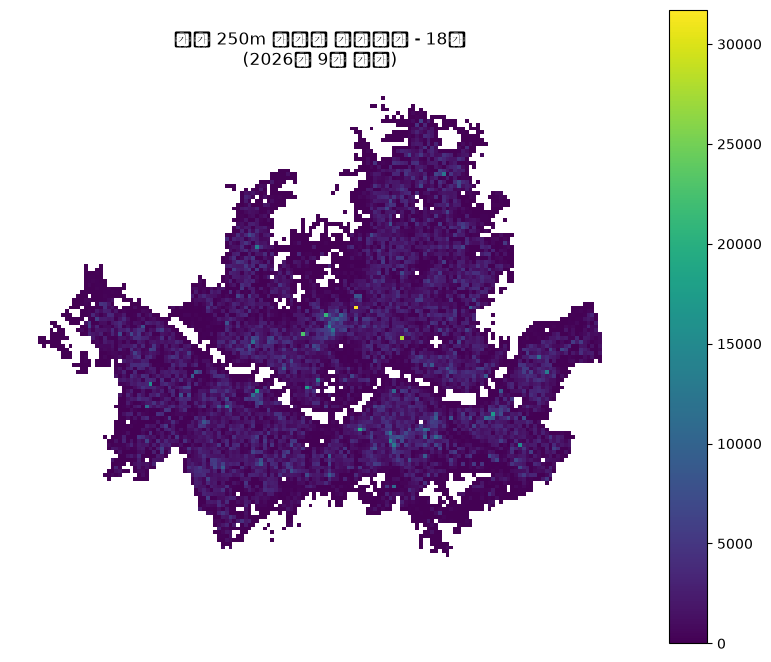

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

map_18.plot(
    column="총생활인구_공개값기준",
    ax=ax,
    legend=True
)

ax.set_title(
    "서울 250m 격자별 생활인구 - 18시\n(2026년 9월 평균)"
)

ax.axis("off")
plt.show()

In [21]:
import pandas as pd
from pathlib import Path

DATA = Path(r"C:\livinglab\데이터")

bus_usage_path = DATA / "2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv"
bus_stop_path = DATA / "서울시버스정류소위치정보(20260902) (1).xlsx"


# 버스 승하차
bus_usage = pd.read_csv(
    bus_usage_path,
    encoding="cp949",
    dtype={
        "표준버스정류장ID": "string",
        "버스정류장ARS번호": "string"
    }
)

# 버스정류장 위치
bus_stop = pd.read_excel(
    bus_stop_path,
    dtype={
        "NODE_ID": "string",
        "ARS_ID": "string"
    }
)

print("승하차 데이터:", bus_usage.shape)
print("정류장 위치:", bus_stop.shape)

display(bus_usage.head(3))
display(bus_stop.head(3))

C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\527987666.py:11: DtypeWarning: Columns (54: 교통수단타입코드) have mixed types. Specify dtype option on import or set low_memory=False.
  bus_usage = pd.read_csv(


승하차 데이터: (42155, 57)
정류장 위치: (11236, 6)


,사용년월,노선번호,노선명,표준버스정류장ID,버스정류장ARS번호,역명,00시승차총승객수,00시하차총승객수,1시승차총승객수,1시하차총승객수,...,20시하차총승객수,21시승차총승객수,21시하차총승객수,22시승차총승객수,22시하차총승객수,23시승차총승객수,23시하차총승객수,교통수단타입코드,교통수단타입명,등록일자
0,202609,470,470번(상암차고지~안골마을),100000001,01001,종로2가사거리(00063),196,170,0,0,...,436,363,256,346,313,322,232,10,서울간선버스,20261003
1,202609,N37,N37번(송파공영차고지~진관공영차고지),100000001,01001,종로2가사거리(00032),30,19,258,200,...,0,0,0,0,0,0,0,51,서울심야버스,20261003
2,202609,N37,N37번(진관공영차고지~송파공영차고지),100000001,01001,종로2가사거리(00089),0,0,0,0,...,0,0,0,0,0,0,0,51,서울심야버스,20261003


,NODE_ID,ARS_ID,정류소명,X좌표,Y좌표,정류소타입
0,123000689,00001,한강버스.잠실선착장,127.084778,37.518944,한강선착장
1,104000315,00002,한강버스.뚝섬선착장,127.066472,37.528695,한강선착장
2,103000517,00003,한강버스.옥수선착장,127.018056,37.538750,한강선착장


In [22]:
# 혹시 Excel 때문에 .0 같은 게 붙었으면 제거
bus_usage["표준버스정류장ID"] = (
    bus_usage["표준버스정류장ID"]
    .str.replace(r"\.0$", "", regex=True)
)

bus_stop["NODE_ID"] = (
    bus_stop["NODE_ID"]
    .str.replace(r"\.0$", "", regex=True)
)


usage_ids = set(bus_usage["표준버스정류장ID"].dropna())
stop_ids = set(bus_stop["NODE_ID"].dropna())

matched_ids = usage_ids & stop_ids

print("승하차 데이터 정류장 ID:", len(usage_ids))
print("위치 데이터 정류장 ID:", len(stop_ids))
print("공통 정류장 ID:", len(matched_ids))

print(
    "승하차 기준 매칭률:",
    round(len(matched_ids) / len(usage_ids) * 100, 2),
    "%"
)

승하차 데이터 정류장 ID: 12532
위치 데이터 정류장 ID: 11236
공통 정류장 ID: 10657
승하차 기준 매칭률: 85.04 %


In [24]:
ride_cols = [
    "00시승차총승객수" if h == 0
    else f"{h}시승차총승객수"
    for h in range(24)
]

alight_cols = [
    "00시하차총승객수" if h == 0
    else f"{h}시하차총승객수"
    for h in range(24)
]

print("승차 컬럼 존재:", all(c in bus_usage.columns for c in ride_cols))
print("하차 컬럼 존재:", all(c in bus_usage.columns for c in alight_cols))

print("\n승차 컬럼:")
print(ride_cols)

print("\n하차 컬럼:")
print(alight_cols)

승차 컬럼 존재: True
하차 컬럼 존재: True

승차 컬럼:
['00시승차총승객수', '1시승차총승객수', '2시승차총승객수', '3시승차총승객수', '4시승차총승객수', '5시승차총승객수', '6시승차총승객수', '7시승차총승객수', '8시승차총승객수', '9시승차총승객수', '10시승차총승객수', '11시승차총승객수', '12시승차총승객수', '13시승차총승객수', '14시승차총승객수', '15시승차총승객수', '16시승차총승객수', '17시승차총승객수', '18시승차총승객수', '19시승차총승객수', '20시승차총승객수', '21시승차총승객수', '22시승차총승객수', '23시승차총승객수']

하차 컬럼:
['00시하차총승객수', '1시하차총승객수', '2시하차총승객수', '3시하차총승객수', '4시하차총승객수', '5시하차총승객수', '6시하차총승객수', '7시하차총승객수', '8시하차총승객수', '9시하차총승객수', '10시하차총승객수', '11시하차총승객수', '12시하차총승객수', '13시하차총승객수', '14시하차총승객수', '15시하차총승객수', '16시하차총승객수', '17시하차총승객수', '18시하차총승객수', '19시하차총승객수', '20시하차총승객수', '21시하차총승객수', '22시하차총승객수', '23시하차총승객수']


In [25]:
# 4. 노선별 승하차량 → 정류장별 합산

# 혹시 숫자가 문자로 읽힌 컬럼이 있으면 숫자형으로 변환
for col in ride_cols + alight_cols:
    bus_usage[col] = pd.to_numeric(
        bus_usage[col],
        errors="coerce"
    ).fillna(0)

# 동일 정류장을 지나는 모든 노선의 승하차량 합산
bus_station_wide = (
    bus_usage
    .groupby(
        "표준버스정류장ID",
        as_index=False
    )[ride_cols + alight_cols]
    .sum()
)

print("원본 노선×정류장 행 수:", len(bus_usage))
print("정류장 단위 합산 후:", len(bus_station_wide))

display(bus_station_wide.head())

원본 노선×정류장 행 수: 42155
정류장 단위 합산 후: 12532


,표준버스정류장ID,00시승차총승객수,1시승차총승객수,2시승차총승객수,3시승차총승객수,4시승차총승객수,5시승차총승객수,6시승차총승객수,7시승차총승객수,8시승차총승객수,...,14시하차총승객수,15시하차총승객수,16시하차총승객수,17시하차총승객수,18시하차총승객수,19시하차총승객수,20시하차총승객수,21시하차총승객수,22시하차총승객수,23시하차총승객수
0,100000001,401,427,411,336,95,0,367,900,942,...,1070,1072,1140,1437,1549,1175,771,570,651,393
1,100000002,44,9,2,0,1165,1417,1956,4760,6127,...,3394,2295,2099,2123,1856,941,664,724,626,240
2,100000003,709,94,123,20,1260,2355,3031,5079,6404,...,5029,4151,4086,4362,4343,2912,2010,1929,1743,957
3,100000004,191,299,229,212,193,383,216,447,599,...,1687,1904,2155,2046,2168,1589,1337,994,587,255
4,100000005,201,23,24,6,1169,1307,2074,4105,4818,...,4935,4678,4889,5690,6004,3731,2220,2063,1899,815


In [26]:
# 정류장별 하루 전체 승하차량
bus_station_wide["월승차합계"] = (
    bus_station_wide[ride_cols].sum(axis=1)
)

bus_station_wide["월하차합계"] = (
    bus_station_wide[alight_cols].sum(axis=1)
)

bus_station_wide["월총승하차"] = (
    bus_station_wide["월승차합계"]
    + bus_station_wide["월하차합계"]
)

# 위치파일과 매칭 여부
bus_station_wide["위치매칭"] = (
    bus_station_wide["표준버스정류장ID"]
    .isin(stop_ids)
)

matched_usage = (
    bus_station_wide.loc[
        bus_station_wide["위치매칭"],
        "월총승하차"
    ].sum()
)

unmatched_usage = (
    bus_station_wide.loc[
        ~bus_station_wide["위치매칭"],
        "월총승하차"
    ].sum()
)

total_usage = matched_usage + unmatched_usage

print("정류장 수 기준 매칭률:",
      round(bus_station_wide["위치매칭"].mean() * 100, 2), "%")

print(
    "승하차량 기준 매칭률:",
    round(matched_usage / total_usage * 100, 2),
    "%"
)

print("\n매칭 안 된 정류장 수:",
      (~bus_station_wide["위치매칭"]).sum())

print("\n매칭 안 된 정류장 중 이용량 상위 20개:")

display(
    bus_station_wide.loc[
        ~bus_station_wide["위치매칭"],
        ["표준버스정류장ID", "월총승하차"]
    ]
    .sort_values("월총승하차", ascending=False)
    .head(20)
)

정류장 수 기준 매칭률: 85.04 %
승하차량 기준 매칭률: 95.29 %

매칭 안 된 정류장 수: 1875

매칭 안 된 정류장 중 이용량 상위 20개:


,표준버스정류장ID,월총승하차
11223,209000031,113804
11167,208000037,83905
12106,220000018,79281
10769,204000119,77142
11204,208000282,76263
10722,204000021,76037
5336,113000506,75900
11251,209000142,74395
12100,220000011,71081
11533,213000203,69192


In [27]:
unmatched_bus = bus_station_wide.loc[
    ~bus_station_wide["위치매칭"]
].copy()

unmatched_bus["ID앞3자리"] = (
    unmatched_bus["표준버스정류장ID"]
    .str[:3]
)

display(
    unmatched_bus
    .groupby("ID앞3자리")
    .agg(
        정류장수=("표준버스정류장ID", "count"),
        월총승하차=("월총승하차", "sum")
    )
    .sort_values("월총승하차", ascending=False)
    .head(20)
)

,정류장수,월총승하차
ID앞3자리,,
213,217,1836878
218,242,1410476
204,106,1312877
208,53,1282737
219,201,1076953
209,63,1022054
225,91,963496
220,34,756926
206,145,578653


In [28]:
matched_bus = bus_station_wide.loc[
    bus_station_wide["위치매칭"]
].copy()

matched_bus["ID앞3자리"] = (
    matched_bus["표준버스정류장ID"]
    .str[:3]
)

display(
    matched_bus
    .groupby("ID앞3자리")
    .agg(
        정류장수=("표준버스정류장ID", "count"),
        월총승하차=("월총승하차", "sum")
    )
    .sort_values("월총승하차", ascending=False)
    .head(20)
)

,정류장수,월총승하차
ID앞3자리,,
122,505,17900372
120,457,15807332
121,596,15536060
107,601,14485611
118,459,13452785
100,358,13226495
105,314,12713649
113,550,12691288
112,441,12605213


In [29]:
# ARS 번호 정리
# 서울 ARS 번호는 보통 5자리이므로 앞자리 0 보존

bus_usage["버스정류장ARS번호"] = (
    bus_usage["버스정류장ARS번호"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
    .str.zfill(5)
)

bus_stop["ARS_ID"] = (
    bus_stop["ARS_ID"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
    .str.zfill(5)
)

print(bus_usage[
    ["표준버스정류장ID", "버스정류장ARS번호", "역명"]
].head())

print(bus_stop[
    ["NODE_ID", "ARS_ID", "정류소명"]
].head())

   표준버스정류장ID 버스정류장ARS번호                  역명
0  100000001      01001      종로2가사거리(00063)
1  100000001      01001      종로2가사거리(00032)
2  100000001      01001      종로2가사거리(00089)
3  100000001      01001      종로2가사거리(00073)
4  100000002      01002  창경궁.서울대학교병원(00089)
     NODE_ID ARS_ID         정류소명
0  123000689  00001   한강버스.잠실선착장
1  104000315  00002   한강버스.뚝섬선착장
2  103000517  00003   한강버스.옥수선착장
3  122000752  00004  한강버스.압구정선착장
4  118000622  00005  한강버스.여의도선착장


In [30]:
# 같은 표준정류장ID에 대응하는 ARS 번호/역명 정리
bus_id_info = (
    bus_usage[
        [
            "표준버스정류장ID",
            "버스정류장ARS번호",
            "역명"
        ]
    ]
    .drop_duplicates()
)

# 한 표준정류장ID에 여러 노선이 있어도
# 같은 정류장 정보가 반복되는 것이므로 첫 값 사용
bus_id_info = (
    bus_id_info
    .groupby("표준버스정류장ID", as_index=False)
    .first()
)

bus_station_check = bus_station_wide.merge(
    bus_id_info,
    on="표준버스정류장ID",
    how="left"
)

display(
    bus_station_check.loc[
        ~bus_station_check["위치매칭"],
        [
            "표준버스정류장ID",
            "버스정류장ARS번호",
            "역명",
            "월총승하차"
        ]
    ]
    .sort_values("월총승하차", ascending=False)
    .head(30)
)

,표준버스정류장ID,버스정류장ARS번호,역명,월총승하차
11223,209000031,56044,인덕원사거리.인덕원역(00102),113804
11167,208000037,18777,석수역(00019),83905
12106,220000018,37500,선바위역1번출구(00001),79281
10769,204000119,48028,성남시의료원.신흥1동행정복지센터.성남아트리움(00014),77142
11204,208000282,57022,안양중앙시장(00087),76263
10722,204000021,48019,가천대역.가천대학교(00020),76037
5336,113000506,14097,홍대입구역(가상)(00017),75900
11251,209000142,56039,인덕원역3번출구(00024),74395
12100,220000011,37502,선바위역2번출구(00086),71081
11533,213000203,38016,광명사거리역8번출구(00014),69192


In [31]:
ars_ids = set(
    bus_stop["ARS_ID"]
    .dropna()
)

bus_station_check["ARS매칭"] = (
    bus_station_check["버스정류장ARS번호"]
    .isin(ars_ids)
)

# NODE 또는 ARS 둘 중 하나라도 매칭되면 위치 확보 가능
bus_station_check["최종매칭"] = (
    bus_station_check["위치매칭"]
    | bus_station_check["ARS매칭"]
)

print(
    "NODE 기준:",
    round(bus_station_check["위치매칭"].mean() * 100, 2),
    "%"
)

print(
    "NODE + ARS 기준:",
    round(bus_station_check["최종매칭"].mean() * 100, 2),
    "%"
)

matched_usage_final = bus_station_check.loc[
    bus_station_check["최종매칭"],
    "월총승하차"
].sum()

total_usage = bus_station_check["월총승하차"].sum()

print(
    "최종 승하차량 기준 커버리지:",
    round(matched_usage_final / total_usage * 100, 2),
    "%"
)

NODE 기준: 85.04 %
NODE + ARS 기준: 85.64 %
최종 승하차량 기준 커버리지: 95.46 %


In [32]:
# 정류장 × 시간 형태로 변환
records = []

for h in range(24):

    ride_col = (
        "00시승차총승객수"
        if h == 0
        else f"{h}시승차총승객수"
    )

    alight_col = (
        "00시하차총승객수"
        if h == 0
        else f"{h}시하차총승객수"
    )

    tmp = bus_station_wide[
        ["표준버스정류장ID"]
    ].copy()

    tmp["시간"] = h

    # 9월 월합계 → 하루 평균
    tmp["평균승차"] = (
        bus_station_wide[ride_col] / 30
    )

    tmp["평균하차"] = (
        bus_station_wide[alight_col] / 30
    )

    tmp["평균총승하차"] = (
        tmp["평균승차"]
        + tmp["평균하차"]
    )

    records.append(tmp)

bus_hourly = pd.concat(
    records,
    ignore_index=True
)

print("시간대별 전체 데이터:", bus_hourly.shape)
print("시간:", sorted(bus_hourly["시간"].unique()))

시간대별 전체 데이터: (300768, 5)
시간: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [33]:
bus_stop_simple = (
    bus_stop[
        [
            "NODE_ID",
            "ARS_ID",
            "정류소명",
            "X좌표",
            "Y좌표",
            "정류소타입"
        ]
    ]
    .drop_duplicates(subset="NODE_ID")
)

bus_hourly_seoul = bus_hourly.merge(
    bus_stop_simple,
    left_on="표준버스정류장ID",
    right_on="NODE_ID",
    how="inner"
)

print("서울 위치 결합 후:", bus_hourly_seoul.shape)
print(
    "서울 정류장 수:",
    bus_hourly_seoul["NODE_ID"].nunique()
)
print(
    "시간:",
    sorted(bus_hourly_seoul["시간"].unique())
)

display(bus_hourly_seoul.head())

서울 위치 결합 후: (255768, 11)
서울 정류장 수: 10657
시간: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


,표준버스정류장ID,시간,평균승차,평균하차,평균총승하차,NODE_ID,ARS_ID,정류소명,X좌표,Y좌표,정류소타입
0,100000001,0,13.366667,10.266667,23.633333,100000001,01001,종로2가사거리,126.987752,37.569806,중앙차로
1,100000002,0,1.466667,2.566667,4.033333,100000002,01002,창경궁.서울대학교병원,126.996521,37.579433,중앙차로
2,100000003,0,23.633333,6.100000,29.733333,100000003,01003,명륜3가.성대입구,126.998251,37.582580,중앙차로
3,100000004,0,6.366667,1.466667,7.833333,100000004,01004,종로2가.삼일교,126.987613,37.568579,중앙차로
4,100000005,0,6.700000,7.933333,14.633333,100000005,01005,혜화동로터리.여운형활동터,127.001744,37.586243,중앙차로


In [34]:
print(
    "경도 범위:",
    bus_hourly_seoul["X좌표"].min(),
    "~",
    bus_hourly_seoul["X좌표"].max()
)

print(
    "위도 범위:",
    bus_hourly_seoul["Y좌표"].min(),
    "~",
    bus_hourly_seoul["Y좌표"].max()
)

경도 범위: 126.797811 ~ 127.1817343335
위도 범위: 37.4305199435 ~ 37.690177


In [35]:
TABLES = BASE / "output" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

bus_hourly_seoul.to_csv(
    TABLES / "버스정류장_202609_시간대별일평균승하차.csv",
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료")

저장 완료


grid shape: (10125, 25)
bus shape: (10657, 12)
grid CRS: EPSG:5179
bus CRS: EPSG:5179
plot용 격자 수: 10125
plot용 정류장 수: 10642
                 정류소명      평균총승하차   plot_size
191826        종로2가사거리   72.266667   48.803926
191827    창경궁.서울대학교병원  269.500000   85.728248
191828      명륜3가.성대입구  469.666667  110.243496
191829       종로2가.삼일교  162.333333   68.582931
191830  혜화동로터리.여운형활동터  318.100000   92.347185


C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 44201 (\N{HANGUL SYLLABLE GYEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 48260 (\N{HANGUL SYLLABLE BEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\905658588.py:83: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaV

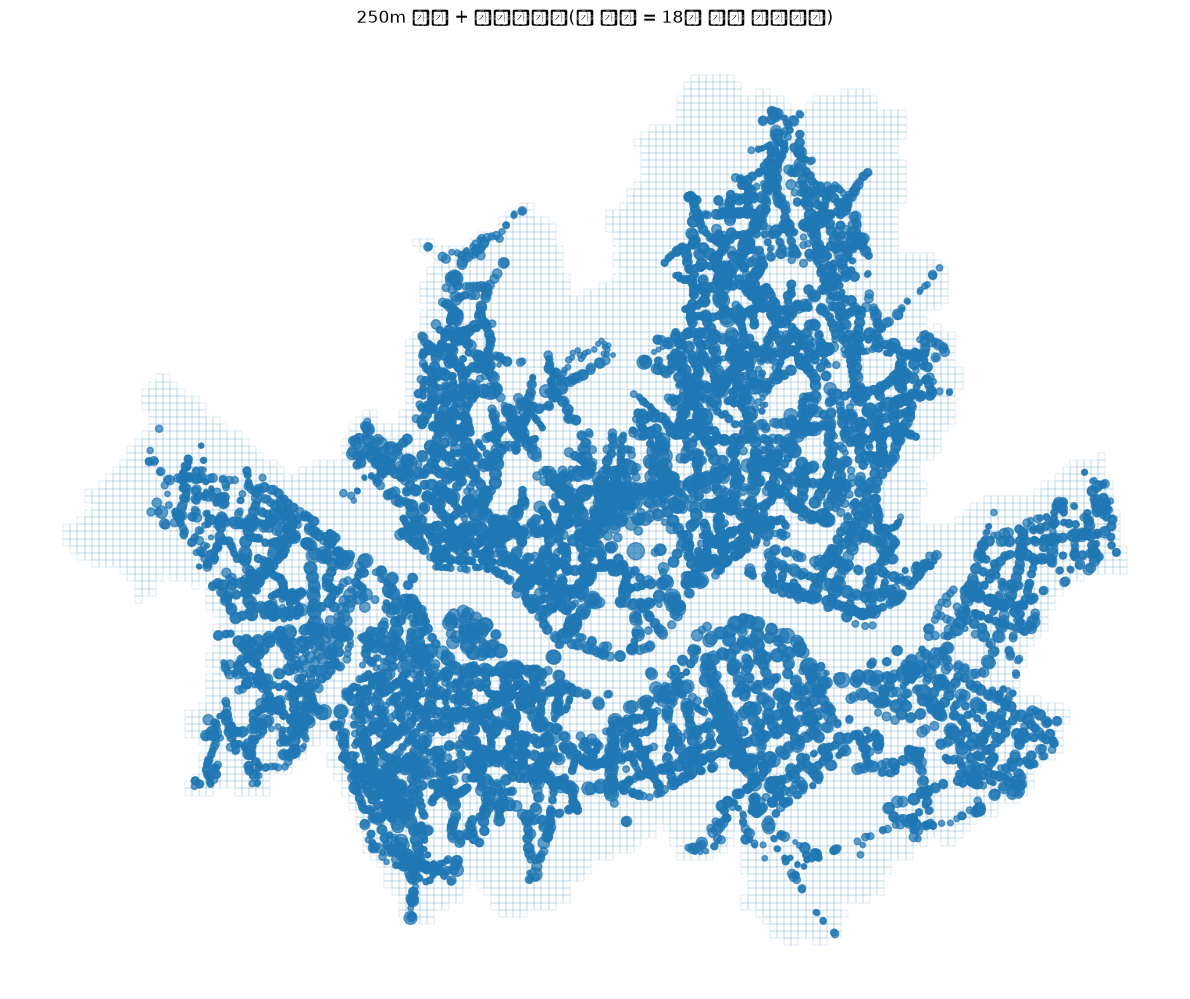

In [239]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 0. 사용할 데이터 지정
# =========================
grid = map_18_full.copy()      # <- 필요하면 이 이름만 바꿔
bus = bus_18_gdf.copy()

# =========================
# 1. 기본 확인
# =========================
print("grid shape:", grid.shape)
print("bus shape:", bus.shape)
print("grid CRS:", grid.crs)
print("bus CRS:", bus.crs)

# geometry 없는 경우 방지
if 'geometry' not in grid.columns:
    raise ValueError("grid 데이터에 geometry 컬럼이 없음")
if 'geometry' not in bus.columns:
    raise ValueError("bus_18_gdf에 geometry 컬럼이 없음")

# GeoDataFrame 보장
if not isinstance(grid, gpd.GeoDataFrame):
    grid = gpd.GeoDataFrame(grid, geometry='geometry', crs=bus.crs)

if not isinstance(bus, gpd.GeoDataFrame):
    bus = gpd.GeoDataFrame(bus, geometry='geometry', crs=grid.crs)

# CRS 맞추기
if grid.crs != bus.crs:
    bus = bus.to_crs(grid.crs)

# =========================
# 2. 필요한 컬럼 정리
# =========================
# 격자는 중복 제거 (같은 geometry 반복되어 있으면 정리)
grid = grid.drop_duplicates(subset=['geometry']).copy()

# 버스 승하차량 숫자형 변환
bus['평균총승하차'] = pd.to_numeric(bus['평균총승하차'], errors='coerce')
bus = bus.dropna(subset=['평균총승하차', 'geometry']).copy()

# 0 이하 제거는 선택
bus = bus[bus['평균총승하차'] > 0].copy()

print("plot용 격자 수:", len(grid))
print("plot용 정류장 수:", len(bus))

# =========================
# 3. 점 크기 스케일링
# =========================
# 값 차이가 클 수 있으니 sqrt 스케일 추천
v = np.sqrt(bus['평균총승하차'])

# 점 크기 범위 조절
# 너무 크거나 작으면 아래 숫자만 바꾸면 됨
bus['plot_size'] = 10 + (v - v.min()) / (v.max() - v.min()) * 190

print(bus[['정류소명', '평균총승하차', 'plot_size']].head())

# =========================
# 4. 그림 그리기
# =========================
fig, ax = plt.subplots(figsize=(12, 12))

# 250m 격자 경계
grid.boundary.plot(ax=ax, linewidth=0.2, alpha=0.5)

# 버스 정류장 점
bus.plot(
    ax=ax,
    markersize=bus['plot_size'],
    alpha=0.7,
)

ax.set_title("250m 격자 + 버스정류장(점 크기 = 18시 평균 총승하차)")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [38]:
from pathlib import Path

candidates = list(
    DATA.glob("*도보*네트워크*.csv")
)

print("후보 파일:")
for p in candidates:
    print(p.name)

후보 파일:
서울시 자치구별 도보 네트워크 공간정보 (1).csv


In [39]:
subway_network_path = candidates[0]

subway_raw = pd.read_csv(
    subway_network_path,
    encoding="cp949",
    dtype="string"
)

print("크기:", subway_raw.shape)
print("컬럼:")
print(subway_raw.columns.tolist())

display(subway_raw.head())

크기: (491082, 23)
컬럼:
['노드링크 유형', '노드 WKT', '노드 ID', '노드 유형 코드', '링크 WKT', '링크 ID', '링크 유형 코드', '시작노드 ID', '종료노드 ID', '링크 길이', '시군구코드', '시군구명', '읍면동코드', '읍면동명', '고가도로', '지하철네트워크', '교량', '터널', '육교', '횡단보도', '공원,녹지', '건물내', '수집일자']


,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,...,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,NODE,POINT(126.98573455356602 37.58027421275332),134096,0,<NA>,0,<NA>,<NA>,<NA>,<NA>,...,가회동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,39:57.0
1,NODE,POINT(126.98640583910638 37.580057782302426),134095,0,<NA>,0,<NA>,<NA>,<NA>,<NA>,...,계동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,39:57.0
2,LINK,<NA>,0,<NA>,LINESTRING(126.99666411680936 37.5843153141858...,87832,1111,136212,136213,7.318,...,명륜3가,0,0,0,0,0,0,0,0,36:49.0
3,NODE,POINT(126.97979324709492 37.571797939110795),133026,0,<NA>,0,<NA>,<NA>,<NA>,<NA>,...,청진동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,39:57.0
4,LINK,<NA>,0,<NA>,LINESTRING(126.97011156400389 37.5743941170710...,90804,1111,129943,129944,18.529,...,내수동,0,0,0,0,0,0,0,0,36:58.0


In [40]:
print(
    subway_raw.loc[
        subway_raw["노드링크 유형"] == "NODE",
        "노드 유형 코드"
    ].value_counts(dropna=False)
)

노드 유형 코드
0    201450
2     10362
3       197
1        57
Name: count, dtype: Int64


In [41]:
subway_exit = subway_raw[
    (subway_raw["노드링크 유형"] == "NODE")
    & (subway_raw["노드 유형 코드"] == "1")
].copy()

print("지하철 출입구 NODE 수:", len(subway_exit))

display(
    subway_exit[
        [
            "노드 ID",
            "노드 WKT",
            "시군구명",
            "읍면동명"
        ]
    ].head(10)
)

지하철 출입구 NODE 수: 57


,노드 ID,노드 WKT,시군구명,읍면동명
55,131970,POINT(126.97330778434035 37.57569475860788),종로구,적선동
4894,127745,POINT(126.95769340366402 37.57486504586365),종로구,무악동
9754,211272,POINT(126.98601718684534 37.57032117171325),종로구,종로2가
14181,135561,POINT(126.99189784557106 37.57254045459208),종로구,묘동
15504,134876,POINT(126.98613268576081 37.57008300043591),종로구,종로2가
15819,135681,POINT(126.99204296962934 37.570242399203444),종로구,종로3가
15829,135682,POINT(126.99226471603856 37.57025418079042),종로구,종로3가
31348,5600,POINT(126.96516857755668 37.56003628256738),중구,중림동
173847,20033,POINT(127.04644005693427 37.68837099949135),도봉구,도봉동
178031,138556,POINT(127.04646440385129 37.69053585841926),도봉구,도봉동


In [42]:
from shapely import wkt
import geopandas as gpd

# WKT가 정상인 행만
subway_exit = subway_exit[
    subway_exit["노드 WKT"].notna()
].copy()

subway_exit["geometry"] = subway_exit["노드 WKT"].apply(wkt.loads)

subway_exit_gdf = gpd.GeoDataFrame(
    subway_exit,
    geometry="geometry",
    crs="EPSG:4326"
)

subway_exit_gdf["경도"] = subway_exit_gdf.geometry.x
subway_exit_gdf["위도"] = subway_exit_gdf.geometry.y

print("최종 출입구 수:", len(subway_exit_gdf))
print(
    "경도 범위:",
    subway_exit_gdf["경도"].min(),
    "~",
    subway_exit_gdf["경도"].max()
)
print(
    "위도 범위:",
    subway_exit_gdf["위도"].min(),
    "~",
    subway_exit_gdf["위도"].max()
)

display(
    subway_exit_gdf[
        [
            "노드 ID",
            "시군구명",
            "읍면동명",
            "경도",
            "위도"
        ]
    ].head(10)
)

최종 출입구 수: 57
경도 범위: 126.8013720082262 ~ 127.09705561276145
위도 범위: 37.463716674449095 ~ 37.69053585841926


,노드 ID,시군구명,읍면동명,경도,위도
55,131970,종로구,적선동,126.973308,37.575695
4894,127745,종로구,무악동,126.957693,37.574865
9754,211272,종로구,종로2가,126.986017,37.570321
14181,135561,종로구,묘동,126.991898,37.572540
15504,134876,종로구,종로2가,126.986133,37.570083
15819,135681,종로구,종로3가,126.992043,37.570242
15829,135682,종로구,종로3가,126.992265,37.570254
31348,5600,중구,중림동,126.965169,37.560036
173847,20033,도봉구,도봉동,127.046440,37.688371
178031,138556,도봉구,도봉동,127.046464,37.690536


In [43]:
import osmnx as ox
import geopandas as gpd

# 서울시 경계 안의 지하철 출입구
osm_subway = ox.features_from_place(
    "Seoul, South Korea",
    tags={"railway": "subway_entrance"}
)

print("OSM 원본 출입구 수:", len(osm_subway))
print("Geometry type:")
print(osm_subway.geom_type.value_counts())

display(
    osm_subway[
        [
            c for c in ["name", "ref", "railway", "geometry"]
            if c in osm_subway.columns
        ]
    ].head(20)
)

OSM 원본 출입구 수: 1823
Geometry type:
Point    1823
Name: count, dtype: int64


name ref          railway                    geometry
element id                                                              
node    357864451   NaN   2  subway_entrance   POINT (127.0585 37.63435)
        357880576   NaN   7  subway_entrance  POINT (127.09973 37.51426)
        490631737   NaN   6  subway_entrance  POINT (127.04324 37.57939)
        1553878333  NaN   6  subway_entrance  POINT (126.98238 37.56991)
        1555198917  NaN   5  subway_entrance   POINT (126.98259 37.5698)
        1561114419  NaN   4  subway_entrance  POINT (127.00781 37.56438)
        1831648734  NaN   1  subway_entrance  POINT (126.95048 37.58249)
        1831648735  NaN   2  subway_entrance  POINT (126.95065 37.58217)
        1831648736  NaN   3  subway_entrance  POINT (126.95036 37.58209)
        1831648737  NaN   4  subway_entrance   POINT (126.95021 37.5824)
        1918317450  NaN   2  subway_entrance  POINT (127.03348 37.48495)
        1925380572  NaN   1  subway_entrance  POINT (127.05488 37.49092)
        1925380575  NaN   2  subway_entrance  POINT (127.05575 37.49129)
        1925380581  NaN   4  subway_entrance  POINT (127.05512 37.49055)
        1925380667  NaN  11  subway_entrance  POINT (127.03397 37.48416)
        1925380669  NaN  12  subway_entrance  POINT (127.03356 37.48427)
        1925380670  NaN   1  subway_entrance  POINT (127.03332 37.48472)
        1925380671  NaN   3  subway_entrance  POINT (127.03418 37.48498)
        1925380672  NaN   4  subway_entrance  POINT (127.03451 37.48482)
        1925380687  NaN   5  subway_entrance  POINT (127.03495 37.48445)

In [44]:
subway_exit_osm = (
    osm_subway[
        osm_subway.geometry.geom_type == "Point"
    ]
    .copy()
)

subway_exit_osm = subway_exit_osm.to_crs("EPSG:4326")

subway_exit_osm["경도"] = subway_exit_osm.geometry.x
subway_exit_osm["위도"] = subway_exit_osm.geometry.y

print("최종 OSM 지하철 출입구 수:", len(subway_exit_osm))

print(
    "경도 범위:",
    subway_exit_osm["경도"].min(),
    "~",
    subway_exit_osm["경도"].max()
)

print(
    "위도 범위:",
    subway_exit_osm["위도"].min(),
    "~",
    subway_exit_osm["위도"].max()
)

display(
    subway_exit_osm[
        [
            c for c in
            ["name", "ref", "경도", "위도", "geometry"]
            if c in subway_exit_osm.columns
        ]
    ].head(20)
)

최종 OSM 지하철 출입구 수: 1823
경도 범위: 126.7976778 ~ 127.1767135
위도 범위: 37.4476886 ~ 37.6904222


name ref          경도         위도                    geometry
element id                                                                    
node    357864451   NaN   2  127.058500  37.634355   POINT (127.0585 37.63435)
        357880576   NaN   7  127.099733  37.514259  POINT (127.09973 37.51426)
        490631737   NaN   6  127.043236  37.579385  POINT (127.04324 37.57939)
        1553878333  NaN   6  126.982378  37.569915  POINT (126.98238 37.56991)
        1555198917  NaN   5  126.982591  37.569798   POINT (126.98259 37.5698)
        1561114419  NaN   4  127.007810  37.564375  POINT (127.00781 37.56438)
        1831648734  NaN   1  126.950479  37.582492  POINT (126.95048 37.58249)
        1831648735  NaN   2  126.950648  37.582167  POINT (126.95065 37.58217)
        1831648736  NaN   3  126.950358  37.582090  POINT (126.95036 37.58209)
        1831648737  NaN   4  126.950208  37.582401   POINT (126.95021 37.5824)
        1918317450  NaN   2  127.033479  37.484950  POINT (127.03348 37.48495)
        1925380572  NaN   1  127.054878  37.490915  POINT (127.05488 37.49092)
        1925380575  NaN   2  127.055752  37.491287  POINT (127.05575 37.49129)
        1925380581  NaN   4  127.055120  37.490551  POINT (127.05512 37.49055)
        1925380667  NaN  11  127.033974  37.484163  POINT (127.03397 37.48416)
        1925380669  NaN  12  127.033560  37.484270  POINT (127.03356 37.48427)
        1925380670  NaN   1  127.033322  37.484716  POINT (127.03332 37.48472)
        1925380671  NaN   3  127.034177  37.484979  POINT (127.03418 37.48498)
        1925380672  NaN   4  127.034508  37.484817  POINT (127.03451 37.48482)
        1925380687  NaN   5  127.034949  37.484448  POINT (127.03495 37.48445)

In [45]:
TABLES = BASE / "output" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

subway_save = subway_exit_osm.reset_index()

subway_save[
    [
        c for c in
        ["element", "id", "name", "ref", "경도", "위도"]
        if c in subway_save.columns
    ]
].to_csv(
    TABLES / "OSM_서울_지하철출입구.csv",
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료")

저장 완료


In [46]:
market_path = DATA / "서울시 전통시장 현황(2026년 하반기).xlsx"
store_path = DATA / "서울시 대규모점포 인허가 정보.csv"

# 전통시장
market_raw = pd.read_excel(
    market_path,
    header=None
)

# 대규모점포
store_raw = pd.read_csv(
    store_path,
    encoding="cp949"
)

print("=== 전통시장 ===")
print("크기:", market_raw.shape)
display(market_raw.head(10))

print("\n=== 대규모점포 ===")
print("크기:", store_raw.shape)
print("컬럼:")
print(store_raw.columns.tolist())

display(
    store_raw[
        [
            c for c in
            ["사업장명", "영업상태명", "도로명주소",
             "지번주소", "업태구분명",
             "좌표정보(X)", "좌표정보(Y)", "점포구분명"]
            if c in store_raw.columns
        ]
    ].head(10)
)

=== 전통시장 ===
크기: (602, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,연번,자치구,시장명,신주소(도로명 주소),구주소(번지주소),유형,형태,건물연면적,점포수,NaN,NaN
1,총계,서울시,575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,소계,강남구,15,NaN,NaN,NaN,NaN,NaN,2075,NaN,NaN
3,1,강남구,강남개포시장,서울 강남구 개포로82길 11,서울 강남구 개포동 186-3,상점가,상점가,56608,115,NaN,NaN
4,2,강남구,강남시장,서울 강남구 압구정로2길 46,서울 강남구 신사동 510-11,등록시장,건물형,3690,69,NaN,NaN
5,3,강남구,강남언주로 상가,서울 강남구 언주로98길 5-4,서울 강남구 역삼동 699-1,상점가,상점가,2008,34,NaN,NaN
6,4,강남구,강남역지하도상점,서울 강남구 강남대로 지하 396,서울 강남구 역삼동 804,상점가,지하도상가,12099,212,NaN,NaN
7,5,강남구,개포동 구마을 골목형상점가,서울 강남구 선릉로8길 11,서울 강남구 개포동 165-4,골목형상점가,골목형,8498,117,NaN,NaN
8,6,강남구,논현종합시장,서울 강남구 봉은사로33길 33,서울 강남구 논현동 227-4,등록시장,건물형,1215,40,NaN,NaN
9,7,강남구,도곡시장,서울 강남구 선릉로69길 19,서울특별시 강남구 역삼동 757,상점가,상점가,33361,85,NaN,NaN



=== 대규모점포 ===
크기: (1054, 26)
컬럼:
['개방자치단체코드', '관리번호', '인허가일자', '인허가취소일자', '영업상태코드', '영업상태명', '상세영업상태코드', '상세영업상태명', '폐업일자', '휴업시작일자', '휴업종료일자', '재개업일자', '전화번호', '소재지면적', '소재지우편번호', '지번주소', '도로명주소', '도로명우편번호', '사업장명', '최종수정일자', '데이터갱신구분', '데이터갱신일자', '업태구분명', '좌표정보(X)', '좌표정보(Y)', '점포구분명']


,사업장명,영업상태명,도로명주소,지번주소,업태구분명,좌표정보(X),좌표정보(Y),점포구분명
0,GS THE FRESH 강동역점,영업/정상,"서울특별시 강동구 천호대로176길 32, 그린빌딩 1층 (성내동)",서울특별시 강동구 성내동 381-24 그린빌딩,대형마트,211921.382260601,447878.64919626,준대규모점포
1,GS THE FRESH 강서발산역점,영업/정상,"서울특별시 강서구 공항대로 284, 1층 (내발산동)",서울특별시 강서구 내발산동 646,구분없음,185714.792623613,450665.263858368,준대규모점포
2,GS THE FRESH 송파석촌역점,영업/정상,"서울특별시 송파구 송파대로45길 16, 1층 101호 (석촌동)",서울특별시 송파구 석촌동 166-12 101호,구분없음,209134.86711622,444864.58985226,준대규모점포
3,이마트에브리데이 잠실리센츠점,영업/정상,"서울특별시 송파구 올림픽로 145, 리센츠상가 지하1층 제이1호~제이19호 (잠실동)",서울특별시 송파구 잠실동 22-6 리센츠상가 지하1층 제이1호~제이19호,구분없음,207624.424720682,445533.439634339,준대규모점포
4,GS THE FRESH 석촌고분역점,영업/정상,"서울특별시 송파구 백제고분로31길 16-4, 1층 101호 (삼전동, 삼전레이크)",서울특별시 송파구 삼전동 122 삼전레이크,구분없음,208394.981001621,444642.023012078,준대규모점포
5,주식회사 홈플러스 익스프레스 금호2점,영업/정상,"서울특별시 성동구 동호로 100 (금호동3가, 두산아파트)",서울특별시 성동구 금호동3가 1331 두산아파트 상가동,백화점,201383.023709556,449744.280482389,준대규모점포
6,이마트에브리데이 양재역점,영업/정상,서울특별시 서초구 남부순환로356길 49 (양재동),서울특별시 서초구 양재동 9 코사마트,구분없음,203342.695983882,442297.080663687,준대규모점포
7,GS THE FRESH 신촌이대역점,영업/정상,"서울특별시 서대문구 이화여대길 50-12, 상가동 1층 101호 (대현동, 신촌럭키...",서울특별시 서대문구 대현동 144 신촌럭키아파트 상가동 101호,그 밖의 대규모점포,195332.123380254,450806.05844472,준대규모점포
8,GS THE FRESH 신촌이대역점,영업/정상,"서울특별시 서대문구 이화여대길 50-12, 상가동 1층 101호 (대현동, 신촌럭키...",서울특별시 서대문구 대현동 144 신촌럭키아파트 상가동 101호,그 밖의 대규모점포,195332.123380254,450806.05844472,준대규모점포
9,DMC금호리첸시아몰,영업/정상,"서울특별시 서대문구 수색로2길 39, B1,1,2층 (남가좌동, DMC금호리첸시아)",서울특별시 서대문구 남가좌동 396 DMC금호리첸시아,그 밖의 대규모점포,192482.416512858,452143.491541077,대규모점포


In [48]:
# 전통시장 첫 행을 컬럼명으로 사용
market = pd.read_excel(
    market_path,
    header=0
)

# 컬럼명 앞뒤 공백 제거
market.columns = (
    market.columns
    .astype(str)
    .str.strip()
)

print("원본:", market.shape)
print(market.columns.tolist())

# 연번이 숫자인 실제 시장 행만 남김
market["연번"] = pd.to_numeric(
    market["연번"],
    errors="coerce"
)

market = market[
    market["연번"].notna()
].copy()

market["연번"] = market["연번"].astype(int)

# 필요한 컬럼만
market = market[
    [
        "연번",
        "자치구",
        "시장명",
        "신주소(도로명 주소)",
        "구주소(번지주소)",
        "유형",
        "형태",
        "건물연면적",
        "점포수"
    ]
].copy()

print("실제 시장 수:", len(market))
print("자치구 수:", market["자치구"].nunique())

display(market.head(10))

원본: (601, 11)
['연번', '자치구', '시장명', '신주소(도로명 주소)', '구주소(번지주소)', '유형', '형태', '건물연면적', '점포수', 'Unnamed: 9', 'Unnamed: 10']
실제 시장 수: 575
자치구 수: 25


,연번,자치구,시장명,신주소(도로명 주소),구주소(번지주소),유형,형태,건물연면적,점포수
2,1,강남구,강남개포시장,서울 강남구 개포로82길 11,서울 강남구 개포동 186-3,상점가,상점가,56608.00,115.0
3,2,강남구,강남시장,서울 강남구 압구정로2길 46,서울 강남구 신사동 510-11,등록시장,건물형,3690.00,69.0
4,3,강남구,강남언주로 상가,서울 강남구 언주로98길 5-4,서울 강남구 역삼동 699-1,상점가,상점가,2008.00,34.0
5,4,강남구,강남역지하도상점,서울 강남구 강남대로 지하 396,서울 강남구 역삼동 804,상점가,지하도상가,12099.00,212.0
6,5,강남구,개포동 구마을 골목형상점가,서울 강남구 선릉로8길 11,서울 강남구 개포동 165-4,골목형상점가,골목형,8498.00,117.0
7,6,강남구,논현종합시장,서울 강남구 봉은사로33길 33,서울 강남구 논현동 227-4,등록시장,건물형,1215.00,40.0
8,7,강남구,도곡시장,서울 강남구 선릉로69길 19,서울특별시 강남구 역삼동 757,상점가,상점가,33361.00,85.0
9,8,강남구,세곡동 은곡마을 골목형상점가,서울 강남구 헌릉로569길 21-30,서울 강남구 세곡동 616,골목형상점가,골목형,82442.40,99.0
10,9,강남구,신사 세로수길 골목형상점가,서울 강남구 압구정로2길 60,서울 강남구 신사동 512-9,골목형상점가,골목형,49117.30,220.0
11,10,강남구,신사시장,서울 강남구 압구정로29길 72-1,서울 강남구 압구정동 454,등록시장,상점가,2931.59,74.0


In [49]:
print(
    "도로명주소 있음:",
    market["신주소(도로명 주소)"].notna().sum()
)

print(
    "지번주소 있음:",
    market["구주소(번지주소)"].notna().sum()
)

print(
    "주소 둘 다 없음:",
    (
        market["신주소(도로명 주소)"].isna()
        & market["구주소(번지주소)"].isna()
    ).sum()
)

도로명주소 있음: 575
지번주소 있음: 575
주소 둘 다 없음: 0


In [50]:
store = store_raw.copy()

# 숫자형 변환
store["좌표정보(X)"] = pd.to_numeric(
    store["좌표정보(X)"],
    errors="coerce"
)

store["좌표정보(Y)"] = pd.to_numeric(
    store["좌표정보(Y)"],
    errors="coerce"
)

print("원본:", store.shape)

print("\n영업상태:")
print(store["영업상태명"].value_counts(dropna=False).head(10))

print("\n업태:")
print(store["업태구분명"].value_counts(dropna=False))

print("\n점포구분:")
print(store["점포구분명"].value_counts(dropna=False))

원본: (1054, 26)

영업상태:
영업상태명
영업/정상             740
폐업                221
휴업                 81
취소/말소/만료/정지/중지     12
Name: count, dtype: int64

업태:
업태구분명
그 밖의 대규모점포    417
구분없음          264
대형마트          115
쇼핑센터           63
시장             63
복합쇼핑몰          58
백화점            37
전문점            34
NaN             3
Name: count, dtype: int64

점포구분:
점포구분명
대규모점포     523
준대규모점포    348
NaN       183
Name: count, dtype: int64


In [51]:
store_active = store[
    (store["영업상태명"] == "영업/정상")
    & store["좌표정보(X)"].notna()
    & store["좌표정보(Y)"].notna()
].copy()

# 같은 관리번호가 중복되어 있으면 1개만
store_active = (
    store_active
    .sort_values("최종수정일자")
    .drop_duplicates(
        subset="관리번호",
        keep="last"
    )
)

print("정상영업 + 좌표 존재:", len(store_active))

display(
    store_active[
        [
            "관리번호",
            "사업장명",
            "업태구분명",
            "점포구분명",
            "도로명주소",
            "좌표정보(X)",
            "좌표정보(Y)"
        ]
    ].head(10)
)

정상영업 + 좌표 존재: 685


,관리번호,사업장명,업태구분명,점포구분명,도로명주소,좌표정보(X),좌표정보(Y)
493,2002324007307500001,신세계 이마트 명일점,대형마트,NaN,NaN,213700.877715,450278.100931
803,1970320008007500004,봉일시장,그 밖의 대규모점포,NaN,NaN,194486.270489,442632.469541
365,1971320008007500002,봉일시장,그 밖의 대규모점포,NaN,NaN,194486.270489,442632.469541
378,1989316007107500020,사모아종합상가,그 밖의 대규모점포,NaN,서울특별시 구로구 구일로10길 93 (구로동),189052.101789,443748.279290
622,2000307009907500009,새석관시장,그 밖의 대규모점포,NaN,NaN,204582.680270,456210.836258
1018,2000307009907500011,번동시장,그 밖의 대규모점포,NaN,NaN,204162.777673,457664.961911
612,1987317006707500017,시흥산업용재유통센타,그 밖의 대규모점포,NaN,서울특별시 금천구 시흥대로 109 (시흥동),191384.606290,437986.940835
867,1993317006707500023,유창상가,그 밖의 대규모점포,NaN,서울특별시 금천구 범안로 1209 (독산동),190771.595590,440515.669035
526,1973317006707500006,시흥중앙시장,그 밖의 대규모점포,NaN,서울특별시 금천구 금하로 705 (시흥동),191823.026850,438834.378061
774,1982317006707500014,럭키남서울상가,그 밖의 대규모점포,NaN,서울특별시 금천구 시흥대로47길 43 (시흥동),191026.637158,438701.205635


In [52]:
import geopandas as gpd

store_gdf = gpd.GeoDataFrame(
    store_active,
    geometry=gpd.points_from_xy(
        store_active["좌표정보(X)"],
        store_active["좌표정보(Y)"]
    ),
    crs="EPSG:5174"
)

store_gdf = store_gdf.to_crs("EPSG:4326")

store_gdf["경도"] = store_gdf.geometry.x
store_gdf["위도"] = store_gdf.geometry.y

print("경도 범위:",
      store_gdf["경도"].min(),
      "~",
      store_gdf["경도"].max())

print("위도 범위:",
      store_gdf["위도"].min(),
      "~",
      store_gdf["위도"].max())

display(
    store_gdf[
        [
            "사업장명",
            "업태구분명",
            "점포구분명",
            "경도",
            "위도"
        ]
    ].head(10)
)

경도 범위: 126.80299177996905 ~ 127.16262579475433
위도 범위: 37.43762541206883 ~ 37.68573653406902


,사업장명,업태구분명,점포구분명,경도,위도
493,신세계 이마트 명일점,대형마트,NaN,127.155843,37.554673
803,봉일시장,그 밖의 대규모점포,NaN,126.938446,37.485870
365,봉일시장,그 밖의 대규모점포,NaN,126.938446,37.485870
378,사모아종합상가,그 밖의 대규모점포,NaN,126.876987,37.495875
622,새석관시장,그 밖의 대규모점포,NaN,127.052687,37.608216
1018,번동시장,그 밖의 대규모점포,NaN,127.047940,37.621319
612,시흥산업용재유통센타,그 밖의 대규모점포,NaN,126.903431,37.443990
867,유창상가,그 밖의 대규모점포,NaN,126.896472,37.466768
526,시흥중앙시장,그 밖의 대규모점포,NaN,126.908376,37.451629
774,럭키남서울상가,그 밖의 대규모점포,NaN,126.899377,37.450422


In [53]:
# 이름 정리
store_gdf["사업장명_clean"] = (
    store_gdf["사업장명"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

# 같은 이름 + 같은 위치 중복 확인
dup_store = (
    store_gdf[
        store_gdf.duplicated(
            subset=[
                "사업장명_clean",
                "좌표정보(X)",
                "좌표정보(Y)"
            ],
            keep=False
        )
    ]
    .sort_values(
        ["사업장명_clean", "좌표정보(X)", "좌표정보(Y)"]
    )
)

print("중복으로 잡힌 행 수:", len(dup_store))
print(
    "중복 시설 그룹 수:",
    dup_store[
        ["사업장명_clean", "좌표정보(X)", "좌표정보(Y)"]
    ].drop_duplicates().shape[0]
)

display(
    dup_store[
        [
            "관리번호",
            "사업장명",
            "영업상태명",
            "업태구분명",
            "점포구분명",
            "도로명주소",
            "좌표정보(X)",
            "좌표정보(Y)",
            "최종수정일자"
        ]
    ].head(30)
)

중복으로 잡힌 행 수: 37
중복 시설 그룹 수: 18


,관리번호,사업장명,영업상태명,업태구분명,점포구분명,도로명주소,좌표정보(X),좌표정보(Y),최종수정일자
326,2011309013407500001,(주)에브리데이리테일 창동점,영업/정상,구분없음,준대규모점포,서울특별시 도봉구 도봉로104길 53 (창동),203027.627111,460124.418353,2014-09-25 13:41:44
417,2012309013407500001,(주)에브리데이리테일 창동점,영업/정상,구분없음,준대규모점포,서울특별시 도봉구 도봉로104길 53 (창동),203027.627111,460124.418353,2014-10-17 15:07:34
739,2010313011807500002,(주)이마트 마포점,영업/정상,대형마트,대규모점포,서울특별시 마포구 백범로 212 (신공덕동),195808.904524,448910.741284,2020-04-29 13:50:50
740,2010313011807500001,(주)이마트 마포점,영업/정상,대형마트,대규모점포,서울특별시 마포구 백범로 212 (신공덕동),195808.904524,448910.741284,2024-04-25 13:14:17
8,2024312021907500001,GS THE FRESH 신촌이대역점,영업/정상,그 밖의 대규모점포,준대규모점포,"서울특별시 서대문구 이화여대길 50-12, 상가동 1층 101호 (대현동, 신촌럭키...",195332.123380,450806.058445,2024-04-26 14:11:56
7,2024312021907500002,GS THE FRESH 신촌이대역점,영업/정상,그 밖의 대규모점포,준대규모점포,"서울특별시 서대문구 이화여대길 50-12, 상가동 1층 101호 (대현동, 신촌럭키...",195332.123380,450806.058445,2025-04-25 13:20:39
192,2007316011707500015,고척산업용품상가,영업/정상,복합쇼핑몰,대규모점포,"서울특별시 구로구 경인로43길 42 (고척동, 고척산업용품상가)",187619.596959,444186.923110,2015-03-31 09:26:54
193,1986316007107500015,고척산업용품상가,영업/정상,그 밖의 대규모점포,대규모점포,"서울특별시 구로구 중앙로3길 50 (고척동, 고척산업용품종합상가)",187619.596959,444186.923110,2019-04-02 20:36:54
359,2019300020207500002,낙원상가,영업/정상,그 밖의 대규모점포,대규모점포,"서울특별시 종로구 삼일대로 428, 낙원상가 (낙원동)",198838.912966,452214.210962,2019-09-25 15:05:06
734,2019300020207500001,낙원상가,영업/정상,그 밖의 대규모점포,대규모점포,"서울특별시 종로구 삼일대로 428, 낙원상가 506호 (낙원동)",198838.912966,452214.210962,2019-09-25 15:06:02


In [54]:
# 같은 실제 점포로 보이는 행은 최신 기록 1개만
store_final = (
    store_gdf
    .sort_values("최종수정일자")
    .drop_duplicates(
        subset=[
            "사업장명_clean",
            "좌표정보(X)",
            "좌표정보(Y)"
        ],
        keep="last"
    )
    .copy()
)

print("중복 제거 전:", len(store_gdf))
print("중복 제거 후:", len(store_final))

중복 제거 전: 685
중복 제거 후: 666


In [55]:
store_missing_coord = store[
    (store["영업상태명"] == "영업/정상")
    & (
        store["좌표정보(X)"].isna()
        | store["좌표정보(Y)"].isna()
    )
].copy()

print("정상영업이지만 좌표 없는 점포:", len(store_missing_coord))

display(
    store_missing_coord[
        [
            "관리번호",
            "사업장명",
            "업태구분명",
            "점포구분명",
            "도로명주소",
            "지번주소"
        ]
    ].head(30)
)

정상영업이지만 좌표 없는 점포: 55


,관리번호,사업장명,업태구분명,점포구분명,도로명주소,지번주소
12,2023315020007500002,화곡 더리브스카이,그 밖의 대규모점포,대규모점포,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",서울특별시 강서구 화곡동 1175 화곡 더리브 스카이
28,1994316007107500024,라이프공구종합상가,그 밖의 대규모점포,NaN,NaN,서울특별시 구로구 구로동 614번지 33 호
43,2026311028107500001,(주)이마트에브리데이 수색아트포레점,복합쇼핑몰,준대규모점포,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)",서울특별시 은평구 수색동 432 DMC아트포레자이
52,2023318025507500002,(주)이마트에브리데이 영등포구청점,구분없음,준대규모점포,"서울특별시 영등포구 당산로 83, 지하 102~103호 (당산동2가, 한화포레나당산)",서울특별시 영등포구 당산동2가 165 한화포레나당산
78,2001311008807500011,양지시장,그 밖의 대규모점포,NaN,NaN,서울특별시 은평구 응암동 300번지 11 호
88,2019307021607500003,길음시장,그 밖의 대규모점포,대규모점포,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7"
148,1996316007107500001,서울구로기계공구상가,그 밖의 대규모점포,NaN,NaN,서울특별시 구로구 구로동 604번지 1 호
149,2000307009907500015,동소문스카이프라자,그 밖의 대규모점포,NaN,NaN,서울특별시 성북구 돈암동 609번지 1 호
151,2000307009907500004,미아시장,그 밖의 대규모점포,NaN,NaN,서울특별시 성북구 하월곡동 88번지 345호
167,2001318007607500009,영일시장,그 밖의 대규모점포,NaN,NaN,서울특별시 영등포구 문래동3가 16호


In [56]:
print("=== 좌표 없는 55개 업태 ===")
display(
    store_missing_coord["업태구분명"]
    .value_counts(dropna=False)
    .to_frame("개수")
)

print("\n=== 좌표 없는 55개 점포구분 ===")
display(
    store_missing_coord["점포구분명"]
    .value_counts(dropna=False)
    .to_frame("개수")
)

# 상대적으로 영향이 클 수 있는 시설 확인
important_types = [
    "대형마트",
    "백화점",
    "쇼핑센터",
    "복합쇼핑몰"
]

important_missing = store_missing_coord[
    store_missing_coord["업태구분명"].isin(important_types)
].copy()

print("\n주요 업태 중 좌표 없는 시설:", len(important_missing))

display(
    important_missing[
        [
            "사업장명",
            "업태구분명",
            "점포구분명",
            "도로명주소",
            "지번주소"
        ]
    ]
)

=== 좌표 없는 55개 업태 ===


,개수
업태구분명,
그 밖의 대규모점포,38
대형마트,6
시장,5
복합쇼핑몰,2
구분없음,2
전문점,1
쇼핑센터,1



=== 좌표 없는 55개 점포구분 ===


,개수
점포구분명,
NaN,40
대규모점포,9
준대규모점포,6



주요 업태 중 좌표 없는 시설: 9


,사업장명,업태구분명,점포구분명,도로명주소,지번주소
43,(주)이마트에브리데이 수색아트포레점,복합쇼핑몰,준대규모점포,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)",서울특별시 은평구 수색동 432 DMC아트포레자이
315,주식회사 홈플러스익스프레스 남성점,복합쇼핑몰,준대규모점포,서울특별시 동작구 사당로 215 (사당동),서울특별시 동작구 사당3동 252번지 22호
444,현대시티타워,쇼핑센터,대규모점포,서울특별시 중구 장충단로 13-20 (을지로6가),NaN
459,이마트구로점,대형마트,NaN,NaN,서울특별시 구로구 구로동 188번지 26 호
575,홈플러스(주)월드컵점,대형마트,대규모점포,"서울특별시 마포구 월드컵로 240 (성산동,월드컵경기장내)",서울특별시 마포구 성산동 515호 월드컵경기장내
682,(주)미소종합유통,대형마트,NaN,NaN,서울특별시 은평구 진관내동 500번지 2 호
721,종로세운상가,대형마트,NaN,NaN,호
968,현대화유통기업(주),대형마트,NaN,NaN,서울특별시 은평구 구산동 182번지 6 호
1030,이랜드킴스클럽 광진구의점,대형마트,준대규모점포,"서울특별시 광진구 아차산로 402, 판매시설 지하1층 (자양동)",서울특별시 광진구 자양동 870 판매시설


In [57]:
import pandas as pd
import numpy as np

store_missing_geo = store_missing_coord.copy()

store_missing_geo["검색주소"] = (
    store_missing_geo["도로명주소"]
    .fillna(store_missing_geo["지번주소"])
)

# 공백 정리
store_missing_geo["검색주소"] = (
    store_missing_geo["검색주소"]
    .astype("string")
    .str.strip()
)

print("좌표 없는 점포:", len(store_missing_geo))
print("검색 가능한 주소:", store_missing_geo["검색주소"].notna().sum())
print("주소도 없는 점포:", store_missing_geo["검색주소"].isna().sum())

display(
    store_missing_geo[
        ["사업장명", "업태구분명", "검색주소"]
    ].head(20)
)

좌표 없는 점포: 55
검색 가능한 주소: 55
주소도 없는 점포: 0


,사업장명,업태구분명,검색주소
12,화곡 더리브스카이,그 밖의 대규모점포,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)"
28,라이프공구종합상가,그 밖의 대규모점포,서울특별시 구로구 구로동 614번지 33 호
43,(주)이마트에브리데이 수색아트포레점,복합쇼핑몰,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)"
52,(주)이마트에브리데이 영등포구청점,구분없음,"서울특별시 영등포구 당산로 83, 지하 102~103호 (당산동2가, 한화포레나당산)"
78,양지시장,그 밖의 대규모점포,서울특별시 은평구 응암동 300번지 11 호
88,길음시장,그 밖의 대규모점포,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7"
148,서울구로기계공구상가,그 밖의 대규모점포,서울특별시 구로구 구로동 604번지 1 호
149,동소문스카이프라자,그 밖의 대규모점포,서울특별시 성북구 돈암동 609번지 1 호
151,미아시장,그 밖의 대규모점포,서울특별시 성북구 하월곡동 88번지 345호
167,영일시장,그 밖의 대규모점포,서울특별시 영등포구 문래동3가 16호


In [59]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

geolocator = Nominatim(
    user_agent="skku-livinglab-crosswalk-project"
)

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    swallow_exceptions=True
)

def geocode_address(row):
    addr = row["검색주소"]

    if pd.isna(addr):
        return None

    # 한국임을 명확히
    query = f"{addr}, 대한민국"

    return geocode(
        query,
        country_codes="kr"
    )

store_missing_geo["location"] = store_missing_geo.apply(
    geocode_address,
    axis=1
)

store_missing_geo["경도"] = store_missing_geo["location"].apply(
    lambda x: x.longitude if x else np.nan
)

store_missing_geo["위도"] = store_missing_geo["location"].apply(
    lambda x: x.latitude if x else np.nan
)

print(
    "1차 주소 검색 성공:",
    store_missing_geo["경도"].notna().sum(),
    "/",
    len(store_missing_geo)
)

display(
    store_missing_geo[
        [
            "사업장명",
            "검색주소",
            "경도",
            "위도"
        ]
    ]
)

1차 주소 검색 성공: 3 / 55


,사업장명,검색주소,경도,위도
12,화곡 더리브스카이,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",NaN,NaN
28,라이프공구종합상가,서울특별시 구로구 구로동 614번지 33 호,NaN,NaN
43,(주)이마트에브리데이 수색아트포레점,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)",NaN,NaN
52,(주)이마트에브리데이 영등포구청점,"서울특별시 영등포구 당산로 83, 지하 102~103호 (당산동2가, 한화포레나당산)",NaN,NaN
78,양지시장,서울특별시 은평구 응암동 300번지 11 호,NaN,NaN
88,길음시장,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",NaN,NaN
148,서울구로기계공구상가,서울특별시 구로구 구로동 604번지 1 호,NaN,NaN
149,동소문스카이프라자,서울특별시 성북구 돈암동 609번지 1 호,NaN,NaN
151,미아시장,서울특별시 성북구 하월곡동 88번지 345호,NaN,NaN
167,영일시장,서울특별시 영등포구 문래동3가 16호,NaN,NaN


In [60]:
failed_idx = store_missing_geo[
    store_missing_geo["경도"].isna()
].index

print("1차 실패:", len(failed_idx))

for idx in failed_idx:

    name = store_missing_geo.loc[idx, "사업장명"]

    if pd.isna(name):
        continue

    loc = geocode(
        f"{name}, 서울특별시, 대한민국",
        country_codes="kr"
    )

    if loc is not None:
        store_missing_geo.loc[idx, "경도"] = loc.longitude
        store_missing_geo.loc[idx, "위도"] = loc.latitude

print(
    "2차까지 최종 성공:",
    store_missing_geo["경도"].notna().sum(),
    "/",
    len(store_missing_geo)
)

print(
    "아직 실패:",
    store_missing_geo["경도"].isna().sum()
)

display(
    store_missing_geo[
        store_missing_geo["경도"].isna()
    ][
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소"
        ]
    ]
)

1차 실패: 52
2차까지 최종 성공: 18 / 55
아직 실패: 37


,사업장명,업태구분명,도로명주소,지번주소
12,화곡 더리브스카이,그 밖의 대규모점포,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",서울특별시 강서구 화곡동 1175 화곡 더리브 스카이
28,라이프공구종합상가,그 밖의 대규모점포,NaN,서울특별시 구로구 구로동 614번지 33 호
43,(주)이마트에브리데이 수색아트포레점,복합쇼핑몰,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)",서울특별시 은평구 수색동 432 DMC아트포레자이
52,(주)이마트에브리데이 영등포구청점,구분없음,"서울특별시 영등포구 당산로 83, 지하 102~103호 (당산동2가, 한화포레나당산)",서울특별시 영등포구 당산동2가 165 한화포레나당산
78,양지시장,그 밖의 대규모점포,NaN,서울특별시 은평구 응암동 300번지 11 호
148,서울구로기계공구상가,그 밖의 대규모점포,NaN,서울특별시 구로구 구로동 604번지 1 호
149,동소문스카이프라자,그 밖의 대규모점포,NaN,서울특별시 성북구 돈암동 609번지 1 호
151,미아시장,그 밖의 대규모점포,NaN,서울특별시 성북구 하월곡동 88번지 345호
187,포레나당산동역세권청년주택 상업시설,그 밖의 대규모점포,"서울특별시 영등포구 당산로 83 (당산동2가, 한화포레나당산)",서울특별시 영등포구 당산동2가 165 한화포레나당산
206,공구상가일번지,그 밖의 대규모점포,NaN,서울특별시 구로구 구로동 636번지 62 호


In [61]:
import os
import re
import requests
import pandas as pd
import numpy as np

from dotenv import load_dotenv

load_dotenv()

KAKAO_KEY = os.getenv("KAKAO_REST_API_KEY")

print("키 로드:", KAKAO_KEY is not None)

키 로드: True


In [62]:
def clean_kakao_address(addr):
    if pd.isna(addr):
        return None

    addr = str(addr).strip()

    # 괄호와 괄호 안 상세 건물명 제거
    addr = re.sub(r"\([^)]*\)", "", addr)

    # 연속 공백 정리
    addr = re.sub(r"\s+", " ", addr).strip()

    return addr


store_missing_geo["카카오검색주소"] = (
    store_missing_geo["도로명주소"]
    .fillna(store_missing_geo["지번주소"])
    .apply(clean_kakao_address)
)

display(
    store_missing_geo[
        ["사업장명", "검색주소", "카카오검색주소"]
    ].head(15)
)

,사업장명,검색주소,카카오검색주소
12,화곡 더리브스카이,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",서울특별시 강서구 가로공원로80길 40
28,라이프공구종합상가,서울특별시 구로구 구로동 614번지 33 호,서울특별시 구로구 구로동 614번지 33 호
43,(주)이마트에브리데이 수색아트포레점,"서울특별시 은평구 은평터널로 27 (수색동, DMC아트포레자이)",서울특별시 은평구 은평터널로 27
52,(주)이마트에브리데이 영등포구청점,"서울특별시 영등포구 당산로 83, 지하 102~103호 (당산동2가, 한화포레나당산)","서울특별시 영등포구 당산로 83, 지하 102~103호"
78,양지시장,서울특별시 은평구 응암동 300번지 11 호,서울특별시 은평구 응암동 300번지 11 호
88,길음시장,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7","서울특별시 성북구 길음동 535-8,535-26,540-2,540-7"
148,서울구로기계공구상가,서울특별시 구로구 구로동 604번지 1 호,서울특별시 구로구 구로동 604번지 1 호
149,동소문스카이프라자,서울특별시 성북구 돈암동 609번지 1 호,서울특별시 성북구 돈암동 609번지 1 호
151,미아시장,서울특별시 성북구 하월곡동 88번지 345호,서울특별시 성북구 하월곡동 88번지 345호
167,영일시장,서울특별시 영등포구 문래동3가 16호,서울특별시 영등포구 문래동3가 16호


In [64]:
import requests

test_addr = store_missing_geo["카카오검색주소"].dropna().iloc[0]

test_response = requests.get(
    "https://dapi.kakao.com/v2/local/search/address.json",
    headers={
        "Authorization": f"KakaoAK {KAKAO_KEY}"
    },
    params={
        "query": test_addr
    },
    timeout=10
)

print("상태코드:", test_response.status_code)
print("응답:", test_response.text[:1000])

상태코드: 200
응답: {"documents":[{"address":{"address_name":"서울 강서구 화곡동 1175","b_code":"1150010300","h_code":"1150054000","main_address_no":"1175","mountain_yn":"N","region_1depth_name":"서울","region_2depth_name":"강서구","region_3depth_h_name":"화곡1동","region_3depth_name":"화곡동","sub_address_no":"","x":"126.839473507485","y":"37.5354918529129"},"address_name":"서울 강서구 가로공원로80길 40","address_type":"ROAD_ADDR","road_address":{"address_name":"서울 강서구 가로공원로80길 40","building_name":"화곡 더리브 스카이","main_building_no":"40","region_1depth_name":"서울","region_2depth_name":"강서구","region_3depth_name":"화곡동","road_name":"가로공원로80길","sub_building_no":"","underground_yn":"N","x":"126.839473507485","y":"37.5354918529129","zone_no":"07765"},"x":"126.839473507485","y":"37.5354918529129"}],"meta":{"is_end":true,"pageable_count":1,"total_count":1}}


In [65]:
url = "https://dapi.kakao.com/v2/local/search/address.json"

headers = {
    "Authorization": f"KakaoAK {KAKAO_KEY}"
}

def kakao_geocode(addr):
    if not addr:
        return pd.Series(
            [np.nan, np.nan, None, None]
        )

    response = requests.get(
        url,
        headers=headers,
        params={"query": addr},
        timeout=10
    )

    response.raise_for_status()

    docs = response.json().get("documents", [])

    if len(docs) == 0:
        return pd.Series(
            [np.nan, np.nan, None, None]
        )

    d = docs[0]

    road = d.get("road_address")
    jibun = d.get("address")

    return pd.Series([
        float(d["x"]),
        float(d["y"]),
        road["address_name"] if road else None,
        jibun["address_name"] if jibun else None
    ])


store_missing_geo[
    [
        "카카오_경도",
        "카카오_위도",
        "카카오_도로명주소",
        "카카오_지번주소"
    ]
] = store_missing_geo["카카오검색주소"].apply(
    kakao_geocode
)

success = store_missing_geo["카카오_경도"].notna().sum()

print("카카오 주소검색 성공:", success, "/ 55")
print("실패:", 55 - success)

display(
    store_missing_geo[
        [
            "사업장명",
            "카카오검색주소",
            "카카오_경도",
            "카카오_위도"
        ]
    ]
)

카카오 주소검색 성공: 27 / 55
실패: 28


,사업장명,카카오검색주소,카카오_경도,카카오_위도
12,화곡 더리브스카이,서울특별시 강서구 가로공원로80길 40,126.839474,37.535492
28,라이프공구종합상가,서울특별시 구로구 구로동 614번지 33 호,126.875340,37.506235
43,(주)이마트에브리데이 수색아트포레점,서울특별시 은평구 은평터널로 27,126.897053,37.585075
52,(주)이마트에브리데이 영등포구청점,"서울특별시 영등포구 당산로 83, 지하 102~103호",126.895287,37.522058
78,양지시장,서울특별시 은평구 응암동 300번지 11 호,NaN,NaN
88,길음시장,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",NaN,NaN
148,서울구로기계공구상가,서울특별시 구로구 구로동 604번지 1 호,126.879526,37.504197
149,동소문스카이프라자,서울특별시 성북구 돈암동 609번지 1 호,127.010321,37.594178
151,미아시장,서울특별시 성북구 하월곡동 88번지 345호,NaN,NaN
167,영일시장,서울특별시 영등포구 문래동3가 16호,NaN,NaN


In [67]:
import re
import pandas as pd

def clean_jibun_address_v2(addr):
    if pd.isna(addr):
        return None

    addr = str(addr).strip()

    # 괄호 설명 제거
    addr = re.sub(r"\([^)]*\)", "", addr)

    # 여러 주소가 쉼표로 나열된 경우 첫 주소만
    addr = addr.split(",")[0].strip()

    # 300번지 11호 -> 300-11
    addr = re.sub(
        r"(\d+)\s*번지\s*(\d+)\s*호",
        r"\1-\2",
        addr
    )

    # 300번지 -> 300
    addr = re.sub(
        r"(\d+)\s*번지",
        r"\1",
        addr
    )

    # 영등포동5가 20호 -> 영등포동5가 20
    addr = re.sub(
        r"(\d+)\s*호\b",
        r"\1",
        addr
    )

    # 주소가 그냥 '호'만 남은 이상치
    if addr.strip() == "호":
        return None

    addr = re.sub(r"\s+", " ", addr).strip()

    return addr


failed_mask = store_missing_geo["카카오_경도"].isna()

store_missing_geo.loc[failed_mask, "카카오2차주소"] = (
    store_missing_geo.loc[failed_mask, "지번주소"]
    .apply(clean_jibun_address_v2)
)

display(
    store_missing_geo.loc[
        failed_mask,
        ["사업장명", "지번주소", "카카오2차주소"]
    ]
)

,사업장명,지번주소,카카오2차주소
78,양지시장,서울특별시 은평구 응암동 300번지 11 호,서울특별시 은평구 응암동 300-11
88,길음시장,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",서울특별시 성북구 길음동 535-8
151,미아시장,서울특별시 성북구 하월곡동 88번지 345호,서울특별시 성북구 하월곡동 88-345
167,영일시장,서울특별시 영등포구 문래동3가 16호,서울특별시 영등포구 문래동3가 16
210,영등포로타리지하상가,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
338,길음시장,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",서울특별시 성북구 길음동 535-8
444,현대시티타워,NaN,NaN
607,삼구시장,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
613,영등포지하상가,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
617,신동시장,서울특별시 영등포구 신길동 259호,서울특별시 영등포구 신길동 259


In [68]:
# 1차 검색에서 실패했고, 정리된 2차 주소가 존재하는 행만 재검색
retry_mask = (
    store_missing_geo["카카오_경도"].isna()
    & store_missing_geo["카카오2차주소"].notna()
)

print("2차 주소검색 대상:", retry_mask.sum())


retry_result = store_missing_geo.loc[
    retry_mask, "카카오2차주소"
].apply(kakao_geocode)

# 결과를 임시 데이터프레임으로 변환
retry_df = pd.DataFrame(
    retry_result.tolist(),
    index=store_missing_geo.loc[retry_mask].index,
    columns=[
        "카카오_경도",
        "카카오_위도",
        "카카오_도로명주소",
        "카카오_지번주소"
    ]
)

# 실패했던 행에만 결과 반영
for col in retry_df.columns:
    store_missing_geo.loc[retry_mask, col] = retry_df[col]


# 결과 확인
success_after_retry = store_missing_geo["카카오_경도"].notna().sum()

print("전체 55개 중 좌표 확보:", success_after_retry)
print("아직 실패:", len(store_missing_geo) - success_after_retry)

display(
    store_missing_geo[
        store_missing_geo["카카오_경도"].isna()
    ][
        ["사업장명", "지번주소", "카카오2차주소"]
    ]
)

2차 주소검색 대상: 24


AttributeError: 'DataFrame' object has no attribute 'tolist'

In [69]:
print(type(retry_result))
print(retry_result.shape)
display(retry_result.head())

<class 'pandas.DataFrame'>
(24, 4)


,0,1,2,3
78,NaN,NaN,NaN,NaN
88,127.021779,37.602729,서울 성북구 동소문로 227,서울 성북구 길음동 535-8
151,NaN,NaN,NaN,NaN
167,NaN,NaN,NaN,NaN
210,NaN,NaN,NaN,NaN


In [70]:
# 컬럼명 지정
retry_result.columns = [
    "카카오_경도",
    "카카오_위도",
    "카카오_도로명주소",
    "카카오_지번주소"
]

# 같은 인덱스의 기존 결과를 2차 검색 결과로 업데이트
cols = [
    "카카오_경도",
    "카카오_위도",
    "카카오_도로명주소",
    "카카오_지번주소"
]

store_missing_geo.loc[retry_result.index, cols] = retry_result[cols]

# 현재까지 최종 성공 여부 확인
success = store_missing_geo["카카오_경도"].notna()

print("전체 좌표 없는 점포:", len(store_missing_geo))
print("카카오 검색 최종 성공:", success.sum())
print("아직 실패:", (~success).sum())

display(
    store_missing_geo.loc[
        ~success,
        ["사업장명", "도로명주소", "지번주소", "카카오2차주소"]
    ]
)

전체 좌표 없는 점포: 55
카카오 검색 최종 성공: 29
아직 실패: 26


,사업장명,도로명주소,지번주소,카카오2차주소
78,양지시장,NaN,서울특별시 은평구 응암동 300번지 11 호,서울특별시 은평구 응암동 300-11
151,미아시장,NaN,서울특별시 성북구 하월곡동 88번지 345호,서울특별시 성북구 하월곡동 88-345
167,영일시장,NaN,서울특별시 영등포구 문래동3가 16호,서울특별시 영등포구 문래동3가 16
210,영등포로타리지하상가,NaN,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
444,현대시티타워,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,NaN
607,삼구시장,NaN,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
613,영등포지하상가,NaN,서울특별시 영등포구 영등포동5가 20호,서울특별시 영등포구 영등포동5가 20
617,신동시장,NaN,서울특별시 영등포구 신길동 259호,서울특별시 영등포구 신길동 259
644,강북종합시장,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,서울특별시 강북구 수유3동 179-5
661,대림시장,NaN,서울특별시 영등포구 대림동 963호,서울특별시 영등포구 대림동 963


In [72]:
[(name, obj.shape) for name, obj in globals().items()
 if isinstance(obj, pd.DataFrame) and "store" in name.lower()]

[('store_raw', (1054, 26)),
 ('store', (1054, 26)),
 ('store_active', (685, 26)),
 ('store_gdf', (685, 30)),
 ('dup_store', (37, 30)),
 ('store_final', (666, 30)),
 ('store_missing_coord', (55, 26)),
 ('store_missing_geo', (55, 36))]

In [73]:
# 현재 대규모점포 좌표 확보 상태 확인

print("전체 정리된 점포 수:", len(store_final))

print(
    "원본 X/Y 좌표 있음:",
    (
        store_final["좌표정보(X)"].notna()
        & store_final["좌표정보(Y)"].notna()
    ).sum()
)

print(
    "카카오 좌표 있음:",
    (
        store_final["카카오_경도"].notna()
        & store_final["카카오_위도"].notna()
    ).sum()
)

print(
    "둘 다 좌표 없음:",
    (
        store_final["좌표정보(X)"].isna()
        & store_final["좌표정보(Y)"].isna()
        & store_final["카카오_경도"].isna()
        & store_final["카카오_위도"].isna()
    ).sum()
)

전체 정리된 점포 수: 666
원본 X/Y 좌표 있음: 666


KeyError: '카카오_경도'

In [74]:
print("store_final:", store_final.shape)
print("store_missing_geo:", store_missing_geo.shape)

print("\nstore_final 좌표 관련 컬럼:")
print([c for c in store_final.columns if "좌표" in c or "카카오" in c])

print("\nstore_missing_geo 카카오 관련 컬럼:")
print([c for c in store_missing_geo.columns if "카카오" in c])

store_final: (666, 30)
store_missing_geo: (55, 36)

store_final 좌표 관련 컬럼:
['좌표정보(X)', '좌표정보(Y)']

store_missing_geo 카카오 관련 컬럼:
['카카오검색주소', '카카오_경도', '카카오_위도', '카카오_도로명주소', '카카오_지번주소', '카카오2차주소']


In [75]:
print("store_final 경위도 관련 컬럼:")
print([
    c for c in store_final.columns
    if "경도" in c or "위도" in c
])

print("\nstore_missing_geo 성공 수:")
print(
    (
        store_missing_geo["카카오_경도"].notna()
        & store_missing_geo["카카오_위도"].notna()
    ).sum()
)

display(
    store_final[
        [c for c in store_final.columns if "경도" in c or "위도" in c]
    ].head()
)


store_final 경위도 관련 컬럼:
['경도', '위도']

store_missing_geo 성공 수:
29


,경도,위도
493,127.155843,37.554673
365,126.938446,37.485870
622,127.052687,37.608216
1018,127.047940,37.621319
638,126.901795,37.454359


In [76]:
# 카카오로 좌표 복구에 성공한 점포만
store_recovered = store_missing_geo[
    store_missing_geo["카카오_경도"].notna()
    & store_missing_geo["카카오_위도"].notna()
].copy()

# 최종 분석에서 사용할 좌표 컬럼으로 통일
store_recovered["경도"] = store_recovered["카카오_경도"].astype(float)
store_recovered["위도"] = store_recovered["카카오_위도"].astype(float)

print("기존 좌표 점포:", len(store_final))
print("카카오 복구 점포:", len(store_recovered))

# store_final과 같은 컬럼 구조로 맞추기
for col in store_final.columns:
    if col not in store_recovered.columns:
        store_recovered[col] = pd.NA

# 기존 + 복구 점포 결합
store_all = pd.concat(
    [
        store_final,
        store_recovered[store_final.columns]
    ],
    ignore_index=True
)

print("최종 대규모점포 수:", len(store_all))
print("경도 결측:", store_all["경도"].isna().sum())
print("위도 결측:", store_all["위도"].isna().sum())

display(
    store_all[
        ["사업장명", "업태구분명", "점포구분명", "경도", "위도"]
    ].tail(10)
)

기존 좌표 점포: 666
카카오 복구 점포: 29
최종 대규모점포 수: 695
경도 결측: 0
위도 결측: 0


,사업장명,업태구분명,점포구분명,경도,위도
685,오류시장,그 밖의 대규모점포,NaN,126.843629,37.496576
686,개봉프라자,그 밖의 대규모점포,NaN,126.851164,37.502017
687,배영설비(주),그 밖의 대규모점포,NaN,126.892395,37.489473
688,영등포농축수산물쎈타,그 밖의 대규모점포,NaN,126.899261,37.519985
689,개봉중앙시장,그 밖의 대규모점포,NaN,126.853901,37.491680
690,구로시장,그 밖의 대규모점포,NaN,126.885293,37.488554
691,개봉제일시장,그 밖의 대규모점포,NaN,126.853443,37.485970
692,GS THE FRESH 관악신림점,구분없음,준대규모점포,126.938431,37.470224
693,현대화유통기업(주),대형마트,NaN,126.908239,37.609238
694,이랜드킴스클럽 광진구의점,대형마트,준대규모점포,127.087852,37.536610


In [77]:
# 중간 결과 저장 — 나중에 노트북 다시 켜도 카카오 API 재실행 불필요
store_all.to_csv(
    DATA / "대규모점포_전처리완료.csv",
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", len(store_all))

저장 완료: 695


In [78]:
import geopandas as gpd

# 1. 대규모점포 → 공간데이터
store_gdf = gpd.GeoDataFrame(
    store_all.copy(),
    geometry=gpd.points_from_xy(
        store_all["경도"],
        store_all["위도"]
    ),
    crs="EPSG:4326"
)

# 2. 250m 격자와 같은 좌표계로 변환
store_gdf = store_gdf.to_crs(grid_250.crs)

print("점포 CRS:", store_gdf.crs)
print("격자 CRS:", grid_250.crs)

# 3. 각 점포가 어느 250m 격자에 있는지 공간결합
store_grid = gpd.sjoin(
    store_gdf,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="intersects"
)

print("전체 점포:", len(store_grid))
print("격자 매칭 성공:", store_grid["250M격자"].notna().sum())
print("격자 매칭 실패:", store_grid["250M격자"].isna().sum())

display(
    store_grid[
        ["사업장명", "업태구분명", "250M격자"]
    ].head(10)
)

점포 CRS: EPSG:5179
격자 CRS: EPSG:5179
전체 점포: 695
격자 매칭 성공: 695
격자 매칭 실패: 0


,사업장명,업태구분명,250M격자
0,신세계 이마트 명일점,대형마트,다사69505050
1,봉일시장,그 밖의 대규모점포,다사50254300
2,새석관시장,그 밖의 대규모점포,다사60505650
3,번동시장,그 밖의 대규모점포,다사60005800
4,대명합동시장,그 밖의 대규모점포,다사47003950
5,삼성테스코(주)홈플러스 금천점,대형마트,다사46504100
6,럭키남서울상가,그 밖의 대규모점포,다사46753900
7,시흥중앙시장,그 밖의 대규모점포,다사47503925
8,유창상가,그 밖의 대규모점포,다사46504100
9,시흥산업용재유통센타,그 밖의 대규모점포,다사47003825


In [79]:
# 1. 250m 격자별 대규모점포 수 집계
store_count = (
    store_grid
    .groupby("250M격자")
    .size()
    .reset_index(name="대규모점포수")
)

print("대규모점포가 있는 격자 수:", len(store_count))
print("총 점포 수:", store_count["대규모점포수"].sum())

display(
    store_count
    .sort_values("대규모점포수", ascending=False)
    .head(10)
)

대규모점포가 있는 격자 수: 548
총 점포 수: 695


,250M격자,대규모점포수
269,다사56755225,8
204,다사52504825,6
414,다사61255550,6
307,다사57755600,5
264,다사56505225,5
268,다사56755200,5
492,다사64754600,4
296,다사57505250,4
140,다사48755775,4
82,다사46504100,3


In [80]:
# 2. 18시 생활인구 지도에 대규모점포 수 결합
map_18_store = map_18.merge(
    store_count,
    on="250M격자",
    how="left"
)

# 점포가 없는 격자는 0
map_18_store["대규모점포수"] = (
    map_18_store["대규모점포수"]
    .fillna(0)
    .astype(int)
)

print("결합 전 격자 수:", len(map_18))
print("결합 후 격자 수:", len(map_18_store))
print("대규모점포가 있는 격자:", (map_18_store["대규모점포수"] > 0).sum())

display(
    map_18_store[
        ["250M격자", "총생활인구_공개값기준", "대규모점포수"]
    ]
    .sort_values("대규모점포수", ascending=False)
    .head(10)
)

결합 전 격자 수: 10125
결합 후 격자 수: 10125
대규모점포가 있는 격자: 548


,250M격자,총생활인구_공개값기준,대규모점포수
5468,다사56755225,3250.948333,8
3909,다사52504825,1963.520333,6
7525,다사61255550,1953.56,6
5467,다사56755200,704.316,5
5361,다사56505225,5114.853333,5
5921,다사57755600,46.883333,5
2518,다사48755775,7183.273,4
5798,다사57505250,3688.486,4
9018,다사64754600,16928.938333,4
5352,다사56505000,339.339,3


In [82]:
[x for x in globals().keys() if "bus" in x.lower()]

['bus_usage_path',
 'bus_stop_path',
 'bus_usage',
 'bus_stop',
 'bus_station_wide',
 'unmatched_bus',
 'matched_bus',
 'bus_id_info',
 'bus_station_check',
 'bus_hourly',
 'bus_stop_simple',
 'bus_hourly_seoul']

In [83]:
# 18시 버스 이용량만 추출
bus_18 = bus_hourly_seoul[
    bus_hourly_seoul["시간"] == 18
].copy()

print("18시 버스 데이터:", bus_18.shape)
print("정류장 수:", bus_18["표준버스정류장ID"].nunique())

display(
    bus_18[
        [
            "표준버스정류장ID",
            "정류소명",
            "평균승차",
            "평균하차",
            "평균총승하차",
            "X좌표",
            "Y좌표"
        ]
    ].head()
)

18시 버스 데이터: (10657, 11)
정류장 수: 10657


,표준버스정류장ID,정류소명,평균승차,평균하차,평균총승하차,X좌표,Y좌표
191826,100000001,종로2가사거리,20.633333,51.633333,72.266667,126.987752,37.569806
191827,100000002,창경궁.서울대학교병원,207.633333,61.866667,269.500000,126.996521,37.579433
191828,100000003,명륜3가.성대입구,324.900000,144.766667,469.666667,126.998251,37.582580
191829,100000004,종로2가.삼일교,90.066667,72.266667,162.333333,126.987613,37.568579
191830,100000005,혜화동로터리.여운형활동터,117.966667,200.133333,318.100000,127.001744,37.586243


In [84]:
import geopandas as gpd
from shapely.geometry import Point

# 1. 버스 정류장을 공간데이터로 변환
bus_18_gdf = gpd.GeoDataFrame(
    bus_18.copy(),
    geometry=gpd.points_from_xy(
        bus_18["X좌표"],
        bus_18["Y좌표"]
    ),
    crs="EPSG:4326"
)

# 2. 250m 격자와 같은 좌표계로 변환
bus_18_gdf = bus_18_gdf.to_crs(grid_250.crs)

print("버스 CRS:", bus_18_gdf.crs)
print("격자 CRS:", grid_250.crs)

# 3. 각 버스정류장이 어느 250m 격자에 들어가는지 매칭
bus_grid = gpd.sjoin(
    bus_18_gdf,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="within"
)

print("전체 정류장:", len(bus_grid))
print("격자 매칭 성공:", bus_grid["250M격자"].notna().sum())
print(
    "매칭률:",
    round(bus_grid["250M격자"].notna().mean() * 100, 2),
    "%"
)

display(
    bus_grid[
        [
            "표준버스정류장ID",
            "정류소명",
            "평균총승하차",
            "250M격자"
        ]
    ].head(10)
)

버스 CRS: EPSG:5179
격자 CRS: EPSG:5179
전체 정류장: 10657
격자 매칭 성공: 10657
매칭률: 100.0 %


,표준버스정류장ID,정류소명,평균총승하차,250M격자
191826,100000001,종로2가사거리,72.266667,다사54755225
191827,100000002,창경궁.서울대학교병원,269.500000,다사55505325
191828,100000003,명륜3가.성대입구,469.666667,다사55505375
191829,100000004,종로2가.삼일교,162.333333,다사54755225
191830,100000005,혜화동로터리.여운형활동터,318.100000,다사56005400
191831,100000006,경기상고,41.266667,다사53005425
191832,100000007,신교동,165.233333,다사53005375
191833,100000008,경기상고,41.266667,다사53005425
191834,100000009,경복고교,40.066667,다사53255400
191835,100000010,청운중학교,6.233333,다사53255425


In [85]:
# 250m 격자별 18시 버스 이용량 집계
bus_grid_agg = (
    bus_grid
    .dropna(subset=["250M격자"])
    .groupby("250M격자")
    .agg(
        버스정류장수=("표준버스정류장ID", "nunique"),
        버스18시승하차=("평균총승하차", "sum")
    )
    .reset_index()
)

print("버스 이용 격자 수:", len(bus_grid_agg))
display(
    bus_grid_agg
    .sort_values("버스18시승하차", ascending=False)
    .head(10)
)

버스 이용 격자 수: 4304


,250M격자,버스정류장수,버스18시승하차
783,다사47004275,8,4662.166667
2561,다사58005975,8,4065.200000
1852,다사53255075,6,3028.900000
2949,다사59755350,7,2883.200000
1234,다사49254275,5,2447.033333
2654,다사58505700,4,2296.466667
883,다사47504650,3,2233.600000
1492,다사50754600,6,1944.566667
2235,다사56505450,4,1942.566667
2655,다사58505725,5,1843.033333


In [87]:
# 현재 250m 격자 관련 데이터프레임 확인
for name, obj in list(globals().items()):
    if hasattr(obj, "columns"):
        cols = list(obj.columns)

        if "250M격자" in cols:
            print(
                name,
                obj.shape,
                [
                    c for c in cols
                    if "생활인구" in str(c)
                    or "점포" in str(c)
                    or "버스" in str(c)
                ]
            )

df (5, 24) ['생활인구합계']
pop (6240240, 7) ['총생활인구']
grid (11309, 4) []
local (6145108, 5) []
foreign_long (3607414, 5) []
foreign_temp (3704715, 5) []
pop_hourly (205788, 13) ['총생활인구_공개값기준']
local_hourly (205782, 5) []
long_hourly (138073, 5) []
temp_hourly (134245, 5) []
grid_seoul (11309, 4) []
pop_18 (8578, 13) ['총생활인구_공개값기준']
map_18 (10125, 16) ['총생활인구_공개값기준']
grid_250 (10125, 4) []
store_grid (695, 32) ['점포구분명']
store_count (548, 2) ['대규모점포수']
map_18_store (10125, 17) ['총생활인구_공개값기준', '대규모점포수']
bus_grid (10657, 14) ['표준버스정류장ID']
bus_grid_agg (4304, 3) ['버스정류장수', '버스18시승하차']


In [88]:
# 생활인구 + 대규모점포 + 버스 결합

map_18_full = map_18_store.merge(
    bus_grid_agg,
    on="250M격자",
    how="left"
)

# 해당 격자에 버스정류장이 없으면 0
map_18_full["버스정류장수"] = (
    map_18_full["버스정류장수"]
    .fillna(0)
    .astype(int)
)

map_18_full["버스18시승하차"] = (
    map_18_full["버스18시승하차"]
    .fillna(0)
)

print("최종 격자 수:", len(map_18_full))

print(
    "생활인구 있는 격자:",
    map_18_full["총생활인구_공개값기준"].notna().sum()
)

print(
    "대규모점포 있는 격자:",
    (map_18_full["대규모점포수"] > 0).sum()
)

print(
    "버스정류장 있는 격자:",
    (map_18_full["버스정류장수"] > 0).sum()
)

display(
    map_18_full[
        [
            "250M격자",
            "총생활인구_공개값기준",
            "대규모점포수",
            "버스정류장수",
            "버스18시승하차"
        ]
    ]
    .sort_values("버스18시승하차", ascending=False)
    .head(10)
)

최종 격자 수: 10125
생활인구 있는 격자: 8576
대규모점포 있는 격자: 548
버스정류장 있는 격자: 4304


,250M격자,총생활인구_공개값기준,대규모점포수,버스정류장수,버스18시승하차
1832,다사47004275,6181.122333,0,8,4662.166667
6045,다사58005975,4725.279667,0,8,4065.200000
4167,다사53255075,1864.439667,0,6,3028.900000
6812,다사59755350,5278.480667,1,7,2883.200000
2637,다사49254275,5250.181667,0,5,2447.033333
6248,다사58505700,2896.432467,2,4,2296.466667
2013,다사47504650,4672.143,0,3,2233.600000
3222,다사50754600,4486.662,0,6,1944.566667
5370,다사56505450,3578.455667,0,4,1942.566667
6249,다사58505725,1838.558794,1,5,1843.033333


In [89]:
# 지하철 출입구 관련 데이터프레임 변수 찾기
for name, obj in list(globals().items()):
    if hasattr(obj, "columns") and hasattr(obj, "__len__"):
        cols = list(obj.columns)

        if (
            len(obj) >= 1500
            and len(obj) <= 2000
            and "geometry" in cols
        ):
            print(name, obj.shape, cols)

osm_subway (1823, 37) ['geometry', 'description', 'description:en', 'description:ja', 'railway', 'ref', 'route_ref', 'wheelchair', 'description:ko', 'description:ko-Latn', 'entrance', 'name', 'name:en', 'name:ja', 'source', 'toilets:wheelchair', 'check_date:wheelchair', 'description:zh', 'tourism', 'description:de', 'description:zh-Hans', 'description:zh-Hant', 'description:es', 'description:fr', 'public_transport', 'level', 'construction:railway', 'note', 'emergency', 'fire_hydrant:position', 'fire_hydrant:type', 'highway', 'elevator', 'amenity', 'religion', 'conveying', 'start_date']
subway_exit_osm (1823, 39) ['geometry', 'description', 'description:en', 'description:ja', 'railway', 'ref', 'route_ref', 'wheelchair', 'description:ko', 'description:ko-Latn', 'entrance', 'name', 'name:en', 'name:ja', 'source', 'toilets:wheelchair', 'check_date:wheelchair', 'description:zh', 'tourism', 'description:de', 'description:zh-Hans', 'description:zh-Hant', 'description:es', 'description:fr', 'p

In [90]:
import geopandas as gpd

# 지하철 출입구 복사
subway_grid = subway_exit_osm.copy()

# GeoDataFrame인지 확인/변환
if not isinstance(subway_grid, gpd.GeoDataFrame):
    subway_grid = gpd.GeoDataFrame(
        subway_grid,
        geometry=gpd.points_from_xy(
            subway_grid["경도"],
            subway_grid["위도"]
        ),
        crs="EPSG:4326"
    )

# CRS가 없으면 WGS84 지정
if subway_grid.crs is None:
    subway_grid = subway_grid.set_crs("EPSG:4326")

# 250m 격자 CRS에 맞추기
subway_grid = subway_grid.to_crs(grid_250.crs)

# 250m 격자와 공간 결합
subway_grid = gpd.sjoin(
    subway_grid,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="intersects"
)

print("OSM 지하철 출입구:", len(subway_exit_osm))
print("격자 매칭 성공:", subway_grid["250M격자"].notna().sum())
print("격자 매칭 실패:", subway_grid["250M격자"].isna().sum())
print(
    "매칭률:",
    round(subway_grid["250M격자"].notna().mean() * 100, 2),
    "%"
)

display(
    subway_grid[
        ["name", "ref", "250M격자"]
    ].head(10)
)

OSM 지하철 출입구: 1823
격자 매칭 성공: 1823
격자 매칭 실패: 0
매칭률: 100.0 %


name ref      250M격자
element id                             
node    357864451   NaN   2  다사61005950
        357880576   NaN   7  다사64504600
        490631737   NaN   6  다사59505325
        1553878333  NaN   6  다사54255225
        1555198917  NaN   5  다사54255225
        1561114419  NaN   4  다사56505175
        1831648734  NaN   1  다사51255375
        1831648735  NaN   2  다사51255375
        1831648736  NaN   3  다사51255375
        1831648737  NaN   4  다사51255375

In [91]:
# 1. 격자별 지하철 출입구 수 집계
subway_grid_agg = (
    subway_grid
    .dropna(subset=["250M격자"])
    .groupby("250M격자")
    .size()
    .reset_index(name="지하철출입구수")
)

print("지하철 출입구가 있는 격자:", len(subway_grid_agg))
display(
    subway_grid_agg
    .sort_values("지하철출입구수", ascending=False)
    .head(10)
)

지하철 출입구가 있는 격자: 623


,250M격자,지하철출입구수
232,다사54004200,11
431,다사60004500,10
363,다사58005600,10
71,다사46254875,10
210,다사53254950,10
385,다사58754275,9
517,다사62754375,9
245,다사54255225,9
276,다사55505200,9
318,다사57004375,9


In [92]:
# 2. 기존 메인 격자 데이터에 지하철 출입구 수 결합
map_18_full = map_18_full.merge(
    subway_grid_agg,
    on="250M격자",
    how="left"
)

map_18_full["지하철출입구수"] = (
    map_18_full["지하철출입구수"]
    .fillna(0)
    .astype(int)
)

print("최종 격자 수:", len(map_18_full))
print(
    "지하철 출입구 있는 격자:",
    (map_18_full["지하철출입구수"] > 0).sum()
)

display(
    map_18_full[
        [
            "250M격자",
            "총생활인구_공개값기준",
            "대규모점포수",
            "버스정류장수",
            "버스18시승하차",
            "지하철출입구수"
        ]
    ]
    .sort_values("지하철출입구수", ascending=False)
    .head(10)
)

최종 격자 수: 10125
지하철 출입구 있는 격자: 623


,250M격자,총생활인구_공개값기준,대규모점포수,버스정류장수,버스18시승하차,지하철출입구수
4373,다사54004200,9357.595,0,2,675.300000,11
4162,다사53254950,2660.199,0,5,964.233333,10
6896,다사60004500,5175.577,0,1,256.433333,10
1649,다사46254875,3181.729333,0,4,394.266667,10
6030,다사58005600,2304.874846,0,6,788.233333,10
4959,다사55505200,1587.26,0,2,152.733333,9
5543,다사57004375,7395.297333,1,4,443.700000,9
8175,다사62754375,2511.437,0,2,129.733333,9
4497,다사54255225,7623.037,2,1,16.466667,9
6304,다사58754275,3739.001667,0,4,1349.266667,9


In [93]:
# 전통시장 관련 데이터프레임 찾기
for name, obj in list(globals().items()):
    if hasattr(obj, "columns"):
        cols = list(obj.columns)

        if "시장명" in cols:
            print(
                name,
                obj.shape,
                [c for c in cols if c in [
                    "연번",
                    "자치구",
                    "시장명",
                    "신주소(도로명 주소)",
                    "구주소(번지주소)",
                    "건물연면적",
                    "점포수"
                ]]
            )

market (575, 9) ['연번', '자치구', '시장명', '신주소(도로명 주소)', '구주소(번지주소)', '건물연면적', '점포수']


In [94]:
# 전통시장 주소 정리 + 카카오 검색 1건 테스트

market_geo = market.copy()

# 도로명주소 우선, 없으면 지번주소 사용
market_geo["검색주소"] = (
    market_geo["신주소(도로명 주소)"]
    .fillna(market_geo["구주소(번지주소)"])
    .astype(str)
    .str.strip()
)

# 'nan' 문자열 처리
market_geo.loc[
    market_geo["검색주소"].isin(["nan", "None", ""]),
    "검색주소"
] = pd.NA

print("전체 시장:", len(market_geo))
print("검색 가능한 주소:", market_geo["검색주소"].notna().sum())
print("주소 없는 시장:", market_geo["검색주소"].isna().sum())

display(
    market_geo[
        ["시장명", "신주소(도로명 주소)", "구주소(번지주소)", "검색주소"]
    ].head(10)
)

# 카카오 API 1건 테스트
test_address = market_geo["검색주소"].dropna().iloc[0]

print("\n테스트 주소:", test_address)
print("카카오 결과:")
display(kakao_geocode(test_address))

전체 시장: 575
검색 가능한 주소: 575
주소 없는 시장: 0


,시장명,신주소(도로명 주소),구주소(번지주소),검색주소
2,강남개포시장,서울 강남구 개포로82길 11,서울 강남구 개포동 186-3,서울 강남구 개포로82길 11
3,강남시장,서울 강남구 압구정로2길 46,서울 강남구 신사동 510-11,서울 강남구 압구정로2길 46
4,강남언주로 상가,서울 강남구 언주로98길 5-4,서울 강남구 역삼동 699-1,서울 강남구 언주로98길 5-4
5,강남역지하도상점,서울 강남구 강남대로 지하 396,서울 강남구 역삼동 804,서울 강남구 강남대로 지하 396
6,개포동 구마을 골목형상점가,서울 강남구 선릉로8길 11,서울 강남구 개포동 165-4,서울 강남구 선릉로8길 11
7,논현종합시장,서울 강남구 봉은사로33길 33,서울 강남구 논현동 227-4,서울 강남구 봉은사로33길 33
8,도곡시장,서울 강남구 선릉로69길 19,서울특별시 강남구 역삼동 757,서울 강남구 선릉로69길 19
9,세곡동 은곡마을 골목형상점가,서울 강남구 헌릉로569길 21-30,서울 강남구 세곡동 616,서울 강남구 헌릉로569길 21-30
10,신사 세로수길 골목형상점가,서울 강남구 압구정로2길 60,서울 강남구 신사동 512-9,서울 강남구 압구정로2길 60
11,신사시장,서울 강남구 압구정로29길 72-1,서울 강남구 압구정동 454,서울 강남구 압구정로29길 72-1



테스트 주소: 서울 강남구 개포로82길 11
카카오 결과:


0          127.067444
1           37.488558
2    서울 강남구 개포로82길 11
3    서울 강남구 개포동 186-3
dtype: object

In [95]:
import pandas as pd
import time
from tqdm import tqdm

tqdm.pandas()

def kakao_geocode_safe(address):
    try:
        result = kakao_geocode(address)
        time.sleep(0.03)

        # 기존 함수가 4개 값을 반환하는 구조
        if result is None:
            return pd.Series([None, None, None, None])

        return pd.Series(result)

    except Exception as e:
        return pd.Series([None, None, None, None])


market_geo[
    ["경도", "위도", "카카오_도로명주소", "카카오_지번주소"]
] = market_geo["검색주소"].progress_apply(kakao_geocode_safe)

print("전체 시장:", len(market_geo))
print(
    "좌표 검색 성공:",
    market_geo["경도"].notna().sum()
)
print(
    "좌표 검색 실패:",
    market_geo["경도"].isna().sum()
)

display(
    market_geo[
        [
            "시장명",
            "검색주소",
            "경도",
            "위도",
            "카카오_도로명주소",
            "카카오_지번주소"
        ]
    ].head(10)
)

100%|██████████| 575/575 [04:01<00:00,  2.38it/s]

전체 시장: 575
좌표 검색 성공: 561
좌표 검색 실패: 14


,시장명,검색주소,경도,위도,카카오_도로명주소,카카오_지번주소
2,강남개포시장,서울 강남구 개포로82길 11,127.067444,37.488558,서울 강남구 개포로82길 11,서울 강남구 개포동 186-3
3,강남시장,서울 강남구 압구정로2길 46,127.020692,37.518767,서울 강남구 압구정로2길 46,서울 강남구 신사동 510-11
4,강남언주로 상가,서울 강남구 언주로98길 5-4,127.042486,37.505282,서울 강남구 언주로98길 5-4,서울 강남구 역삼동 699-1
5,강남역지하도상점,서울 강남구 강남대로 지하 396,127.028308,37.498165,서울 강남구 강남대로 지하 396,서울 강남구 역삼동 858
6,개포동 구마을 골목형상점가,서울 강남구 선릉로8길 11,127.061608,37.483130,서울 강남구 선릉로8길 11,서울 강남구 개포동 165-4
7,논현종합시장,서울 강남구 봉은사로33길 33,127.034759,37.510018,서울 강남구 봉은사로33길 33,서울 강남구 논현동 227-4
8,도곡시장,서울 강남구 선릉로69길 19,127.050691,37.498126,서울 강남구 선릉로69길 19,서울 강남구 역삼동 757
9,세곡동 은곡마을 골목형상점가,서울 강남구 헌릉로569길 21-30,127.100731,37.466380,서울 강남구 헌릉로569길 21-30,서울 강남구 세곡동 616
10,신사 세로수길 골목형상점가,서울 강남구 압구정로2길 60,127.021310,37.517942,서울 강남구 압구정로2길 60,서울 강남구 신사동 512-9
11,신사시장,서울 강남구 압구정로29길 72-1,127.028402,37.532288,서울 강남구 압구정로29길 72-1,서울 강남구 압구정동 454


In [96]:
# 1차 실패 14개만 지번주소로 재검색

failed_mask = market_geo["경도"].isna()

print("1차 실패:", failed_mask.sum())

for idx in market_geo.index[failed_mask]:
    old_addr = market_geo.loc[idx, "구주소(번지주소)"]

    if pd.notna(old_addr) and str(old_addr).strip():
        result = kakao_geocode_safe(str(old_addr).strip())

        market_geo.loc[idx, [
            "경도",
            "위도",
            "카카오_도로명주소",
            "카카오_지번주소"
        ]] = result.values

print("2차까지 최종 성공:", market_geo["경도"].notna().sum(), "/", len(market_geo))
print("아직 실패:", market_geo["경도"].isna().sum())

display(
    market_geo.loc[
        market_geo["경도"].isna(),
        ["시장명", "신주소(도로명 주소)", "구주소(번지주소)"]
    ]
)

1차 실패: 14
2차까지 최종 성공: 570 / 575
아직 실패: 5


,시장명,신주소(도로명 주소),구주소(번지주소)
58,장미원골목시장,"강북구 삼양로123길 9,11,13 일대",강북구 수유동 316 일대
215,쌍리단길상점가,"서울특별시 도봉구 도봉로114길 22, 112길 19, 110나길 21, 110나길 27","서울특별시 도봉구 창동 657-142~657-48, 657-97~651-92, 65..."
305,홍대걷고싶은거리상점가,서울특별시 마포구 어울마당로 109~155 일대,서울특별시 마포구 동교동 163-11 ~ 170-5
494,동묘시장,종로구 종로 58길40,종로구 숭인동 241-1 일대
547,을지로지하보도쇼핑센터,"서울특별시 중구 을지로 88, 131, 218",서울특별시 중구 을지로2가 161


In [97]:
import geopandas as gpd
from shapely.geometry import Point

# 좌표 검색 성공한 시장만 사용
market_point = market_geo[
    market_geo["경도"].notna()
    & market_geo["위도"].notna()
].copy()

# 숫자형 보장
market_point["경도"] = pd.to_numeric(market_point["경도"])
market_point["위도"] = pd.to_numeric(market_point["위도"])

# GeoDataFrame 생성
market_point = gpd.GeoDataFrame(
    market_point,
    geometry=gpd.points_from_xy(
        market_point["경도"],
        market_point["위도"]
    ),
    crs="EPSG:4326"
)

# 250m 격자와 동일한 좌표계
market_point = market_point.to_crs("EPSG:5179")

# 어느 250m 격자에 속하는지 매칭
market_grid = gpd.sjoin(
    market_point,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="within"
)

print("좌표 있는 시장:", len(market_point))
print("격자 매칭 성공:", market_grid["250M격자"].notna().sum())
print("격자 매칭 실패:", market_grid["250M격자"].isna().sum())

display(
    market_grid[
        ["시장명", "경도", "위도", "250M격자"]
    ].head(10)
)

좌표 있는 시장: 570
격자 매칭 성공: 570
격자 매칭 실패: 0


,시장명,경도,위도,250M격자
2,강남개포시장,127.067444,37.488558,다사61754325
3,강남시장,127.020692,37.518767,다사57504650
4,강남언주로 상가,127.042486,37.505282,다사59504500
5,강남역지하도상점,127.028308,37.498165,다사58254425
6,개포동 구마을 골목형상점가,127.061608,37.483130,다사61004250
7,논현종합시장,127.034759,37.510018,다사58754550
8,도곡시장,127.050691,37.498126,다사60254425
9,세곡동 은곡마을 골목형상점가,127.100731,37.466380,다사64504075
10,신사 세로수길 골목형상점가,127.021310,37.517942,다사57504650
11,신사시장,127.028402,37.532288,다사58254800


In [98]:
# 1. 격자별 전통시장 수 집계

market_grid_agg = (
    market_grid
    .dropna(subset=["250M격자"])
    .groupby("250M격자")
    .size()
    .reset_index(name="전통시장수")
)

print("전통시장이 있는 격자:", len(market_grid_agg))

display(
    market_grid_agg
    .sort_values("전통시장수", ascending=False)
    .head(10)
)

전통시장이 있는 격자: 462


,250M격자,전통시장수
259,다사56755225,7
95,다사47504675,5
266,다사57005225,5
251,다사56255225,5
372,다사61504850,4
115,다사48505425,4
247,다사56005225,4
253,다사56505225,4
87,다사47254675,4
164,다사50755475,3


In [99]:
# 2. 메인 데이터에 전통시장 수 결합

map_18_full = map_18_full.merge(
    market_grid_agg,
    on="250M격자",
    how="left"
)

map_18_full["전통시장수"] = (
    map_18_full["전통시장수"]
    .fillna(0)
    .astype(int)
)

print("최종 격자 수:", len(map_18_full))
print(
    "전통시장 있는 격자:",
    (map_18_full["전통시장수"] > 0).sum()
)

display(
    map_18_full[
        [
            "250M격자",
            "총생활인구_공개값기준",
            "대규모점포수",
            "전통시장수",
            "버스정류장수",
            "버스18시승하차",
            "지하철출입구수"
        ]
    ]
    .sort_values("전통시장수", ascending=False)
    .head(10)
)

최종 격자 수: 10125
전통시장 있는 격자: 462


,250M격자,총생활인구_공개값기준,대규모점포수,전통시장수,버스정류장수,버스18시승하차,지하철출입구수
5468,다사56755225,3250.948333,8,7,0,0.000000,0
2014,다사47504675,4583.225333,1,5,2,380.266667,0
5258,다사56255225,5268.218,3,5,0,0.000000,0
5577,다사57005225,2521.663667,2,5,2,29.500000,0
2412,다사48505425,46.249333,0,4,0,0.000000,0
1930,다사47254675,3808.039333,1,4,0,0.000000,0
5157,다사56005225,360.513024,0,4,3,137.766667,2
5361,다사56505225,5114.853333,5,4,2,38.966667,6
7616,다사61504850,1929.787667,1,4,1,67.900000,0
2636,다사49254250,1797.425333,0,3,3,262.800000,0


In [100]:
# 현재까지 통합 데이터 저장
save_path = DATA / "map_18_full_checkpoint.csv"

map_18_full.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", save_path)
print("크기:", map_18_full.shape)

저장 완료: C:\livinglab\데이터\map_18_full_checkpoint.csv
크기: (10125, 21)


In [101]:
import osmnx as ox

print("osmnx 버전:", ox.__version__)
print("features_from_place 존재:", hasattr(ox, "features_from_place"))

osmnx 버전: 2.1.1
features_from_place 존재: True


In [103]:
# 서울시 학교 POI 가져오기
school_tags = {
    "amenity": ["school", "college", "university"]
}

schools_raw = ox.features_from_place(
    "Seoul, South Korea",
    tags=school_tags
)

print("학교 OSM 원본 수:", len(schools_raw))
print("\ngeometry 종류:")
print(schools_raw.geometry.geom_type.value_counts())

print("\namenity 종류:")
print(schools_raw["amenity"].value_counts(dropna=False))

display(
    schools_raw[
        [
            c for c in
            ["name", "name:ko", "amenity", "geometry"]
            if c in schools_raw.columns
        ]
    ].head(20)
)

학교 OSM 원본 수: 1722

geometry 종류:
Polygon         1385
Point            335
MultiPolygon       2
Name: count, dtype: int64

amenity 종류:
amenity
school        1588
university     125
college          9
Name: count, dtype: int64


name              name:ko amenity  \
element id                                                            
node    368621443             선일여자고등학교             선일여자고등학교  school   
        368621453             서울대성고등학교             서울대성고등학교  school   
        368621461             서울강동고등학교             서울강동고등학교  school   
        368621474           성암국제무역고등학교           성암국제무역고등학교  school   
        368621523               장훈고등학교               장훈고등학교  school   
        368621524             경기여자고등학교             경기여자고등학교  school   
        368621627               등촌고등학교               등촌고등학교  school   
        368621672             성심여자고등학교             성심여자고등학교  school   
        368621681           서울여자상업고등학교           서울여자상업고등학교  school   
        368621695           선정여자실업고등학교           선정여자실업고등학교  school   
        368621756             서울광남고등학교             서울광남고등학교  school   
        368621766             고명경영고등학교                  NaN  school   
        368621779               숭실고등학교               숭실고등학교  school   
        368621836             해성여자고등학교             해성여자고등학교  school   
        368621864             송곡관광고등학교             송곡관광고등학교  school   
        368622407  상명대학교 사범대학 부속여자고등학교  상명대학교 사범대학 부속여자고등학교  school   
        368622461               대영고등학교               대영고등학교  school   
        368622556               정릉초등학교               정릉초등학교  school   
        368622591               세현고등학교               세현고등학교  school   
        368622631               선정고등학교               선정고등학교  school   

                                     geometry  
element id                                     
node    368621443  POINT (126.91282 37.61925)  
        368621453  POINT (126.90988 37.62308)  
        368621461  POINT (127.16092 37.55005)  
        368621474  POINT (127.02465 37.62089)  
        368621523  POINT (126.91933 37.51138)  
        368621524  POINT (127.06561 37.48718)  
        368621627   POINT (126.8448 37.56283)  
        368621672  POINT (126.95333 37.53482)  
        368621681  POINT (126.95047 37.47269)  
        368621695  POINT (126.90904 37.61873)  
        368621756  POINT (127.10209 37.54126)  
        368621766  POINT (127.02043 37.59733)  
        368621779  POINT (126.90381 37.59337)  
        368621836  POINT (127.05696 37.58081)  
        368621864  POINT (127.10548 37.60647)  
        368622407  POINT (126.95384 37.60334)  
        368622461  POINT (126.91278 37.50623)  
        368622556  POINT (127.01208 37.62358)  
        368622591  POINT (126.86379 37.56033)  
        368622631  POINT (126.90827 37.61817)

In [104]:
# 학교 OSM 중복 구조 확인

print("전체:", len(schools_raw))
print("이름 있음:", schools_raw["name"].notna().sum())
print("이름 없음:", schools_raw["name"].isna().sum())

name_counts = (
    schools_raw.dropna(subset=["name"])
    .groupby(["name", "amenity"])
    .size()
    .sort_values(ascending=False)
)

print("\n같은 이름이 2개 이상인 학교명 수:",
      (name_counts >= 2).sum())

print("\n중복 많은 학교 예시:")
display(
    name_counts[name_counts >= 2]
    .head(30)
    .reset_index(name="OSM개수")
)

전체: 1722
이름 있음: 1540
이름 없음: 182

같은 이름이 2개 이상인 학교명 수: 62

중복 많은 학교 예시:


,name,amenity,OSM개수
0,광운대학교,university,4
1,한성대학교,university,4
2,방학중학교,school,2
3,삼선초등학교,school,2
4,밀알학교,school,2
5,서울기독대학교,university,2
6,화계중학교,school,2
7,명원초등학교,school,2
8,상계초등학교,school,2
9,덕산중학교,school,2


In [105]:
import geopandas as gpd
import pandas as pd

# 이름 있는 학교만 우선 사용
schools = schools_raw[
    schools_raw["name"].notna()
].copy()

# 서울 거리 계산용 좌표계로 변환
schools = schools.to_crs("EPSG:5179")

# Polygon / MultiPolygon → 대표점
# representative_point는 반드시 도형 내부에 위치함
schools["geometry"] = schools.geometry.representative_point()

schools = schools[
    ["name", "amenity", "geometry"]
].copy()

print("이름 있는 원본 학교:", len(schools))
print("CRS:", schools.crs)

display(schools.head(10))

이름 있는 원본 학교: 1540
CRS: EPSG:5179


name amenity                        geometry
element id                                                           
node    368621443    선일여자고등학교  school  POINT (948181.588 1957918.691)
        368621453    서울대성고등학교  school  POINT (947925.098 1958344.443)
        368621461    서울강동고등학교  school  POINT (970048.869 1950133.549)
        368621474  성암국제무역고등학교  school   POINT (958051.29 1958044.318)
        368621523      장훈고등학교  school  POINT (948681.741 1945946.868)
        368621524    경기여자고등학교  school  POINT (961597.839 1943192.078)
        368621627      등촌고등학교  school  POINT (942135.056 1951698.589)
        368621672    성심여자고등학교  school  POINT (951702.228 1948529.178)
        368621681  서울여자상업고등학교  school  POINT (951409.132 1941638.364)
        368621695  선정여자실업고등학교  school  POINT (947847.997 1957862.747)

In [106]:
from itertools import combinations

duplicate_names = (
    schools.groupby(["name", "amenity"])
    .filter(lambda x: len(x) >= 2)
)

rows = []

for (name, amenity), grp in duplicate_names.groupby(["name", "amenity"]):
    idxs = list(grp.index)

    distances = []

    for i, j in combinations(idxs, 2):
        d = grp.loc[i, "geometry"].distance(
            grp.loc[j, "geometry"]
        )
        distances.append(d)

    rows.append({
        "name": name,
        "amenity": amenity,
        "OSM개수": len(grp),
        "최소거리_m": min(distances),
        "최대거리_m": max(distances)
    })

school_dup_check = (
    pd.DataFrame(rows)
    .sort_values(
        ["OSM개수", "최소거리_m"],
        ascending=[False, True]
    )
)

display(school_dup_check.head(30))

,name,amenity,OSM개수,최소거리_m,최대거리_m
58,한성대학교,university,4,38.505950,662.393800
4,광운대학교,university,4,185.259011,429.304855
15,백석중학교,school,2,0.383595,0.383595
21,서울금호초등학교,school,2,2.810061,2.810061
52,태랑중학교,school,2,3.162025,3.162025
6,대경정보산업고등학교,school,2,3.713931,3.713931
29,수서중학교,school,2,5.678271,5.678271
22,서울기독대학교,university,2,7.107763,7.107763
25,서울사근초등학교,school,2,7.879698,7.879698
49,천일중학교,school,2,8.389902,8.389902


In [108]:
%pip install scikit-learn

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.4 MB 10.5 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.4 MB 11.4 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 10.6 MB/s  0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -------------------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [109]:
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.cluster import DBSCAN

clean_groups = []

for (name, amenity), grp in schools.groupby(["name", "amenity"]):

    grp = grp.copy()

    # 시설 종류별 중복 판단 거리
    if amenity == "school":
        eps = 100       # 초중고: 100m
    else:
        eps = 1000      # 대학/college: 1km

    coords = np.column_stack([
        grp.geometry.x,
        grp.geometry.y
    ])

    # 같은 이름 안에서 거리 기반 군집화
    labels = DBSCAN(
        eps=eps,
        min_samples=1
    ).fit_predict(coords)

    grp["cluster"] = labels

    # 클러스터별 대표 위치 = 평균 좌표
    for cluster_id, sub in grp.groupby("cluster"):

        x = sub.geometry.x.mean()
        y = sub.geometry.y.mean()

        clean_groups.append({
            "name": name,
            "amenity": amenity,
            "원본OSM수": len(sub),
            "geometry": Point(x, y)
        })

schools_clean = gpd.GeoDataFrame(
    clean_groups,
    geometry="geometry",
    crs="EPSG:5179"
)

print("중복 제거 전:", len(schools))
print("중복 제거 후:", len(schools_clean))

print("\n종류별 최종 시설 수:")
print(
    schools_clean["amenity"]
    .value_counts()
)

print("\n2개 이상 OSM 객체가 합쳐진 시설:")
display(
    schools_clean[
        schools_clean["원본OSM수"] >= 2
    ]
    .sort_values("원본OSM수", ascending=False)
    .head(30)
)

중복 제거 전: 1540
중복 제거 후: 1486

종류별 최종 시설 수:
amenity
school        1368
university     109
college          9
Name: count, dtype: int64

2개 이상 OSM 객체가 합쳐진 시설:


,name,amenity,원본OSM수,geometry
104,광운대학교,university,4,POINT (960913.943 1958011.188)
1436,한성대학교,university,4,POINT (956783.38 1954004.687)
48,경기여자고등학교,school,2,POINT (961612.498 1943157.883)
91,광남중학교,school,2,POINT (964806.143 1949069.656)
177,대경정보산업고등학교,school,2,POINT (957339.39 1950891.958)
203,덕산중학교,school,2,POINT (947424.513 1955988.192)
205,덕성여자대학교,university,2,POINT (957374.815 1961405.755)
277,면목중학교,school,2,POINT (964328.232 1953812.223)
283,명원초등학교,school,2,POINT (969118.902 1950223.155)
302,문현중학교,school,2,POINT (967102.9 1942428.443)


In [110]:
# 학교 시설 → 250m 격자 매칭

school_grid = gpd.sjoin(
    schools_clean,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="within"
)

print("최종 학교 시설:", len(school_grid))
print("격자 매칭 성공:", school_grid["250M격자"].notna().sum())
print("격자 매칭 실패:", school_grid["250M격자"].isna().sum())

display(
    school_grid[
        ["name", "amenity", "250M격자"]
    ].head(10)
)

최종 학교 시설: 1486
격자 매칭 성공: 1485
격자 매칭 실패: 1


,name,amenity,250M격자
0,GB영어전문학원,school,다사57755725
1,IYF 링컨학교,school,다사65005675
2,Korea Foreign School,school,다사59254275
3,Seoul Namsan Elementary School,school,다사54505125
4,Seoul Scholars International,school,다사61504475
5,VFXLAB 학원,school,다사48255150
6,가락 고등학교,school,다사66004450
7,가락중학교,school,다사66254475
8,가산중학교,school,다사46254100
9,가원중학교,school,다사66504350


In [111]:
# 격자별 학교 시설 집계

school_grid["초중고"] = (
    school_grid["amenity"] == "school"
).astype(int)

school_grid["대학"] = (
    school_grid["amenity"].isin(["university", "college"])
).astype(int)

school_grid_agg = (
    school_grid
    .dropna(subset=["250M격자"])
    .groupby("250M격자")
    .agg(
        초중고수=("초중고", "sum"),
        대학수=("대학", "sum")
    )
    .reset_index()
)

school_grid_agg["학교시설수"] = (
    school_grid_agg["초중고수"]
    + school_grid_agg["대학수"]
)

print("학교 시설이 있는 격자:", len(school_grid_agg))

display(
    school_grid_agg
    .sort_values("학교시설수", ascending=False)
    .head(10)
)

학교 시설이 있는 격자: 1218


,250M격자,초중고수,대학수,학교시설수
621,다사56755950,1,4,5
1097,다사65005600,4,0,4
871,다사60755350,4,0,4
99,다사42755125,4,0,4
271,다사48253925,4,0,4
1088,다사64754900,4,0,4
474,다사52505175,4,0,4
428,다사51505150,4,0,4
1064,다사63755850,3,0,3
1024,다사63254775,3,0,3


In [112]:
map_18_full = map_18_full.merge(
    school_grid_agg,
    on="250M격자",
    how="left"
)

for col in ["초중고수", "대학수", "학교시설수"]:
    map_18_full[col] = (
        map_18_full[col]
        .fillna(0)
        .astype(int)
    )

print("최종 격자 수:", len(map_18_full))
print(
    "학교 시설 있는 격자:",
    (map_18_full["학교시설수"] > 0).sum()
)

display(
    map_18_full[
        [
            "250M격자",
            "총생활인구_공개값기준",
            "대규모점포수",
            "전통시장수",
            "초중고수",
            "대학수",
            "학교시설수",
            "버스정류장수",
            "버스18시승하차",
            "지하철출입구수"
        ]
    ]
    .sort_values("학교시설수", ascending=False)
    .head(10)
)

최종 격자 수: 10125
학교 시설 있는 격자: 1218


,250M격자,총생활인구_공개값기준,대규모점포수,전통시장수,초중고수,대학수,학교시설수,버스정류장수,버스18시승하차,지하철출입구수
5497,다사56755950,3032.890405,0,0,1,4,5,0,0.000000,0
966,다사42755125,90.382667,0,0,4,0,4,2,802.733333,0
3923,다사52505175,1244.663667,0,0,4,0,4,7,69.000000,0
2260,다사48253925,24.766667,0,0,4,0,4,4,8.866667,0
3541,다사51505150,1123.412333,0,0,4,0,4,0,0.000000,0
7283,다사60755350,1648.076667,0,0,4,0,4,0,0.000000,0
9030,다사64754900,294.153333,0,0,4,0,4,0,0.000000,0
9134,다사65005600,197.609333,0,0,4,0,4,1,1.500000,0
3529,다사51504850,864.395365,0,0,3,0,3,2,32.900000,0
2149,다사47755775,562.198,0,0,3,0,3,0,0.000000,0


In [113]:
# 서울시 병원 POI 가져오기

hospital_tags = {
    "amenity": "hospital"
}

hospitals_raw = ox.features_from_place(
    "Seoul, South Korea",
    tags=hospital_tags
)

print("병원 OSM 원본 수:", len(hospitals_raw))

print("\ngeometry 종류:")
print(hospitals_raw.geometry.geom_type.value_counts())

print("\n이름 있음:",
      hospitals_raw["name"].notna().sum()
      if "name" in hospitals_raw.columns else 0)

print("이름 없음:",
      hospitals_raw["name"].isna().sum()
      if "name" in hospitals_raw.columns else len(hospitals_raw))

display(
    hospitals_raw[
        [
            c for c in
            ["name", "name:ko", "amenity", "healthcare", "geometry"]
            if c in hospitals_raw.columns
        ]
    ].head(20)
)

병원 OSM 원본 수: 222

geometry 종류:
Point           135
Polygon          83
MultiPolygon      4
Name: count, dtype: int64

이름 있음: 216
이름 없음: 6


name     name:ko   amenity healthcare  \
element id                                                       
node    368737732    강동미즈여성병원    강동미즈여성병원  hospital   hospital   
        368737754     포미즈여성병원     포미즈여성병원  hospital   hospital   
        368737861        대항병원        대항병원  hospital   hospital   
        368738263       서울명병원    효림재활요양병원  hospital        NaN   
        368738330      창동제일병원      창동제일병원  hospital        NaN   
        368738508     뉴서울성모병원     뉴서울성모병원  hospital   hospital   
        368738769  인애가우신향한방병원  인애가우신향한방병원  hospital   hospital   
        368739382  자생한방병원 목동점  자생한방병원 목동점  hospital   hospital   
        368739562      에스앤비안과      에스앤비안과  hospital   hospital   
        368739757      신촌연세병원      신촌연세병원  hospital   hospital   
        368739954      리안요양병원      리안요양병원  hospital        NaN   
        368740032        엔비의원        엔비의원  hospital        NaN   
        368740109       코리아병원       코리아병원  hospital        NaN   
        368740200   인애가보생한방병원   인애가보생한방병원  hospital        NaN   
        368740264      모심요양병원      모심요양병원  hospital   hospital   
        368740284      목동삼성병원      목동삼성병원  hospital   hospital   
        368740334      정성요양병원      정성요양병원  hospital   hospital   
        368740348      선한이웃병원      선한이웃병원  hospital   hospital   
        368740380     뿌리와새싹의원     뿌리와새싹의원  hospital        NaN   
        368740669       티엘씨병원       티엘씨병원  hospital   hospital   

                                     geometry  
element id                                     
node    368737732  POINT (127.12803 37.53759)  
        368737754  POINT (126.87224 37.54679)  
        368737861  POINT (126.98786 37.47559)  
        368738263  POINT (127.03789 37.57737)  
        368738330  POINT (127.04537 37.65193)  
        368738508  POINT (126.90613 37.52605)  
        368738769    POINT (127.123 37.52884)  
        368739382  POINT (126.87565 37.52362)  
        368739562  POINT (127.00838 37.56835)  
        368739757  POINT (126.93362 37.55246)  
        368739954  POINT (127.06311 37.53991)  
        368740032   POINT (127.13504 37.4976)  
        368740109  POINT (127.07144 37.57322)  
        368740200  POINT (127.12943 37.48727)  
        368740264   POINT (126.9865 37.47615)  
        368740284   POINT (126.8879 37.52292)  
        368740334  POINT (126.89372 37.47894)  
        368740348   POINT (127.06371 37.6149)  
        368740380   POINT (127.04536 37.6521)  
        368740669  POINT (127.01381 37.65667)

In [114]:
# 병원 OSM 이름/중복 구조 확인

hosp_named = hospitals_raw[
    hospitals_raw["name"].notna()
].copy()

print("이름 있는 시설:", len(hosp_named))

print("\n이름에 '병원' 포함:",
      hosp_named["name"].str.contains("병원", na=False).sum())

print("이름에 '의원' 포함:",
      hosp_named["name"].str.contains("의원", na=False).sum())

print("이름에 '의료원' 포함:",
      hosp_named["name"].str.contains("의료원", na=False).sum())

print("\n같은 이름이 2개 이상인 시설:")
hospital_name_counts = (
    hosp_named
    .groupby("name")
    .size()
    .sort_values(ascending=False)
)

display(
    hospital_name_counts[
        hospital_name_counts >= 2
    ]
    .head(30)
    .reset_index(name="OSM개수")
)

print("\n'의원'으로 들어온 예시:")
display(
    hosp_named[
        hosp_named["name"].str.contains("의원", na=False)
    ][
        [c for c in ["name", "healthcare", "geometry"]
         if c in hosp_named.columns]
    ].head(30)
)

이름 있는 시설: 216

이름에 '병원' 포함: 156
이름에 '의원' 포함: 24
이름에 '의료원' 포함: 6

같은 이름이 2개 이상인 시설:


,name,OSM개수
0,강동경희대학교병원,2
1,동부제일병원,2
2,국립 경찰병원,2
3,서울효요양병원,2
4,서울송도병원,2



'의원'으로 들어온 예시:


name healthcare  \
element id                                      
node    368740032             엔비의원        NaN   
        368740380          뿌리와새싹의원        NaN   
        368741860           에스앤비의원   hospital   
        368742554      하늘마음한의원 천호점   hospital   
        368858066            명인한의원        NaN   
        6678177909       에이치아이여성의원   hospital   
        7557536206          구천당한의원   hospital   
        7832838187           중앙한의원        NaN   
        8082427317           장수한의원   hospital   
        8138881517          거북이한의원        NaN   
        8364806919            요셉의원   hospital   
        9019193417         김성우내과의원   hospital   
        11265649818         큰길내과의원   hospital   
        11306336585        김애경내과의원   hospital   
        11493081111  오승현내과의원건강검진센터   hospital   
        11788439152         연세가정의원   hospital   
        12832848288         연세가족의원   hospital   
        13427774764     마리아쥬니어치과의원   hospital   
        13427774765    모세마취통증의학과의원   hospital   
        14028587099         진경희한의원   hospital   
way     736281282       상계성모정형외과의원   hospital   
        1019268214      메디셀 플러스 의원   hospital   
        1431248987        서부중앙의원병원        NaN   
        1434608472            솔린의원   hospital   

                                                              geometry  
element id                                                              
node    368740032                            POINT (127.13504 37.4976)  
        368740380                            POINT (127.04536 37.6521)  
        368741860                             POINT (126.92397 37.521)  
        368742554                            POINT (127.1232 37.53705)  
        368858066                           POINT (127.14382 37.55336)  
        6678177909                          POINT (126.84058 37.56685)  
        7557536206                          POINT (127.01959 37.57258)  
        7832838187                          POINT (127.04568 37.56805)  
        8082427317                          POINT (126.92538 37.48324)  
        8138881517                          POINT (127.08811 37.55717)  
        8364806919                          POINT (126.90494 37.51531)  
        9019193417                          POINT (126.91977 37.61834)  
        11265649818                         POINT (127.05204 37.56788)  
        11306336585                         POINT (126.90388 37.53316)  
        11493081111                          POINT (127.05522 37.5655)  
        11788439152                         POINT (127.05207 37.56448)  
        12832848288                         POINT (126.85996 37.56101)  
        13427774764                         POINT (126.96133 37.47698)  
        13427774765                         POINT (126.96149 37.47688)  
        14028587099                         POINT (127.06246 37.60496)  
way     736281282    POLYGON ((127.05463 37.67483, 127.05464 37.674...  
        1019268214   POLYGON ((127.03991 37.48512, 127.03994 37.485...  
        1431248987   POLYGON ((126.96789 37.55969, 126.96796 37.559...  
        1434608472   POLYGON ((127.04006 37.51728, 127.04025 37.517...

In [115]:
# 병원 데이터 정리
hospitals = hospitals_raw[
    hospitals_raw["name"].notna()
].copy()

# 명확한 의원 제외
hospitals = hospitals[
    ~hospitals["name"].str.contains("의원", na=False)
].copy()

# 거리 계산/격자 매칭용 CRS
hospitals = hospitals.to_crs("EPSG:5179")

# Polygon / MultiPolygon → 대표점
hospitals["geometry"] = hospitals.geometry.representative_point()

hospitals = hospitals[
    ["name", "geometry"]
].copy()

print("최종 병원 시설 수:", len(hospitals))

display(hospitals.head(20))

최종 병원 시설 수: 192


name                        geometry
element id                                                   
node    368737732    강동미즈여성병원  POINT (967137.886 1948761.996)
        368737754     포미즈여성병원  POINT (944546.713 1949902.028)
        368737861        대항병원   POINT (954717.28 1941940.908)
        368738263       서울명병원   POINT (959196.397 1953210.69)
        368738330      창동제일병원  POINT (959896.336 1961478.795)
        368738508     뉴서울성모병원  POINT (947525.799 1947581.792)
        368738769  인애가우신향한방병원  POINT (966690.143 1947792.893)
        368739382  자생한방병원 목동점  POINT (944830.409 1947330.106)
        368739562      에스앤비안과  POINT (956585.264 1952223.226)
        368739757      신촌연세병원  POINT (949972.201 1950497.552)
        368739954      리안요양병원  POINT (961403.901 1949043.497)
        368740109       코리아병원  POINT (962156.123 1952735.564)
        368740200   인애가보생한방병원  POINT (967239.496 1943178.943)
        368740264      모심요양병원  POINT (954597.018 1942004.359)
        368740284      목동삼성병원  POINT (945912.619 1947244.885)
        368740334      정성요양병원   POINT (946395.294 1942362.78)
        368740348      선한이웃병원  POINT (961495.227 1957363.568)
        368740669       티엘씨병원  POINT (957115.095 1962019.321)
        368740906      사랑요양병원  POINT (947506.083 1952920.721)
        368740921       사랑의병원  POINT (951941.222 1942400.268)

In [116]:
hospital_grid = gpd.sjoin(
    hospitals,
    grid_250[["250M격자", "geometry"]],
    how="left",
    predicate="within"
)

print("병원 시설:", len(hospital_grid))
print("격자 매칭 성공:", hospital_grid["250M격자"].notna().sum())
print("격자 매칭 실패:", hospital_grid["250M격자"].isna().sum())

hospital_grid_agg = (
    hospital_grid
    .dropna(subset=["250M격자"])
    .groupby("250M격자")
    .size()
    .reset_index(name="병원수")
)

print("병원이 있는 격자:", len(hospital_grid_agg))

display(
    hospital_grid_agg
    .sort_values("병원수", ascending=False)
    .head(10)
)

병원 시설: 192
격자 매칭 성공: 192
격자 매칭 실패: 0
병원이 있는 격자: 169


,250M격자,병원수
13,다사44754725,3
33,다사47754725,3
156,다사66504400,3
23,다사46754400,2
28,다사47504350,2
4,다사41504800,2
72,다사55755125,2
49,다사50505150,2
39,다사48755800,2
78,다사56505025,2


In [117]:
map_18_full = map_18_full.merge(
    hospital_grid_agg,
    on="250M격자",
    how="left"
)

map_18_full["병원수"] = (
    map_18_full["병원수"]
    .fillna(0)
    .astype(int)
)

print("최종 격자 수:", len(map_18_full))
print(
    "병원 있는 격자:",
    (map_18_full["병원수"] > 0).sum()
)

display(
    map_18_full[
        [
            "250M격자",
            "총생활인구_공개값기준",
            "대규모점포수",
            "전통시장수",
            "초중고수",
            "대학수",
            "병원수",
            "버스정류장수",
            "버스18시승하차",
            "지하철출입구수"
        ]
    ]
    .sort_values("병원수", ascending=False)
    .head(10)
)

최종 격자 수: 10125
병원 있는 격자: 169


,250M격자,총생활인구_공개값기준,대규모점포수,전통시장수,초중고수,대학수,병원수,버스정류장수,버스18시승하차,지하철출입구수
1281,다사44754725,6741.239333,0,0,0,0,3,5,696.866667,5
2107,다사47754725,3627.83,0,0,0,0,3,2,43.833333,0
9476,다사66504400,15060.283667,0,0,0,0,3,3,183.233333,2
3145,다사50505150,3662.482667,0,0,0,1,2,0,0.000000,0
1765,다사46754400,5130.188667,2,0,0,0,2,5,259.166667,0
4963,다사55505300,1059.68,0,0,0,0,2,3,95.666667,0
5616,다사57006200,128.330833,0,0,0,0,2,5,211.600000,0
2519,다사48755800,3434.321333,0,0,0,0,2,1,4.066667,0
725,다사41504800,3122.114333,0,0,0,0,2,5,251.233333,0
2001,다사47504350,1740.174,0,1,0,0,2,4,726.133333,0


In [118]:
# 주요 시설까지 결합한 최종 checkpoint

save_path = DATA / "map_18_full_with_poi_checkpoint.csv"

map_18_full.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", save_path)
print("크기:", map_18_full.shape)

저장 완료: C:\livinglab\데이터\map_18_full_with_poi_checkpoint.csv
크기: (10125, 25)


[사용] map_18_full
[사용] subway_exit_gdf
[사용] store_final
[없음] 후보 변수들: ['market_final', 'market_gdf', 'traditional_market_gdf']
[없음] 후보 변수들: ['school_final', 'school_gdf', 'school_poi_gdf']
[없음] 후보 변수들: ['hospital_final', 'hospital_gdf', 'hospital_poi_gdf']

[plot할 레이어]
지하철 출입구: 57개
대규모점포: 666개


C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 44201 (\N{HANGUL SYLLABLE GYEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\895362120.py:169: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) Deja

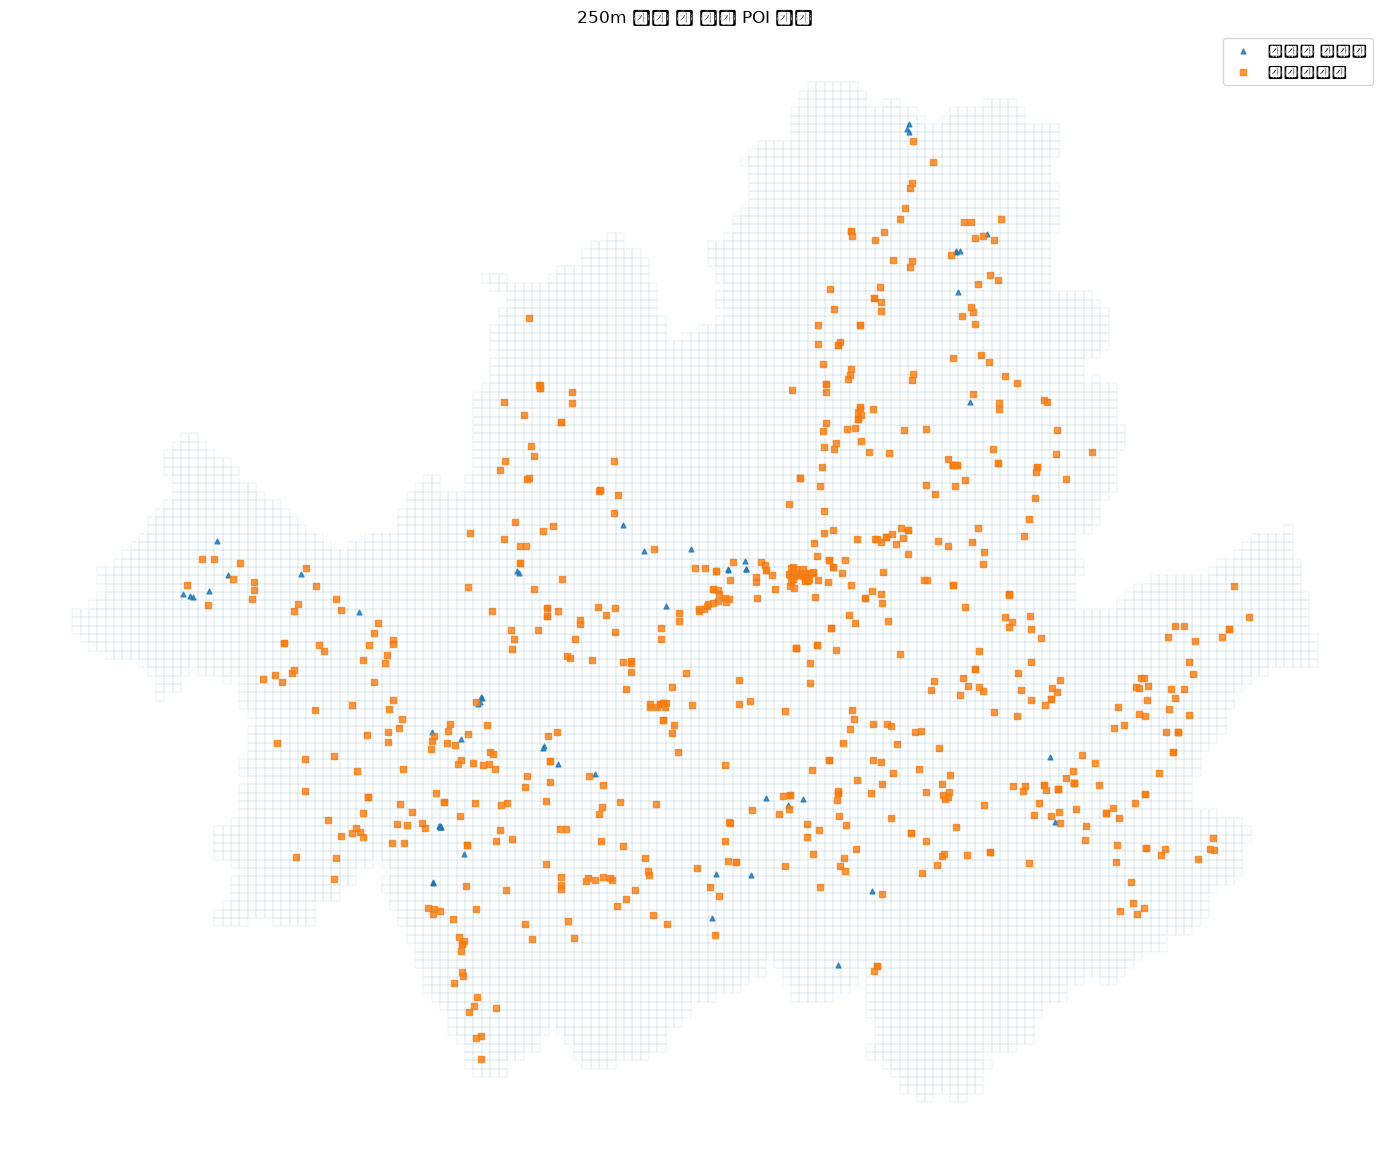

In [240]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import os

# -----------------------------
# 0. 변수 자동 탐색 함수
# -----------------------------
def pick_var(candidates):
    for name in candidates:
        if name in globals():
            print(f"[사용] {name}")
            return globals()[name]
    print(f"[없음] 후보 변수들: {candidates}")
    return None

# -----------------------------
# 1. 격자 데이터 찾기
# -----------------------------
grid = pick_var([
    "map_18_full",
    "grid_gdf",
    "grid_250",
    "empty_grid",
    "grid"
])

if grid is None:
    raise ValueError("250m 격자 변수(grid)를 찾지 못했어. 변수명을 직접 넣어줘.")

# GeoDataFrame 보장
if not isinstance(grid, gpd.GeoDataFrame):
    if 'geometry' not in grid.columns:
        raise ValueError("grid 데이터에 geometry 컬럼이 없음")
    grid = gpd.GeoDataFrame(grid, geometry='geometry')

# 중복 geometry 정리 (선택)
grid = grid.drop_duplicates(subset=['geometry']).copy()

# -----------------------------
# 2. POI 데이터 찾기
# -----------------------------
subway_exit = pick_var([
    "subway_exit_gdf",
    "subway_exit",
    "subway_entrance_gdf",
    "subway_entrance"
])

store = pick_var([
    "store_final",
    "store_gdf",
    "store_clean",
    "big_store_gdf"
])

market = pick_var([
    "market_final",
    "market_gdf",
    "traditional_market_gdf"
])

school_all = pick_var([
    "school_final",
    "school_gdf",
    "school_poi_gdf"
])

hospital = pick_var([
    "hospital_final",
    "hospital_gdf",
    "hospital_poi_gdf"
])

# -----------------------------
# 3. GeoDataFrame 변환 함수
# -----------------------------
def ensure_gdf(df, base_crs):
    if df is None:
        return None
    if not isinstance(df, gpd.GeoDataFrame):
        if 'geometry' not in df.columns:
            raise ValueError("geometry 컬럼이 없는 데이터가 있음")
        df = gpd.GeoDataFrame(df, geometry='geometry', crs=base_crs)
    if df.crs is None:
        df = df.set_crs(base_crs)
    elif df.crs != base_crs:
        df = df.to_crs(base_crs)
    return df.copy()

base_crs = grid.crs

subway_exit = ensure_gdf(subway_exit, base_crs)
store = ensure_gdf(store, base_crs)
market = ensure_gdf(market, base_crs)
school_all = ensure_gdf(school_all, base_crs)
hospital = ensure_gdf(hospital, base_crs)

# -----------------------------
# 4. 학교 / 대학 분리
# -----------------------------
school = None
university = None

if school_all is not None:
    cols = school_all.columns.tolist()
    print("\n[school_all 컬럼]")
    print(cols)

    # OSM에서 amenity 컬럼을 썼을 가능성
    if 'amenity' in school_all.columns:
        school = school_all[school_all['amenity'].isin(['school'])].copy()
        university = school_all[school_all['amenity'].isin(['college', 'university'])].copy()

    # 혹시 다른 분류 컬럼이 있다면 여기서 추가 가능
    elif '시설구분' in school_all.columns:
        school = school_all[school_all['시설구분'].isin(['초등학교', '중학교', '고등학교'])].copy()
        university = school_all[school_all['시설구분'].isin(['대학교', '대학'])].copy()

    else:
        print("school_all에서 학교/대학 자동 분리가 안 돼서 전체를 학교로 간주함.")
        school = school_all.copy()
        university = school_all.iloc[0:0].copy()

# -----------------------------
# 5. 빈 데이터 방지
# -----------------------------
layers = []

if subway_exit is not None and len(subway_exit) > 0:
    layers.append(("지하철 출입구", subway_exit, '^', 12))
if store is not None and len(store) > 0:
    layers.append(("대규모점포", store, 's', 18))
if market is not None and len(market) > 0:
    layers.append(("전통시장", market, 'D', 18))
if school is not None and len(school) > 0:
    layers.append(("학교", school, 'o', 12))
if university is not None and len(university) > 0:
    layers.append(("대학", university, 'P', 30))
if hospital is not None and len(hospital) > 0:
    layers.append(("병원", hospital, 'X', 24))

print("\n[plot할 레이어]")
for name, df, marker, size in layers:
    print(f"{name}: {len(df)}개")

# -----------------------------
# 6. 지도 그리기
# -----------------------------
fig, ax = plt.subplots(figsize=(14, 14))

# 배경 격자
grid.boundary.plot(ax=ax, linewidth=0.15, alpha=0.4)

# 종류별 점 표시
for name, df, marker, size in layers:
    df.plot(
        ax=ax,
        marker=marker,
        markersize=size,
        label=name,
        alpha=0.8
    )

ax.set_title("250m 격자 위 주요 POI 분포")
ax.set_axis_off()
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 잠재 횡단수요

In [119]:
score_cols = [
    "총생활인구_공개값기준",
    "버스18시승하차",
    "버스정류장수",
    "지하철출입구수",
    "대규모점포수",
    "전통시장수",
    "초중고수",
    "대학수",
    "병원수"
]

print("=== 결측치 ===")
print(map_18_full[score_cols].isna().sum())

print("\n=== 기술통계 ===")
display(
    map_18_full[score_cols].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    ).T
)

print("\n=== 값이 0보다 큰 격자 수 ===")
for c in score_cols:
    print(
        c,
        ":",
        (map_18_full[c] > 0).sum(),
        "/",
        len(map_18_full)
    )

=== 결측치 ===
총생활인구_공개값기준    1549
버스18시승하차          0
버스정류장수            0
지하철출입구수           0
대규모점포수            0
전통시장수             0
초중고수              0
대학수               0
병원수               0
dtype: int64

=== 기술통계 ===


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
총생활인구_공개값기준,8576.0,1381.409804,1741.142311,0.0,85.801042,821.939083,2149.219667,3460.4675,4368.678917,7020.558667,31714.562
버스18시승하차,10125.0,72.519565,190.087942,0.0,0.0,0.0,63.4,214.966667,368.646667,862.650667,4662.166667
버스정류장수,10125.0,1.052543,1.564624,0.0,0.0,0.0,2.0,3.0,4.0,6.0,11.0
지하철출입구수,10125.0,0.180049,0.854415,0.0,0.0,0.0,0.0,0.0,1.0,4.0,11.0
대규모점포수,10125.0,0.068642,0.330118,0.0,0.0,0.0,0.0,0.0,1.0,2.0,8.0
전통시장수,10125.0,0.056296,0.293804,0.0,0.0,0.0,0.0,0.0,0.0,1.0,7.0
초중고수,10125.0,0.135111,0.417085,0.0,0.0,0.0,0.0,1.0,1.0,2.0,4.0
대학수,10125.0,0.011556,0.122389,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0
병원수,10125.0,0.018963,0.154083,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0



=== 값이 0보다 큰 격자 수 ===
총생활인구_공개값기준 : 8385 / 10125
버스18시승하차 : 4300 / 10125
버스정류장수 : 4304 / 10125
지하철출입구수 : 623 / 10125
대규모점포수 : 548 / 10125
전통시장수 : 462 / 10125
초중고수 : 1129 / 10125
대학수 : 105 / 10125
병원수 : 169 / 10125


In [120]:
# 잠재 횡단수요 분석용 데이터
demand_df = map_18_full[
    map_18_full["총생활인구_공개값기준"].notna()
].copy()

print("전체 격자:", len(map_18_full))
print("생활인구 공개 격자:", len(demand_df))
print("제외된 생활인구 결측 격자:",
      map_18_full["총생활인구_공개값기준"].isna().sum())

전체 격자: 10125
생활인구 공개 격자: 8576
제외된 생활인구 결측 격자: 1549


In [121]:
# 양수 값만 percentile rank로 변환하는 함수
def positive_percentile(series):
    result = pd.Series(0.0, index=series.index)

    positive = series > 0

    result.loc[positive] = (
        series.loc[positive]
        .rank(method="average", pct=True)
    )

    return result


score_source_cols = [
    "총생활인구_공개값기준",
    "버스18시승하차",
    "버스정류장수",
    "지하철출입구수",
    "대규모점포수",
    "전통시장수",
    "초중고수",
    "대학수",
    "병원수"
]

for col in score_source_cols:
    demand_df[col + "_pct"] = positive_percentile(
        demand_df[col]
    )

# 변환 결과 확인
display(
    demand_df[
        [c + "_pct" for c in score_source_cols]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
총생활인구_공개값기준_pct,8576.0,0.488923,0.294843,0.0,0.233005,0.488670,0.744335,1.000000
버스18시승하차_pct,8576.0,0.250292,0.322873,0.0,0.000000,0.001048,0.500553,1.000000
버스정류장수_pct,8576.0,0.250525,0.318390,0.0,0.000000,0.140480,0.454143,0.999884
지하철출입구수_pct,8576.0,0.036381,0.150533,0.0,0.000000,0.000000,0.000000,1.000000
대규모점포수_pct,8576.0,0.032008,0.132303,0.0,0.000000,0.000000,0.000000,1.000000
전통시장수_pct,8576.0,0.026994,0.120755,0.0,0.000000,0.000000,0.000000,1.000000
초중고수_pct,8576.0,0.065765,0.182583,0.0,0.000000,0.000000,0.000000,0.997338
대학수_pct,8576.0,0.006122,0.056954,0.0,0.000000,0.000000,0.000000,1.000000
병원수_pct,8576.0,0.009911,0.073502,0.0,0.000000,0.000000,0.000000,0.994083


In [122]:
# ① 생활활동
demand_df["생활활동점수"] = (
    demand_df["총생활인구_공개값기준_pct"]
)

# ② 대중교통
demand_df["대중교통점수"] = demand_df[
    [
        "버스18시승하차_pct",
        "버스정류장수_pct",
        "지하철출입구수_pct"
    ]
].mean(axis=1)

# ③ 주요 목적시설
demand_df["주요시설점수"] = demand_df[
    [
        "대규모점포수_pct",
        "전통시장수_pct",
        "초중고수_pct",
        "대학수_pct",
        "병원수_pct"
    ]
].mean(axis=1)

# 세 영역 동일가중치
demand_df["잠재횡단수요점수"] = (
    (
        demand_df["생활활동점수"]
        + demand_df["대중교통점수"]
        + demand_df["주요시설점수"]
    )
    / 3
    * 100
)

print("분석 격자:", len(demand_df))

display(
    demand_df[
        [
            "생활활동점수",
            "대중교통점수",
            "주요시설점수",
            "잠재횡단수요점수"
        ]
    ].describe(
        percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
    ).T
)

분석 격자: 8576


,count,mean,std,min,50%,75%,90%,95%,99%,max
생활활동점수,8576.0,0.488923,0.294843,0.0,0.488670,0.744335,0.897734,0.948867,0.989773,1.000000
대중교통점수,8576.0,0.179066,0.220910,0.0,0.053311,0.344977,0.514782,0.591305,0.813667,0.987161
주요시설점수,8576.0,0.028160,0.057320,0.0,0.000000,0.000000,0.084632,0.170198,0.261108,0.453428
잠재횡단수요점수,8576.0,23.204939,15.242717,0.0,22.339495,34.383559,43.985026,49.104047,58.997572,75.306704


In [123]:
top_demand = (
    demand_df
    .sort_values(
        "잠재횡단수요점수",
        ascending=False
    )
    .head(30)
)

display(
    top_demand[
        [
            "250M격자",
            "잠재횡단수요점수",
            "생활활동점수",
            "대중교통점수",
            "주요시설점수",
            "총생활인구_공개값기준",
            "버스18시승하차",
            "버스정류장수",
            "지하철출입구수",
            "대규모점포수",
            "전통시장수",
            "초중고수",
            "대학수",
            "병원수"
        ]
    ]
)

,250M격자,잠재횡단수요점수,생활활동점수,대중교통점수,주요시설점수,총생활인구_공개값기준,버스18시승하차,버스정류장수,지하철출입구수,대규모점포수,전통시장수,초중고수,대학수,병원수
2518,다사48755775,75.306704,0.990817,0.986307,0.282077,7183.273,1795.600000,8,8,4,1,0,0,0
683,다사41255000,73.190792,0.982588,0.856042,0.357094,6036.274667,364.233333,5,4,2,2,0,0,0
2728,다사49504275,71.621476,0.995826,0.891179,0.261639,9215.165,1569.266667,3,8,2,1,0,0,0
3533,다사51504950,71.499519,0.988670,0.799221,0.357094,6823.652667,504.266667,3,4,2,2,0,0,0
5058,다사55755225,70.460779,0.986881,0.738694,0.388248,6566.405333,769.666667,4,2,3,3,0,0,0
1281,다사44754725,70.176664,0.987955,0.918529,0.198817,6741.239333,696.866667,5,5,0,0,0,0,3
6045,다사58005975,67.720081,0.959809,0.987161,0.084632,4725.279667,4065.200000,8,8,0,1,0,0,0
5697,다사57255475,67.687161,0.847466,0.928738,0.254411,2906.961333,1479.600000,4,7,1,1,0,0,1
2948,다사50005075,67.408811,0.985808,0.859449,0.177007,6455.463667,1750.666667,6,3,2,0,0,0,0
4376,다사54004275,66.706613,0.986166,0.934011,0.081022,6519.937,780.966667,6,5,1,0,0,0,0


In [124]:
# 기존 영역 점수는 raw로 보존
demand_df["생활활동_raw"] = demand_df["생활활동점수"]
demand_df["대중교통_raw"] = demand_df["대중교통점수"]
demand_df["주요시설_raw"] = demand_df["주요시설점수"]

# 각 영역 자체를 다시 0~1 percentile로 표준화
demand_df["생활활동점수_v2"] = positive_percentile(
    demand_df["생활활동_raw"]
)

demand_df["대중교통점수_v2"] = positive_percentile(
    demand_df["대중교통_raw"]
)

demand_df["주요시설점수_v2"] = positive_percentile(
    demand_df["주요시설_raw"]
)

# 최종 잠재 횡단수요 점수 v2
demand_df["잠재횡단수요점수_v2"] = (
    demand_df[
        [
            "생활활동점수_v2",
            "대중교통점수_v2",
            "주요시설점수_v2"
        ]
    ].mean(axis=1)
    * 100
)

display(
    demand_df[
        [
            "생활활동점수_v2",
            "대중교통점수_v2",
            "주요시설점수_v2",
            "잠재횡단수요점수_v2"
        ]
    ].describe(
        percentiles=[.5, .75, .9, .95, .99]
    ).T
)

,count,mean,std,min,50%,75%,90%,95%,99%,max
생활활동점수_v2,8576.0,0.488923,0.294843,0.0,0.488670,0.744335,0.897734,0.948867,0.989773,1.000000
대중교통점수_v2,8576.0,0.255655,0.324205,0.0,0.022012,0.511006,0.804402,0.902201,0.980440,1.000000
주요시설점수_v2,8576.0,0.122901,0.255890,0.0,0.000000,0.000000,0.597532,0.796096,0.957523,1.000000
잠재횡단수요점수_v2,8576.0,28.915967,21.202380,0.0,26.076327,44.066765,58.449612,66.610376,85.191171,99.100944


In [125]:
top_demand_v2 = (
    demand_df
    .sort_values(
        "잠재횡단수요점수_v2",
        ascending=False
    )
    .head(30)
)

display(
    top_demand_v2[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "생활활동점수_v2",
            "대중교통점수_v2",
            "주요시설점수_v2",
            "총생활인구_공개값기준",
            "버스18시승하차",
            "버스정류장수",
            "지하철출입구수",
            "대규모점포수",
            "전통시장수",
            "초중고수",
            "대학수",
            "병원수"
        ]
    ]
)

,250M격자,잠재횡단수요점수_v2,생활활동점수_v2,대중교통점수_v2,주요시설점수_v2,총생활인구_공개값기준,버스18시승하차,버스정류장수,지하철출입구수,대규모점포수,전통시장수,초중고수,대학수,병원수
2518,다사48755775,99.100944,0.990817,0.999772,0.982439,7183.273,1795.600000,8,8,4,1,0,0,0
683,다사41255000,98.638465,0.982588,0.986770,0.989796,6036.274667,364.233333,5,4,2,2,0,0,0
3533,다사51504950,98.544675,0.988670,0.977874,0.989796,6823.652667,504.266667,3,4,2,2,0,0,0
2728,다사49504275,98.392402,0.995826,0.992016,0.963930,9215.165,1569.266667,3,8,2,1,0,0,0
5058,다사55755225,98.350396,0.986881,0.966241,0.997390,6566.405333,769.666667,4,2,3,3,0,0,0
1281,다사44754725,97.484706,0.987955,0.995438,0.941149,6741.239333,696.866667,5,5,0,0,0,0,3
4328,다사53755100,97.147658,0.979606,0.945027,0.989796,5802.080667,365.066667,2,3,2,2,0,0,0
9018,다사64754600,96.946129,0.999165,0.926779,0.982439,16928.938333,1190.233333,2,2,4,1,0,0,0
9539,다사66754875,96.304729,0.981515,0.936816,0.970812,5945.766333,390.600000,1,5,2,0,0,0,1
4135,다사53254275,96.104337,0.937627,0.968522,0.976981,4118.617333,240.766667,4,3,1,3,0,0,0


In [126]:
print(
    "v1-v2 순위 상관:",
    demand_df[
        [
            "잠재횡단수요점수",
            "잠재횡단수요점수_v2"
        ]
    ].corr(method="spearman").iloc[0, 1]
)

v1-v2 순위 상관: 0.9639998792135414


In [128]:
# 잠재 횡단수요 상위 30개 geometry 정리

top30_geo = top_demand_v2.copy()

# 이미 geometry가 있으면 그대로 사용
if "geometry" not in top30_geo.columns:
    top30_geo = top30_geo.merge(
        grid_250[["250M격자", "geometry"]],
        on="250M격자",
        how="left"
    )

# 혹시 이전 merge 때문에 geometry_x / geometry_y가 생겼다면 정리
if "geometry" not in top30_geo.columns:
    if "geometry_x" in top30_geo.columns:
        top30_geo["geometry"] = top30_geo["geometry_x"]
    elif "geometry_y" in top30_geo.columns:
        top30_geo["geometry"] = top30_geo["geometry_y"]

top30_geo = gpd.GeoDataFrame(
    top30_geo,
    geometry="geometry",
    crs=grid_250.crs
)

# 격자 중심점
top30_geo["center"] = top30_geo.geometry.centroid

# 중심점을 위경도로 변환
centers = gpd.GeoSeries(
    top30_geo["center"],
    crs=top30_geo.crs
).to_crs("EPSG:4326")

top30_geo["경도"] = centers.x
top30_geo["위도"] = centers.y

top30_geo["순위"] = range(1, len(top30_geo) + 1)

print("CRS:", top30_geo.crs)
print("geometry 결측:", top30_geo.geometry.isna().sum())

display(
    top30_geo[
        [
            "순위",
            "250M격자",
            "잠재횡단수요점수_v2",
            "경도",
            "위도"
        ]
    ].head(30)
)

CRS: EPSG:5179
geometry 결측: 0


,순위,250M격자,잠재횡단수요점수_v2,경도,위도
2518,1,다사48755775,99.100944,126.920681,37.618897
683,2,다사41255000,98.638465,126.836320,37.548599
3533,3,다사51504950,98.544675,126.952386,37.544688
2728,4,다사49504275,98.392402,126.930209,37.483742
5058,5,다사55755225,98.350396,127.000329,37.569688
1281,6,다사44754725,97.484706,126.876147,37.524029
4328,7,다사53755100,97.147658,126.977761,37.558323
9018,8,다사64754600,96.946129,127.102542,37.513741
9539,9,다사66754875,96.304729,127.125048,37.538602
4135,10,다사53254275,96.104337,126.972624,37.483938


c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51104 (\N{HANGUL SYLLABLE JAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54945 (\N{HANGUL SYLLABLE HOENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\

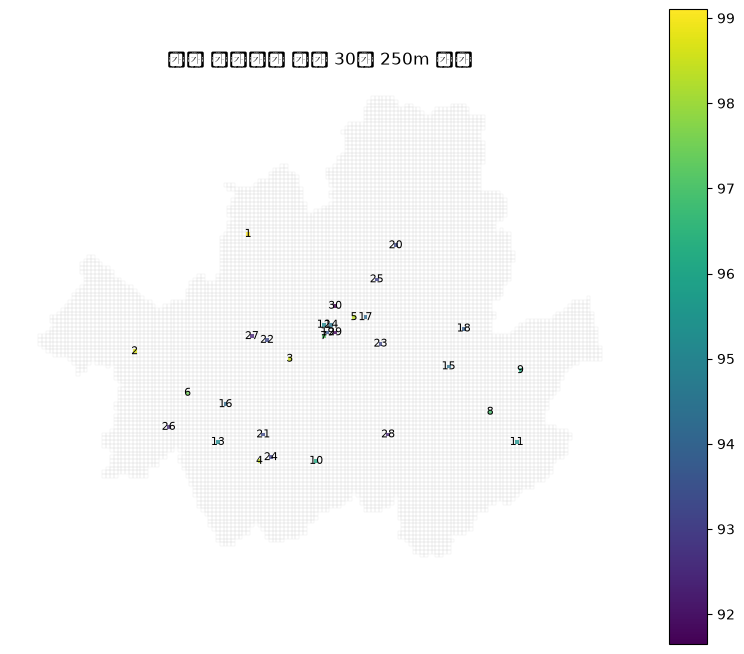

In [129]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# 서울 250m 격자 배경
grid_250.plot(
    ax=ax,
    facecolor="none",
    edgecolor="lightgray",
    linewidth=0.15
)

# 상위 30개 격자
top30_geo.plot(
    ax=ax,
    column="잠재횡단수요점수_v2",
    legend=True,
    alpha=0.8
)

# 순위 표시
for _, row in top30_geo.iterrows():
    p = row["center"]
    ax.text(
        p.x,
        p.y,
        str(row["순위"]),
        fontsize=8,
        ha="center",
        va="center"
    )

ax.set_title("잠재 횡단수요 상위 30개 250m 격자")
ax.set_axis_off()

plt.show()

In [251]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()

kakao_key = os.getenv("KAKAO_REST_API_KEY")

if not kakao_key:
    print("❌ .env에서 키를 못 읽음")
else:
    url = "https://dapi.kakao.com/v2/local/geo/coord2regioncode.json"

    headers = {
        "Authorization": f"KakaoAK {kakao_key}"
    }

    params = {
        "x": 126.9780,
        "y": 37.5665
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    print("status:", r.status_code)

    if r.status_code == 200:
        print("✅ 새 Kakao REST API 키 정상 작동")
        print(r.json()["documents"][0]["address_name"])
    else:
        print("❌ 오류")
        print(r.text)

status: 200
✅ 새 Kakao REST API 키 정상 작동
서울특별시 중구 태평로1가


In [132]:
import requests
import pandas as pd
from tqdm.auto import tqdm
import time

# 기존 카카오 REST API 키 사용
headers = {
    "Authorization": f"KakaoAK {KAKAO_REST_API_KEY}"
}

def kakao_coord_to_region(lon, lat):
    url = "https://dapi.kakao.com/v2/local/geo/coord2regioncode.json"

    params = {
        "x": lon,
        "y": lat
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    if r.status_code != 200:
        return pd.Series([None, None, None, None])

    docs = r.json().get("documents", [])

    # 행정동(H) 우선
    h_docs = [
        d for d in docs
        if d.get("region_type") == "H"
    ]

    d = h_docs[0] if h_docs else (docs[0] if docs else None)

    if d is None:
        return pd.Series([None, None, None, None])

    return pd.Series([
        d.get("region_1depth_name"),
        d.get("region_2depth_name"),
        d.get("region_3depth_name"),
        d.get("address_name")
    ])


region_result = []

for _, row in tqdm(top30_geo.iterrows(), total=len(top30_geo)):
    region_result.append(
        kakao_coord_to_region(
            row["경도"],
            row["위도"]
        )
    )
    time.sleep(0.05)

region_df = pd.DataFrame(
    region_result,
    columns=[
        "시도",
        "자치구",
        "행정동",
        "행정구역"
    ],
    index=top30_geo.index
)

top30_geo[
    ["시도", "자치구", "행정동", "행정구역"]
] = region_df

display(
    top30_geo[
        [
            "순위",
            "250M격자",
            "잠재횡단수요점수_v2",
            "자치구",
            "행정동",
            "행정구역",
            "경도",
            "위도"
        ]
    ]
)

  0%|          | 0/30 [00:00<?, ?it/s]

,순위,250M격자,잠재횡단수요점수_v2,자치구,행정동,행정구역,경도,위도
2518,1,다사48755775,99.100944,NaN,NaN,NaN,126.920681,37.618897
683,2,다사41255000,98.638465,NaN,NaN,NaN,126.836320,37.548599
3533,3,다사51504950,98.544675,NaN,NaN,NaN,126.952386,37.544688
2728,4,다사49504275,98.392402,NaN,NaN,NaN,126.930209,37.483742
5058,5,다사55755225,98.350396,NaN,NaN,NaN,127.000329,37.569688
1281,6,다사44754725,97.484706,NaN,NaN,NaN,126.876147,37.524029
4328,7,다사53755100,97.147658,NaN,NaN,NaN,126.977761,37.558323
9018,8,다사64754600,96.946129,NaN,NaN,NaN,127.102542,37.513741
9539,9,다사66754875,96.304729,NaN,NaN,NaN,127.125048,37.538602
4135,10,다사53254275,96.104337,NaN,NaN,NaN,126.972624,37.483938


In [133]:
# 이미 받아둔 region_result를 올바르게 DataFrame으로 변환
region_df = pd.DataFrame(
    [x.tolist() for x in region_result],
    columns=[
        "시도",
        "자치구",
        "행정동",
        "행정구역"
    ],
    index=top30_geo.index
)

top30_geo[
    ["시도", "자치구", "행정동", "행정구역"]
] = region_df

display(
    top30_geo[
        [
            "순위",
            "250M격자",
            "잠재횡단수요점수_v2",
            "자치구",
            "행정동",
            "행정구역",
            "경도",
            "위도"
        ]
    ]
)

,순위,250M격자,잠재횡단수요점수_v2,자치구,행정동,행정구역,경도,위도
2518,1,다사48755775,99.100944,은평구,갈현1동,서울특별시 은평구 갈현1동,126.920681,37.618897
683,2,다사41255000,98.638465,강서구,우장산동,서울특별시 강서구 우장산동,126.836320,37.548599
3533,3,다사51504950,98.544675,마포구,공덕동,서울특별시 마포구 공덕동,126.952386,37.544688
2728,4,다사49504275,98.392402,관악구,서원동,서울특별시 관악구 서원동,126.930209,37.483742
5058,5,다사55755225,98.350396,종로구,종로1.2.3.4가동,서울특별시 종로구 종로1.2.3.4가동,127.000329,37.569688
1281,6,다사44754725,97.484706,양천구,목1동,서울특별시 양천구 목1동,126.876147,37.524029
4328,7,다사53755100,97.147658,중구,회현동,서울특별시 중구 회현동,126.977761,37.558323
9018,8,다사64754600,96.946129,송파구,잠실6동,서울특별시 송파구 잠실6동,127.102542,37.513741
9539,9,다사66754875,96.304729,강동구,천호2동,서울특별시 강동구 천호2동,127.125048,37.538602
4135,10,다사53254275,96.104337,동작구,사당3동,서울특별시 동작구 사당3동,126.972624,37.483938


In [134]:
# 잠재 횡단수요 v2 checkpoint 저장
save_path = DATA / "potential_crossing_demand_v2.csv"

demand_df.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", save_path)
print("분석 격자:", len(demand_df))

저장 완료: C:\livinglab\데이터\potential_crossing_demand_v2.csv
분석 격자: 8576


### 우회부담

In [136]:
import pandas as pd

# 도보네트워크 후보 데이터프레임 안전하게 찾기
for name in list(globals().keys()):
    if name.startswith("_"):
        continue

    try:
        obj = globals()[name]

        # pandas DataFrame / GeoDataFrame만
        if not isinstance(obj, pd.DataFrame):
            continue

        cols = list(obj.columns)

        required = {
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이"
        }

        if required.issubset(set(cols)):
            print(
                "후보 변수명:", name,
                "| 크기:", obj.shape
            )
            print(
                "관련 컬럼:",
                [
                    c for c in cols
                    if c in [
                        "노드링크 유형",
                        "링크 WKT",
                        "링크 ID",
                        "시작노드 ID",
                        "종료노드 ID",
                        "링크 길이",
                        "횡단보도",
                        "육교",
                        "지하철네트워크",
                        "교량",
                        "터널",
                        "고가도로"
                    ]
                ]
            )
            print()
            
    except Exception:
        # 깨진 GeoDataFrame 등은 그냥 건너뜀
        continue

후보 변수명: subway_raw | 크기: (491082, 23)
관련 컬럼: ['노드링크 유형', '링크 WKT', '링크 ID', '시작노드 ID', '종료노드 ID', '링크 길이', '고가도로', '지하철네트워크', '교량', '터널', '육교', '횡단보도']

후보 변수명: subway_exit | 크기: (57, 24)
관련 컬럼: ['노드링크 유형', '링크 WKT', '링크 ID', '시작노드 ID', '종료노드 ID', '링크 길이', '고가도로', '지하철네트워크', '교량', '터널', '육교', '횡단보도']

후보 변수명: subway_exit_gdf | 크기: (57, 26)
관련 컬럼: ['노드링크 유형', '링크 WKT', '링크 ID', '시작노드 ID', '종료노드 ID', '링크 길이', '고가도로', '지하철네트워크', '교량', '터널', '육교', '횡단보도']



In [137]:
NETWORK_DF = subway_raw

check_cols = [
    "횡단보도",
    "육교",
    "지하철네트워크",
    "교량",
    "터널",
    "고가도로"
]

for col in check_cols:
    print(f"\n=== {col} ===")
    print(
        NETWORK_DF[col]
        .value_counts(dropna=False)
        .head(20)
    )


=== 횡단보도 ===
횡단보도
0    463756
1     27326
Name: count, dtype: Int64

=== 육교 ===
육교
0    487940
1      3142
Name: count, dtype: Int64

=== 지하철네트워크 ===
지하철네트워크
0       278842
<NA>    212066
1          174
Name: count, dtype: Int64

=== 교량 ===
교량
0       278440
<NA>    212066
1          576
Name: count, dtype: Int64

=== 터널 ===
터널
0       278835
<NA>    212066
1          181
Name: count, dtype: Int64

=== 고가도로 ===
고가도로
0       276185
<NA>    212066
1         2831
Name: count, dtype: Int64


In [138]:
# 링크 행만 추출
link_rows = NETWORK_DF[
    NETWORK_DF["노드링크 유형"] == "LINK"
].copy()

print("전체 LINK 수:", len(link_rows))

display(
    link_rows[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "횡단보도",
            "육교",
            "지하철네트워크",
            "교량",
            "터널",
            "고가도로"
        ]
    ].head(20)
)

전체 LINK 수: 279016


,링크 ID,시작노드 ID,종료노드 ID,링크 길이,횡단보도,육교,지하철네트워크,교량,터널,고가도로
2,87832,136212,136213,7.318,0,0,0,0,0,0
4,90804,129943,129944,18.529,0,0,0,0,0,0
6,66072,147978,147980,26.343,0,0,0,0,0,0
7,35662,129112,129113,15.007,0,0,0,0,0,0
13,110874,128067,128065,43.732,0,0,0,0,0,0
14,111387,135392,135395,58.092,0,0,0,0,0,0
15,29769,136908,136909,48.755,0,0,0,0,0,0
16,114318,152122,152464,14.778,0,0,0,0,0,0
23,27139,137310,137311,30.091,0,0,0,0,0,0
24,12334,135309,135310,21.377,1,0,0,0,0,0


In [139]:
flag_cols = [
    "횡단보도",
    "육교",
    "지하철네트워크",
    "교량",
    "터널",
    "고가도로"
]

print("전체 LINK 수:", len(link_rows))

for col in flag_cols:
    print(f"\n=== LINK 기준 {col} ===")
    print(
        link_rows[col]
        .value_counts(dropna=False)
    )

전체 LINK 수: 279016

=== LINK 기준 횡단보도 ===
횡단보도
0    271118
1      7898
Name: count, dtype: Int64

=== LINK 기준 육교 ===
육교
0    277557
1      1459
Name: count, dtype: Int64

=== LINK 기준 지하철네트워크 ===
지하철네트워크
0    278842
1       174
Name: count, dtype: Int64

=== LINK 기준 교량 ===
교량
0    278440
1       576
Name: count, dtype: Int64

=== LINK 기준 터널 ===
터널
0    278835
1       181
Name: count, dtype: Int64

=== LINK 기준 고가도로 ===
고가도로
0    276185
1      2831
Name: count, dtype: Int64


In [141]:
# 횡단 관련 플래그를 확실히 숫자로 처리
cross_flags = (
    link_rows[
        ["횡단보도", "육교", "지하철네트워크"]
    ]
    .fillna(0)
    .astype(int)
)

crossing_mask = cross_flags.eq(1).any(axis=1)

crossing_links = link_rows.loc[crossing_mask].copy()

print("전체 LINK 수:", len(link_rows))
print("횡단 관련 LINK 수:", len(crossing_links))

print("\n유형별:")
print("횡단보도:", (cross_flags["횡단보도"] == 1).sum())
print("육교:", (cross_flags["육교"] == 1).sum())
print("지하철네트워크:", (cross_flags["지하철네트워크"] == 1).sum())

display(
    crossing_links[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "링크 유형 코드",
            "시군구명",
            "읍면동명",
            "횡단보도",
            "육교",
            "지하철네트워크",
            "링크 WKT"
        ]
    ].head(30)
)

전체 LINK 수: 279016
횡단 관련 LINK 수: 9493

유형별:
횡단보도: 7898
육교: 1459
지하철네트워크: 174


,링크 ID,시작노드 ID,종료노드 ID,링크 길이,링크 유형 코드,시군구명,읍면동명,횡단보도,육교,지하철네트워크,링크 WKT
24,12334,135309,135310,21.377,1000,종로구,와룡동,1,0,0,LINESTRING(126.9930979444826 37.58414380519662...
60,228523,164078,11153,16.843,1000,종로구,와룡동,1,0,0,LINESTRING(126.99521005160936 37.5841057622047...
63,228522,135324,135314,87.695,1000,종로구,와룡동,1,0,0,LINESTRING(126.99334944838317 37.5825341182016...
146,228924,127952,157642,69.732,1000,종로구,삼청동,1,0,0,LINESTRING(126.98438579024156 37.5890620920126...
245,250119,211367,212495,383.823,1000,종로구,예지동,1,0,0,LINESTRING(127.0047787530125 37.56960660487279...
291,157659,135304,133838,741.739,1000,종로구,와룡동,1,0,0,LINESTRING(126.99203763559393 37.5856287111508...
328,10073,131407,131408,21.003,1000,종로구,세종로,1,0,0,LINESTRING(126.97568634473919 37.5809362199311...
336,140517,135343,135342,40.238,1111,종로구,와룡동,1,0,0,LINESTRING(126.99121190407533 37.5786697518429...
471,223046,167293,194259,16.489,1000,종로구,충신동,1,0,0,LINESTRING(127.00878086357014 37.5753042588434...
486,236376,135319,135320,14.741,1000,종로구,와룡동,1,0,0,LINESTRING(126.99374863926093 37.5827788899709...


In [142]:
# 1. 횡단시설 플래그 중복 확인

flags = ["횡단보도", "육교", "지하철네트워크"]

tmp = link_rows[flags].fillna(0).astype(int)

print("=== 조합별 LINK 수 ===")
display(
    tmp.value_counts()
       .reset_index(name="LINK수")
       .sort_values("LINK수", ascending=False)
)

print("\n두 종류 이상 동시에 표시된 LINK:",
      (tmp.sum(axis=1) >= 2).sum())

=== 조합별 LINK 수 ===


,횡단보도,육교,지하철네트워크,LINK수
0,0,0,0,269523
1,1,0,0,7860
2,0,1,0,1426
3,0,0,1,169
4,1,1,0,33
5,1,0,1,5



두 종류 이상 동시에 표시된 LINK: 38


In [143]:
# 2. 횡단시설별 링크 특성 확인

for col in ["횡단보도", "육교", "지하철네트워크"]:
    x = link_rows[
        link_rows[col].fillna(0).astype(int) == 1
    ]

    print(f"\n===== {col} =====")
    print("LINK 수:", len(x))

    print("\n링크 유형 코드:")
    print(
        x["링크 유형 코드"]
        .value_counts()
        .head(15)
    )

    print("\n링크 길이:")
    print(
        x["링크 길이"]
        .describe(
            percentiles=[.25, .5, .75, .9, .95, .99]
        )
    )


===== 횡단보도 =====
LINK 수: 7898

링크 유형 코드:
링크 유형 코드
1011    3972
1000    3156
1111     748
1010       9
1110       3
0011       3
1100       3
0100       2
0000       1
0111       1
Name: count, dtype: Int64

링크 길이:
count       7898
unique      7355
top       11.941
freq           8
Name: 링크 길이, dtype: object

===== 육교 =====
LINK 수: 1459

링크 유형 코드:
링크 유형 코드
1111    1320
1011     110
1000      28
1100       1
Name: count, dtype: Int64

링크 길이:
count      1459
unique     1426
top       7.552
freq          3
Name: 링크 길이, dtype: object

===== 지하철네트워크 =====
LINK 수: 174

링크 유형 코드:
링크 유형 코드
1011    72
1111    52
1000    48
0100     2
Name: count, dtype: Int64

링크 길이:
count        174
unique       174
top       31.695
freq           1
Name: 링크 길이, dtype: object


c:\livinglab\.venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.

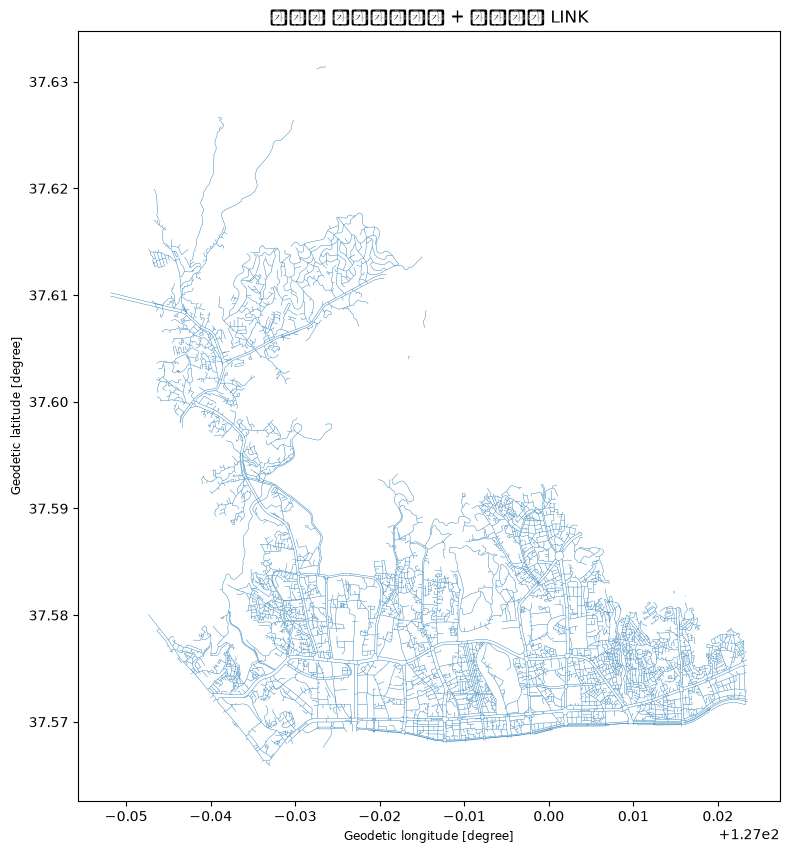

In [144]:
from shapely import wkt
import geopandas as gpd
import matplotlib.pyplot as plt

# 종로구 LINK만 사용
jongno = link_rows[
    link_rows["시군구명"] == "종로구"
].copy()

jongno["geometry"] = jongno["링크 WKT"].apply(
    lambda x: wkt.loads(x) if pd.notna(x) else None
)

jongno_gdf = gpd.GeoDataFrame(
    jongno,
    geometry="geometry",
    crs="EPSG:4326"
)

# 전체 도보망
ax = jongno_gdf.plot(
    figsize=(10, 10),
    linewidth=0.3
)

# 횡단보도 링크를 더 굵게
jongno_gdf[
    jongno_gdf["횡단보도"] == 1
].plot(
    ax=ax,
    linewidth=2
)

plt.title("종로구 도보네트워크 + 횡단보도 LINK")
plt.show()

In [145]:
link_rows["링크 길이"] = pd.to_numeric(
    link_rows["링크 길이"],
    errors="coerce"
)

print("길이 결측:", link_rows["링크 길이"].isna().sum())

for col in ["횡단보도", "육교", "지하철네트워크"]:
    x = link_rows[
        link_rows[col].fillna(0).astype(int) == 1
    ]

    print(f"\n===== {col} 링크 길이(m) =====")
    print(
        x["링크 길이"].describe(
            percentiles=[.25, .5, .75, .9, .95, .99]
        )
    )

길이 결측: 0

===== 횡단보도 링크 길이(m) =====
count        7898.0
mean      91.936777
std      171.958152
min           0.187
25%        21.43425
50%          44.608
75%         94.3125
90%        197.8393
95%         313.435
99%       800.43099
max         5376.28
Name: 링크 길이, dtype: Float64

===== 육교 링크 길이(m) =====
count       1459.0
mean     58.448585
std      66.739452
min          2.318
25%         18.998
50%         37.082
75%        72.8425
90%       124.4772
95%       180.3756
99%      311.54118
max        769.564
Name: 링크 길이, dtype: Float64

===== 지하철네트워크 링크 길이(m) =====
count         174.0
mean     118.658437
std      168.581829
min           3.844
25%        18.84725
50%          47.334
75%       137.55275
90%         322.851
95%        495.4384
99%        773.7248
max         829.333
Name: 링크 길이, dtype: Float64


In [148]:
# 와룡동 데이터 상태 점검

print("와룡동 전체 LINK:", len(sample_area))

print("\n횡단보도 값:")
print(
    sample_area["횡단보도"]
    .value_counts(dropna=False)
)

print("\n횡단보도 dtype:")
print(sample_area["횡단보도"].dtype)

print("\n읍면동명 실제 값:")
print(
    jongno_gdf["읍면동명"]
    .dropna()
    .astype(str)
    .loc[
        jongno_gdf["읍면동명"]
        .astype(str)
        .str.contains("와룡", na=False)
    ]
    .unique()
)

와룡동 전체 LINK: 151

횡단보도 값:
횡단보도
0    90
1    61
Name: count, dtype: Int64

횡단보도 dtype:
string

읍면동명 실제 값:
<StringArray>
['와룡동']
Length: 1, dtype: str


In [149]:
cross_test = link_rows[
    link_rows["횡단보도"]
    .fillna(0)
    .astype(int)
    .eq(1)
].copy()

display(
    cross_test[
        [
            "링크 ID",
            "시군구명",
            "읍면동명",
            "링크 길이",
            "링크 유형 코드",
            "링크 WKT"
        ]
    ]
    .sort_values("링크 길이", ascending=False)
    .head(20)
)

,링크 ID,시군구명,읍면동명,링크 길이,링크 유형 코드,링크 WKT
180325,168320,도봉구,월계동,5376.28,1011,LINESTRING(127.06885538825905 37.6245476837362...
279770,280323,양천구,목동,2892.172,1011,LINESTRING(126.88961198089689 37.5383363076451...
331458,183822,금천구,시흥동,2803.247,1011,LINESTRING(126.88961883759767 37.4610039067779...
467349,118095,송파구,문정동,2500.572,1011,LINESTRING(127.10927596023065 37.4887428366124...
58525,218832,성동구,금호동4가,2330.983,1011,LINESTRING(127.00735714760442 37.5282980824989...
325318,231054,구로구,대림동,2187.683,1011,LINESTRING(126.91271082345845 37.4872915754263...
66832,279623,성동구,금호동4가,2139.234,1011,LINESTRING(127.04522587817235 37.5370192229216...
66736,236295,성동구,송정동,1940.757,1011,LINESTRING(127.0472853880068 37.55250328138288...
417417,169834,서초구,우면동,1873.783,1011,LINESTRING(127.0280727319958 37.46173020307181...
332769,146463,금천구,시흥동,1853.129,1011,LINESTRING(126.89246759398482 37.4544709469258...


In [150]:
print("50m 이하:", (cross_test["링크 길이"] <= 50).sum())
print("50~100m:", ((cross_test["링크 길이"] > 50) & 
                   (cross_test["링크 길이"] <= 100)).sum())
print("100~200m:", ((cross_test["링크 길이"] > 100) & 
                    (cross_test["링크 길이"] <= 200)).sum())
print("200m 초과:", (cross_test["링크 길이"] > 200).sum())
print("500m 초과:", (cross_test["링크 길이"] > 500).sum())
print("1km 초과:", (cross_test["링크 길이"] > 1000).sum())

50m 이하: 4292
50~100m: 1772
100~200m: 1054
200m 초과: 780
500m 초과: 186
1km 초과: 46


In [151]:
flag_cols = [
    "횡단보도",
    "육교",
    "지하철네트워크",
    "교량",
    "터널",
    "고가도로"
]

for col in flag_cols:
    link_rows[col] = (
        pd.to_numeric(link_rows[col], errors="coerce")
        .fillna(0)
        .astype(int)
    )

print(link_rows[flag_cols].dtypes)

횡단보도       int64
육교         int64
지하철네트워크    int64
교량         int64
터널         int64
고가도로       int64
dtype: object


와룡동 전체 LINK: 151
횡단보도 표시 LINK: 61


c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50752 (\N{HANGUL SYLLABLE WA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47329 (\N{HANGUL SYLLABLE RYONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\L

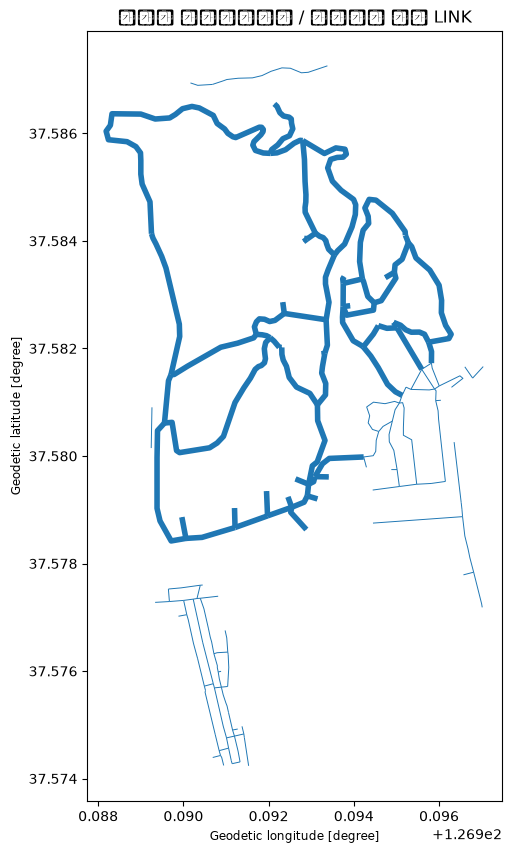

In [152]:
from shapely import wkt
import geopandas as gpd
import matplotlib.pyplot as plt

sample_area = link_rows[
    (link_rows["시군구명"] == "종로구") &
    (link_rows["읍면동명"] == "와룡동")
].copy()

sample_area["geometry"] = sample_area["링크 WKT"].apply(wkt.loads)

sample_gdf = gpd.GeoDataFrame(
    sample_area,
    geometry="geometry",
    crs="EPSG:4326"
)

cross_gdf = sample_gdf[
    sample_gdf["횡단보도"] == 1
]

print("와룡동 전체 LINK:", len(sample_gdf))
print("횡단보도 표시 LINK:", len(cross_gdf))

ax = sample_gdf.plot(
    figsize=(10, 10),
    linewidth=0.7
)

cross_gdf.plot(
    ax=ax,
    linewidth=4
)

plt.title("와룡동 도보네트워크 / 횡단보도 표시 LINK")
plt.show()

In [154]:
import pandas as pd

# 1. 횡단보도 네트워크 형상
crosswalk_network = pd.read_csv(
    DATA / "서울시 대로변 횡단보도 위치정보.csv",
    encoding="cp949",
    low_memory=False
)

# 2. 2026 현재 횡단보도 목록
crosswalk_current = pd.read_csv(
    DATA / "서울특별시 자치구 횡단보도 정보.csv",
    encoding="cp949",
    low_memory=False
)

# 3. 교통안전시설물 원천/이력 데이터
crosswalk_history = pd.read_csv(
    DATA / "서울시 교통안전시설물 횡단보도 정보.csv",
    encoding="cp949",
    low_memory=False
)

print("횡단보도 네트워크:", crosswalk_network.shape)
print("2026 현재 횡단보도:", crosswalk_current.shape)
print("교통안전시설물 이력:", crosswalk_history.shape)

횡단보도 네트워크: (31080, 14)
2026 현재 횡단보도: (40282, 13)
교통안전시설물 이력: (124266, 28)


In [155]:
# 횡단보도 네트워크에서 LINK만 추출
crosswalk_links = crosswalk_network[
    crosswalk_network["노드링크 유형"] == "LINK"
].copy()

# 링크 ID 형식 통일
crosswalk_links["링크 ID"] = pd.to_numeric(
    crosswalk_links["링크 ID"],
    errors="coerce"
)

link_rows["링크 ID"] = pd.to_numeric(
    link_rows["링크 ID"],
    errors="coerce"
)

# 중복 제거한 ID 기준
cw_ids = set(crosswalk_links["링크 ID"].dropna())
walk_ids = set(link_rows["링크 ID"].dropna())

matched_ids = cw_ids & walk_ids

print("횡단보도 LINK 행 수:", len(crosswalk_links))
print("횡단보도 고유 LINK ID:", len(cw_ids))
print("전체 도보망 고유 LINK ID:", len(walk_ids))
print("ID 매칭 성공:", len(matched_ids))
print("ID 매칭 실패:", len(cw_ids - walk_ids))
print(
    "매칭률:",
    round(len(matched_ids) / len(cw_ids) * 100, 2),
    "%"
)

# 혹시 안 맞는 게 있다면 예시
if len(cw_ids - walk_ids) > 0:
    print("\n매칭 실패 ID 예시:")
    print(list(cw_ids - walk_ids)[:20])

횡단보도 LINK 행 수: 11562
횡단보도 고유 LINK ID: 11562
전체 도보망 고유 LINK ID: 279016
ID 매칭 성공: 11561
ID 매칭 실패: 1
매칭률: 99.99 %

매칭 실패 ID 예시:
[109861]


In [156]:
# 매칭 실패한 횡단보도 LINK 1개 확인
unmatched_id = list(cw_ids - walk_ids)[0]

display(
    crosswalk_links[
        crosswalk_links["링크 ID"] == unmatched_id
    ]
)

,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,읍면동코드,읍면동명
2821,LINK,NaN,0,NaN,LINESTRING(126.96140320474866 37.5390859737274...,109861,1000.0,152822.0,152823.0,26.242,1117000000,용산구,1117012100,용문동


In [157]:
# 동일 LINK ID가 실제로 동일한 네트워크 링크인지 검증

check_match = crosswalk_links.merge(
    link_rows[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이"
        ]
    ],
    on="링크 ID",
    how="inner",
    suffixes=("_횡단보도", "_도보망")
)

# 숫자형으로 변환
for c in [
    "시작노드 ID_횡단보도",
    "종료노드 ID_횡단보도",
    "시작노드 ID_도보망",
    "종료노드 ID_도보망",
    "링크 길이_횡단보도",
    "링크 길이_도보망"
]:
    check_match[c] = pd.to_numeric(
        check_match[c],
        errors="coerce"
    )

same_start = (
    check_match["시작노드 ID_횡단보도"]
    == check_match["시작노드 ID_도보망"]
)

same_end = (
    check_match["종료노드 ID_횡단보도"]
    == check_match["종료노드 ID_도보망"]
)

length_diff = (
    check_match["링크 길이_횡단보도"]
    - check_match["링크 길이_도보망"]
).abs()

print("비교 LINK:", len(check_match))
print("시작노드 동일:", same_start.sum())
print("종료노드 동일:", same_end.sum())

print("\n길이 차이:")
print(length_diff.describe())

print(
    "\n길이 차이 1m 이하:",
    (length_diff <= 1).sum(),
    "/",
    len(length_diff)
)

비교 LINK: 11561
시작노드 동일: 11561
종료노드 동일: 11561

길이 차이:
count    11561.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
dtype: Float64

길이 차이 1m 이하: 11561 / 11561


In [158]:
# NODE 데이터 추출
node_rows = subway_raw[
    subway_raw["노드링크 유형"] == "NODE"
].copy()

node_rows["노드 ID"] = pd.to_numeric(
    node_rows["노드 ID"],
    errors="coerce"
)

# LINK의 시작/종료 노드 ID도 숫자 통일
link_rows["시작노드 ID"] = pd.to_numeric(
    link_rows["시작노드 ID"],
    errors="coerce"
)

link_rows["종료노드 ID"] = pd.to_numeric(
    link_rows["종료노드 ID"],
    errors="coerce"
)

node_ids = set(node_rows["노드 ID"].dropna())

start_ids = set(link_rows["시작노드 ID"].dropna())
end_ids = set(link_rows["종료노드 ID"].dropna())

print("NODE 수:", len(node_rows))
print("고유 NODE ID:", len(node_ids))

print(
    "시작노드 중 NODE에 없는 것:",
    len(start_ids - node_ids)
)

print(
    "종료노드 중 NODE에 없는 것:",
    len(end_ids - node_ids)
)

print("\nNODE 유형:")
print(
    node_rows["노드 유형 코드"]
    .value_counts(dropna=False)
)

NODE 수: 212066
고유 NODE ID: 212066
시작노드 중 NODE에 없는 것: 1588
종료노드 중 NODE에 없는 것: 1865

NODE 유형:
노드 유형 코드
0    201450
2     10362
3       197
1        57
Name: count, dtype: Int64


In [159]:
# NODE가 없는 LINK 확인

missing_node_mask = (
    ~link_rows["시작노드 ID"].isin(node_ids)
    | ~link_rows["종료노드 ID"].isin(node_ids)
)

missing_node_links = link_rows[
    missing_node_mask
].copy()

print("전체 LINK:", len(link_rows))
print("NODE 누락 영향 LINK:", len(missing_node_links))

print("\n시작노드 누락 LINK:")
print(
    (~link_rows["시작노드 ID"].isin(node_ids)).sum()
)

print("종료노드 누락 LINK:")
print(
    (~link_rows["종료노드 ID"].isin(node_ids)).sum()
)

print("\n시군구별 누락 LINK:")
display(
    missing_node_links["시군구명"]
    .value_counts(dropna=False)
    .head(30)
)

display(
    missing_node_links[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "시군구명",
            "읍면동명",
            "횡단보도",
            "육교",
            "지하철네트워크",
            "링크 WKT"
        ]
    ].head(30)
)

전체 LINK: 279016
NODE 누락 영향 LINK: 3663

시작노드 누락 LINK:
1793
종료노드 누락 LINK:
2162

시군구별 누락 LINK:


시군구명
강남구     365
송파구     287
중구      263
서초구     254
영등포구    200
마포구     188
강서구     184
종로구     172
동작구     163
노원구     150
강동구     149
성동구     146
용산구     137
성북구     135
동대문구    110
은평구     107
중랑구     105
광진구      98
구로구      85
양천구      83
관악구      75
강북구      67
서대문구     65
도봉구      48
금천구      27
Name: count, dtype: Int64

,링크 ID,시작노드 ID,종료노드 ID,링크 길이,시군구명,읍면동명,횡단보도,육교,지하철네트워크,링크 WKT
110,247732,211595,29,6.676,종로구,당주동,0,0,0,LINESTRING(126.97519510015572 37.5717124901719...
377,7994,138173,211610,19.713,종로구,종로5가,0,0,0,LINESTRING(127.00040185350477 37.5708234950989...
430,15875,137496,137497,29.171,종로구,묘동,0,0,0,LINESTRING(126.9917558807044 37.57292169052623...
528,22406,159688,99444,30.284,종로구,창신동,0,0,0,LINESTRING(127.01480709263171 37.5729005331650...
539,150739,153194,154034,15.108,종로구,창신동,0,0,0,LINESTRING(127.01160673211713 37.5717371749864...
1076,117670,135627,135654,25.423,종로구,묘동,0,0,0,LINESTRING(126.99215227845464 37.5710684392974...
1115,181758,168933,135656,88.41,종로구,종로3가,0,0,0,LINESTRING(126.9937814367813 37.57065434329491...
1414,127851,212376,211266,7.491,종로구,종로6가,0,0,0,LINESTRING(127.00933734173553 37.5703257603878...
1439,222945,211675,138173,18.902,종로구,종로5가,0,0,0,LINESTRING(127.00018886600766 37.5708072434512...
1744,226307,211272,212580,5.22,종로구,종로2가,0,0,0,LINESTRING(126.98601718684534 37.5703211717132...


In [160]:
official_cw_ids = set(matched_ids)

cw_in_walk = link_rows[
    link_rows["링크 ID"].isin(official_cw_ids)
].copy()

cw_missing_node = cw_in_walk[
    ~cw_in_walk["시작노드 ID"].isin(node_ids)
    | ~cw_in_walk["종료노드 ID"].isin(node_ids)
]

print("공식 횡단보도 LINK:", len(cw_in_walk))
print("그중 NODE 누락 LINK:", len(cw_missing_node))

display(
    cw_missing_node[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "시군구명",
            "읍면동명"
        ]
    ].head(30)
)

공식 횡단보도 LINK: 11561
그중 NODE 누락 LINK: 84


,링크 ID,시작노드 ID,종료노드 ID,링크 길이,시군구명,읍면동명
16766,100518,14182,14169,25.773,종로구,숭인동
20067,211844,8717,8725,24.227,중구,신당동
20147,14818,6275,6276,25.352,중구,남대문로2가
20322,89744,15409,20545,52.555,중구,필동1가
21652,101007,6276,6281,43.034,중구,남대문로2가
23285,98240,6734,6735,30.011,중구,을지로3가
23808,256669,6284,6276,34.799,중구,남대문로2가
24525,268226,5647,9634,17.065,중구,충정로1가
31764,281061,8902,10279,25.222,중구,신당동
44031,56811,47141,47142,41.259,용산구,한강로1가


In [161]:
from shapely import wkt, Point
import geopandas as gpd
import pandas as pd
import numpy as np

# NODE 좌표 준비
node_check = node_rows[
    ["노드 ID", "노드 WKT"]
].dropna(subset=["노드 WKT"]).copy()

node_check["geometry"] = node_check["노드 WKT"].apply(wkt.loads)

node_gdf = gpd.GeoDataFrame(
    node_check[["노드 ID", "geometry"]],
    geometry="geometry",
    crs="EPSG:4326"
).to_crs("EPSG:5179")

node_xy = pd.DataFrame({
    "노드 ID": node_gdf["노드 ID"].values,
    "node_x": node_gdf.geometry.x.values,
    "node_y": node_gdf.geometry.y.values
})

# NODE가 둘 다 존재하는 LINK 중 20,000개 표본
valid_links = link_rows[
    link_rows["시작노드 ID"].isin(node_ids)
    & link_rows["종료노드 ID"].isin(node_ids)
].copy()

sample_links = valid_links.sample(
    min(20000, len(valid_links)),
    random_state=42
).copy()

# LINK WKT → 시작/종료 좌표
sample_links["line_geom"] = sample_links["링크 WKT"].apply(wkt.loads)

start_points = gpd.GeoSeries(
    sample_links["line_geom"].apply(
        lambda g: Point(g.coords[0])
    ),
    crs="EPSG:4326"
).to_crs("EPSG:5179")

end_points = gpd.GeoSeries(
    sample_links["line_geom"].apply(
        lambda g: Point(g.coords[-1])
    ),
    crs="EPSG:4326"
).to_crs("EPSG:5179")

sample_links["start_x"] = start_points.x.values
sample_links["start_y"] = start_points.y.values
sample_links["end_x"] = end_points.x.values
sample_links["end_y"] = end_points.y.values

# 실제 NODE 좌표 붙이기
start_lookup = node_xy.rename(columns={
    "노드 ID": "시작노드 ID",
    "node_x": "start_node_x",
    "node_y": "start_node_y"
})

end_lookup = node_xy.rename(columns={
    "노드 ID": "종료노드 ID",
    "node_x": "end_node_x",
    "node_y": "end_node_y"
})

sample_links = sample_links.merge(
    start_lookup,
    on="시작노드 ID",
    how="left"
).merge(
    end_lookup,
    on="종료노드 ID",
    how="left"
)

# WKT 끝점과 NODE 좌표 거리
sample_links["시작점오차_m"] = np.sqrt(
    (sample_links["start_x"] - sample_links["start_node_x"])**2
    + (sample_links["start_y"] - sample_links["start_node_y"])**2
)

sample_links["종료점오차_m"] = np.sqrt(
    (sample_links["end_x"] - sample_links["end_node_x"])**2
    + (sample_links["end_y"] - sample_links["end_node_y"])**2
)

print("검증 LINK 수:", len(sample_links))

print("\n=== 시작점 오차(m) ===")
print(sample_links["시작점오차_m"].describe(
    percentiles=[.5, .9, .95, .99]
))

print("\n=== 종료점 오차(m) ===")
print(sample_links["종료점오차_m"].describe(
    percentiles=[.5, .9, .95, .99]
))

print(
    "\n시작점 1m 이내:",
    (sample_links["시작점오차_m"] <= 1).mean() * 100,
    "%"
)

print(
    "종료점 1m 이내:",
    (sample_links["종료점오차_m"] <= 1).mean() * 100,
    "%"
)

검증 LINK 수: 20000

=== 시작점 오차(m) ===
count    20000.0
mean         0.0
std          0.0
min          0.0
50%          0.0
90%          0.0
95%          0.0
99%          0.0
max          0.0
Name: 시작점오차_m, dtype: float64

=== 종료점 오차(m) ===
count    20000.0
mean         0.0
std          0.0
min          0.0
50%          0.0
90%          0.0
95%          0.0
99%          0.0
max          0.0
Name: 종료점오차_m, dtype: float64

시작점 1m 이내: 100.0 %
종료점 1m 이내: 100.0 %


In [162]:
from shapely import wkt
import pandas as pd

# LINK WKT 파싱
tmp_links = link_rows[
    ["링크 ID", "시작노드 ID", "종료노드 ID", "링크 WKT"]
].copy()

tmp_links["geom"] = tmp_links["링크 WKT"].apply(wkt.loads)

# 시작/종료 NODE 후보 좌표 생성
start_candidates = pd.DataFrame({
    "노드 ID": tmp_links["시작노드 ID"],
    "경도": tmp_links["geom"].apply(lambda g: g.coords[0][0]),
    "위도": tmp_links["geom"].apply(lambda g: g.coords[0][1])
})

end_candidates = pd.DataFrame({
    "노드 ID": tmp_links["종료노드 ID"],
    "경도": tmp_links["geom"].apply(lambda g: g.coords[-1][0]),
    "위도": tmp_links["geom"].apply(lambda g: g.coords[-1][1])
})

all_candidates = pd.concat(
    [start_candidates, end_candidates],
    ignore_index=True
)

# NODE 테이블에 없는 ID만
missing_candidates = all_candidates[
    ~all_candidates["노드 ID"].isin(node_ids)
].copy()

# 소수점 10자리 기준 좌표 조합 수 확인
missing_candidates["coord"] = (
    missing_candidates["경도"].round(10).astype(str)
    + ","
    + missing_candidates["위도"].round(10).astype(str)
)

coord_check = (
    missing_candidates.groupby("노드 ID")
    .agg(
        등장횟수=("coord", "size"),
        서로다른좌표수=("coord", "nunique")
    )
)

print("복원 대상 고유 NODE:", coord_check.shape[0])
print(
    "좌표가 2개 이상인 NODE:",
    (coord_check["서로다른좌표수"] > 1).sum()
)

display(
    coord_check[
        coord_check["서로다른좌표수"] > 1
    ].head(20)
)

복원 대상 고유 NODE: 2175
좌표가 2개 이상인 NODE: 0


,등장횟수,서로다른좌표수
노드 ID,,


In [163]:
from shapely import wkt
import pandas as pd

# -------------------------
# 1. 기존 NODE 좌표
# -------------------------
node_master = node_rows[
    ["노드 ID", "노드 WKT"]
].copy()

node_master["geometry"] = node_master["노드 WKT"].apply(
    lambda x: wkt.loads(x) if pd.notna(x) else None
)

node_master["경도"] = node_master["geometry"].apply(
    lambda g: g.x if g is not None else None
)

node_master["위도"] = node_master["geometry"].apply(
    lambda g: g.y if g is not None else None
)

node_master = node_master[
    ["노드 ID", "경도", "위도"]
].copy()


# -------------------------
# 2. 누락 NODE 복원
# -------------------------
recovered_nodes = (
    missing_candidates[
        ["노드 ID", "경도", "위도"]
    ]
    .drop_duplicates(subset="노드 ID")
    .copy()
)

print("기존 NODE:", len(node_master))
print("복원 NODE:", len(recovered_nodes))


# -------------------------
# 3. 합치기
# -------------------------
node_master = pd.concat(
    [node_master, recovered_nodes],
    ignore_index=True
)

node_master = node_master.drop_duplicates(
    subset="노드 ID"
).reset_index(drop=True)

print("최종 NODE:", len(node_master))


# -------------------------
# 4. LINK 참조 완전성 재검증
# -------------------------
master_ids = set(node_master["노드 ID"])

print(
    "시작노드 미존재:",
    (~link_rows["시작노드 ID"].isin(master_ids)).sum()
)

print(
    "종료노드 미존재:",
    (~link_rows["종료노드 ID"].isin(master_ids)).sum()
)

print(
    "좌표 결측:",
    node_master[["경도", "위도"]].isna().any(axis=1).sum()
)

display(node_master.head())

기존 NODE: 212066
복원 NODE: 2175
최종 NODE: 214241
시작노드 미존재: 0
종료노드 미존재: 0
좌표 결측: 0


,노드 ID,경도,위도
0,134096,126.985735,37.580274
1,134095,126.986406,37.580058
2,133026,126.979793,37.571798
3,133025,126.979311,37.571367
4,157337,126.969638,37.568450


In [164]:
# ==========================================
# 보행 가능한 LINK만 추출
# 링크유형코드: 보행자-차량-자전거-PM
# 첫 번째 자리가 1이면 보행자 이용 가능
# ==========================================

walk_links = link_rows.copy()

# 1000, 1011, 0011 등의 형식을 안전하게 4자리 문자열로 통일
walk_links["링크유형코드_4자리"] = (
    pd.to_numeric(
        walk_links["링크 유형 코드"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
    .astype(str)
    .str.zfill(4)
)

print("=== 전체 링크유형코드 ===")
print(
    walk_links["링크유형코드_4자리"]
    .value_counts()
    .sort_index()
)

# 보행자 통행 가능
walk_links = walk_links[
    walk_links["링크유형코드_4자리"].str[0] == "1"
].copy()

print("\n전체 LINK:", len(link_rows))
print("보행 가능 LINK:", len(walk_links))
print(
    "보행 가능 비율:",
    round(len(walk_links) / len(link_rows) * 100, 2),
    "%"
)

# 공식 횡단보도 가운데 보행 가능 LINK가 얼마나 남는지도 확인
walk_link_ids = set(walk_links["링크 ID"])

print(
    "\n공식 횡단보도 11,561개 중 보행 가능:",
    len(official_cw_ids & walk_link_ids)
)

=== 전체 링크유형코드 ===
링크유형코드_4자리
0000        99
0011         6
0100       109
0101         1
0111        38
1000     15131
1010        29
1011     26975
1100        49
1110         4
1111    236575
Name: count, dtype: int64

전체 LINK: 279016
보행 가능 LINK: 278763
보행 가능 비율: 99.91 %

공식 횡단보도 11,561개 중 보행 가능: 11559


In [165]:
import networkx as nx

G = nx.MultiGraph()

# -------------------------
# NODE 추가
# -------------------------
for row in node_master.itertuples(index=False):
    G.add_node(
        int(row[0]),       # 노드 ID
        x=float(row[1]),   # 경도
        y=float(row[2])    # 위도
    )

# -------------------------
# LINK 추가
# -------------------------
for row in walk_links.itertuples(index=False):
    
    u = int(row[walk_links.columns.get_loc("시작노드 ID")])
    v = int(row[walk_links.columns.get_loc("종료노드 ID")])
    
    link_id = int(
        row[walk_links.columns.get_loc("링크 ID")]
    )
    
    length = float(
        row[walk_links.columns.get_loc("링크 길이")]
    )

    G.add_edge(
        u,
        v,
        key=link_id,
        link_id=link_id,
        length=length,

        # 공식 횡단보도 네트워크 기준
        is_crosswalk=(link_id in official_cw_ids),

        # 원본 속성도 보존
        is_overpass=bool(
            row[walk_links.columns.get_loc("육교")] == 1
        ),
        is_subway=bool(
            row[walk_links.columns.get_loc("지하철네트워크")] == 1
        ),

        link_type=row[
            walk_links.columns.get_loc("링크유형코드_4자리")
        ]
    )

print("그래프 NODE:", G.number_of_nodes())
print("그래프 EDGE:", G.number_of_edges())

print(
    "공식 횡단보도 EDGE:",
    sum(
        1
        for _, _, _, d in G.edges(keys=True, data=True)
        if d["is_crosswalk"]
    )
)

그래프 NODE: 214241
그래프 EDGE: 278763
공식 횡단보도 EDGE: 11559


In [166]:
components = list(nx.connected_components(G))
component_sizes = sorted(
    [len(c) for c in components],
    reverse=True
)

print("연결요소 수:", len(component_sizes))
print("가장 큰 연결요소 NODE:", component_sizes[0])
print(
    "전체 NODE 중 최대 연결요소 비율:",
    round(component_sizes[0] / G.number_of_nodes() * 100, 2),
    "%"
)

print("\n상위 10개 연결요소 크기:")
print(component_sizes[:10])

연결요소 수: 499
가장 큰 연결요소 NODE: 212804
전체 NODE 중 최대 연결요소 비율: 99.33 %

상위 10개 연결요소 크기:
[212804, 65, 46, 40, 33, 32, 31, 31, 27, 26]


In [167]:
# ==========================================
# 우회 테스트용 실제 횡단보도 후보
# ==========================================

giant_nodes = max(
    nx.connected_components(G),
    key=len
)

test_crosswalks = walk_links[
    walk_links["링크 ID"].isin(official_cw_ids)
    & walk_links["시작노드 ID"].isin(giant_nodes)
    & walk_links["종료노드 ID"].isin(giant_nodes)
    & walk_links["링크 길이"].between(15, 40)
].copy()

print("테스트 가능 횡단보도:", len(test_crosswalks))

display(
    test_crosswalks[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "시군구명",
            "읍면동명"
        ]
    ].sample(
        min(20, len(test_crosswalks)),
        random_state=42
    )
)

테스트 가능 횡단보도: 7352


,링크 ID,시작노드 ID,종료노드 ID,링크 길이,시군구명,읍면동명
313411,252689,150688,150689,19.197,구로구,온수동
103378,74239,1791,1793,24.492,동대문구,답십리동
411903,229823,15723,191306,31.474,서초구,개포동
298491,154919,98840,109503,21.137,강서구,등촌동
452671,281551,197052,197055,23.749,송파구,장지동
351132,86142,140304,140311,23.216,영등포구,대림동
135522,102647,198046,198063,20.047,성북구,보문동1가
6384,65764,168944,168945,17.336,종로구,종로4가
363110,14280,104042,103980,18.816,영등포구,여의도동
278609,184038,151879,102969,29.178,양천구,신정동


In [168]:
# 테스트 횡단보도 하나 선택
test_edge = test_crosswalks.sample(
    1,
    random_state=42
).iloc[0]

u = int(test_edge["시작노드 ID"])
v = int(test_edge["종료노드 ID"])
link_id = int(test_edge["링크 ID"])

print("테스트 LINK ID:", link_id)
print("지역:", test_edge["시군구명"], test_edge["읍면동명"])
print("횡단보도 길이:", test_edge["링크 길이"], "m")


# 1. 횡단보도가 있는 현재 상태
dist_with = nx.shortest_path_length(
    G,
    source=u,
    target=v,
    weight="length"
)

print("\n횡단보도 있을 때 최단거리:", round(dist_with, 2), "m")


# 2. 해당 횡단보도 LINK 잠시 제거
edge_data = G.get_edge_data(u, v, key=link_id).copy()

G.remove_edge(u, v, key=link_id)

try:
    dist_without = nx.shortest_path_length(
        G,
        source=u,
        target=v,
        weight="length"
    )

    print(
        "해당 횡단보도 없을 때 최단거리:",
        round(dist_without, 2),
        "m"
    )

    print(
        "추가 우회거리:",
        round(dist_without - dist_with, 2),
        "m"
    )

    print(
        "우회비율:",
        round(dist_without / dist_with, 2),
        "배"
    )

except nx.NetworkXNoPath:
    print("해당 횡단보도를 제거하면 반대편으로 갈 수 없음")

finally:
    # 반드시 원상복구
    G.add_edge(
        u,
        v,
        key=link_id,
        **edge_data
    )

테스트 LINK ID: 252689
지역: 구로구 온수동
횡단보도 길이: 19.197 m

횡단보도 있을 때 최단거리: 19.2 m
해당 횡단보도 없을 때 최단거리: 250.23 m
추가 우회거리: 231.04 m
우회비율: 13.04 배


In [169]:
# ==========================================
# 횡단보도 제거 후 대체경로가
# 실제 어떤 횡단시설을 이용하는지 확인
# ==========================================

# 테스트 횡단보도 정보
test_edge = test_crosswalks[
    test_crosswalks["링크 ID"] == link_id
].iloc[0]

u = int(test_edge["시작노드 ID"])
v = int(test_edge["종료노드 ID"])

# 원래 edge 정보 저장 후 제거
edge_data = G.get_edge_data(u, v, key=link_id).copy()
G.remove_edge(u, v, key=link_id)

try:
    path_nodes = nx.shortest_path(
        G,
        source=u,
        target=v,
        weight="length"
    )

    path_edges = []

    for a, b in zip(path_nodes[:-1], path_nodes[1:]):

        # MultiGraph이므로 a-b 사이 여러 edge 중
        # length가 가장 짧은 edge 선택
        edge_dict = G.get_edge_data(a, b)

        best_key, best_data = min(
            edge_dict.items(),
            key=lambda x: x[1]["length"]
        )

        path_edges.append({
            "시작노드": a,
            "종료노드": b,
            "링크ID": best_data["link_id"],
            "길이_m": best_data["length"],
            "횡단보도": best_data["is_crosswalk"],
            "육교": best_data["is_overpass"],
            "지하철네트워크": best_data["is_subway"]
        })

    path_df = pd.DataFrame(path_edges)

    print("대체경로 NODE 수:", len(path_nodes))
    print("대체경로 LINK 수:", len(path_df))
    print("대체경로 총거리:", round(path_df["길이_m"].sum(), 2), "m")

    print("\n=== 대체경로 횡단시설 ===")
    print("공식 횡단보도 LINK:", path_df["횡단보도"].sum())
    print("육교 LINK:", path_df["육교"].sum())
    print("지하철네트워크 LINK:", path_df["지하철네트워크"].sum())

    display(
        path_df[
            path_df[
                ["횡단보도", "육교", "지하철네트워크"]
            ].any(axis=1)
        ]
    )

finally:
    # 원상복구
    G.add_edge(
        u,
        v,
        key=link_id,
        **edge_data
    )

대체경로 NODE 수: 10
대체경로 LINK 수: 9
대체경로 총거리: 250.23 m

=== 대체경로 횡단시설 ===
공식 횡단보도 LINK: 1
육교 LINK: 0
지하철네트워크 LINK: 0


,시작노드,종료노드,링크ID,길이_m,횡단보도,육교,지하철네트워크
3,96942,96943,155440,19.198,True,False,False


In [170]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# =========================================================
# 1. 잠재횡단수요 점수 + geometry가 있는 데이터프레임 자동 탐색
# =========================================================

candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, (pd.DataFrame, gpd.GeoDataFrame)):
        cols = list(obj.columns)

        if (
            "250M격자" in cols
            and "잠재횡단수요점수_v2" in cols
        ):
            candidates.append({
                "변수명": name,
                "행수": len(obj),
                "geometry있음": "geometry" in cols
            })

print("=== 후보 데이터프레임 ===")
display(pd.DataFrame(candidates))

=== 후보 데이터프레임 ===


,변수명,행수,geometry있음
0,demand_df,8576,True
1,top_demand_v2,30,True
2,top30_geo,30,False


In [171]:
import geopandas as gpd
from shapely.geometry import Point

# ==========================================
# 잠재수요 1위 격자 + 주변 보행 NODE 추출
# ==========================================

# 1. 1위 격자 선택
target_grid = demand_df.nlargest(
    1,
    "잠재횡단수요점수_v2"
).copy()

print("선택 격자:")
display(
    target_grid[
        ["250M격자", "잠재횡단수요점수_v2"]
    ]
)

print("격자 CRS:", demand_df.crs)


# 2. NODE를 GeoDataFrame으로 변환
node_gdf_full = gpd.GeoDataFrame(
    node_master.copy(),
    geometry=[
        Point(xy)
        for xy in zip(
            node_master["경도"],
            node_master["위도"]
        )
    ],
    crs="EPSG:4326"
)

# target grid와 같은 CRS로 맞춤
node_gdf_full = node_gdf_full.to_crs(demand_df.crs)


# 3. 테스트용: 격자 경계에서 500m 버퍼
target_buffer = target_grid.geometry.iloc[0].buffer(500)

near_nodes = node_gdf_full[
    node_gdf_full.geometry.intersects(target_buffer)
].copy()

print("\n잠재수요 1위 격자:", target_grid["250M격자"].iloc[0])
print(
    "점수:",
    round(target_grid["잠재횡단수요점수_v2"].iloc[0], 3)
)
print("500m 주변 NODE 수:", len(near_nodes))

display(near_nodes.head())

선택 격자:


,250M격자,잠재횡단수요점수_v2
2518,다사48755775,99.100944


격자 CRS: EPSG:5179

잠재수요 1위 격자: 다사48755775
점수: 99.101
500m 주변 NODE 수: 1000


,노드 ID,경도,위도,geometry
92777,144966,126.916629,37.614687,POINT (948514.518 1957410.058)
92805,144770,126.915500,37.619113,POINT (948417.946 1957901.74)
92806,144769,126.915890,37.618950,POINT (948452.292 1957883.499)
92807,144768,126.915500,37.619113,POINT (948417.969 1957901.784)
92808,144767,126.915759,37.619740,POINT (948441.269 1957971.176)


In [172]:
# =========================================================
# 1위 격자 주변에서 '잠재 횡단 후보 NODE'만 추출
# 격자 + 50m 여유
# =========================================================

target_geom = target_grid.geometry.iloc[0]

# 격자 경계 근처의 도로도 놓치지 않기 위해 임시로 50m 확장
candidate_zone = target_geom.buffer(50)

candidate_nodes = node_gdf_full[
    node_gdf_full.geometry.intersects(candidate_zone)
].copy()

# 가장 큰 연결요소에 포함된 NODE만 사용
candidate_nodes = candidate_nodes[
    candidate_nodes["노드 ID"].isin(giant_nodes)
].copy()

print("후보 NODE 수:", len(candidate_nodes))

후보 NODE 수: 90


In [173]:
import numpy as np
import pandas as pd

# 좌표 (EPSG:5179 → 단위 m)
coords = np.column_stack([
    candidate_nodes.geometry.x.to_numpy(),
    candidate_nodes.geometry.y.to_numpy()
])

node_ids_arr = candidate_nodes["노드 ID"].to_numpy()

n = len(candidate_nodes)

# 모든 NODE 간 직선거리
dx = coords[:, 0][:, None] - coords[:, 0][None, :]
dy = coords[:, 1][:, None] - coords[:, 1][None, :]
dist_matrix = np.sqrt(dx**2 + dy**2)

# 중복 제거를 위해 위쪽 삼각행렬만
i_idx, j_idx = np.triu_indices(n, k=1)

pair_dist = dist_matrix[i_idx, j_idx]

# 임시 후보 기준: 직선거리 5~60m
mask = (
    (pair_dist >= 5)
    & (pair_dist <= 60)
)

candidate_pairs = pd.DataFrame({
    "node_a": node_ids_arr[i_idx[mask]],
    "node_b": node_ids_arr[j_idx[mask]],
    "직선거리_m": pair_dist[mask]
})

candidate_pairs = candidate_pairs.sort_values(
    "직선거리_m"
).reset_index(drop=True)

print("전체 NODE쌍:", n * (n - 1) // 2)
print("5~60m 후보쌍:", len(candidate_pairs))

display(candidate_pairs.head(20))

전체 NODE쌍: 4005
5~60m 후보쌍: 368


,node_a,node_b,직선거리_m
0,142661,142658,6.721204
1,77875,214578,6.925679
2,77874,142657,7.551049
3,142781,127628,8.096998
4,135199,135166,8.264774
5,78091,142772,8.422182
6,142666,142663,8.468163
7,142776,142775,9.108846
8,99156,135158,9.157487
9,78093,142732,10.724153


In [174]:
import networkx as nx
import numpy as np
import pandas as pd

# ==========================================
# 368개 후보쌍의 네트워크 최단거리 계산
# ==========================================

results = []

for row in candidate_pairs.itertuples(index=False):

    a = int(row.node_a)
    b = int(row.node_b)
    direct = float(row.직선거리_m)

    try:
        network_dist = nx.shortest_path_length(
            G,
            source=a,
            target=b,
            weight="length"
        )

        results.append({
            "node_a": a,
            "node_b": b,
            "직선거리_m": direct,
            "네트워크거리_m": network_dist,
            "우회거리_m": network_dist - direct,
            "우회비율": network_dist / direct
        })

    except nx.NetworkXNoPath:
        results.append({
            "node_a": a,
            "node_b": b,
            "직선거리_m": direct,
            "네트워크거리_m": np.nan,
            "우회거리_m": np.nan,
            "우회비율": np.nan
        })


detour_pairs = pd.DataFrame(results)

print("후보쌍:", len(detour_pairs))
print("경로 계산 성공:", detour_pairs["네트워크거리_m"].notna().sum())
print("경로 없음:", detour_pairs["네트워크거리_m"].isna().sum())

print("\n=== 우회부담 기술통계 ===")
display(
    detour_pairs[
        ["직선거리_m", "네트워크거리_m", "우회거리_m", "우회비율"]
    ].describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)

print("\n=== 우회비율 상위 30쌍 ===")
display(
    detour_pairs
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )
    .head(30)
)

후보쌍: 368
경로 계산 성공: 368
경로 없음: 0

=== 우회부담 기술통계 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,368.000000,368.000000,368.000000,368.000000
mean,39.586109,68.684090,29.097980,1.736730
std,13.589587,48.532657,44.350613,1.229017
min,6.721204,6.724000,0.002321,1.000330
50%,41.856280,57.195000,11.838531,1.290988
75%,50.334401,84.955000,42.077845,1.856292
90%,56.411886,125.793400,88.977829,3.076370
95%,57.704784,155.205850,115.638020,4.254436
99%,59.493214,274.065850,228.697404,6.795390
max,59.930744,302.316000,261.862997,9.216997



=== 우회비율 상위 30쌍 ===


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율
107,78093,214434,31.635901,291.588,259.952099,9.216997
12,214856,214027,11.825214,95.962,84.136786,8.115033
100,142747,214026,31.115360,243.850,212.734640,7.836965
171,214434,142732,40.453003,302.316,261.862997,7.473265
132,214026,127633,34.820488,224.993,190.172512,6.461512
49,142734,142731,23.491342,146.772,123.280658,6.247919
210,214434,142747,44.456214,277.513,233.056786,6.242389
203,78093,214026,43.715652,272.368,228.652348,6.230446
52,135164,135165,24.189097,147.982,123.792903,6.117715
103,99156,142783,31.205319,167.387,136.181681,5.364053


In [175]:
# 네트워크거리가 직선거리보다 짧은 이상 사례 확인

weird = detour_pairs[
    detour_pairs["네트워크거리_m"]
    < detour_pairs["직선거리_m"]
]

print("네트워크거리 < 직선거리:", len(weird))

if len(weird) > 0:
    display(weird)

네트워크거리 < 직선거리: 0


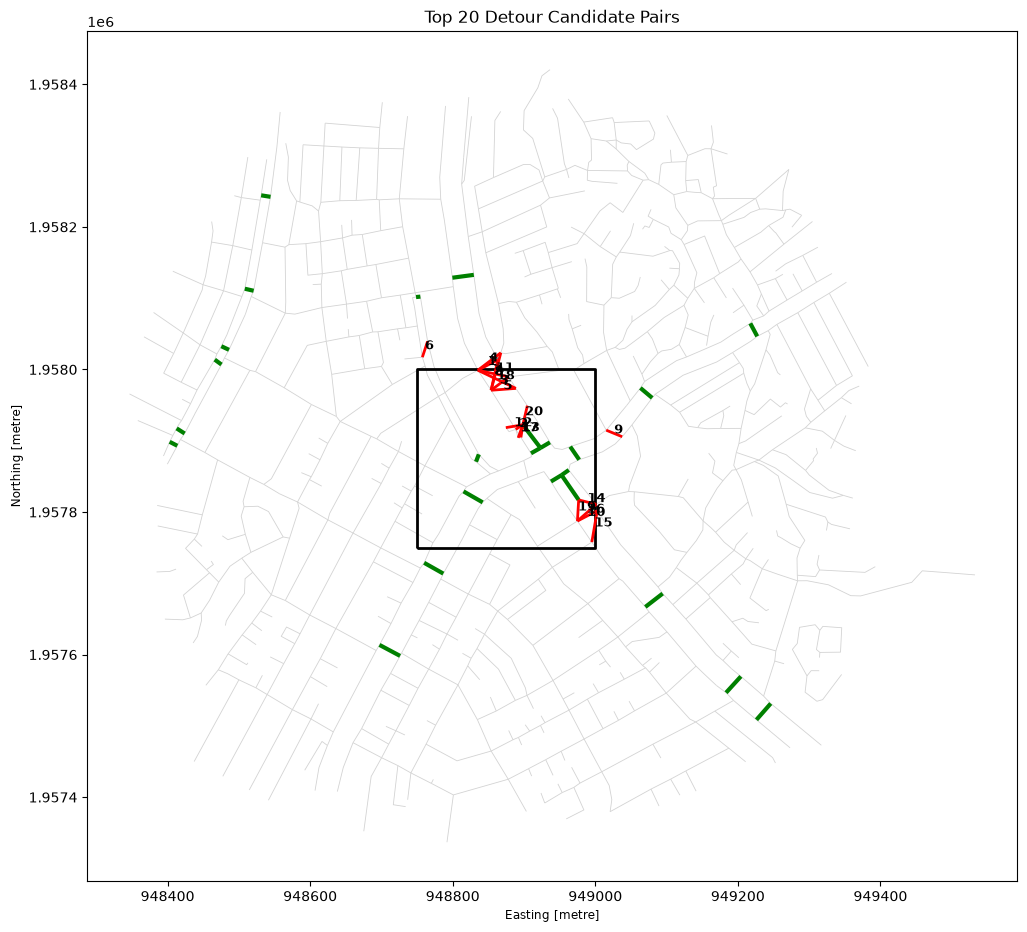

,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율
0,1,78093,214434,31.635901,291.588,259.952099,9.216997
1,2,214856,214027,11.825214,95.962,84.136786,8.115033
2,3,142747,214026,31.115360,243.850,212.734640,7.836965
3,4,214434,142732,40.453003,302.316,261.862997,7.473265
4,5,214026,127633,34.820488,224.993,190.172512,6.461512
5,6,142734,142731,23.491342,146.772,123.280658,6.247919
6,7,214434,142747,44.456214,277.513,233.056786,6.242389
7,8,78093,214026,43.715652,272.368,228.652348,6.230446
8,9,135164,135165,24.189097,147.982,123.792903,6.117715
9,10,99156,142783,31.205319,167.387,136.181681,5.364053


In [176]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from shapely import wkt

# ==========================================
# 우회비율 상위 20쌍 지도 확인
# ==========================================

top20 = (
    detour_pairs
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )
    .head(20)
    .copy()
    .reset_index(drop=True)
)

top20["순위"] = range(1, len(top20) + 1)

# NODE 좌표 lookup
node_geom = (
    node_gdf_full[
        ["노드 ID", "geometry"]
    ]
    .drop_duplicates("노드 ID")
    .set_index("노드 ID")["geometry"]
)

# 후보쌍 직선 생성
pair_lines = []

for _, row in top20.iterrows():

    a = int(row["node_a"])
    b = int(row["node_b"])

    geom_a = node_geom.loc[a]
    geom_b = node_geom.loc[b]

    pair_lines.append(
        LineString([geom_a, geom_b])
    )

top20_gdf = gpd.GeoDataFrame(
    top20,
    geometry=pair_lines,
    crs=demand_df.crs
)


# ==========================================
# 주변 보행망만 추출
# ==========================================

# 후보지역보다 넉넉하게 300m 추가
map_zone = candidate_zone.buffer(300)

local_nodes = node_gdf_full[
    node_gdf_full.geometry.intersects(map_zone)
]

local_node_ids = set(local_nodes["노드 ID"])

local_links = walk_links[
    walk_links["시작노드 ID"].isin(local_node_ids)
    | walk_links["종료노드 ID"].isin(local_node_ids)
].copy()

local_links["geometry"] = local_links["링크 WKT"].apply(
    lambda x: wkt.loads(x) if isinstance(x, str) else x
)

local_links_gdf = gpd.GeoDataFrame(
    local_links,
    geometry="geometry",
    crs="EPSG:4326"
).to_crs(demand_df.crs)

# 공식 횡단보도
local_crosswalks = local_links_gdf[
    local_links_gdf["링크 ID"].isin(official_cw_ids)
].copy()


# ==========================================
# 지도
# ==========================================

fig, ax = plt.subplots(figsize=(12, 12))

# 주변 보행망
local_links_gdf.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.6
)

# 공식 횡단보도
local_crosswalks.plot(
    ax=ax,
    color="green",
    linewidth=3
)

# 1위 격자
target_grid.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2
)

# 후보쌍 직선
top20_gdf.plot(
    ax=ax,
    color="red",
    linewidth=2
)

# 순위 표시
for _, row in top20_gdf.iterrows():
    p = row.geometry.interpolate(0.5, normalized=True)

    ax.text(
        p.x,
        p.y,
        str(row["순위"]),
        fontsize=9,
        fontweight="bold"
    )

ax.set_title("Top 20 Detour Candidate Pairs")
ax.set_aspect("equal")

plt.show()


display(
    top20[
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ]
)

In [177]:
# =========================================================
# 상위 후보쌍이 실제 차량통행 LINK를 가로지르는지 확인
# =========================================================

from shapely import wkt

# 차량 통행 가능한 LINK
vehicle_links = link_rows.copy()

vehicle_links["링크유형코드_4자리"] = (
    pd.to_numeric(
        vehicle_links["링크 유형 코드"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
    .astype(str)
    .str.zfill(4)
)

vehicle_links = vehicle_links[
    vehicle_links["링크유형코드_4자리"].str[1] == "1"
].copy()

vehicle_links["geometry"] = vehicle_links["링크 WKT"].apply(wkt.loads)

vehicle_gdf = gpd.GeoDataFrame(
    vehicle_links,
    geometry="geometry",
    crs="EPSG:4326"
).to_crs(demand_df.crs)

# 현재 1위 격자 주변만
local_vehicle = vehicle_gdf[
    vehicle_gdf.geometry.intersects(map_zone)
].copy()

print("주변 차량통행 LINK:", len(local_vehicle))


# =========================================================
# 각 후보 직선이 차량 LINK와 교차하는 개수 계산
# =========================================================

def count_vehicle_crossings(line):
    # 단순 접촉(touch)까지 너무 많이 잡히는 걸 줄이기 위해
    # 후보 직선 내부와 교차하는 LINK 중심으로 계산
    hits = local_vehicle[
        local_vehicle.geometry.intersects(line)
    ]

    return len(hits)


top20_gdf["차량LINK교차수"] = (
    top20_gdf.geometry.apply(count_vehicle_crossings)
)

display(
    top20_gdf[
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "차량LINK교차수"
        ]
    ]
)

주변 차량통행 LINK: 721


,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,차량LINK교차수
0,1,78093,214434,31.635901,291.588,259.952099,9.216997,3
1,2,214856,214027,11.825214,95.962,84.136786,8.115033,2
2,3,142747,214026,31.115360,243.850,212.734640,7.836965,2
3,4,214434,142732,40.453003,302.316,261.862997,7.473265,4
4,5,214026,127633,34.820488,224.993,190.172512,6.461512,2
5,6,142734,142731,23.491342,146.772,123.280658,6.247919,1
6,7,214434,142747,44.456214,277.513,233.056786,6.242389,2
7,8,78093,214026,43.715652,272.368,228.652348,6.230446,3
8,9,135164,135165,24.189097,147.982,123.792903,6.117715,2
9,10,99156,142783,31.205319,167.387,136.181681,5.364053,2


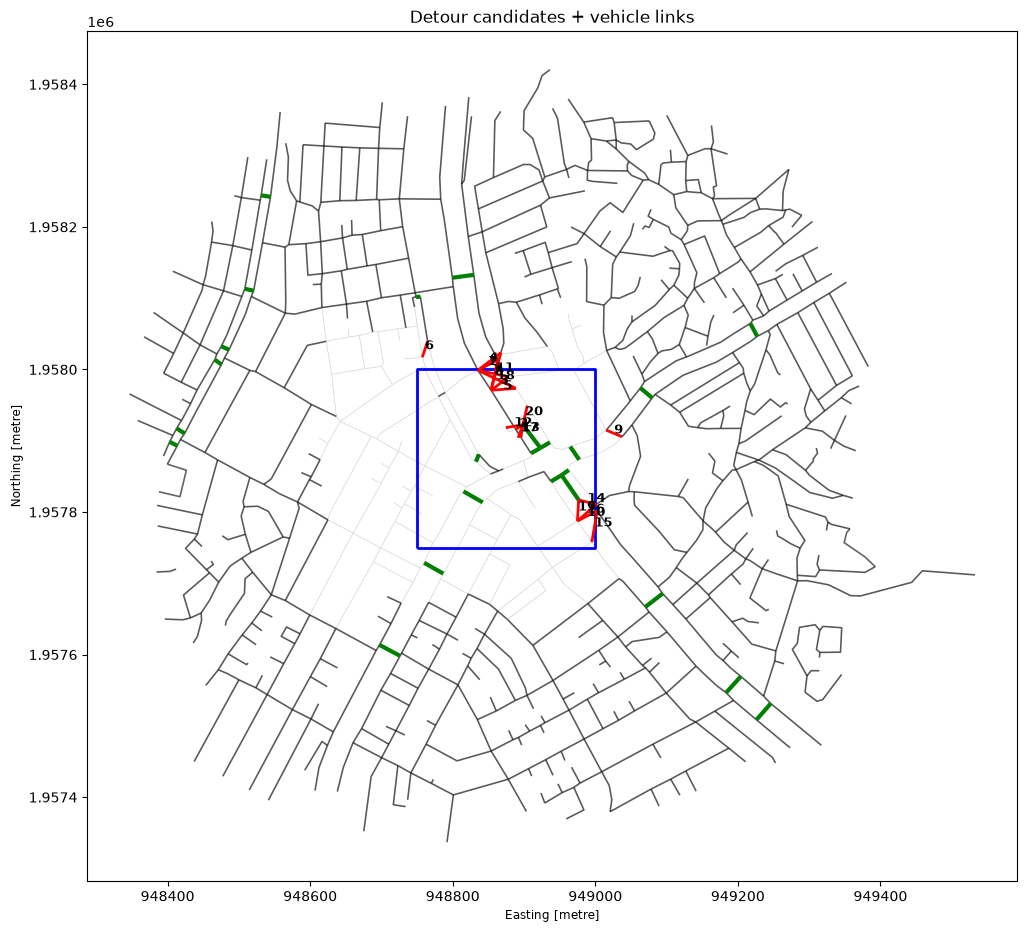

In [178]:
fig, ax = plt.subplots(figsize=(12, 12))

# 전체 보행망
local_links_gdf.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5
)

# 차량 통행 가능 LINK
local_vehicle.plot(
    ax=ax,
    color="black",
    linewidth=1.2,
    alpha=0.6
)

# 공식 횡단보도
local_crosswalks.plot(
    ax=ax,
    color="green",
    linewidth=3
)

# 대상 250m 격자
target_grid.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

# 우회 후보
top20_gdf.plot(
    ax=ax,
    color="red",
    linewidth=2
)

for _, row in top20_gdf.iterrows():
    p = row.geometry.interpolate(0.5, normalized=True)

    ax.text(
        p.x,
        p.y,
        str(row["순위"]),
        fontsize=9,
        fontweight="bold"
    )

ax.set_title("Detour candidates + vehicle links")
ax.set_aspect("equal")

plt.show()

In [179]:
# =========================================================
# 실제 '도로 횡단'에 가까운 교차만 다시 계산
# - 후보선 양 끝 3m 제외
# - 차량 LINK와 내부에서 교차하는 경우만 인정
# =========================================================

from shapely.geometry import LineString

def trim_line(line, trim=3):
    """선 양 끝에서 trim(m)만큼 잘라낸 내부 구간"""
    
    L = line.length

    if L <= trim * 2:
        return None

    p1 = line.interpolate(trim)
    p2 = line.interpolate(L - trim)

    return LineString([p1, p2])


def count_internal_vehicle_crossings(line):

    inner = trim_line(line, trim=3)

    if inner is None:
        return 0

    hits = local_vehicle[
        local_vehicle.geometry.crosses(inner)
    ]

    return len(hits)


top20_gdf["실제차량도로교차수"] = (
    top20_gdf.geometry.apply(
        count_internal_vehicle_crossings
    )
)

display(
    top20_gdf[
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "차량LINK교차수",
            "실제차량도로교차수"
        ]
    ]
)

,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,차량LINK교차수,실제차량도로교차수
0,1,78093,214434,31.635901,291.588,259.952099,9.216997,3,0
1,2,214856,214027,11.825214,95.962,84.136786,8.115033,2,0
2,3,142747,214026,31.115360,243.850,212.734640,7.836965,2,0
3,4,214434,142732,40.453003,302.316,261.862997,7.473265,4,1
4,5,214026,127633,34.820488,224.993,190.172512,6.461512,2,0
5,6,142734,142731,23.491342,146.772,123.280658,6.247919,1,0
6,7,214434,142747,44.456214,277.513,233.056786,6.242389,2,0
7,8,78093,214026,43.715652,272.368,228.652348,6.230446,3,0
8,9,135164,135165,24.189097,147.982,123.792903,6.117715,2,0
9,10,99156,142783,31.205319,167.387,136.181681,5.364053,2,0


In [180]:
top20_gdf["도로횡단후보"] = (
    top20_gdf["실제차량도로교차수"] >= 1
)

print(
    "Top20 중 도로횡단 후보:",
    top20_gdf["도로횡단후보"].sum()
)

display(
    top20_gdf[
        top20_gdf["도로횡단후보"]
    ][
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "실제차량도로교차수"
        ]
    ]
)

Top20 중 도로횡단 후보: 3


,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,실제차량도로교차수
3,4,214434,142732,40.453003,302.316,261.862997,7.473265,1
11,12,214856,211549,24.134995,113.058,88.923005,4.684401,1
16,17,214856,213259,19.376893,86.285,66.908107,4.452984,1


In [181]:
# =========================================================
# 도로횡단 후보 3개의 실제 우회경로 검증
# =========================================================

road_candidates = top20_gdf[
    top20_gdf["실제차량도로교차수"] >= 1
].copy()

validation = []

for _, row in road_candidates.iterrows():

    a = int(row["node_a"])
    b = int(row["node_b"])

    path_nodes = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    path_edges = []

    for u, v in zip(path_nodes[:-1], path_nodes[1:]):

        edge_dict = G.get_edge_data(u, v)

        # 실제 최단경로에서 사용된 최소 length edge
        key, data = min(
            edge_dict.items(),
            key=lambda x: x[1]["length"]
        )

        path_edges.append(data)

    path_length = sum(x["length"] for x in path_edges)

    cw_count = sum(x["is_crosswalk"] for x in path_edges)
    overpass_count = sum(x["is_overpass"] for x in path_edges)
    subway_count = sum(x["is_subway"] for x in path_edges)

    validation.append({
        "순위": int(row["순위"]),
        "node_a": a,
        "node_b": b,
        "직선거리_m": row["직선거리_m"],
        "네트워크거리_m": path_length,
        "우회거리_m": path_length - row["직선거리_m"],
        "우회비율": path_length / row["직선거리_m"],
        "경로내_공식횡단보도LINK": cw_count,
        "경로내_육교LINK": overpass_count,
        "경로내_지하철네트워크LINK": subway_count,
        "경로LINK수": len(path_edges)
    })

validation_df = pd.DataFrame(validation)

display(validation_df)

,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,경로내_공식횡단보도LINK,경로내_육교LINK,경로내_지하철네트워크LINK,경로LINK수
0,4,214434,142732,40.453003,302.316,261.862997,7.473265,1,0,0,5
1,12,214856,211549,24.134995,113.058,88.923005,4.684401,2,0,0,5
2,17,214856,213259,19.376893,86.285,66.908107,4.452984,2,0,1,4


In [182]:
# ==========================================
# 도로횡단 후보의 공간적 중복 제거
# 후보선 중점이 30m 이내면 같은 후보지역으로 묶기
# ==========================================

road_candidates = road_candidates.copy()

# 후보선 중점
road_candidates["midpoint"] = road_candidates.geometry.apply(
    lambda g: g.interpolate(0.5, normalized=True)
)

# 우회비율 높은 순
road_candidates = road_candidates.sort_values(
    ["우회비율", "우회거리_m"],
    ascending=False
).reset_index(drop=True)

selected = []
used = set()

for i, row in road_candidates.iterrows():

    if i in used:
        continue

    # 현재 후보를 대표로 선택
    selected.append(i)

    # 30m 이내 다른 후보는 같은 장소로 간주
    for j, other in road_candidates.iterrows():

        if j <= i or j in used:
            continue

        distance = row["midpoint"].distance(
            other["midpoint"]
        )

        if distance <= 30:
            used.add(j)

representative_candidates = road_candidates.loc[
    selected
].copy()

print("중복 제거 전:", len(road_candidates))
print("중복 제거 후:", len(representative_candidates))

display(
    representative_candidates[
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ]
)

중복 제거 전: 3
중복 제거 후: 2


,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율
0,4,214434,142732,40.453003,302.316,261.862997,7.473265
1,12,214856,211549,24.134995,113.058,88.923005,4.684401


c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51104 (\N{HANGUL SYLLABLE JAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\livinglab\.venv\Lib\

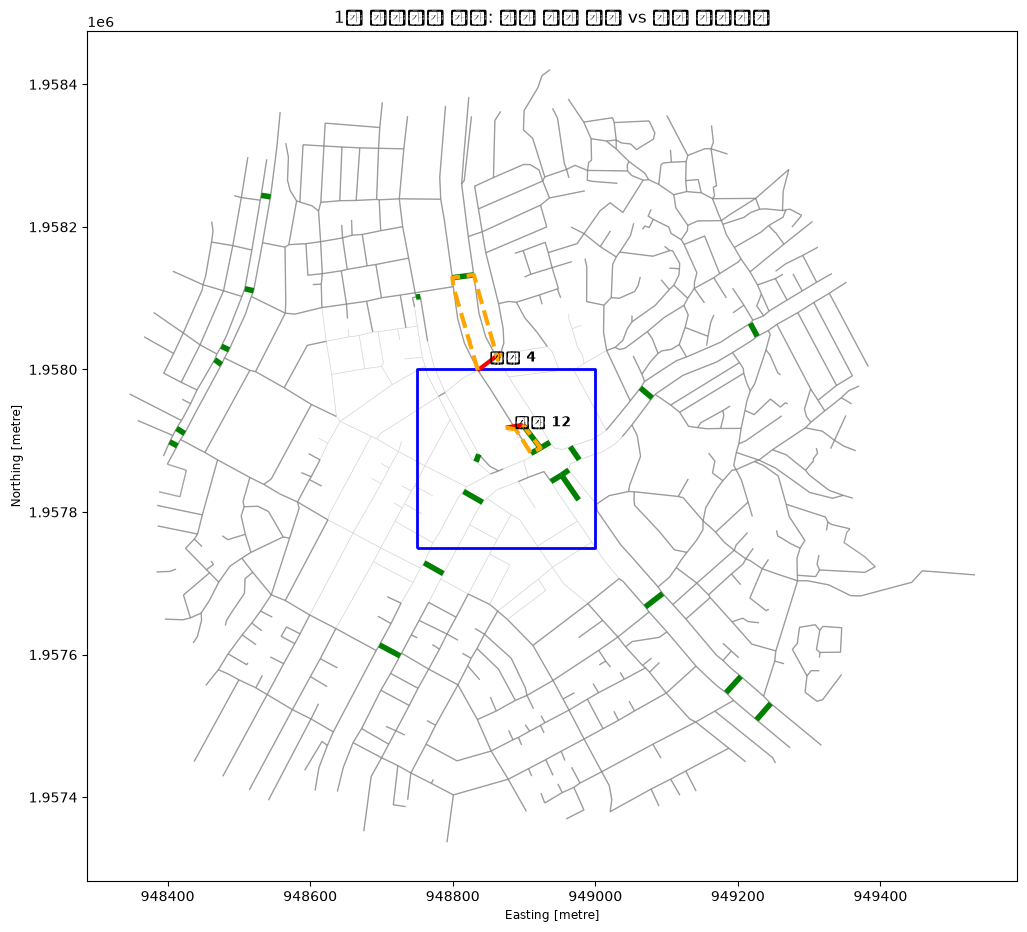

,순위,직선거리_m,네트워크거리_m,우회거리_m,우회비율
0,4,40.453003,302.316,261.862997,7.473265
1,12,24.134995,113.058,88.923005,4.684401


In [183]:
# =========================================================
# 1위 격자 대표 후보 2곳:
# 가상 직선횡단 vs 실제 최단 보행경로 시각화
# =========================================================

from shapely.geometry import LineString
import geopandas as gpd
import matplotlib.pyplot as plt

rep = representative_candidates.copy()

route_geoms = []
route_info = []

for _, row in rep.iterrows():

    a = int(row["node_a"])
    b = int(row["node_b"])

    # 실제 최단경로
    path_nodes = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    # 경로 NODE 좌표를 연결
    coords = [
        (
            G.nodes[n]["x"],
            G.nodes[n]["y"]
        )
        for n in path_nodes
    ]

    # 현재 G 좌표는 경위도(EPSG:4326)
    route_line = LineString(coords)

    route_geoms.append(route_line)

    route_info.append({
        "순위": row["순위"],
        "직선거리_m": row["직선거리_m"],
        "네트워크거리_m": row["네트워크거리_m"],
        "우회거리_m": row["우회거리_m"],
        "우회비율": row["우회비율"]
    })


route_gdf = gpd.GeoDataFrame(
    route_info,
    geometry=route_geoms,
    crs="EPSG:4326"
).to_crs(demand_df.crs)


# =========================================================
# 지도
# =========================================================

fig, ax = plt.subplots(figsize=(12, 12))

# 보행망
local_links_gdf.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5
)

# 차량도로
local_vehicle.plot(
    ax=ax,
    color="gray",
    linewidth=1.0,
    alpha=0.7
)

# 공식 횡단보도
local_crosswalks.plot(
    ax=ax,
    color="green",
    linewidth=4
)

# 250m 대상 격자
target_grid.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

# 가상 직선횡단 후보
rep.plot(
    ax=ax,
    color="red",
    linewidth=3
)

# 현재 실제 최단 보행경로
route_gdf.plot(
    ax=ax,
    color="orange",
    linewidth=3,
    linestyle="--"
)

# 후보 번호 표시
for _, row in rep.iterrows():
    p = row.geometry.interpolate(
        0.5,
        normalized=True
    )

    ax.text(
        p.x,
        p.y,
        f'후보 {int(row["순위"])}',
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "1위 잠재수요 격자: 직선 횡단 후보 vs 현재 보행경로"
)
ax.set_aspect("equal")

plt.show()


display(
    rep[
        [
            "순위",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ]
)

In [184]:
# ==========================================
# 대표 후보를 실제 250m 격자에 귀속
# midpoint가 대상 격자 안에 있는 경우만 인정
# ==========================================

representative_candidates = representative_candidates.copy()

representative_candidates["midpoint"] = (
    representative_candidates.geometry.apply(
        lambda g: g.interpolate(0.5, normalized=True)
    )
)

representative_candidates["대상격자내"] = (
    representative_candidates["midpoint"].apply(
        lambda p: target_geom.covers(p)
    )
)

display(
    representative_candidates[
        [
            "순위",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "대상격자내"
        ]
    ]
)

final_pilot_candidates = representative_candidates[
    representative_candidates["대상격자내"]
].copy()

print(
    "1위 격자 최종 대표 후보:",
    len(final_pilot_candidates)
)

,순위,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,대상격자내
0,4,214434,142732,40.453003,302.316,261.862997,7.473265,False
1,12,214856,211549,24.134995,113.058,88.923005,4.684401,True


1위 격자 최종 대표 후보: 1


In [185]:
import numpy as np
import pandas as pd
import networkx as nx
from shapely.geometry import LineString

def analyze_detour_grid(
    grid_row,
    node_gdf,
    G,
    vehicle_gdf,
    buffer_m=50,
    min_direct=5,
    max_direct=60,
    duplicate_dist=30
):
    """
    250m 격자 1개에 대해 우회부담 후보 탐색
    """

    grid_id = grid_row["250M격자"]
    demand_score = grid_row["잠재횡단수요점수_v2"]
    grid_geom = grid_row.geometry

    # -----------------------------------------
    # 1. 후보 NODE
    # -----------------------------------------
    candidate_zone = grid_geom.buffer(buffer_m)

    nodes = node_gdf[
        node_gdf.geometry.intersects(candidate_zone)
        & node_gdf["노드 ID"].isin(giant_nodes)
    ].copy()

    if len(nodes) < 2:
        return pd.DataFrame()

    coords = np.column_stack([
        nodes.geometry.x.to_numpy(),
        nodes.geometry.y.to_numpy()
    ])

    node_ids_arr = nodes["노드 ID"].to_numpy()

    # -----------------------------------------
    # 2. 직선거리 5~60m NODE쌍
    # -----------------------------------------
    n = len(nodes)

    dx = coords[:, 0][:, None] - coords[:, 0][None, :]
    dy = coords[:, 1][:, None] - coords[:, 1][None, :]

    dist_matrix = np.sqrt(dx**2 + dy**2)

    i_idx, j_idx = np.triu_indices(n, k=1)

    pair_dist = dist_matrix[i_idx, j_idx]

    mask = (
        (pair_dist >= min_direct)
        & (pair_dist <= max_direct)
    )

    if mask.sum() == 0:
        return pd.DataFrame()

    pairs = pd.DataFrame({
        "node_a": node_ids_arr[i_idx[mask]],
        "node_b": node_ids_arr[j_idx[mask]],
        "직선거리_m": pair_dist[mask]
    })

    # -----------------------------------------
    # 3. 네트워크 최단거리
    # -----------------------------------------
    results = []

    for row in pairs.itertuples(index=False):

        a = int(row.node_a)
        b = int(row.node_b)
        direct = float(row.직선거리_m)

        try:
            network_dist = nx.shortest_path_length(
                G,
                source=a,
                target=b,
                weight="length"
            )

        except nx.NetworkXNoPath:
            continue

        results.append({
            "node_a": a,
            "node_b": b,
            "직선거리_m": direct,
            "네트워크거리_m": network_dist,
            "우회거리_m": network_dist - direct,
            "우회비율": network_dist / direct
        })

    result = pd.DataFrame(results)

    if len(result) == 0:
        return result

    # -----------------------------------------
    # 4. 후보 직선 geometry
    # -----------------------------------------
    node_lookup = (
        nodes
        .drop_duplicates("노드 ID")
        .set_index("노드 ID")["geometry"]
    )

    result["geometry"] = result.apply(
        lambda r: LineString([
            node_lookup.loc[r["node_a"]],
            node_lookup.loc[r["node_b"]]
        ]),
        axis=1
    )

    # -----------------------------------------
    # 5. 주변 차량도로
    # -----------------------------------------
    vehicle_zone = candidate_zone.buffer(300)

    local_vehicle = vehicle_gdf[
        vehicle_gdf.geometry.intersects(vehicle_zone)
    ]

    # 후보선 양 끝 3m 제거 후 차량도로 실제 교차 검사
    def internal_cross_count(line):

        if line.length <= 6:
            return 0

        inner = LineString([
            line.interpolate(3),
            line.interpolate(line.length - 3)
        ])

        return local_vehicle.geometry.crosses(inner).sum()

    result["실제차량도로교차수"] = (
        result["geometry"]
        .apply(internal_cross_count)
    )

    # 실제 차량도로를 가로지르는 쌍만
    result = result[
        result["실제차량도로교차수"] >= 1
    ].copy()

    if len(result) == 0:
        return result

    # -----------------------------------------
    # 6. 우회비율 우선 정렬
    # -----------------------------------------
    result = result.sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    ).reset_index(drop=True)

    # -----------------------------------------
    # 7. 공간 중복 제거
    # -----------------------------------------
    result["midpoint"] = result["geometry"].apply(
        lambda g: g.interpolate(0.5, normalized=True)
    )

    selected = []
    used = set()

    for i, row in result.iterrows():

        if i in used:
            continue

        selected.append(i)

        for j, other in result.iterrows():

            if j <= i or j in used:
                continue

            if row["midpoint"].distance(
                other["midpoint"]
            ) <= duplicate_dist:
                used.add(j)

    result = result.loc[selected].copy()

    # -----------------------------------------
    # 8. 후보 중점이 실제 격자 안에 있는 것만 귀속
    # -----------------------------------------
    result = result[
        result["midpoint"].apply(
            lambda p: grid_geom.covers(p)
        )
    ].copy()

    if len(result) == 0:
        return result

    # -----------------------------------------
    # 9. 격자 정보 추가
    # -----------------------------------------
    result["250M격자"] = grid_id
    result["잠재횡단수요점수_v2"] = demand_score

    return result

In [186]:
# =========================================================
# 잠재횡단수요 상위 30개 격자 우회부담 파일럿
# =========================================================

top30_grids = (
    demand_df
    .sort_values(
        "잠재횡단수요점수_v2",
        ascending=False
    )
    .head(30)
    .copy()
)

all_results = []

for idx, (_, grid_row) in enumerate(
    top30_grids.iterrows(),
    start=1
):
    print(
        f"[{idx}/30] {grid_row['250M격자']} "
        f"(수요점수 {grid_row['잠재횡단수요점수_v2']:.2f})",
        end=" → "
    )

    result = analyze_detour_grid(
        grid_row=grid_row,
        node_gdf=node_gdf_full,
        G=G,
        vehicle_gdf=vehicle_gdf,
        buffer_m=50,
        min_direct=5,
        max_direct=60,
        duplicate_dist=30
    )

    print(f"대표 후보 {len(result)}개")

    if len(result) > 0:
        all_results.append(result)


# =========================================================
# 전체 결합
# =========================================================

if len(all_results) > 0:
    top30_detour = pd.concat(
        all_results,
        ignore_index=True
    )
else:
    top30_detour = pd.DataFrame()

print("\n==============================")
print("분석 격자:", len(top30_grids))
print(
    "후보가 나온 격자:",
    top30_detour["250M격자"].nunique()
    if len(top30_detour) > 0
    else 0
)
print(
    "최종 대표 후보 총수:",
    len(top30_detour)
)

[1/30] 다사48755775 (수요점수 99.10) → 대표 후보 5개
[2/30] 다사41255000 (수요점수 98.64) → 대표 후보 19개
[3/30] 다사51504950 (수요점수 98.54) → 대표 후보 19개
[4/30] 다사49504275 (수요점수 98.39) → 대표 후보 15개
[5/30] 다사55755225 (수요점수 98.35) → 대표 후보 20개
[6/30] 다사44754725 (수요점수 97.48) → 대표 후보 11개
[7/30] 다사53755100 (수요점수 97.15) → 대표 후보 20개
[8/30] 다사64754600 (수요점수 96.95) → 대표 후보 6개
[9/30] 다사66754875 (수요점수 96.30) → 대표 후보 20개
[10/30] 다사53254275 (수요점수 96.10) → 대표 후보 24개
[11/30] 다사66504400 (수요점수 95.46) → 대표 후보 17개
[12/30] 다사53755175 (수요점수 95.13) → 대표 후보 18개
[13/30] 다사46754400 (수요점수 95.12) → 대표 후보 14개
[14/30] 다사54255175 (수요점수 94.54) → 대표 후보 18개
[15/30] 다사62004900 (수요점수 94.36) → 대표 후보 16개
[16/30] 다사47254650 (수요점수 94.18) → 대표 후보 9개
[17/30] 다사56505225 (수요점수 94.17) → 대표 후보 11개
[18/30] 다사63005150 (수요점수 93.87) → 대표 후보 31개
[19/30] 다사54005125 (수요점수 93.65) → 대표 후보 10개
[20/30] 다사58505700 (수요점수 93.32) → 대표 후보 30개
[21/30] 다사49754450 (수요점수 93.27) → 대표 후보 26개
[22/30] 다사50005075 (수요점수 93.22) → 대표 후보 24개
[23/30] 다사57505050 (수요점수 93.20) → 대표 후보 16개


In [187]:
# =========================================================
# Top30 결과 요약
# =========================================================

if len(top30_detour) > 0:

    summary = (
        top30_detour
        .groupby(
            ["250M격자", "잠재횡단수요점수_v2"]
        )
        .agg(
            대표후보수=("node_a", "size"),
            최대우회비율=("우회비율", "max"),
            최대우회거리_m=("우회거리_m", "max"),
            최소직선거리_m=("직선거리_m", "min")
        )
        .reset_index()
        .sort_values(
            [
                "최대우회비율",
                "최대우회거리_m"
            ],
            ascending=False
        )
    )

    display(summary)

    print("\n=== 전체 후보 우회부담 기술통계 ===")

    display(
        top30_detour[
            [
                "직선거리_m",
                "네트워크거리_m",
                "우회거리_m",
                "우회비율"
            ]
        ].describe(
            percentiles=[
                .5, .75, .9, .95, .99
            ]
        )
    )

,250M격자,잠재횡단수요점수_v2,대표후보수,최대우회비율,최대우회거리_m,최소직선거리_m
19,다사55755225,98.350396,20,41.544925,1027.642233,13.928261
20,다사56505225,94.169057,11,36.087802,255.775418,7.289582
8,다사49754450,93.265317,26,26.089220,501.830250,11.482061
21,다사57255475,93.124830,26,23.975285,316.949212,6.606386
14,다사53755175,95.130129,18,23.338074,1163.060708,10.413204
24,다사58505700,93.316763,30,17.288671,948.208003,10.856701
3,다사46754400,95.117712,14,15.817815,301.175752,9.517280
28,다사66504400,95.462969,17,13.109089,399.273001,6.423256
16,다사54255175,94.535137,18,11.800979,514.200187,9.810722
25,다사62004900,94.359486,16,11.510765,507.562245,24.624060



=== 전체 후보 우회부담 기술통계 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,534.000000,534.000000,534.000000,534.000000
mean,42.926789,105.431232,62.504443,2.609835
std,13.719843,126.675031,124.524502,3.803551
min,6.423256,6.426000,0.002744,1.000334
50%,46.337616,58.623000,8.731184,1.213138
75%,54.167570,127.555250,76.209358,2.611496
90%,57.938396,228.731500,185.021220,5.223965
95%,59.126830,307.401000,270.315697,8.475202
99%,59.807945,559.841850,512.009666,18.790100
max,59.988706,1215.127000,1163.060708,41.544925


In [188]:
# =========================================================
# Top30 후보 534개:
# 실제 최단경로가 공식 횡단시설을 이용하는지 검증
# =========================================================

validated_rows = []

for i, (_, row) in enumerate(top30_detour.iterrows(), start=1):

    a = int(row["node_a"])
    b = int(row["node_b"])

    try:
        path_nodes = nx.shortest_path(
            G,
            source=a,
            target=b,
            weight="length"
        )

    except nx.NetworkXNoPath:
        continue

    cw_count = 0
    overpass_count = 0
    subway_count = 0
    route_length = 0

    for u, v in zip(path_nodes[:-1], path_nodes[1:]):

        edge_dict = G.get_edge_data(u, v)

        # 최단경로에서 사용되는 가장 짧은 LINK
        _, data = min(
            edge_dict.items(),
            key=lambda x: x[1]["length"]
        )

        route_length += data["length"]

        cw_count += int(data["is_crosswalk"])
        overpass_count += int(data["is_overpass"])
        subway_count += int(data["is_subway"])

    new_row = row.copy()

    new_row["경로내_공식횡단보도LINK"] = cw_count
    new_row["경로내_육교LINK"] = overpass_count
    new_row["경로내_지하철네트워크LINK"] = subway_count

    new_row["합법횡단시설LINK"] = (
        cw_count
        + overpass_count
        + subway_count
    )

    validated_rows.append(new_row)

    if i % 50 == 0:
        print(f"{i}/{len(top30_detour)} 검증 완료")


top30_validated = gpd.GeoDataFrame(
    validated_rows,
    geometry="geometry",
    crs=demand_df.crs
)

print("\n검증 전 후보:", len(top30_validated))

print(
    "횡단시설 이용 후보:",
    (top30_validated["합법횡단시설LINK"] > 0).sum()
)

print(
    "횡단시설 미이용 후보:",
    (top30_validated["합법횡단시설LINK"] == 0).sum()
)

50/534 검증 완료
100/534 검증 완료
150/534 검증 완료
200/534 검증 완료
250/534 검증 완료
300/534 검증 완료
350/534 검증 완료
400/534 검증 완료
450/534 검증 완료
500/534 검증 완료

검증 전 후보: 534
횡단시설 이용 후보: 132
횡단시설 미이용 후보: 402


In [189]:
top30_valid = top30_validated[
    top30_validated["합법횡단시설LINK"] > 0
].copy()

print("최종 검증 통과 후보:", len(top30_valid))

print(
    "후보가 남은 격자:",
    top30_valid["250M격자"].nunique(),
    "/ 30"
)

print("\n=== 검증 후 우회부담 ===")

display(
    top30_valid[
        [
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)

print("\n=== 검증 후 우회비율 상위 30개 ===")

display(
    top30_valid
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "경로내_공식횡단보도LINK",
            "경로내_육교LINK",
            "경로내_지하철네트워크LINK"
        ]
    ]
    .head(30)
)

최종 검증 통과 후보: 132
후보가 남은 격자: 29 / 30

=== 검증 후 우회부담 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,132.000000,132.000000,132.000000,132.000000
mean,47.213500,183.697189,136.483689,4.086819
std,9.926715,175.186579,174.936648,4.537613
min,22.366809,28.864000,0.014428,1.000398
50%,48.865262,129.974500,84.690375,2.774418
75%,55.703387,227.037500,177.079750,4.893032
90%,58.395250,362.238600,317.913038,7.896439
95%,59.450234,480.137850,435.328333,10.692305
99%,59.895912,986.496510,927.129892,16.620996
max,59.988706,1052.988000,1027.642233,41.544925



=== 검증 후 우회비율 상위 30개 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,경로내_공식횡단보도LINK,경로내_육교LINK,경로내_지하철네트워크LINK
58,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,0,0
304,다사58505700,93.316763,75671,28272,59.113997,1007.322,948.208003,17.040330,3,0,0
59,다사55755225,98.350396,212495,138198,59.928902,940.143,880.214098,15.687639,1,0,0
305,다사58505700,93.316763,75671,77825,49.700664,733.620,683.919336,14.760769,2,0,0
208,다사54255175,94.535137,10037,10041,47.606813,561.807,514.200187,11.800979,3,0,0
226,다사62004900,94.359486,212260,17530,48.289755,555.852,507.562245,11.510765,2,0,0
334,다사49754450,93.265317,126452,126403,50.661750,552.492,501.830250,10.905506,1,0,0
242,다사47254650,94.183588,169407,169406,40.021326,420.939,380.917674,10.517867,2,0,0
135,다사53254275,96.104337,138536,119356,26.435915,276.603,250.167085,10.463152,1,0,0
399,다사50254300,93.151094,95564,95601,37.701414,357.030,319.328586,9.469937,1,0,0


In [190]:
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
from shapely.geometry import LineString


def analyze_detour_grid_v3(
    grid_row,
    node_gdf,
    G,
    vehicle_gdf,
    buffer_m=50,
    min_direct=5,
    max_direct=60,
    duplicate_dist=30
):

    grid_id = grid_row["250M격자"]
    demand_score = grid_row["잠재횡단수요점수_v2"]
    grid_geom = grid_row.geometry

    # =====================================================
    # 1. 후보 NODE
    # =====================================================

    candidate_zone = grid_geom.buffer(buffer_m)

    nodes = node_gdf[
        node_gdf.geometry.intersects(candidate_zone)
        & node_gdf["노드 ID"].isin(giant_nodes)
    ].copy()

    if len(nodes) < 2:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    coords = np.column_stack([
        nodes.geometry.x.to_numpy(),
        nodes.geometry.y.to_numpy()
    ])

    node_ids = nodes["노드 ID"].to_numpy()

    # =====================================================
    # 2. 직선거리 5~60m NODE쌍 생성
    # =====================================================

    n = len(nodes)

    dx = coords[:, 0][:, None] - coords[:, 0][None, :]
    dy = coords[:, 1][:, None] - coords[:, 1][None, :]

    dist_matrix = np.sqrt(dx**2 + dy**2)

    i_idx, j_idx = np.triu_indices(n, k=1)
    distances = dist_matrix[i_idx, j_idx]

    mask = (
        (distances >= min_direct)
        & (distances <= max_direct)
    )

    if mask.sum() == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    pairs = pd.DataFrame({
        "node_a": node_ids[i_idx[mask]],
        "node_b": node_ids[j_idx[mask]],
        "직선거리_m": distances[mask]
    })

    node_lookup = (
        nodes
        .drop_duplicates("노드 ID")
        .set_index("노드 ID")["geometry"]
    )

    pairs["geometry"] = pairs.apply(
        lambda r: LineString([
            node_lookup.loc[r["node_a"]],
            node_lookup.loc[r["node_b"]]
        ]),
        axis=1
    )

    pairs = gpd.GeoDataFrame(
        pairs,
        geometry="geometry",
        crs=node_gdf.crs
    )

    # =====================================================
    # 3. midpoint가 실제 250m 격자 안에 있는 쌍만
    # =====================================================

    pairs["midpoint"] = pairs.geometry.apply(
        lambda g: g.interpolate(0.5, normalized=True)
    )

    pairs = pairs[
        pairs["midpoint"].apply(
            lambda p: grid_geom.covers(p)
        )
    ].copy()

    if len(pairs) == 0:
        return pairs

    # =====================================================
    # 4. 실제 차량도로를 가로지르는 쌍만
    # =====================================================

    vehicle_zone = candidate_zone.buffer(300)

    local_vehicle = vehicle_gdf[
        vehicle_gdf.geometry.intersects(vehicle_zone)
    ]

    def vehicle_cross_count(line):

        # 양 끝 3m 제외
        if line.length <= 6:
            return 0

        inner = LineString([
            line.interpolate(3),
            line.interpolate(line.length - 3)
        ])

        return int(
            local_vehicle.geometry.crosses(inner).sum()
        )

    pairs["실제차량도로교차수"] = (
        pairs.geometry.apply(vehicle_cross_count)
    )

    pairs = pairs[
        pairs["실제차량도로교차수"] >= 1
    ].copy()

    if len(pairs) == 0:
        return pairs

    # =====================================================
    # 5. 실제 최단경로 + 횡단시설 이용 검증
    # =====================================================

    validated = []

    for _, row in pairs.iterrows():

        a = int(row["node_a"])
        b = int(row["node_b"])
        direct = float(row["직선거리_m"])

        try:
            path_nodes = nx.shortest_path(
                G,
                source=a,
                target=b,
                weight="length"
            )

        except nx.NetworkXNoPath:
            continue

        route_length = 0
        cw_count = 0
        overpass_count = 0
        subway_count = 0

        for u, v in zip(
            path_nodes[:-1],
            path_nodes[1:]
        ):

            edge_dict = G.get_edge_data(u, v)

            _, data = min(
                edge_dict.items(),
                key=lambda x: x[1]["length"]
            )

            route_length += data["length"]

            cw_count += int(data["is_crosswalk"])
            overpass_count += int(data["is_overpass"])
            subway_count += int(data["is_subway"])

        legal_crossing_count = (
            cw_count
            + overpass_count
            + subway_count
        )

        # 실제 횡단시설을 사용하지 않으면 제외
        if legal_crossing_count == 0:
            continue

        validated.append({
            "node_a": a,
            "node_b": b,

            "직선거리_m": direct,
            "네트워크거리_m": route_length,
            "우회거리_m": route_length - direct,
            "우회비율": route_length / direct,

            "실제차량도로교차수":
                row["실제차량도로교차수"],

            "경로내_공식횡단보도LINK":
                cw_count,

            "경로내_육교LINK":
                overpass_count,

            "경로내_지하철네트워크LINK":
                subway_count,

            "합법횡단시설LINK":
                legal_crossing_count,

            "geometry":
                row.geometry,

            "midpoint":
                row["midpoint"]
        })

    if len(validated) == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    result = gpd.GeoDataFrame(
        validated,
        geometry="geometry",
        crs=node_gdf.crs
    )

    # =====================================================
    # 6. 검증 통과 후보끼리만 공간 중복 제거
    # =====================================================

    result = result.sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    ).reset_index(drop=True)

    selected = []
    used = set()

    for i, row in result.iterrows():

        if i in used:
            continue

        selected.append(i)

        for j, other in result.iterrows():

            if j <= i or j in used:
                continue

            if (
                row["midpoint"].distance(
                    other["midpoint"]
                )
                <= duplicate_dist
            ):
                used.add(j)

    result = result.loc[selected].copy()

    # =====================================================
    # 7. 격자 정보
    # =====================================================

    result["250M격자"] = grid_id
    result["잠재횡단수요점수_v2"] = demand_score

    return result.reset_index(drop=True)

In [191]:
final_results = []

for idx, (_, grid_row) in enumerate(
    top30_grids.iterrows(),
    start=1
):

    result = analyze_detour_grid_v3(
        grid_row=grid_row,
        node_gdf=node_gdf_full,
        G=G,
        vehicle_gdf=vehicle_gdf
    )

    print(
        f"[{idx}/30] "
        f"{grid_row['250M격자']} → "
        f"최종 후보 {len(result)}개"
    )

    if len(result) > 0:
        final_results.append(result)


if final_results:

    top30_final = gpd.GeoDataFrame(
        pd.concat(
            final_results,
            ignore_index=True
        ),
        geometry="geometry",
        crs=demand_df.crs
    )

else:
    top30_final = gpd.GeoDataFrame(
        geometry=[],
        crs=demand_df.crs
    )


print("\n==========================")
print("분석 격자:", 30)

print(
    "후보가 남은 격자:",
    top30_final["250M격자"].nunique()
    if len(top30_final)
    else 0
)

print(
    "최종 대표 후보:",
    len(top30_final)
)

[1/30] 다사48755775 → 최종 후보 3개
[2/30] 다사41255000 → 최종 후보 1개
[3/30] 다사51504950 → 최종 후보 2개
[4/30] 다사49504275 → 최종 후보 9개
[5/30] 다사55755225 → 최종 후보 7개
[6/30] 다사44754725 → 최종 후보 6개
[7/30] 다사53755100 → 최종 후보 7개
[8/30] 다사64754600 → 최종 후보 0개
[9/30] 다사66754875 → 최종 후보 2개
[10/30] 다사53254275 → 최종 후보 7개
[11/30] 다사66504400 → 최종 후보 3개
[12/30] 다사53755175 → 최종 후보 8개
[13/30] 다사46754400 → 최종 후보 2개
[14/30] 다사54255175 → 최종 후보 4개
[15/30] 다사62004900 → 최종 후보 4개
[16/30] 다사47254650 → 최종 후보 6개
[17/30] 다사56505225 → 최종 후보 5개
[18/30] 다사63005150 → 최종 후보 9개
[19/30] 다사54005125 → 최종 후보 4개
[20/30] 다사58505700 → 최종 후보 4개
[21/30] 다사49754450 → 최종 후보 10개
[22/30] 다사50005075 → 최종 후보 4개
[23/30] 다사57505050 → 최종 후보 6개
[24/30] 다사50254300 → 최종 후보 9개
[25/30] 다사57255475 → 최종 후보 9개
[26/30] 다사43504500 → 최종 후보 4개
[27/30] 다사49005100 → 최종 후보 5개
[28/30] 다사58004450 → 최종 후보 1개
[29/30] 다사54505125 → 최종 후보 5개
[30/30] 다사54505300 → 최종 후보 1개

분석 격자: 30
후보가 남은 격자: 29
최종 대표 후보: 147


In [192]:
# ==========================================
# v3 Top30 최종 결과 sanity check
# ==========================================

print("최종 후보:", len(top30_final))
print("후보가 있는 격자:", top30_final["250M격자"].nunique(), "/ 30")

print("\n=== 격자당 후보 수 ===")
grid_counts = (
    top30_final
    .groupby("250M격자")
    .size()
    .describe()
)
display(grid_counts)

print("\n=== 우회부담 분포 ===")
display(
    top30_final[
        [
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)

print("\n=== 우회비율 상위 20개 ===")
display(
    top30_final
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "경로내_공식횡단보도LINK",
            "경로내_육교LINK",
            "경로내_지하철네트워크LINK"
        ]
    ]
    .head(20)
)

최종 후보: 147
후보가 있는 격자: 29 / 30

=== 격자당 후보 수 ===


count    29.000000
mean      5.068966
std       2.685025
min       1.000000
25%       3.000000
50%       5.000000
75%       7.000000
max      10.000000
dtype: float64


=== 우회부담 분포 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,147.000000,147.000000,147.000000,147.000000
mean,47.994894,184.749027,136.754133,4.100212
std,9.643163,168.825409,169.384610,4.418041
min,22.366809,28.864000,0.014428,1.000398
50%,49.585379,130.849000,86.427131,2.840660
75%,56.274483,228.053500,183.046383,4.929756
90%,58.356244,359.806600,317.377579,8.479764
95%,59.464150,430.269300,393.786941,10.789214
99%,59.879948,976.419660,916.930807,16.418092
max,59.988706,1052.988000,1027.642233,41.544925



=== 우회비율 상위 20개 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,경로내_공식횡단보도LINK,경로내_육교LINK,경로내_지하철네트워크LINK
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,0,0
89,다사58505700,93.316763,75671,28272,59.113997,1007.322,948.208003,17.040330,3,0,0
16,다사55755225,98.350396,212495,138198,59.928902,940.143,880.214098,15.687639,1,0,0
90,다사58505700,93.316763,75671,77825,49.700664,733.620,683.919336,14.760769,2,0,0
44,다사66504400,95.462969,96640,93424,34.965659,434.268,399.302341,12.419843,1,0,0
57,다사54255175,94.535137,10037,10041,47.606813,561.807,514.200187,11.800979,3,0,0
61,다사62004900,94.359486,212260,17530,48.289755,555.852,507.562245,11.510765,2,0,0
93,다사49754450,93.265317,126452,126403,50.661750,552.492,501.830250,10.905506,1,0,0
65,다사47254650,94.183588,169407,169406,40.021326,420.939,380.917674,10.517867,2,0,0
37,다사53254275,96.104337,138536,119356,26.435915,276.603,250.167085,10.463152,1,0,0


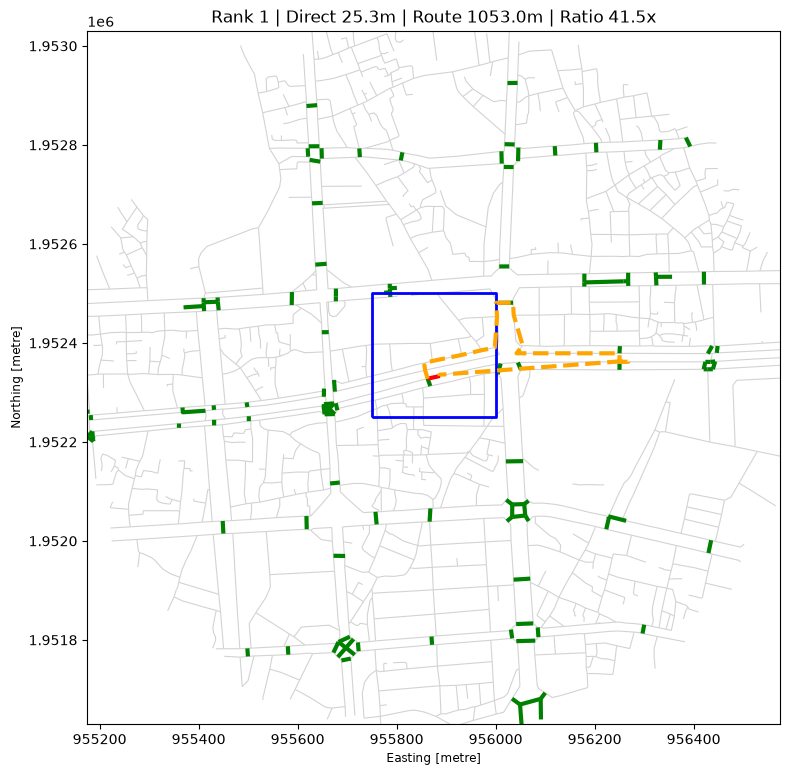

1 다사55755225 직선: 25.3 m / 실제: 1053.0 m / 비율: 41.54


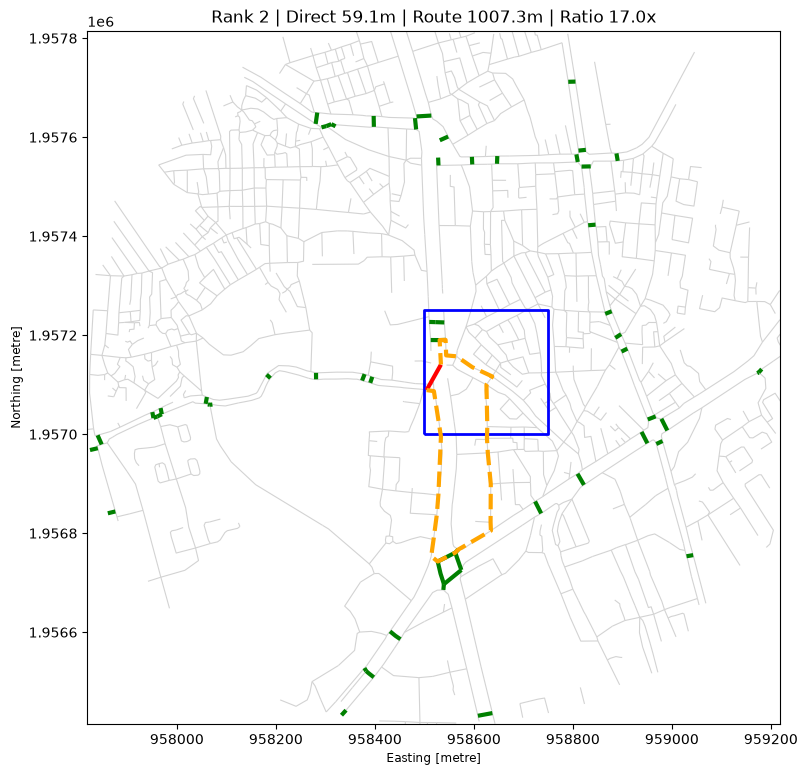

2 다사58505700 직선: 59.1 m / 실제: 1007.3 m / 비율: 17.04


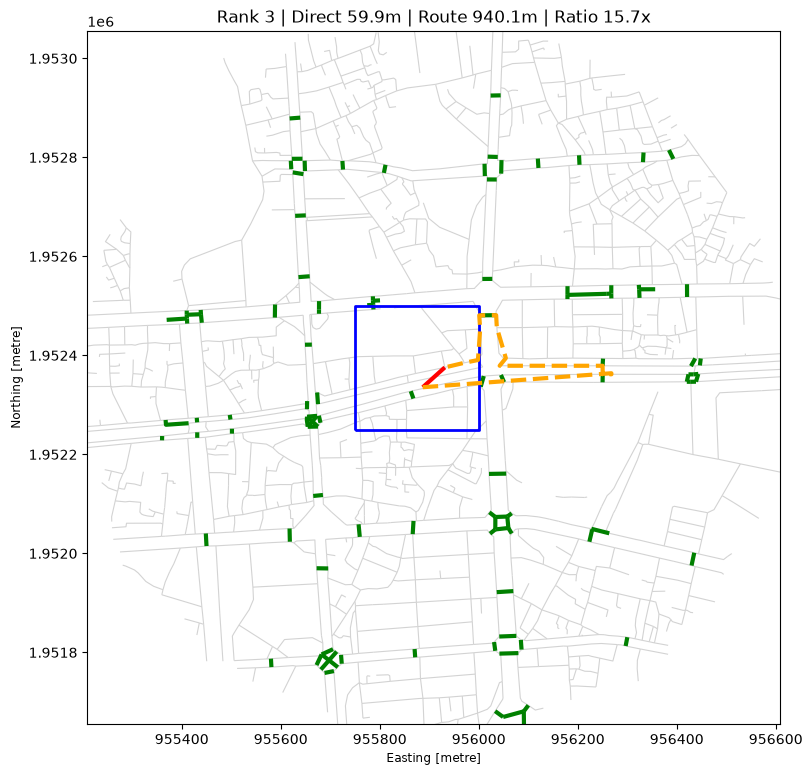

3 다사55755225 직선: 59.9 m / 실제: 940.1 m / 비율: 15.69


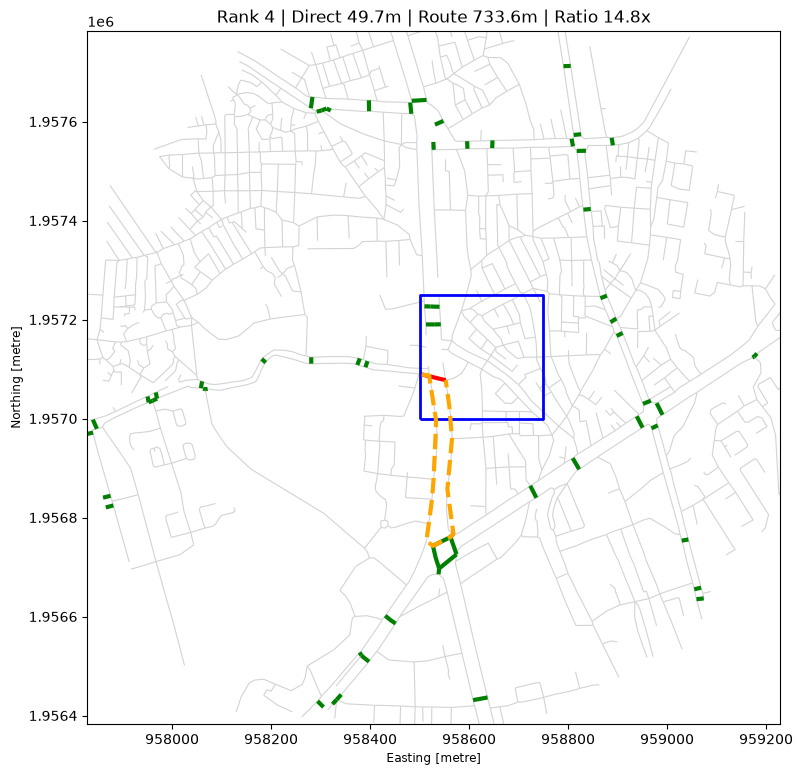

4 다사58505700 직선: 49.7 m / 실제: 733.6 m / 비율: 14.76


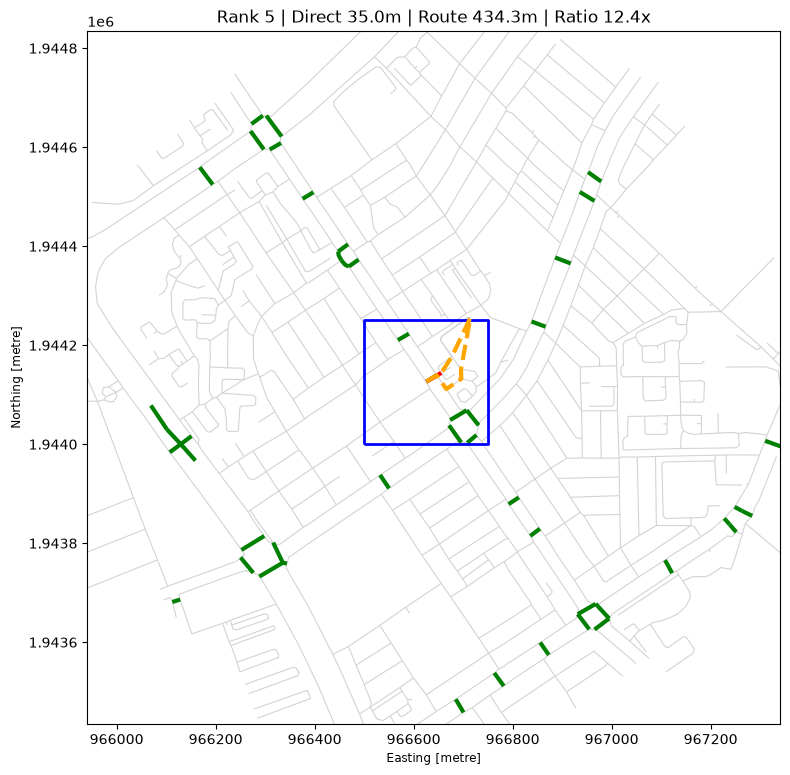

5 다사66504400 직선: 35.0 m / 실제: 434.3 m / 비율: 12.42


In [193]:
# =========================================================
# v3 극단 우회후보 상위 5개 시각 검증
# =========================================================

from shapely.geometry import LineString
import matplotlib.pyplot as plt
import geopandas as gpd

check_top = (
    top30_final
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )
    .head(5)
    .copy()
)

for rank, (_, row) in enumerate(check_top.iterrows(), start=1):

    a = int(row["node_a"])
    b = int(row["node_b"])

    # 실제 최단경로
    path_nodes = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    route_coords = [
        (G.nodes[n]["x"], G.nodes[n]["y"])
        for n in path_nodes
    ]

    route_gdf = gpd.GeoDataFrame(
        {"geometry": [LineString(route_coords)]},
        crs="EPSG:4326"
    ).to_crs(demand_df.crs)

    # 해당 격자
    this_grid = demand_df[
        demand_df["250M격자"] == row["250M격자"]
    ]

    # 후보 주변 지도 범위
    center = row.geometry.interpolate(
        0.5,
        normalized=True
    )

    map_area = center.buffer(700)

    local_vehicle_check = vehicle_gdf[
        vehicle_gdf.geometry.intersects(map_area)
    ]

    # 공식 횡단보도
    local_crosswalk_check = walk_links[
        walk_links["링크 ID"].isin(official_cw_ids)
    ].copy()

    local_crosswalk_check["geometry"] = (
        local_crosswalk_check["링크 WKT"].apply(wkt.loads)
    )

    local_crosswalk_check = gpd.GeoDataFrame(
        local_crosswalk_check,
        geometry="geometry",
        crs="EPSG:4326"
    ).to_crs(demand_df.crs)

    local_crosswalk_check = local_crosswalk_check[
        local_crosswalk_check.geometry.intersects(map_area)
    ]

    # 후보 직선
    candidate_gdf = gpd.GeoDataFrame(
        {"geometry": [row.geometry]},
        crs=demand_df.crs
    )

    # -----------------------------------------
    # 지도
    # -----------------------------------------

    fig, ax = plt.subplots(figsize=(9, 9))

    local_vehicle_check.plot(
        ax=ax,
        color="lightgray",
        linewidth=0.8
    )

    local_crosswalk_check.plot(
        ax=ax,
        color="green",
        linewidth=3
    )

    this_grid.boundary.plot(
        ax=ax,
        color="blue",
        linewidth=2
    )

    candidate_gdf.plot(
        ax=ax,
        color="red",
        linewidth=3
    )

    route_gdf.plot(
        ax=ax,
        color="orange",
        linewidth=3,
        linestyle="--"
    )

    ax.set_xlim(
        map_area.bounds[0],
        map_area.bounds[2]
    )
    ax.set_ylim(
        map_area.bounds[1],
        map_area.bounds[3]
    )

    ax.set_aspect("equal")

    ax.set_title(
        f"Rank {rank} | "
        f"Direct {row['직선거리_m']:.1f}m | "
        f"Route {row['네트워크거리_m']:.1f}m | "
        f"Ratio {row['우회비율']:.1f}x"
    )

    plt.show()

    print(
        rank,
        row["250M격자"],
        "직선:",
        round(row["직선거리_m"], 1),
        "m / 실제:",
        round(row["네트워크거리_m"], 1),
        "m / 비율:",
        round(row["우회비율"], 2)
    )

In [194]:
# =========================================================
# v4 사전 준비
# - 매 격자마다 21만 NODE 전체를 훑지 않도록 spatial index 사용
# - 차량도로 교차 검사도 spatial index 사용
# =========================================================

node_sindex = node_gdf_full.sindex
vehicle_sindex = vehicle_gdf.sindex
giant_nodes_set = set(giant_nodes)

print("NODE:", len(node_gdf_full))
print("차량 LINK:", len(vehicle_gdf))
print("최대 연결요소 NODE:", len(giant_nodes_set))
print("spatial index 준비 완료")

NODE: 214241
차량 LINK: 236776
최대 연결요소 NODE: 212804
spatial index 준비 완료


In [195]:
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx

from shapely.geometry import LineString


def analyze_detour_grid_v4(
    grid_row,
    node_gdf,
    G,
    vehicle_gdf,
    node_sindex,
    vehicle_sindex,
    giant_nodes_set,
    buffer_m=50,
    min_direct=5,
    max_direct=60,
    duplicate_dist=30
):

    grid_id = grid_row["250M격자"]
    demand_score = grid_row["잠재횡단수요점수_v2"]
    grid_geom = grid_row.geometry

    # =====================================================
    # 1. 후보 NODE
    # spatial index로 주변 NODE만 바로 검색
    # =====================================================

    candidate_zone = grid_geom.buffer(buffer_m)

    node_idx = node_sindex.query(
        candidate_zone,
        predicate="intersects"
    )

    nodes = node_gdf.iloc[node_idx].copy()

    nodes = nodes[
        nodes["노드 ID"].isin(giant_nodes_set)
    ].copy()

    if len(nodes) < 2:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    # =====================================================
    # 2. 직선거리 5~60m NODE쌍
    # =====================================================

    coords = np.column_stack([
        nodes.geometry.x.to_numpy(),
        nodes.geometry.y.to_numpy()
    ])

    node_ids = nodes["노드 ID"].to_numpy()

    n = len(nodes)

    dx = coords[:, 0][:, None] - coords[:, 0][None, :]
    dy = coords[:, 1][:, None] - coords[:, 1][None, :]

    dist_matrix = np.sqrt(dx**2 + dy**2)

    i_idx, j_idx = np.triu_indices(n, k=1)

    distances = dist_matrix[i_idx, j_idx]

    mask = (
        (distances >= min_direct)
        & (distances <= max_direct)
    )

    if mask.sum() == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    pairs = pd.DataFrame({
        "node_a": node_ids[i_idx[mask]],
        "node_b": node_ids[j_idx[mask]],
        "직선거리_m": distances[mask]
    })

    node_lookup = (
        nodes
        .drop_duplicates("노드 ID")
        .set_index("노드 ID")["geometry"]
    )

    pairs["geometry"] = pairs.apply(
        lambda r: LineString([
            node_lookup.loc[r["node_a"]],
            node_lookup.loc[r["node_b"]]
        ]),
        axis=1
    )

    pairs = gpd.GeoDataFrame(
        pairs,
        geometry="geometry",
        crs=node_gdf.crs
    )

    # =====================================================
    # 3. midpoint가 실제 격자 내부인 것만 귀속
    # =====================================================

    pairs["midpoint"] = pairs.geometry.apply(
        lambda g: g.interpolate(
            0.5,
            normalized=True
        )
    )

    pairs = pairs[
        pairs["midpoint"].apply(
            lambda p: grid_geom.covers(p)
        )
    ].copy()

    if len(pairs) == 0:
        return pairs

    # =====================================================
    # 4. 실제 차량도로 횡단 여부
    # spatial index 사용
    # =====================================================

    def vehicle_cross_count(line):

        if line.length <= 6:
            return 0

        inner = LineString([
            line.interpolate(3),
            line.interpolate(line.length - 3)
        ])

        hit_idx = vehicle_sindex.query(
            inner,
            predicate="crosses"
        )

        return len(hit_idx)

    pairs["실제차량도로교차수"] = (
        pairs.geometry.apply(
            vehicle_cross_count
        )
    )

    pairs = pairs[
        pairs["실제차량도로교차수"] >= 1
    ].copy()

    if len(pairs) == 0:
        return pairs

    # =====================================================
    # 5. 현재 실제 최단경로 + 횡단시설 사용 검증
    # v3와 동일한 방식 유지
    # =====================================================

    validated = []

    for _, row in pairs.iterrows():

        a = int(row["node_a"])
        b = int(row["node_b"])
        direct = float(row["직선거리_m"])

        try:
            path_nodes = nx.shortest_path(
                G,
                source=a,
                target=b,
                weight="length"
            )

        except nx.NetworkXNoPath:
            continue

        route_length = 0
        cw_count = 0
        overpass_count = 0
        subway_count = 0

        for u, v in zip(
            path_nodes[:-1],
            path_nodes[1:]
        ):

            edge_dict = G.get_edge_data(u, v)

            _, data = min(
                edge_dict.items(),
                key=lambda x: x[1]["length"]
            )

            route_length += data["length"]

            cw_count += int(
                data["is_crosswalk"]
            )

            overpass_count += int(
                data["is_overpass"]
            )

            subway_count += int(
                data["is_subway"]
            )

        legal_crossing_count = (
            cw_count
            + overpass_count
            + subway_count
        )

        if legal_crossing_count == 0:
            continue

        validated.append({
            "node_a": a,
            "node_b": b,

            "직선거리_m": direct,
            "네트워크거리_m": route_length,

            "우회거리_m":
                route_length - direct,

            "우회비율":
                route_length / direct,

            "실제차량도로교차수":
                row["실제차량도로교차수"],

            "경로내_공식횡단보도LINK":
                cw_count,

            "경로내_육교LINK":
                overpass_count,

            "경로내_지하철네트워크LINK":
                subway_count,

            "합법횡단시설LINK":
                legal_crossing_count,

            "geometry":
                row.geometry,

            "midpoint":
                row["midpoint"]
        })

    if len(validated) == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    result = gpd.GeoDataFrame(
        validated,
        geometry="geometry",
        crs=node_gdf.crs
    )

    # =====================================================
    # 6. 검증 통과 후보끼리 공간 중복 제거
    # =====================================================

    result = result.sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    ).reset_index(drop=True)

    selected = []
    used = set()

    for i, row in result.iterrows():

        if i in used:
            continue

        selected.append(i)

        for j, other in result.iterrows():

            if j <= i or j in used:
                continue

            distance = (
                row["midpoint"]
                .distance(other["midpoint"])
            )

            if distance <= duplicate_dist:
                used.add(j)

    result = result.loc[selected].copy()

    # =====================================================
    # 7. 격자 정보
    # =====================================================

    result["250M격자"] = grid_id
    result["잠재횡단수요점수_v2"] = demand_score

    return result.reset_index(drop=True)

In [196]:
# =========================================================
# v4 Top30 검증
# =========================================================

v4_results = []

for idx, (_, grid_row) in enumerate(
    top30_grids.iterrows(),
    start=1
):

    result = analyze_detour_grid_v4(
        grid_row=grid_row,
        node_gdf=node_gdf_full,
        G=G,
        vehicle_gdf=vehicle_gdf,
        node_sindex=node_sindex,
        vehicle_sindex=vehicle_sindex,
        giant_nodes_set=giant_nodes_set
    )

    print(
        f"[{idx}/30] "
        f"{grid_row['250M격자']} → "
        f"{len(result)}개"
    )

    if len(result) > 0:
        v4_results.append(result)


top30_v4 = gpd.GeoDataFrame(
    pd.concat(
        v4_results,
        ignore_index=True
    ),
    geometry="geometry",
    crs=demand_df.crs
)

print("\nV3 후보:", len(top30_final))
print("V4 후보:", len(top30_v4))

[1/30] 다사48755775 → 3개
[2/30] 다사41255000 → 1개
[3/30] 다사51504950 → 2개
[4/30] 다사49504275 → 9개
[5/30] 다사55755225 → 7개
[6/30] 다사44754725 → 6개
[7/30] 다사53755100 → 7개
[8/30] 다사64754600 → 0개
[9/30] 다사66754875 → 2개
[10/30] 다사53254275 → 7개
[11/30] 다사66504400 → 3개
[12/30] 다사53755175 → 8개
[13/30] 다사46754400 → 2개
[14/30] 다사54255175 → 4개
[15/30] 다사62004900 → 4개
[16/30] 다사47254650 → 6개
[17/30] 다사56505225 → 5개
[18/30] 다사63005150 → 9개
[19/30] 다사54005125 → 4개
[20/30] 다사58505700 → 4개
[21/30] 다사49754450 → 10개
[22/30] 다사50005075 → 4개
[23/30] 다사57505050 → 6개
[24/30] 다사50254300 → 9개
[25/30] 다사57255475 → 9개
[26/30] 다사43504500 → 4개
[27/30] 다사49005100 → 5개
[28/30] 다사58004450 → 1개
[29/30] 다사54505125 → 5개
[30/30] 다사54505300 → 1개

V3 후보: 147
V4 후보: 147


In [197]:
# =========================================================
# v3 ↔ v4 후보 동일성 검증
# =========================================================

def make_pair_key(df):

    temp = df.copy()

    temp["node_min"] = temp[
        ["node_a", "node_b"]
    ].min(axis=1)

    temp["node_max"] = temp[
        ["node_a", "node_b"]
    ].max(axis=1)

    return set(
        zip(
            temp["250M격자"],
            temp["node_min"],
            temp["node_max"]
        )
    )


v3_keys = make_pair_key(top30_final)
v4_keys = make_pair_key(top30_v4)

print("V3 후보 KEY:", len(v3_keys))
print("V4 후보 KEY:", len(v4_keys))

print(
    "V3에만 있음:",
    len(v3_keys - v4_keys)
)

print(
    "V4에만 있음:",
    len(v4_keys - v3_keys)
)

print(
    "\n완전히 동일:",
    v3_keys == v4_keys
)

V3 후보 KEY: 147
V4 후보 KEY: 147
V3에만 있음: 0
V4에만 있음: 0

완전히 동일: True


In [198]:
# =========================================================
# 잠재횡단수요 상위 10% = 858개 격자 분석
# Top30 결과 재사용 + 31~858위만 추가 계산
# 50개마다 체크포인트 저장
# =========================================================

import math
import time
from pathlib import Path
import pandas as pd
import geopandas as gpd

# 분석 대상 수
top_n = math.ceil(len(demand_df) * 0.10)

top10pct_grids = (
    demand_df
    .sort_values(
        "잠재횡단수요점수_v2",
        ascending=False
    )
    .head(top_n)
    .copy()
)

print("전체 분석 가능 격자:", len(demand_df))
print("상위 10% 분석 격자:", len(top10pct_grids))

# ---------------------------------------------------------
# 기존 Top30 결과 재사용
# ---------------------------------------------------------

top10_results = [top30_v4.copy()]

processed_grid_ids = set(
    top30_grids["250M격자"]
)

print("기존 Top30 재사용:", len(processed_grid_ids), "격자")

# 체크포인트
checkpoint_path = Path(
    "top10pct_v4_checkpoint.pkl"
)

start_time = time.time()

newly_processed = 0
error_grids = []

# ---------------------------------------------------------
# 31위 ~ 858위
# ---------------------------------------------------------

for rank, (_, grid_row) in enumerate(
    top10pct_grids.iterrows(),
    start=1
):

    grid_id = grid_row["250M격자"]

    # 이미 Top30에서 분석한 격자
    if grid_id in processed_grid_ids:
        continue

    try:

        result = analyze_detour_grid_v4(
            grid_row=grid_row,
            node_gdf=node_gdf_full,
            G=G,
            vehicle_gdf=vehicle_gdf,
            node_sindex=node_sindex,
            vehicle_sindex=vehicle_sindex,
            giant_nodes_set=giant_nodes_set
        )

        newly_processed += 1

        if len(result) > 0:
            top10_results.append(result)

        processed_grid_ids.add(grid_id)

        # 진행 상황: 25개마다
        if newly_processed % 25 == 0:

            elapsed = time.time() - start_time

            current_candidates = sum(
                len(x) for x in top10_results
            )

            print(
                f"[전체 순위 {rank}/{top_n}] "
                f"추가 {newly_processed}개 완료 | "
                f"누적 후보 {current_candidates}개 | "
                f"경과 {elapsed/60:.1f}분"
            )

        # 50개마다 체크포인트
        if newly_processed % 50 == 0:

            checkpoint_df = gpd.GeoDataFrame(
                pd.concat(
                    top10_results,
                    ignore_index=True
                ),
                geometry="geometry",
                crs=demand_df.crs
            )

            checkpoint_df.to_pickle(
                checkpoint_path
            )

            print(
                f"  → 체크포인트 저장: "
                f"{checkpoint_path}"
            )

    except Exception as e:

        error_grids.append({
            "순위": rank,
            "250M격자": grid_id,
            "오류": repr(e)
        })

        print(
            f"[ERROR] {rank}위 "
            f"{grid_id}: {e}"
        )


# =========================================================
# 최종 결합
# =========================================================

top10pct_final = gpd.GeoDataFrame(
    pd.concat(
        top10_results,
        ignore_index=True
    ),
    geometry="geometry",
    crs=demand_df.crs
)

# 최종 저장
top10pct_final.to_pickle(
    "top10pct_v4_final.pkl"
)

elapsed = time.time() - start_time

print("\n================================")
print("분석 대상 격자:", top_n)
print("처리 완료 격자:", len(processed_grid_ids))
print("오류 격자:", len(error_grids))

print(
    "후보가 나온 격자:",
    top10pct_final["250M격자"].nunique()
)

print(
    "최종 대표 후보:",
    len(top10pct_final)
)

print(
    f"추가 분석 소요시간: {elapsed/60:.1f}분"
)

if error_grids:
    display(
        pd.DataFrame(error_grids)
    )

전체 분석 가능 격자: 8576
상위 10% 분석 격자: 858
기존 Top30 재사용: 30 격자
[전체 순위 55/858] 추가 25개 완료 | 누적 후보 237개 | 경과 0.0분
[전체 순위 80/858] 추가 50개 완료 | 누적 후보 315개 | 경과 0.1분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 105/858] 추가 75개 완료 | 누적 후보 453개 | 경과 0.1분
[전체 순위 130/858] 추가 100개 완료 | 누적 후보 553개 | 경과 0.1분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 155/858] 추가 125개 완료 | 누적 후보 680개 | 경과 0.1분
[전체 순위 180/858] 추가 150개 완료 | 누적 후보 779개 | 경과 0.2분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 205/858] 추가 175개 완료 | 누적 후보 904개 | 경과 0.2분
[전체 순위 230/858] 추가 200개 완료 | 누적 후보 997개 | 경과 0.2분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 255/858] 추가 225개 완료 | 누적 후보 1067개 | 경과 0.2분
[전체 순위 280/858] 추가 250개 완료 | 누적 후보 1153개 | 경과 0.3분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 305/858] 추가 275개 완료 | 누적 후보 1282개 | 경과 0.3분
[전체 순위 330/858] 추가 300개 완료 | 누적 후보 1364개 | 경과 0.3분
  → 체크포인트 저장: top10pct_v4_checkpoint.pkl
[전체 순위 355/858] 추가 325개 완료 | 누적 후보 1462개 | 경과 0.3분
[전체 순위 380/858] 추가 350개 완료 | 누적 후보 1577개 | 경과 0.

In [199]:
# =========================================================
# 상위 10% 결과 전체 분포 확인
# =========================================================

print("=== 기본 현황 ===")

print(
    "후보 수:",
    len(top10pct_final)
)

print(
    "후보가 있는 격자:",
    top10pct_final["250M격자"].nunique(),
    "/",
    len(top10pct_grids)
)


print("\n=== 격자당 후보 수 ===")

display(
    top10pct_final
    .groupby("250M격자")
    .size()
    .describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)


print("\n=== 우회부담 분포 ===")

display(
    top10pct_final[
        [
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].describe(
        percentiles=[
            .5,
            .75,
            .9,
            .95,
            .99
        ]
    )
)


print("\n=== 우회비율 상위 30개 ===")

display(
    top10pct_final
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "경로내_공식횡단보도LINK",
            "경로내_육교LINK",
            "경로내_지하철네트워크LINK"
        ]
    ]
    .head(30)
)

=== 기본 현황 ===
후보 수: 3392
후보가 있는 격자: 728 / 858

=== 격자당 후보 수 ===


count    728.000000
mean       4.659341
std        3.022501
min        1.000000
50%        4.000000
75%        6.250000
90%        9.000000
95%       10.000000
99%       13.000000
max       18.000000
dtype: float64


=== 우회부담 분포 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,3392.000000,3392.000000,3392.000000,3392.000000
mean,47.252111,164.812027,117.559916,3.821578
std,10.317423,360.598382,360.877307,9.408951
min,6.198241,6.967000,0.005000,1.000353
50%,49.637232,115.640000,67.579899,2.451542
75%,55.638130,192.396000,144.745177,4.247520
90%,58.402499,286.988100,242.063758,6.632998
95%,59.153929,374.020100,324.090924,8.943860
99%,59.835055,649.867750,597.065672,19.808132
max,59.999057,11567.965000,11526.999822,316.029844



=== 우회비율 상위 30개 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,경로내_공식횡단보도LINK,경로내_육교LINK,경로내_지하철네트워크LINK
2970,다사52005650,60.311745,128242,128051,36.294901,11470.272,11433.977099,316.029844,14,0,0
2971,다사52005650,60.311745,128066,128059,40.965178,11567.965,11526.999822,282.385322,12,0,0
2972,다사52005650,60.311745,128245,128063,45.204123,11412.387,11367.182877,252.463410,12,0,0
2611,다사51005525,62.079052,84211,168170,10.218113,1230.320,1220.101887,120.405793,1,0,0
3334,다사46504375,58.624484,58392,58313,10.349860,707.110,696.760140,68.320733,3,0,0
3391,다사66004450,58.457488,201376,73566,13.406109,794.263,780.856891,59.246347,4,0,0
2527,다사57006250,62.440227,121700,121701,34.732031,1801.869,1767.136969,51.879171,1,0,0
2579,다사57005600,62.222937,18279,195403,7.709660,359.080,351.370340,46.575334,2,0,0
3308,다사46504900,58.838258,58204,58208,6.503193,293.332,286.828807,45.105840,1,0,0
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,0,0


In [200]:
# =========================================================
# 경로 내 '횡단 이벤트' 수 계산
# 연속된 횡단보도/육교/지하통로 LINK는 1회로 계산
# =========================================================

def count_crossing_events(a, b):

    try:
        path_nodes = nx.shortest_path(
            G,
            source=int(a),
            target=int(b),
            weight="length"
        )

    except nx.NetworkXNoPath:
        return np.nan

    crossing_flags = []

    for u, v in zip(
        path_nodes[:-1],
        path_nodes[1:]
    ):

        edge_dict = G.get_edge_data(u, v)

        _, data = min(
            edge_dict.items(),
            key=lambda x: x[1]["length"]
        )

        is_crossing = (
            bool(data["is_crosswalk"])
            or bool(data["is_overpass"])
            or bool(data["is_subway"])
        )

        crossing_flags.append(is_crossing)

    # False -> True로 바뀌는 순간을 하나의 횡단 이벤트로 계산
    events = 0
    prev = False

    for flag in crossing_flags:

        if flag and not prev:
            events += 1

        prev = flag

    return events


top10pct_check = top10pct_final.copy()

top10pct_check["횡단이벤트수"] = [
    count_crossing_events(a, b)
    for a, b in zip(
        top10pct_check["node_a"],
        top10pct_check["node_b"]
    )
]

print("=== 횡단 이벤트 수 분포 ===")

display(
    top10pct_check[
        "횡단이벤트수"
    ].value_counts(
        dropna=False
    ).sort_index()
)


print("\n=== 우회비율 상위 30개 + 횡단이벤트 ===")

display(
    top10pct_check
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "실제차량도로교차수",
            "합법횡단시설LINK",
            "횡단이벤트수"
        ]
    ]
    .head(30)
)

=== 횡단 이벤트 수 분포 ===


횡단이벤트수
1     3191
2      173
3       21
4        4
10       2
12       1
Name: count, dtype: int64


=== 우회비율 상위 30개 + 횡단이벤트 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,실제차량도로교차수,합법횡단시설LINK,횡단이벤트수
2970,다사52005650,60.311745,128242,128051,36.294901,11470.272,11433.977099,316.029844,2,14,12
2971,다사52005650,60.311745,128066,128059,40.965178,11567.965,11526.999822,282.385322,1,12,10
2972,다사52005650,60.311745,128245,128063,45.204123,11412.387,11367.182877,252.463410,1,12,10
2611,다사51005525,62.079052,84211,168170,10.218113,1230.320,1220.101887,120.405793,1,1,1
3334,다사46504375,58.624484,58392,58313,10.349860,707.110,696.760140,68.320733,1,3,2
3391,다사66004450,58.457488,201376,73566,13.406109,794.263,780.856891,59.246347,1,4,2
2527,다사57006250,62.440227,121700,121701,34.732031,1801.869,1767.136969,51.879171,1,1,1
2579,다사57005600,62.222937,18279,195403,7.709660,359.080,351.370340,46.575334,1,2,2
3308,다사46504900,58.838258,58204,58208,6.503193,293.332,286.828807,45.105840,1,1,1
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,1,1


In [201]:
# =========================================================
# '한 번의 횡단'으로 해결되는 후보만 별도 확인
# 아직 삭제 확정 아님
# =========================================================

one_crossing = top10pct_check[
    top10pct_check["횡단이벤트수"] == 1
].copy()

print(
    "전체 후보:",
    len(top10pct_check)
)

print(
    "횡단 1회 후보:",
    len(one_crossing)
)

print(
    "비율:",
    round(
        len(one_crossing)
        / len(top10pct_check)
        * 100,
        1
    ),
    "%"
)

print("\n=== 횡단 1회 후보 우회부담 분포 ===")

display(
    one_crossing[
        [
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].describe(
        percentiles=[
            .5,
            .75,
            .9,
            .95,
            .99
        ]
    )
)

print("\n=== 횡단 1회 후보 우회비율 상위 30개 ===")

display(
    one_crossing
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "실제차량도로교차수",
            "합법횡단시설LINK",
            "횡단이벤트수"
        ]
    ]
    .head(30)
)

전체 후보: 3392
횡단 1회 후보: 3191
비율: 94.1 %

=== 횡단 1회 후보 우회부담 분포 ===


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,3191.000000,3191.000000,3191.000000,3191.000000
mean,47.406268,149.995297,102.589028,3.382523
std,10.028279,124.410567,124.605590,3.854503
min,6.503193,6.967000,0.005000,1.000353
50%,49.672140,112.086000,64.557542,2.369572
75%,55.643533,185.985000,138.384850,4.121655
90%,58.387265,276.684000,229.548330,6.288571
95%,59.167170,356.864500,309.105078,8.304931
99%,59.842390,603.101600,572.012397,15.566369
max,59.999057,1801.869000,1767.136969,120.405793



=== 횡단 1회 후보 우회비율 상위 30개 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,실제차량도로교차수,합법횡단시설LINK,횡단이벤트수
2611,다사51005525,62.079052,84211,168170,10.218113,1230.320,1220.101887,120.405793,1,1,1
2527,다사57006250,62.440227,121700,121701,34.732031,1801.869,1767.136969,51.879171,1,1,1
3308,다사46504900,58.838258,58204,58208,6.503193,293.332,286.828807,45.105840,1,1,1
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,1,1
2252,다사55005200,63.613328,10350,211844,12.021262,465.246,453.224738,38.701928,1,1,1
1998,다사55755675,64.923931,123832,123876,38.524100,1445.384,1406.859900,37.518956,1,1,1
175,다사51504925,89.700799,13887,213946,35.551895,1184.890,1149.338105,33.328463,1,1,1
3335,다사46504375,58.624484,140336,58235,43.532529,1416.451,1372.918471,32.537760,1,1,1
3290,다사51754900,58.911143,13546,213947,31.444921,973.072,941.627079,30.945284,1,1,1
1000,다사52505175,75.276476,77991,77989,9.661759,281.134,271.472241,29.097601,1,1,1


In [203]:
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx

from shapely.geometry import LineString


def analyze_detour_grid_v5(
    grid_row,
    node_gdf,
    G,
    vehicle_gdf,
    node_sindex,
    vehicle_sindex,
    giant_nodes_set,
    buffer_m=50,
    min_direct=5,
    max_direct=60,
    duplicate_dist=30
):

    grid_id = grid_row["250M격자"]
    demand_score = grid_row["잠재횡단수요점수_v2"]
    grid_geom = grid_row.geometry

    # =====================================================
    # 1. 후보 NODE
    # spatial index로 주변 NODE만 바로 검색
    # =====================================================

    candidate_zone = grid_geom.buffer(buffer_m)

    node_idx = node_sindex.query(
        candidate_zone,
        predicate="intersects"
    )

    nodes = node_gdf.iloc[node_idx].copy()

    nodes = nodes[
        nodes["노드 ID"].isin(giant_nodes_set)
    ].copy()

    if len(nodes) < 2:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    # =====================================================
    # 2. 직선거리 5~60m NODE쌍
    # =====================================================

    coords = np.column_stack([
        nodes.geometry.x.to_numpy(),
        nodes.geometry.y.to_numpy()
    ])

    node_ids = nodes["노드 ID"].to_numpy()

    n = len(nodes)

    dx = coords[:, 0][:, None] - coords[:, 0][None, :]
    dy = coords[:, 1][:, None] - coords[:, 1][None, :]

    dist_matrix = np.sqrt(dx**2 + dy**2)

    i_idx, j_idx = np.triu_indices(n, k=1)

    distances = dist_matrix[i_idx, j_idx]

    mask = (
        (distances >= min_direct)
        & (distances <= max_direct)
    )

    if mask.sum() == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    pairs = pd.DataFrame({
        "node_a": node_ids[i_idx[mask]],
        "node_b": node_ids[j_idx[mask]],
        "직선거리_m": distances[mask]
    })

    node_lookup = (
        nodes
        .drop_duplicates("노드 ID")
        .set_index("노드 ID")["geometry"]
    )

    pairs["geometry"] = pairs.apply(
        lambda r: LineString([
            node_lookup.loc[r["node_a"]],
            node_lookup.loc[r["node_b"]]
        ]),
        axis=1
    )

    pairs = gpd.GeoDataFrame(
        pairs,
        geometry="geometry",
        crs=node_gdf.crs
    )

    # =====================================================
    # 3. midpoint가 실제 격자 내부인 것만 귀속
    # =====================================================

    pairs["midpoint"] = pairs.geometry.apply(
        lambda g: g.interpolate(
            0.5,
            normalized=True
        )
    )

    pairs = pairs[
        pairs["midpoint"].apply(
            lambda p: grid_geom.covers(p)
        )
    ].copy()

    if len(pairs) == 0:
        return pairs

    # =====================================================
    # 4. 실제 차량도로 횡단 여부
    # spatial index 사용
    # =====================================================

    def vehicle_cross_count(line):

        if line.length <= 6:
            return 0

        inner = LineString([
            line.interpolate(3),
            line.interpolate(line.length - 3)
        ])

        hit_idx = vehicle_sindex.query(
            inner,
            predicate="crosses"
        )

        return len(hit_idx)

    pairs["실제차량도로교차수"] = (
        pairs.geometry.apply(
            vehicle_cross_count
        )
    )

    pairs = pairs[
        pairs["실제차량도로교차수"] >= 1
    ].copy()

    if len(pairs) == 0:
        return pairs

        # =====================================================
    # 5. 실제 최단경로 + '횡단 1회' 검증
    # =====================================================

    validated = []

    for _, row in pairs.iterrows():

        a = int(row["node_a"])
        b = int(row["node_b"])
        direct = float(row["직선거리_m"])

        try:
            path_nodes = nx.shortest_path(
                G,
                source=a,
                target=b,
                weight="length"
            )

        except nx.NetworkXNoPath:
            continue

        route_length = 0

        cw_count = 0
        overpass_count = 0
        subway_count = 0

        crossing_flags = []

        for u, v in zip(
            path_nodes[:-1],
            path_nodes[1:]
        ):

            edge_dict = G.get_edge_data(u, v)

            _, data = min(
                edge_dict.items(),
                key=lambda x: x[1]["length"]
            )

            route_length += data["length"]

            is_cw = bool(data["is_crosswalk"])
            is_overpass = bool(data["is_overpass"])
            is_subway = bool(data["is_subway"])

            cw_count += int(is_cw)
            overpass_count += int(is_overpass)
            subway_count += int(is_subway)

            crossing_flags.append(
                is_cw
                or is_overpass
                or is_subway
            )

        # 연속된 횡단시설 LINK는 하나의 횡단으로 계산
        crossing_events = 0
        prev = False

        for flag in crossing_flags:

            if flag and not prev:
                crossing_events += 1

            prev = flag

        # 한 번의 횡단으로 해결되는 후보만 유지
        if crossing_events != 1:
            continue

        validated.append({

            "node_a": a,
            "node_b": b,

            "직선거리_m": direct,

            "네트워크거리_m":
                route_length,

            "우회거리_m":
                route_length - direct,

            "우회비율":
                route_length / direct,

            "실제차량도로교차수":
                row["실제차량도로교차수"],

            "경로내_공식횡단보도LINK":
                cw_count,

            "경로내_육교LINK":
                overpass_count,

            "경로내_지하철네트워크LINK":
                subway_count,

            "합법횡단시설LINK":
                cw_count
                + overpass_count
                + subway_count,

            "횡단이벤트수":
                crossing_events,

            "geometry":
                row.geometry,

            "midpoint":
                row["midpoint"]
        })

    if len(validated) == 0:
        return gpd.GeoDataFrame(
            geometry=[],
            crs=node_gdf.crs
        )

    result = gpd.GeoDataFrame(
        validated,
        geometry="geometry",
        crs=node_gdf.crs
    )
    # =====================================================
    # 6. 검증 통과 후보끼리 공간 중복 제거
    # =====================================================

    result = result.sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    ).reset_index(drop=True)

    selected = []
    used = set()

    for i, row in result.iterrows():

        if i in used:
            continue

        selected.append(i)

        for j, other in result.iterrows():

            if j <= i or j in used:
                continue

            distance = (
                row["midpoint"]
                .distance(other["midpoint"])
            )

            if distance <= duplicate_dist:
                used.add(j)

    result = result.loc[selected].copy()

    # =====================================================
    # 7. 격자 정보
    # =====================================================

    result["250M격자"] = grid_id
    result["잠재횡단수요점수_v2"] = demand_score

    return result.reset_index(drop=True)

In [204]:
top10_v5_results = []

for rank, (_, grid_row) in enumerate(
    top10pct_grids.iterrows(),
    start=1
):

    result = analyze_detour_grid_v5(
        grid_row=grid_row,
        node_gdf=node_gdf_full,
        G=G,
        vehicle_gdf=vehicle_gdf,
        node_sindex=node_sindex,
        vehicle_sindex=vehicle_sindex,
        giant_nodes_set=giant_nodes_set
    )

    if len(result) > 0:
        top10_v5_results.append(result)

    if rank % 100 == 0:
        print(
            f"{rank}/{len(top10pct_grids)} 완료"
        )


top10pct_v5 = gpd.GeoDataFrame(
    pd.concat(
        top10_v5_results,
        ignore_index=True
    ),
    geometry="geometry",
    crs=demand_df.crs
)

print("\n=== v5 결과 ===")
print("후보:", len(top10pct_v5))

print(
    "후보가 있는 격자:",
    top10pct_v5["250M격자"].nunique(),
    "/",
    len(top10pct_grids)
)

display(
    top10pct_v5[
        [
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].describe(
        percentiles=[
            .5, .75, .9, .95, .99
        ]
    )
)

100/858 완료
200/858 완료
300/858 완료
400/858 완료
500/858 완료
600/858 완료
700/858 완료
800/858 완료

=== v5 결과 ===
후보: 3314
후보가 있는 격자: 723 / 858


,직선거리_m,네트워크거리_m,우회거리_m,우회비율
count,3314.000000,3314.000000,3314.000000,3314.000000
mean,47.291498,148.953880,101.662381,3.364774
std,10.100957,123.794986,123.932992,3.818513
min,6.503193,6.967000,0.006930,1.000360
50%,49.592246,110.833500,62.814424,2.342952
75%,55.607411,185.271250,137.869976,4.101625
90%,58.369557,276.659700,229.934218,6.317046
95%,59.160668,357.322950,309.925362,8.289419
99%,59.840796,600.337300,560.511246,15.549915
max,59.999057,1801.869000,1767.136969,120.405793


In [205]:
display(
    top10pct_v5
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "실제차량도로교차수",
            "합법횡단시설LINK",
            "횡단이벤트수"
        ]
    ]
    .head(30)
)

,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,실제차량도로교차수,합법횡단시설LINK,횡단이벤트수
2561,다사51005525,62.079052,84211,168170,10.218113,1230.320,1220.101887,120.405793,1,1,1
2478,다사57006250,62.440227,121700,121701,34.732031,1801.869,1767.136969,51.879171,1,1,1
3232,다사46504900,58.838258,58204,58208,6.503193,293.332,286.828807,45.105840,1,1,1
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1,1,1
2208,다사55005200,63.613328,10350,211844,12.021262,465.246,453.224738,38.701928,1,1,1
1958,다사55755675,64.923931,123832,123876,38.524100,1445.384,1406.859900,37.518956,1,1,1
168,다사51504925,89.700799,13887,213946,35.551895,1184.890,1149.338105,33.328463,1,1,1
3257,다사46504375,58.624484,140336,58235,43.532529,1416.451,1372.918471,32.537760,1,1,1
3215,다사51754900,58.911143,13546,213947,31.444921,973.072,941.627079,30.945284,1,1,1
981,다사52505175,75.276476,77991,77989,9.661759,281.134,271.472241,29.097601,1,1,1


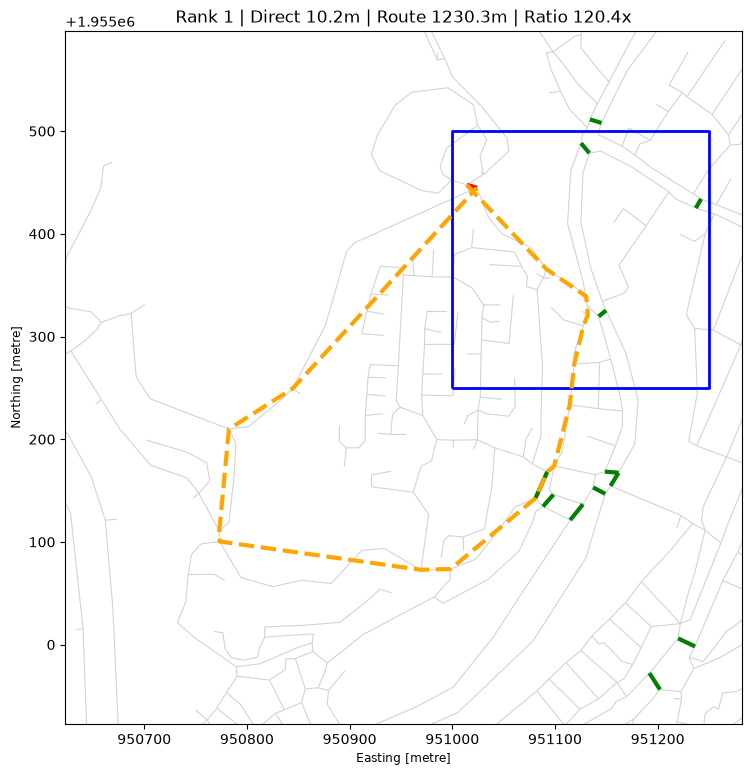

1 다사51005525 | 수요점수: 62.08 | 직선: 10.2 | 실제: 1230.3 | 우회: 1220.1 | 비율: 120.41


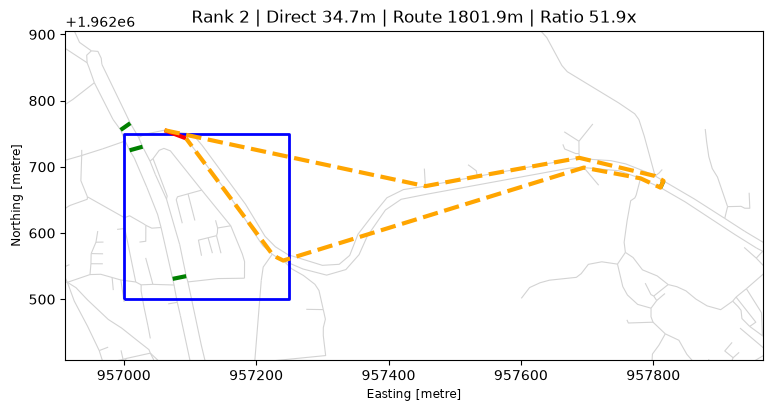

2 다사57006250 | 수요점수: 62.44 | 직선: 34.7 | 실제: 1801.9 | 우회: 1767.1 | 비율: 51.88


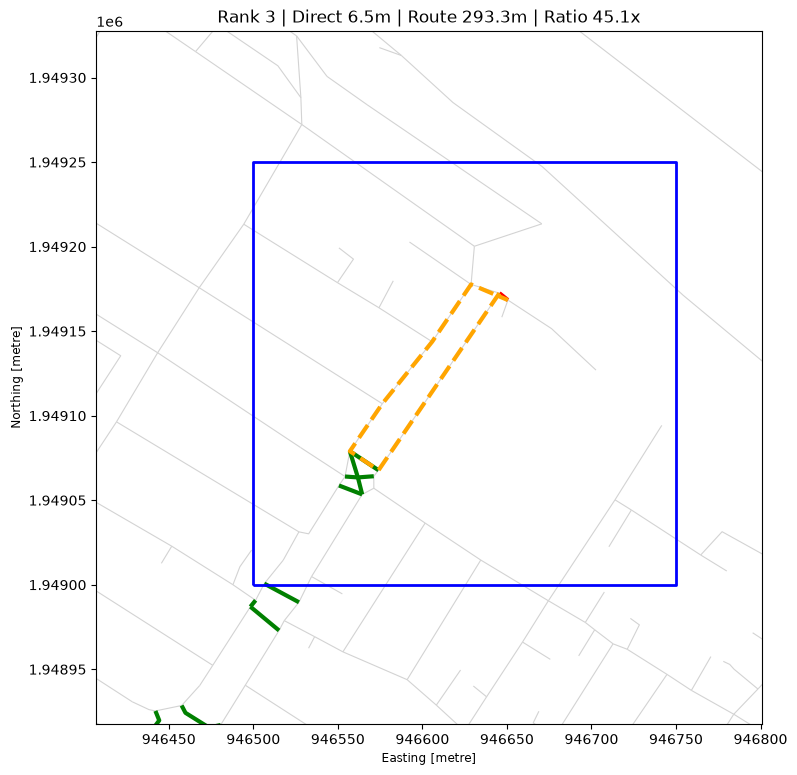

3 다사46504900 | 수요점수: 58.84 | 직선: 6.5 | 실제: 293.3 | 우회: 286.8 | 비율: 45.11


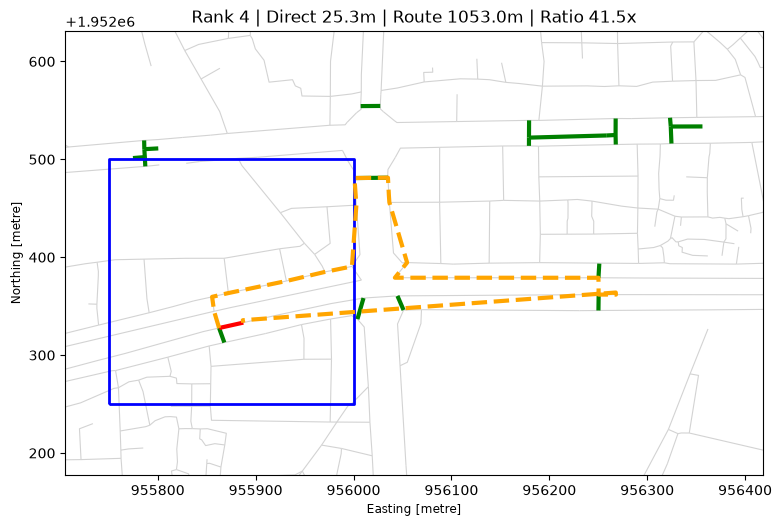

4 다사55755225 | 수요점수: 98.35 | 직선: 25.3 | 실제: 1053.0 | 우회: 1027.6 | 비율: 41.54


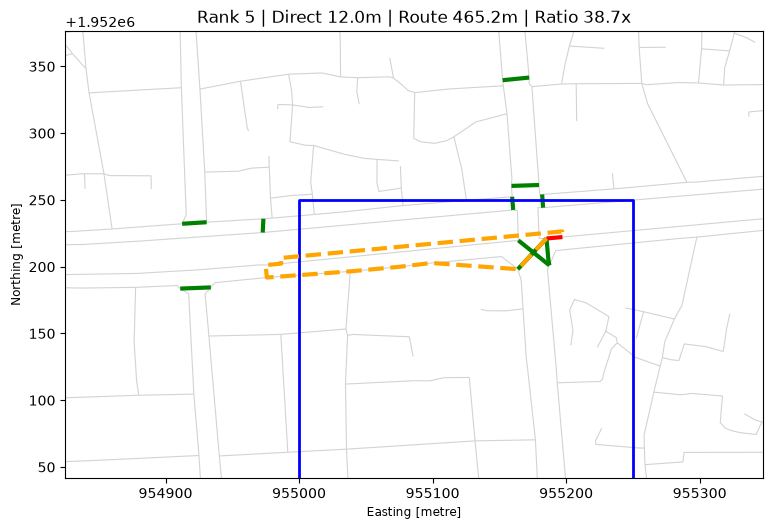

5 다사55005200 | 수요점수: 63.61 | 직선: 12.0 | 실제: 465.2 | 우회: 453.2 | 비율: 38.7


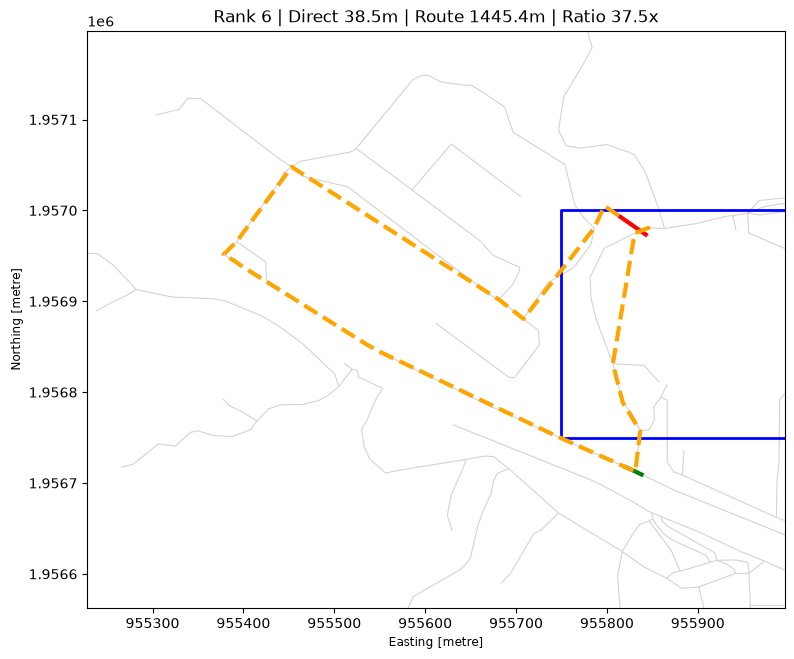

6 다사55755675 | 수요점수: 64.92 | 직선: 38.5 | 실제: 1445.4 | 우회: 1406.9 | 비율: 37.52


In [207]:
# =========================================================
# v5 극단 우회후보 상위 6개 지도 확인
# =========================================================
import shapely

check_v5 = (
    top10pct_v5
    .sort_values(
        ["우회비율", "우회거리_m"],
        ascending=False
    )
    .head(6)
    .copy()
)

for rank, (_, row) in enumerate(check_v5.iterrows(), start=1):

    a = int(row["node_a"])
    b = int(row["node_b"])

    # 실제 최단경로
    path_nodes = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    route_coords = [
        (G.nodes[n]["x"], G.nodes[n]["y"])
        for n in path_nodes
    ]

    route_gdf = gpd.GeoDataFrame(
        {"geometry": [LineString(route_coords)]},
        crs="EPSG:4326"
    ).to_crs(demand_df.crs)

    # 해당 격자
    this_grid = demand_df[
        demand_df["250M격자"] == row["250M격자"]
    ]

    # 후보 직선
    candidate_gdf = gpd.GeoDataFrame(
        {"geometry": [row.geometry]},
        crs=demand_df.crs
    )

    center = row.geometry.interpolate(
        0.5,
        normalized=True
    )

    # 긴 우회경로도 보이도록 범위 자동 확장
    route_bounds = route_gdf.total_bounds

    xmin = min(route_bounds[0], row.geometry.bounds[0]) - 150
    ymin = min(route_bounds[1], row.geometry.bounds[1]) - 150
    xmax = max(route_bounds[2], row.geometry.bounds[2]) + 150
    ymax = max(route_bounds[3], row.geometry.bounds[3]) + 150

    view_box = shapely.geometry.box(
        xmin, ymin, xmax, ymax
    )

    # 주변 차량도로
    local_vehicle = vehicle_gdf[
        vehicle_gdf.geometry.intersects(view_box)
    ]

    # 공식 횡단보도
    local_crosswalk = walk_links[
        walk_links["링크 ID"].isin(official_cw_ids)
    ].copy()

    local_crosswalk["geometry"] = (
        local_crosswalk["링크 WKT"].apply(wkt.loads)
    )

    local_crosswalk = gpd.GeoDataFrame(
        local_crosswalk,
        geometry="geometry",
        crs="EPSG:4326"
    ).to_crs(demand_df.crs)

    local_crosswalk = local_crosswalk[
        local_crosswalk.geometry.intersects(view_box)
    ]

    # -----------------------
    # plot
    # -----------------------

    fig, ax = plt.subplots(figsize=(9, 9))

    local_vehicle.plot(
        ax=ax,
        color="lightgray",
        linewidth=0.8
    )

    local_crosswalk.plot(
        ax=ax,
        color="green",
        linewidth=3
    )

    this_grid.boundary.plot(
        ax=ax,
        color="blue",
        linewidth=2
    )

    candidate_gdf.plot(
        ax=ax,
        color="red",
        linewidth=3
    )

    route_gdf.plot(
        ax=ax,
        color="orange",
        linestyle="--",
        linewidth=3
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")

    ax.set_title(
        f"Rank {rank} | "
        f"Direct {row['직선거리_m']:.1f}m | "
        f"Route {row['네트워크거리_m']:.1f}m | "
        f"Ratio {row['우회비율']:.1f}x"
    )

    plt.show()

    print(
        rank,
        row["250M격자"],
        "| 수요점수:",
        round(row["잠재횡단수요점수_v2"], 2),
        "| 직선:",
        round(row["직선거리_m"], 1),
        "| 실제:",
        round(row["네트워크거리_m"], 1),
        "| 우회:",
        round(row["우회거리_m"], 1),
        "| 비율:",
        round(row["우회비율"], 2)
    )

In [208]:
# =========================================================
# v5 서울 전체 8,576개 격자 분석
# 기존 상위 858개 결과 재사용
# =========================================================

import time
from pathlib import Path
import pandas as pd
import geopandas as gpd

all_v5_results = [
    top10pct_v5.copy()
]

processed_ids = set(
    top10pct_grids["250M격자"]
)

print("전체 격자:", len(demand_df))
print("기존 분석 완료:", len(processed_ids))
print(
    "추가 분석 대상:",
    len(demand_df) - len(processed_ids)
)

start = time.time()

new_count = 0
error_grids = []

checkpoint_path = Path(
    "seoul_all_v5_checkpoint.pkl"
)

for idx, (_, grid_row) in enumerate(
    demand_df.iterrows(),
    start=1
):

    grid_id = grid_row["250M격자"]

    # 상위 10%에서 이미 분석
    if grid_id in processed_ids:
        continue

    try:

        result = analyze_detour_grid_v5(
            grid_row=grid_row,
            node_gdf=node_gdf_full,
            G=G,
            vehicle_gdf=vehicle_gdf,
            node_sindex=node_sindex,
            vehicle_sindex=vehicle_sindex,
            giant_nodes_set=giant_nodes_set
        )

        new_count += 1
        processed_ids.add(grid_id)

        if len(result) > 0:
            all_v5_results.append(result)

        # 진행상황
        if new_count % 250 == 0:

            current_candidates = sum(
                len(x)
                for x in all_v5_results
            )

            elapsed = (
                time.time() - start
            ) / 60

            print(
                f"추가 {new_count}개 완료 | "
                f"전체 {len(processed_ids)}/"
                f"{len(demand_df)} | "
                f"누적 후보 {current_candidates} | "
                f"{elapsed:.1f}분"
            )

        # 체크포인트
        if new_count % 500 == 0:

            checkpoint = gpd.GeoDataFrame(
                pd.concat(
                    all_v5_results,
                    ignore_index=True
                ),
                geometry="geometry",
                crs=demand_df.crs
            )

            checkpoint.to_pickle(
                checkpoint_path
            )

            print(
                "  → 체크포인트 저장"
            )

    except Exception as e:

        error_grids.append({
            "250M격자": grid_id,
            "오류": repr(e)
        })


# =========================================================
# 최종 결합
# =========================================================

seoul_all_v5 = gpd.GeoDataFrame(
    pd.concat(
        all_v5_results,
        ignore_index=True
    ),
    geometry="geometry",
    crs=demand_df.crs
)

seoul_all_v5.to_pickle(
    "seoul_all_v5_final.pkl"
)

elapsed = (
    time.time() - start
) / 60

print("\n==============================")
print("서울 전체 격자:", len(demand_df))
print("처리 완료:", len(processed_ids))
print("오류 격자:", len(error_grids))

print(
    "후보가 나온 격자:",
    seoul_all_v5["250M격자"].nunique()
)

print(
    "총 후보:",
    len(seoul_all_v5)
)

print(
    f"추가 분석 시간: {elapsed:.1f}분"
)

if error_grids:
    display(
        pd.DataFrame(error_grids)
    )

전체 격자: 8576
기존 분석 완료: 858
추가 분석 대상: 7718
추가 250개 완료 | 전체 1108/8576 | 누적 후보 3448 | 0.3분
추가 500개 완료 | 전체 1358/8576 | 누적 후보 3677 | 0.5분
  → 체크포인트 저장
추가 750개 완료 | 전체 1608/8576 | 누적 후보 3964 | 0.7분
추가 1000개 완료 | 전체 1858/8576 | 누적 후보 4259 | 1.0분
  → 체크포인트 저장
추가 1250개 완료 | 전체 2108/8576 | 누적 후보 4624 | 1.2분
추가 1500개 완료 | 전체 2358/8576 | 누적 후보 5051 | 1.4분
  → 체크포인트 저장
추가 1750개 완료 | 전체 2608/8576 | 누적 후보 5479 | 1.6분
추가 2000개 완료 | 전체 2858/8576 | 누적 후보 5892 | 1.8분
  → 체크포인트 저장
추가 2250개 완료 | 전체 3108/8576 | 누적 후보 6295 | 2.0분
추가 2500개 완료 | 전체 3358/8576 | 누적 후보 6625 | 2.2분
  → 체크포인트 저장
추가 2750개 완료 | 전체 3608/8576 | 누적 후보 6858 | 2.4분
추가 3000개 완료 | 전체 3858/8576 | 누적 후보 7069 | 2.6분
  → 체크포인트 저장
추가 3250개 완료 | 전체 4108/8576 | 누적 후보 7335 | 2.9분
추가 3500개 완료 | 전체 4358/8576 | 누적 후보 7569 | 3.0분
  → 체크포인트 저장
추가 3750개 완료 | 전체 4608/8576 | 누적 후보 7833 | 3.3분
추가 4000개 완료 | 전체 4858/8576 | 누적 후보 8090 | 3.5분
  → 체크포인트 저장
추가 4250개 완료 | 전체 5108/8576 | 누적 후보 8427 | 3.7분
추가 4500개 완료 | 전체 5358/8576 | 누적 후보 8893 | 3.9분
  → 체크포인트 저장

### 최종 후보 도출

In [209]:
# =========================================================
# 서울 전체 분포 기반 후보 우선순위 진단
# 아직 최종 threshold 확정 아님
# =========================================================

import numpy as np
import pandas as pd
import geopandas as gpd

priority_df = seoul_all_v5.copy()

# ---------------------------------------------------------
# 1. 잠재수요 percentile
# 8,576개 전체 격자를 기준으로 계산
# ---------------------------------------------------------

demand_rank = demand_df[
    ["250M격자", "잠재횡단수요점수_v2"]
].copy()

demand_rank["잠재수요_pct"] = (
    demand_rank["잠재횡단수요점수_v2"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

demand_pct_map = (
    demand_rank
    .set_index("250M격자")["잠재수요_pct"]
)

priority_df["잠재수요_pct"] = (
    priority_df["250M격자"]
    .map(demand_pct_map)
)


# ---------------------------------------------------------
# 2. 우회거리 / 우회비율 percentile
# 서울 전체 13,615개 후보 기준
# ---------------------------------------------------------

priority_df["우회거리_pct"] = (
    priority_df["우회거리_m"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

priority_df["우회비율_pct"] = (
    priority_df["우회비율"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)


# ---------------------------------------------------------
# 3. 두 우회지표가 모두 높아야 높은 점수
# ---------------------------------------------------------

priority_df["우회부담_pct"] = np.minimum(
    priority_df["우회거리_pct"],
    priority_df["우회비율_pct"]
)

# 잠재수요와 우회부담까지 모두 높아야 최종적으로 높음
priority_df["균형우선순위_pct"] = np.minimum(
    priority_df["잠재수요_pct"],
    priority_df["우회부담_pct"]
)


# ---------------------------------------------------------
# 4. percentile 기준별 후보 수 비교
# ---------------------------------------------------------

rows = []

for q in [70, 75, 80, 85, 90, 95]:

    selected = priority_df[
        (priority_df["잠재수요_pct"] >= q)
        &
        (priority_df["우회거리_pct"] >= q)
        &
        (priority_df["우회비율_pct"] >= q)
    ]

    rows.append({
        "기준": f"상위 {100-q}%",
        "percentile_cut": q,
        "후보수": len(selected),
        "격자수": selected["250M격자"].nunique(),
        "평균_잠재수요점수":
            selected["잠재횡단수요점수_v2"].mean(),
        "평균_우회거리_m":
            selected["우회거리_m"].mean(),
        "평균_우회비율":
            selected["우회비율"].mean()
    })

threshold_compare = pd.DataFrame(rows)

print("=== 기준별 후보 수 ===")
display(threshold_compare)


# ---------------------------------------------------------
# 5. 각 percentile의 실제 원자료 기준값도 확인
# ---------------------------------------------------------

print("\n=== 잠재수요 원점수 기준 ===")

display(
    demand_df["잠재횡단수요점수_v2"]
    .quantile(
        [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
    )
    .to_frame("잠재수요점수")
)


print("\n=== 우회거리 실제 기준(m) ===")

display(
    priority_df["우회거리_m"]
    .quantile(
        [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
    )
    .to_frame("우회거리_m")
)


print("\n=== 우회비율 실제 기준 ===")

display(
    priority_df["우회비율"]
    .quantile(
        [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
    )
    .to_frame("우회비율")
)

=== 기준별 후보 수 ===


,기준,percentile_cut,후보수,격자수,평균_잠재수요점수,평균_우회거리_m,평균_우회비율
0,상위 30%,70,2007,1097,57.558264,264.992887,7.464667
1,상위 25%,75,1359,787,60.147948,289.583213,8.162953
2,상위 20%,80,871,541,62.626864,320.658506,8.955774
3,상위 15%,85,465,308,65.903433,372.714248,10.266716
4,상위 10%,90,184,132,69.898483,457.580293,12.964272
5,상위 5%,95,34,28,79.655569,627.684606,15.651921



=== 잠재수요 원점수 기준 ===


,잠재수요점수
0.70,40.034776
0.75,44.066765
0.80,48.285730
0.85,52.702562
0.90,58.449612
0.95,66.610376



=== 우회거리 실제 기준(m) ===


,우회거리_m
0.70,130.253504
0.75,150.477511
0.80,175.170622
0.85,207.942352
0.90,258.765871
0.95,364.468362



=== 우회비율 실제 기준 ===


,우회비율
0.70,3.872950
0.75,4.343822
0.80,4.923267
0.85,5.762930
0.90,7.132984
0.95,9.841636


In [211]:
# =========================================================
# 1. 상위 10% 기준 후보 확정
# =========================================================

priority90 = priority_df[
    (priority_df["잠재수요_pct"] >= 90)
    &
    (priority_df["우회거리_pct"] >= 90)
    &
    (priority_df["우회비율_pct"] >= 90)
].copy()

print("1차 후보 pair:", len(priority90))
print(
    "포함 격자:",
    priority90["250M격자"].nunique()
)

print("\n실제 최소값")

print(
    "잠재수요:",
    priority90["잠재횡단수요점수_v2"].min()
)

print(
    "우회거리:",
    priority90["우회거리_m"].min()
)

print(
    "우회비율:",
    priority90["우회비율"].min()
)

1차 후보 pair: 184
포함 격자: 132

실제 최소값
잠재수요: 58.510755215474276
우회거리: 260.43004040685054
우회비율: 7.202962818463112


In [212]:
# =========================================================
# 2. 후보 pair → 실제 site 통합 민감도
# 30 / 50 / 75 / 100m 비교
# =========================================================

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

site_test = priority90.copy()

# 후보 직선의 중점
site_test["site_point"] = (
    site_test.geometry.interpolate(
        0.5,
        normalized=True
    )
)

coords = np.column_stack([
    site_test["site_point"].x,
    site_test["site_point"].y
])

rows = []

for eps in [30, 50, 75, 100]:

    labels = DBSCAN(
        eps=eps,
        min_samples=1
    ).fit_predict(coords)

    n_sites = len(
        np.unique(labels)
    )

    counts = (
        pd.Series(labels)
        .value_counts()
    )

    rows.append({
        "통합거리_m": eps,
        "최종_site수": n_sites,
        "site당_pair평균":
            len(site_test) / n_sites,
        "최대_pair수":
            counts.max(),
        "pair1개짜리_site":
            (counts == 1).sum()
    })

display(
    pd.DataFrame(rows)
)

,통합거리_m,최종_site수,site당_pair평균,최대_pair수,pair1개짜리_site
0,30,182,1.010989,2,180
1,50,159,1.157233,4,138
2,75,149,1.234899,4,118
3,100,145,1.268966,4,112


잠재횡단수요 상위 10%이면서,  
우회거리 상위 10%이고,  
우회비율도 상위 10%인 후보를 1차 우선 후보로 선정.

1차 후보 pair: 서울 전체 기준 잠재수요·우회거리·우회비율이 모두 상위 10%인 184개  
후보 site: 후보 pair의 중점이 75m 이내인 경우 동일 후보지로 묶어 149개 site

In [213]:
# =========================================================
# 75m 기준 pair → candidate site 통합
# =========================================================

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd
import geopandas as gpd

site_pairs = priority90.copy()

# 후보 pair의 중점
site_pairs["site_point"] = (
    site_pairs.geometry.interpolate(
        0.5,
        normalized=True
    )
)

coords = np.column_stack([
    site_pairs["site_point"].x,
    site_pairs["site_point"].y
])

# 75m 기준 clustering
labels = DBSCAN(
    eps=75,
    min_samples=1
).fit_predict(coords)

site_pairs["site_id"] = labels + 1

print("pair 수:", len(site_pairs))
print("site 수:", site_pairs["site_id"].nunique())


# =========================================================
# site별 요약
# =========================================================

site_summary = (
    site_pairs
    .groupby("site_id")
    .agg(
        pair수=("site_id", "size"),

        잠재수요점수_max=(
            "잠재횡단수요점수_v2",
            "max"
        ),

        잠재수요_pct_max=(
            "잠재수요_pct",
            "max"
        ),

        우회거리_max_m=(
            "우회거리_m",
            "max"
        ),

        우회거리_median_m=(
            "우회거리_m",
            "median"
        ),

        우회비율_max=(
            "우회비율",
            "max"
        ),

        우회비율_median=(
            "우회비율",
            "median"
        ),

        균형우선순위_max=(
            "균형우선순위_pct",
            "max"
        )
    )
    .reset_index()
)


# site 중심점
site_centers = (
    site_pairs
    .groupby("site_id")["site_point"]
    .apply(
        lambda s:
        gpd.GeoSeries(
            s,
            crs=site_pairs.crs
        ).union_all().centroid
    )
)

site_summary["geometry"] = (
    site_summary["site_id"]
    .map(site_centers)
)

site_summary = gpd.GeoDataFrame(
    site_summary,
    geometry="geometry",
    crs=site_pairs.crs
)

print("\n=== SITE 요약 ===")

display(
    site_summary[
        [
            "site_id",
            "pair수",
            "잠재수요점수_max",
            "우회거리_max_m",
            "우회거리_median_m",
            "우회비율_max",
            "우회비율_median",
            "균형우선순위_max"
        ]
    ]
    .sort_values(
        "균형우선순위_max",
        ascending=False
    )
    .head(30)
)

pair 수: 184
site 수: 149

=== SITE 요약 ===


,site_id,pair수,잠재수요점수_max,우회거리_max_m,우회거리_median_m,우회비율_max,우회비율_median,균형우선순위_max
9,10,2,89.700799,1216.203279,1182.770692,33.328463,29.295518,99.580224
0,1,2,98.350396,1027.642233,953.928165,41.544925,28.616282,99.559310
6,7,1,93.316763,720.935243,720.935243,15.816450,15.816450,98.376790
3,4,2,94.535137,561.071521,537.635854,17.001136,14.401058,98.193169
16,17,1,85.977096,761.481404,761.481404,14.536100,14.536100,97.987514
37,38,1,77.355129,613.482435,613.482435,14.704950,14.704950,97.737873
28,29,1,82.038898,556.761716,556.761716,13.765874,13.765874,97.627617
34,35,2,78.294983,487.094947,407.124837,27.468159,18.550188,97.451340
50,51,1,71.357634,736.751538,736.751538,16.966196,16.966196,96.490205
45,46,1,72.163824,600.316467,600.316467,11.500085,11.500085,96.401028


In [214]:
# =========================================================
# SITE clustering 검증
# 1) cluster 내부 최대 거리 확인
# 2) 각 site의 실제 대표 pair 선정
# =========================================================

import numpy as np
import pandas as pd
import geopandas as gpd


# ---------------------------------------------------------
# 1. site 내부 point 간 최대거리
# ---------------------------------------------------------

def max_pair_distance(points):

    xy = np.array([
        [p.x, p.y]
        for p in points
    ])

    if len(xy) <= 1:
        return 0.0

    diff = (
        xy[:, None, :]
        - xy[None, :, :]
    )

    dist = np.sqrt(
        (diff ** 2).sum(axis=2)
    )

    return dist.max()


site_diameter = (
    site_pairs
    .groupby("site_id")["site_point"]
    .apply(max_pair_distance)
    .rename("site최대폭_m")
    .reset_index()
)

print("=== SITE 최대폭 분포 ===")

display(
    site_diameter["site최대폭_m"]
    .describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)

print("\n75m 초과 site:",
      (site_diameter["site최대폭_m"] > 75).sum())

print("100m 초과 site:",
      (site_diameter["site최대폭_m"] > 100).sum())

print("150m 초과 site:",
      (site_diameter["site최대폭_m"] > 150).sum())


print("\n=== 가장 넓게 묶인 SITE ===")

display(
    site_diameter
    .sort_values(
        "site최대폭_m",
        ascending=False
    )
    .head(20)
)


# ---------------------------------------------------------
# 2. 각 site에서 균형우선순위가 가장 높은 실제 pair
# ---------------------------------------------------------

representative_idx = (
    site_pairs
    .groupby("site_id")[
        "균형우선순위_pct"
    ]
    .idxmax()
)

site_representative = (
    site_pairs
    .loc[representative_idx]
    .copy()
    .reset_index(drop=True)
)


# site pair 수와 최대폭 붙이기

site_counts = (
    site_pairs
    .groupby("site_id")
    .size()
    .rename("pair수")
)

site_representative["pair수"] = (
    site_representative["site_id"]
    .map(site_counts)
)

diameter_map = (
    site_diameter
    .set_index("site_id")["site최대폭_m"]
)

site_representative["site최대폭_m"] = (
    site_representative["site_id"]
    .map(diameter_map)
)


# ---------------------------------------------------------
# 3. 최종 site ranking
# ---------------------------------------------------------

site_representative = (
    site_representative
    .sort_values(
        [
            "균형우선순위_pct",
            "우회거리_m",
            "우회비율"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

site_representative["site순위"] = (
    np.arange(1, len(site_representative) + 1)
)


print("\n=== 대표 SITE 상위 30개 ===")

display(
    site_representative[
        [
            "site순위",
            "site_id",
            "pair수",
            "250M격자",
            "잠재횡단수요점수_v2",
            "잠재수요_pct",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "우회거리_pct",
            "우회비율_pct",
            "균형우선순위_pct",
            "site최대폭_m"
        ]
    ]
    .head(30)
)

=== SITE 최대폭 분포 ===


count    149.000000
mean       9.881282
std       21.148761
min        0.000000
50%        0.000000
75%        0.000000
90%       42.853226
95%       61.675370
99%       69.048020
max      109.212291
Name: site최대폭_m, dtype: float64


75m 초과 site: 1
100m 초과 site: 1
150m 초과 site: 0

=== 가장 넓게 묶인 SITE ===


,site_id,site최대폭_m
60,61,109.212291
34,35,69.325569
91,92,68.747341
95,96,67.129777
70,71,66.574637
85,86,64.523927
3,4,62.814510
140,141,61.945128
40,41,61.270732
26,27,54.067294



=== 대표 SITE 상위 30개 ===


,site순위,site_id,pair수,250M격자,잠재횡단수요점수_v2,잠재수요_pct,직선거리_m,네트워크거리_m,우회거리_m,우회비율,우회거리_pct,우회비율_pct,균형우선순위_pct,site최대폭_m
0,1,10,2,다사51504925,89.700799,99.580224,35.551895,1184.890,1149.338105,33.328463,99.669482,99.742931,99.580224,40.036244
1,2,1,2,다사55755225,98.350396,99.953358,25.345767,1052.988,1027.642233,41.544925,99.559310,99.831069,99.559310,42.417373
2,3,7,1,다사58505700,93.316763,99.778451,48.657757,769.593,720.935243,15.816450,99.081895,98.376790,98.376790,0.000000
3,4,4,2,다사54255150,83.653514,98.775653,35.064479,596.136,561.071521,17.001136,98.193169,98.670584,98.193169,62.814510
4,5,17,1,다사58254425,85.977096,99.160448,56.255596,817.737,761.481404,14.536100,99.228792,97.987514,97.987514,0.000000
5,6,38,1,다사44754525,77.355129,97.737873,44.763565,658.246,613.482435,14.704950,98.589791,98.046272,97.737873,0.000000
6,7,29,1,다사56254525,82.038898,98.519123,43.613284,600.375,556.761716,13.765874,98.163790,97.627617,97.627617,0.000000
7,8,35,2,다사49505200,78.294983,97.971082,18.403053,505.498,487.094947,27.468159,97.451340,99.581344,97.451340,69.325569
8,9,51,1,다사59756425,71.357634,96.490205,46.144462,782.896,736.751538,16.966196,99.147999,98.663239,96.490205,0.000000
9,10,46,1,다사56505700,72.163824,96.700093,57.172533,657.489,600.316467,11.500085,98.545722,96.401028,96.401028,0.000000


In [215]:
# =========================================================
# 상위 20 SITE 위치 확인용 좌표 생성
# EPSG:5179 → WGS84(EPSG:4326)
# =========================================================

import geopandas as gpd
import pandas as pd

top20_sites = (
    site_representative
    .head(20)
    .copy()
)

# 현재 대표 pair geometry의 중점 사용
top20_sites["대표지점"] = (
    top20_sites.geometry.interpolate(
        0.5,
        normalized=True
    )
)

top20_geo = gpd.GeoDataFrame(
    top20_sites.drop(
        columns="geometry"
    ),
    geometry="대표지점",
    crs=site_representative.crs
)

# 위경도로 변환
top20_wgs = top20_geo.to_crs(
    epsg=4326
)

top20_wgs["경도"] = (
    top20_wgs.geometry.x
)

top20_wgs["위도"] = (
    top20_wgs.geometry.y
)

display(
    top20_wgs[
        [
            "site순위",
            "site_id",
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "pair수",
            "site최대폭_m",
            "경도",
            "위도"
        ]
    ]
)

,site순위,site_id,250M격자,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,pair수,site최대폭_m,경도,위도
0,1,10,다사51504925,89.700799,35.551895,1184.890,1149.338105,33.328463,99.580224,2,40.036244,126.953532,37.541696
1,2,1,다사55755225,98.350396,25.345767,1052.988,1027.642233,41.544925,99.559310,2,42.417373,127.000332,37.569286
2,3,7,다사58505700,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,1,0.000000,127.030078,37.612408
3,4,4,다사54255150,83.653514,35.064479,596.136,561.071521,17.001136,98.193169,2,62.814510,126.982166,37.563688
4,5,17,다사58254425,85.977096,56.255596,817.737,761.481404,14.536100,97.987514,1,0.000000,127.028704,37.498260
5,6,38,다사44754525,77.355129,44.763565,658.246,613.482435,14.704950,97.737873,1,0.000000,126.877323,37.506842
6,7,29,다사56254525,82.038898,43.613284,600.375,556.761716,13.765874,97.627617,1,0.000000,127.007770,37.507016
7,8,35,다사49505200,78.294983,18.403053,505.498,487.094947,27.468159,97.451340,2,69.325569,126.930278,37.567255
8,9,51,다사59756425,71.357634,46.144462,782.896,736.751538,16.966196,96.490205,1,0.000000,127.044980,37.678011
9,10,46,다사56505700,72.163824,57.172533,657.489,600.316467,11.500085,96.401028,1,0.000000,127.007175,37.612718


In [216]:
# =========================================================
# 상위 20개 SITE → 자치구 / 행정동 붙이기
# Kakao 좌표→행정구역 API
# =========================================================

import requests
import pandas as pd
import time
import os


# ---------------------------------------------------------
# API KEY 확인
# ---------------------------------------------------------

if "KAKAO_REST_API_KEY" in globals():
    kakao_key = KAKAO_REST_API_KEY
else:
    kakao_key = os.getenv("KAKAO_REST_API_KEY")

if not kakao_key:
    raise ValueError(
        "KAKAO_REST_API_KEY가 설정되어 있지 않아. "
        "전에 사용한 REST API 키를 먼저 넣어줘."
    )

headers = {
    "Authorization": f"KakaoAK {kakao_key}"
}


# ---------------------------------------------------------
# 역지오코딩 함수
# ---------------------------------------------------------

def kakao_region(lon, lat):

    url = (
        "https://dapi.kakao.com/"
        "v2/local/geo/coord2regioncode.json"
    )

    params = {
        "x": lon,
        "y": lat
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    r.raise_for_status()

    docs = r.json().get("documents", [])

    # 행정동(H) 우선
    h = next(
        (
            d for d in docs
            if d.get("region_type") == "H"
        ),
        None
    )

    # 법정동(B) 보조
    b = next(
        (
            d for d in docs
            if d.get("region_type") == "B"
        ),
        None
    )

    result = h if h is not None else b

    if result is None:
        return pd.Series(
            [None, None, None, None]
        )

    return pd.Series([
        result.get("region_1depth_name"),
        result.get("region_2depth_name"),
        result.get("region_3depth_name"),
        result.get("address_name")
    ])


# ---------------------------------------------------------
# 상위 20개에 적용
# ---------------------------------------------------------

region_rows = []

for _, row in top20_wgs.iterrows():

    region = kakao_region(
        row["경도"],
        row["위도"]
    )

    region_rows.append(region)

    time.sleep(0.05)


region_df = pd.DataFrame(
    region_rows,
    columns=[
        "시도",
        "자치구",
        "행정동",
        "행정구역"
    ],
    index=top20_wgs.index
)

top20_final = pd.concat(
    [
        top20_wgs,
        region_df
    ],
    axis=1
)


# ---------------------------------------------------------
# 보기 좋은 표
# ---------------------------------------------------------

display(
    top20_final[
        [
            "site순위",
            "site_id",
            "250M격자",
            "자치구",
            "행정동",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "경도",
            "위도"
        ]
    ]
)

,site순위,site_id,250M격자,자치구,행정동,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,경도,위도
0,1,10,다사51504925,NaN,NaN,89.700799,35.551895,1184.890,1149.338105,33.328463,99.580224,126.953532,37.541696
1,2,1,다사55755225,NaN,NaN,98.350396,25.345767,1052.988,1027.642233,41.544925,99.559310,127.000332,37.569286
2,3,7,다사58505700,NaN,NaN,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,127.030078,37.612408
3,4,4,다사54255150,NaN,NaN,83.653514,35.064479,596.136,561.071521,17.001136,98.193169,126.982166,37.563688
4,5,17,다사58254425,NaN,NaN,85.977096,56.255596,817.737,761.481404,14.536100,97.987514,127.028704,37.498260
5,6,38,다사44754525,NaN,NaN,77.355129,44.763565,658.246,613.482435,14.704950,97.737873,126.877323,37.506842
6,7,29,다사56254525,NaN,NaN,82.038898,43.613284,600.375,556.761716,13.765874,97.627617,127.007770,37.507016
7,8,35,다사49505200,NaN,NaN,78.294983,18.403053,505.498,487.094947,27.468159,97.451340,126.930278,37.567255
8,9,51,다사59756425,NaN,NaN,71.357634,46.144462,782.896,736.751538,16.966196,96.490205,127.044980,37.678011
9,10,46,다사56505700,NaN,NaN,72.163824,57.172533,657.489,600.316467,11.500085,96.401028,127.007175,37.612718


In [217]:
# =========================================================
# NaN 수정 — API 재호출 필요 없음
# =========================================================

region_df = pd.DataFrame(
    [x.tolist() for x in region_rows],
    columns=[
        "시도",
        "자치구",
        "행정동",
        "행정구역"
    ],
    index=top20_wgs.index
)

top20_final = pd.concat(
    [
        top20_wgs,
        region_df
    ],
    axis=1
)

display(
    top20_final[
        [
            "site순위",
            "site_id",
            "250M격자",
            "자치구",
            "행정동",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "경도",
            "위도"
        ]
    ]
)

,site순위,site_id,250M격자,자치구,행정동,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,경도,위도
0,1,10,다사51504925,마포구,도화동,89.700799,35.551895,1184.890,1149.338105,33.328463,99.580224,126.953532,37.541696
1,2,1,다사55755225,중구,을지로동,98.350396,25.345767,1052.988,1027.642233,41.544925,99.559310,127.000332,37.569286
2,3,7,다사58505700,강북구,송천동,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,127.030078,37.612408
3,4,4,다사54255150,중구,명동,83.653514,35.064479,596.136,561.071521,17.001136,98.193169,126.982166,37.563688
4,5,17,다사58254425,강남구,역삼1동,85.977096,56.255596,817.737,761.481404,14.536100,97.987514,127.028704,37.498260
5,6,38,다사44754525,구로구,신도림동,77.355129,44.763565,658.246,613.482435,14.704950,97.737873,126.877323,37.506842
6,7,29,다사56254525,서초구,반포4동,82.038898,43.613284,600.375,556.761716,13.765874,97.627617,127.007770,37.507016
7,8,35,다사49505200,서대문구,연희동,78.294983,18.403053,505.498,487.094947,27.468159,97.451340,126.930278,37.567255
8,9,51,다사59756425,도봉구,도봉1동,71.357634,46.144462,782.896,736.751538,16.966196,96.490205,127.044980,37.678011
9,10,46,다사56505700,성북구,정릉4동,72.163824,57.172533,657.489,600.316467,11.500085,96.401028,127.007175,37.612718


In [ ]:
# =========================================================
# 상위 20 SITE 인터랙티브 지도
# =========================================================

import folium
from folium.plugins import MarkerCluster

# 서울 중심
m = folium.Map(
    location=[37.55, 126.99],
    zoom_start=11
)

cluster = MarkerCluster().add_to(m)

for _, row in top20_final.iterrows():

    popup_html = f"""
    <b>순위:</b> {int(row['site순위'])}<br>
    <b>지역:</b> {row['자치구']} {row['행정동']}<br>
    <b>격자:</b> {row['250M격자']}<br>
    <b>잠재수요:</b> {row['잠재횡단수요점수_v2']:.2f}<br>
    <b>직선거리:</b> {row['직선거리_m']:.1f} m<br>
    <b>실제경로:</b> {row['네트워크거리_m']:.1f} m<br>
    <b>우회거리:</b> {row['우회거리_m']:.1f} m<br>
    <b>우회비율:</b> {row['우회비율']:.2f} 배<br>
    <b>균형순위:</b> {row['균형우선순위_pct']:.2f}
    """

    folium.Marker(
        location=[
            row["위도"],
            row["경도"]
        ],
        popup=folium.Popup(
            popup_html,
            max_width=300
        ),
        tooltip=(
            f"{int(row['site순위'])}위 "
            f"{row['자치구']} {row['행정동']}"
        )
    ).add_to(cluster)


from pathlib import Path

# outputs 폴더 자동 생성
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

map_path = output_dir / "top20_candidate_sites.html"

m.save(str(map_path))

print("저장 완료:", map_path)

m

저장 완료: ..\outputs\top20_candidate_sites.html


In [220]:
import pandas as pd
import geopandas as gpd

print("=== 1. pair 후보 데이터프레임 ===")

pair_candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, (pd.DataFrame, gpd.GeoDataFrame)):
        cols = set(obj.columns)

        # 우리가 필요한 pair 구조
        if {"node_a", "node_b"}.issubset(cols):
            pair_candidates.append(
                {
                    "변수명": name,
                    "행수": len(obj),
                    "geometry": "geometry" in cols,
                    "250M격자": "250M격자" in cols,
                    "우회거리": "우회거리_m" in cols,
                    "우회비율": "우회비율" in cols,
                }
            )

display(pd.DataFrame(pair_candidates).sort_values("행수"))


print("\n=== 2. 차량도로/LINK GeoDataFrame 후보 ===")

link_candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, gpd.GeoDataFrame):
        cols = set(obj.columns)

        if (
            "링크 ID" in cols
            or "LINK_ID" in cols
            or "링크 유형 코드" in cols
            or "링크유형코드_4자리" in cols
        ):
            link_candidates.append(
                {
                    "변수명": name,
                    "행수": len(obj),
                    "CRS": str(obj.crs),
                    "링크ID": (
                        "링크 ID" in cols
                        or "LINK_ID" in cols
                    ),
                    "링크유형": (
                        "링크 유형 코드" in cols
                        or "링크유형코드_4자리" in cols
                    ),
                }
            )

display(pd.DataFrame(link_candidates).sort_values("행수"))


print("\n=== 3. NODE GeoDataFrame 후보 ===")

node_candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, gpd.GeoDataFrame):
        cols = set(obj.columns)

        if (
            "노드 ID" in cols
            or "NODE_ID" in cols
            or "node_id" in cols
        ):
            node_candidates.append(
                {
                    "변수명": name,
                    "행수": len(obj),
                    "CRS": str(obj.crs),
                    "geometry": "geometry" in cols,
                }
            )

display(pd.DataFrame(node_candidates).sort_values("행수"))

=== 1. pair 후보 데이터프레임 ===


,변수명,행수,geometry,250M격자,우회거리,우회비율
3,weird,0,False,False,True,True
11,final_pilot_candidates,1,True,False,True,True
9,representative_candidates,2,True,False,True,True
10,rep,2,True,False,True,True
6,road_candidates,3,True,False,True,True
0,result,3,True,True,True,True
7,validation_df,3,False,False,True,True
16,check_top,5,True,True,True,True
23,check_v5,6,True,True,True,True
31,top20_sites,20,True,True,True,True



=== 2. 차량도로/LINK GeoDataFrame 후보 ===


,변수명,행수,CRS,링크ID,링크유형
2,sample_cross,0,EPSG:4326,True,True
11,local_crosswalk,2,EPSG:5179,True,True
6,local_crosswalks,24,EPSG:5179,True,True
10,local_crosswalk_check,47,EPSG:5179,True,True
0,subway_exit_gdf,57,EPSG:4326,True,True
4,cross_gdf,61,EPSG:4326,True,True
8,local_vehicle,103,EPSG:5179,True,True
3,sample_gdf,151,EPSG:4326,True,True
9,local_vehicle_check,838,EPSG:5179,True,True
5,local_links_gdf,872,EPSG:5179,True,True



=== 3. NODE GeoDataFrame 후보 ===


,변수명,행수,CRS,geometry
4,sample_cross,0,EPSG:4326,True
18,local_crosswalk,2,EPSG:5179,True
13,local_crosswalks,24,EPSG:5179,True
17,local_crosswalk_check,47,EPSG:5179,True
0,subway_exit_gdf,57,EPSG:4326,True
6,cross_gdf,61,EPSG:4326,True
10,candidate_nodes,90,EPSG:5179,True
15,local_vehicle,103,EPSG:5179,True
5,sample_gdf,151,EPSG:4326,True
11,local_nodes,624,EPSG:5179,True


In [222]:
# 결과 확인

print("전체 pair:", len(pairs_roadcheck))
print(
    "차량도로 가로지름:",
    int(pairs_roadcheck["차량도로가로지름"].sum())
)
print(
    "차량도로 없음:",
    int((~pairs_roadcheck["차량도로가로지름"]).sum())
)

print("\n=== 차량도로 교차 LINK 수 분포 ===")
display(
    pairs_roadcheck["직선사이_차량도로LINK수"]
    .value_counts()
    .sort_index()
)

print("\n1차 도로횡단 후보:", len(road_cross_pairs))

display(
    road_cross_pairs[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "직선사이_차량도로LINK수"
        ]
    ]
    .sort_values(
        ["잠재횡단수요점수_v2", "우회비율"],
        ascending=[False, False]
    )
    .head(30)
)

전체 pair: 184
차량도로 가로지름: 184
차량도로 없음: 0

=== 차량도로 교차 LINK 수 분포 ===


직선사이_차량도로LINK수
1    170
2     14
Name: count, dtype: int64


1차 도로횡단 후보: 184


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,직선사이_차량도로LINK수
15,다사55755225,98.350396,10356,212563,25.345767,1052.988,1027.642233,41.544925,1
16,다사55755225,98.350396,212495,138198,59.928902,940.143,880.214098,15.687639,1
29,다사53755100,97.147658,21871,6153,37.595960,298.026,260.430040,7.927075,1
44,다사66504400,95.462969,93424,96640,34.965659,434.268,399.302341,12.419843,1
53,다사54255175,94.535137,10041,10037,47.606813,561.807,514.200187,11.800979,1
61,다사47254650,94.183588,169408,169406,49.652493,407.731,358.078507,8.211692,1
81,다사54005125,93.654686,6000,6047,48.392057,362.725,314.332943,7.495548,1
85,다사58505700,93.316763,75671,77808,48.657757,769.593,720.935243,15.816450,1
88,다사49754450,93.265317,126452,126403,50.661750,552.492,501.830250,10.905506,2
108,다사50254300,93.151094,95601,95564,37.701414,357.030,319.328586,9.469937,1


In [223]:
# ============================================================
# STEP: '같은 도로의 양쪽'에 가까운 pair 찾기
# 조건
# 1) 차량도로와 교차점이 pair 직선의 중앙 50% 안에 있을 것
# 2) pair 직선과 도로의 교차각이 45도 이상일 것
# 3) 도로와 겹쳐 달리는 경우는 횡단으로 인정하지 않음
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

from shapely.geometry import (
    Point,
    MultiPoint,
    LineString,
    MultiLineString,
    GeometryCollection
)


pairs_strict = pairs_roadcheck.copy()
roads_strict = vehicle_gdf.to_crs(pairs_strict.crs).copy()

road_sindex = roads_strict.sindex


# ------------------------------------------------------------
# 교차 geometry에서 Point만 추출
# ------------------------------------------------------------
def extract_points(geom):
    if geom is None or geom.is_empty:
        return []

    if isinstance(geom, Point):
        return [geom]

    if isinstance(geom, MultiPoint):
        return list(geom.geoms)

    if isinstance(geom, GeometryCollection):
        pts = []
        for g in geom.geoms:
            if isinstance(g, Point):
                pts.append(g)
            elif isinstance(g, MultiPoint):
                pts.extend(list(g.geoms))
        return pts

    # LineString으로 겹친다면 '횡단'이 아니라
    # 같은 방향으로 겹친 것으로 보고 제외
    return []


# ------------------------------------------------------------
# MultiLineString이면 교차점에 가장 가까운 구성선 선택
# ------------------------------------------------------------
def choose_line_component(geom, p):
    if isinstance(geom, LineString):
        return geom

    if isinstance(geom, MultiLineString):
        return min(
            list(geom.geoms),
            key=lambda x: x.distance(p)
        )

    return None


# ------------------------------------------------------------
# 도로의 교차점 주변 접선 방향 계산
# ------------------------------------------------------------
def local_road_vector(road_geom, point, delta=3.0):
    road_line = choose_line_component(road_geom, point)

    if road_line is None or road_line.length == 0:
        return None

    d = road_line.project(point)

    d1 = max(0, d - delta)
    d2 = min(road_line.length, d + delta)

    if d2 <= d1:
        return None

    p1 = road_line.interpolate(d1)
    p2 = road_line.interpolate(d2)

    return np.array([
        p2.x - p1.x,
        p2.y - p1.y
    ])


# ------------------------------------------------------------
# 두 벡터의 작은 교차각: 0~90도
# ------------------------------------------------------------
def acute_angle(v1, v2):
    n1 = np.linalg.norm(v1)
    n2 = np.linalg.norm(v2)

    if n1 == 0 or n2 == 0:
        return np.nan

    c = np.dot(v1, v2) / (n1 * n2)
    c = np.clip(abs(c), 0, 1)

    return np.degrees(np.arccos(c))


# ------------------------------------------------------------
# pair별 검사
# ------------------------------------------------------------
results = []

for idx, row in pairs_strict.iterrows():

    line = row.geometry

    if line is None or line.is_empty or line.length == 0:
        results.append({
            "index": idx,
            "유효도로교차수": 0,
            "최대교차각_deg": np.nan,
            "대표교차위치비율": np.nan
        })
        continue

    pair_vec = np.array([
        line.coords[-1][0] - line.coords[0][0],
        line.coords[-1][1] - line.coords[0][1]
    ])

    # 이 직선과 실제로 교차하는 차량도로만 탐색
    road_pos = list(
        road_sindex.query(
            line,
            predicate="intersects"
        )
    )

    valid_crossings = []

    for pos in road_pos:

        road_geom = roads_strict.iloc[pos].geometry

        inter = line.intersection(road_geom)

        pts = extract_points(inter)

        for p in pts:

            # 교차점이 pair의 어디쯤 있는지
            ratio = line.project(p) / line.length

            # 중앙 50% 안에 있어야 함
            if not (0.25 <= ratio <= 0.75):
                continue

            rv = local_road_vector(
                road_geom,
                p,
                delta=3.0
            )

            if rv is None:
                continue

            angle = acute_angle(pair_vec, rv)

            # 충분히 도로를 '가로지르는' 형태
            if angle >= 45:
                valid_crossings.append({
                    "road_pos": pos,
                    "ratio": ratio,
                    "angle": angle
                })

    # 동일 LINK가 여러 점에서 걸리는 경우 중복 제거
    unique = {}

    for x in valid_crossings:
        k = x["road_pos"]

        if (
            k not in unique
            or x["angle"] > unique[k]["angle"]
        ):
            unique[k] = x

    valid_crossings = list(unique.values())

    if len(valid_crossings) > 0:

        # 직선 중앙(0.5)에 가장 가까운 교차점을 대표값으로
        representative = min(
            valid_crossings,
            key=lambda x: abs(x["ratio"] - 0.5)
        )

        max_angle = max(
            x["angle"]
            for x in valid_crossings
        )

        rep_ratio = representative["ratio"]

    else:
        max_angle = np.nan
        rep_ratio = np.nan

    results.append({
        "index": idx,
        "유효도로교차수": len(valid_crossings),
        "최대교차각_deg": max_angle,
        "대표교차위치비율": rep_ratio
    })


road_test = pd.DataFrame(results).set_index("index")

pairs_strict = pairs_strict.join(road_test)


# ------------------------------------------------------------
# 1~2개 차량도로를 정상적으로 가로지르는 후보만 일단 유지
# ------------------------------------------------------------
pairs_strict["도로반대편_형태"] = (
    pairs_strict["유효도로교차수"].between(1, 2)
)

same_road_like_pairs = pairs_strict[
    pairs_strict["도로반대편_형태"]
].copy()


# ------------------------------------------------------------
# 출력
# ------------------------------------------------------------
print("전체 pair:", len(pairs_strict))

print(
    "중앙부에서 정상적으로 도로 횡단:",
    len(same_road_like_pairs)
)

print(
    "탈락:",
    len(pairs_strict) - len(same_road_like_pairs)
)

print("\n=== 유효 도로 교차 수 ===")
display(
    pairs_strict["유효도로교차수"]
    .value_counts()
    .sort_index()
)

print("\n=== 교차각 분포 ===")
display(
    pairs_strict["최대교차각_deg"]
    .describe(
        percentiles=[
            .25, .5, .75, .9, .95
        ]
    )
)

print("\n=== 유지 후보 상위 30개 ===")

display(
    same_road_like_pairs[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "유효도로교차수",
            "최대교차각_deg",
            "대표교차위치비율"
        ]
    ]
    .sort_values(
        ["잠재횡단수요점수_v2", "우회비율"],
        ascending=[False, False]
    )
    .head(30)
)

전체 pair: 184
중앙부에서 정상적으로 도로 횡단: 124
탈락: 60

=== 유효 도로 교차 수 ===


유효도로교차수
0     60
1    120
2      4
Name: count, dtype: int64


=== 교차각 분포 ===


count    124.000000
mean      72.527656
std       12.006138
min       45.614944
25%       64.649352
50%       76.142835
75%       81.944445
90%       85.518369
95%       87.873568
max       89.975384
Name: 최대교차각_deg, dtype: float64


=== 유지 후보 상위 30개 ===


,250M격자,잠재횡단수요점수_v2,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,유효도로교차수,최대교차각_deg,대표교차위치비율
44,다사66504400,95.462969,93424,96640,34.965659,434.268,399.302341,12.419843,1,85.349888,0.704556
61,다사47254650,94.183588,169408,169406,49.652493,407.731,358.078507,8.211692,1,46.603422,0.541293
81,다사54005125,93.654686,6000,6047,48.392057,362.725,314.332943,7.495548,1,69.670781,0.350148
85,다사58505700,93.316763,75671,77808,48.657757,769.593,720.935243,15.816450,1,63.816751,0.333855
88,다사49754450,93.265317,126452,126403,50.661750,552.492,501.830250,10.905506,1,81.407574,0.595744
108,다사50254300,93.151094,95601,95564,37.701414,357.030,319.328586,9.469937,1,66.875528,0.561841
168,다사51504925,89.700799,13887,213946,35.551895,1184.890,1149.338105,33.328463,1,69.580423,0.460946
169,다사51504925,89.700799,13862,158232,50.126721,1266.330,1216.203279,25.262574,1,58.526297,0.308543
178,다사53755125,89.319979,5993,6046,55.637076,480.149,424.511924,8.630019,1,80.902049,0.497456
195,다사69505050,88.763497,125098,125088,42.096526,325.114,283.017474,7.723060,1,77.381720,0.454071


In [224]:
# ============================================================
# 수동으로 확인했던 문제 SITE 3곳이 필터에서 제거됐는지 검증
# ============================================================

bad_grids = {
    "2위_청계천_을지로동": "다사55755225",
    "6위_신도림동": "다사44754525",
    "9위_도봉1동_철도": "다사59756425"
}

rows = []

for label, grid in bad_grids.items():

    before = pairs_strict[
        pairs_strict["250M격자"].astype(str) == grid
    ].copy()

    after = same_road_like_pairs[
        same_road_like_pairs["250M격자"].astype(str) == grid
    ].copy()

    rows.append({
        "후보": label,
        "격자": grid,
        "필터전_pair": len(before),
        "필터후_pair": len(after),
        "제거_pair": len(before) - len(after)
    })

check_bad = pd.DataFrame(rows)

display(check_bad)


# 세 지역의 pair 상세 확인
for label, grid in bad_grids.items():

    print("\n==============================")
    print(label, "|", grid)
    print("==============================")

    tmp = pairs_strict[
        pairs_strict["250M격자"].astype(str) == grid
    ][
        [
            "node_a",
            "node_b",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "유효도로교차수",
            "최대교차각_deg",
            "대표교차위치비율",
            "도로반대편_형태"
        ]
    ].copy()

    display(tmp)

,후보,격자,필터전_pair,필터후_pair,제거_pair
0,2위_청계천_을지로동,다사55755225,2,0,2
1,6위_신도림동,다사44754525,1,1,0
2,9위_도봉1동_철도,다사59756425,1,1,0



2위_청계천_을지로동 | 다사55755225


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,유효도로교차수,최대교차각_deg,대표교차위치비율,도로반대편_형태
15,10356,212563,25.345767,1052.988,1027.642233,41.544925,0,NaN,NaN,False
16,212495,138198,59.928902,940.143,880.214098,15.687639,0,NaN,NaN,False



6위_신도림동 | 다사44754525


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,유효도로교차수,최대교차각_deg,대표교차위치비율,도로반대편_형태
821,66370,101391,44.763565,658.246,613.482435,14.70495,1,82.319507,0.657375,True



9위_도봉1동_철도 | 다사59756425


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,유효도로교차수,최대교차각_deg,대표교차위치비율,도로반대편_형태
1238,21299,21293,46.144462,782.896,736.751538,16.966196,1,72.444003,0.694302,True


In [225]:
# ============================================================
# 신도림 / 도봉 후보가 어떤 차량도로 때문에 살아남았는지 확인
# ============================================================

problem_grids = {
    "신도림동": "다사44754525",
    "도봉1동_철도": "다사59756425"
}

print("=== vehicle_gdf 전체 컬럼 ===")
print(list(vehicle_gdf.columns))


for label, grid in problem_grids.items():

    print("\n\n========================================")
    print(label, "|", grid)
    print("========================================")

    tmp_pairs = pairs_strict[
        pairs_strict["250M격자"].astype(str) == grid
    ]

    for idx, row in tmp_pairs.iterrows():

        print(
            f"\nPAIR index={idx} | "
            f"{row['node_a']} → {row['node_b']} | "
            f"직선 {row['직선거리_m']:.1f}m"
        )

        line = row.geometry

        pair_vec = np.array([
            line.coords[-1][0] - line.coords[0][0],
            line.coords[-1][1] - line.coords[0][1]
        ])

        road_pos = list(
            vehicle_gdf.sindex.query(
                line,
                predicate="intersects"
            )
        )

        found = []

        for pos in road_pos:

            road = vehicle_gdf.iloc[pos]
            rg = road.geometry

            inter = line.intersection(rg)
            pts = extract_points(inter)

            for p in pts:

                ratio = line.project(p) / line.length

                # 이전 필터와 동일: 중앙부
                if not (0.25 <= ratio <= 0.75):
                    continue

                rv = local_road_vector(rg, p, delta=3.0)

                if rv is None:
                    continue

                angle = acute_angle(pair_vec, rv)

                if angle < 45:
                    continue

                d = road.drop(labels="geometry").to_dict()

                d["교차위치비율"] = ratio
                d["교차각_deg"] = angle

                found.append(d)

        if len(found) == 0:
            print("유효 차량도로 없음")

        else:
            crossroad_df = pd.DataFrame(found)

            # 완전히 비어 있는 컬럼은 제거해서 보기 편하게
            crossroad_df = crossroad_df.dropna(
                axis=1,
                how="all"
            )

            display(crossroad_df)

=== vehicle_gdf 전체 컬럼 ===
['노드링크 유형', '노드 WKT', '노드 ID', '노드 유형 코드', '링크 WKT', '링크 ID', '링크 유형 코드', '시작노드 ID', '종료노드 ID', '링크 길이', '시군구코드', '시군구명', '읍면동코드', '읍면동명', '고가도로', '지하철네트워크', '교량', '터널', '육교', '횡단보도', '공원,녹지', '건물내', '수집일자', '링크유형코드_4자리', 'geometry']


신도림동 | 다사44754525

PAIR index=821 | 66370 → 101391 | 직선 44.8m


,노드링크 유형,노드 ID,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,...,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자,링크유형코드_4자리,교차위치비율,교차각_deg
0,LINK,0,LINESTRING(126.87712843333868 37.5065387245504...,173164,1111,101390,66326,124.399,1153000000,구로구,...,0,0,0,0,0,0,37:48.0,1111,0.657375,82.319507




도봉1동_철도 | 다사59756425

PAIR index=1238 | 21299 → 21293 | 직선 46.1m


,노드링크 유형,노드 ID,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,...,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자,링크유형코드_4자리,교차위치비율,교차각_deg
0,LINK,0,LINESTRING(127.04529386176355 37.6804714088734...,221395,1111,22354,22359,276.232,1132000000,도봉구,...,0,0,0,0,0,0,38:12.0,1111,0.694302,72.444003


In [226]:
# ============================================================
# STEP: pair 양끝 NODE의 '가장 가까운 차량도로' 비교
# ============================================================

import pandas as pd
import geopandas as gpd


# ------------------------------------------------------------
# 1. 현재 124개 후보 사용
# ------------------------------------------------------------
check_pairs = same_road_like_pairs.copy()

nodes_tmp = node_gdf_full.copy()
roads_tmp = vehicle_gdf.copy()

if nodes_tmp.crs != check_pairs.crs:
    nodes_tmp = nodes_tmp.to_crs(check_pairs.crs)

if roads_tmp.crs != check_pairs.crs:
    roads_tmp = roads_tmp.to_crs(check_pairs.crs)


# ------------------------------------------------------------
# 2. NODE ID 컬럼
# ------------------------------------------------------------
node_id_col = "노드 ID"

node_lookup = (
    nodes_tmp[
        [node_id_col, "geometry"]
    ]
    .drop_duplicates(node_id_col)
    .set_index(node_id_col)["geometry"]
    .to_dict()
)


# ------------------------------------------------------------
# 3. pair 양끝을 Point GeoDataFrame으로
# ------------------------------------------------------------
endpoint_rows = []

for idx, row in check_pairs.iterrows():

    for role, nid in [
        ("a", row["node_a"]),
        ("b", row["node_b"])
    ]:

        geom = node_lookup.get(nid)

        if geom is None:
            continue

        endpoint_rows.append({
            "pair_index": idx,
            "role": role,
            "node_id": nid,
            "geometry": geom
        })


endpoints = gpd.GeoDataFrame(
    endpoint_rows,
    geometry="geometry",
    crs=nodes_tmp.crs
)


# ------------------------------------------------------------
# 4. 각 NODE에 가장 가까운 차량도로 찾기
# ------------------------------------------------------------
nearest = gpd.sjoin_nearest(
    endpoints,
    roads_tmp[
        [
            "링크 ID",
            "시작노드 ID",
            "종료노드 ID",
            "링크 길이",
            "geometry"
        ]
    ],
    how="left",
    distance_col="최근접도로거리_m"
)

# 동거리 중복이 있으면 가장 첫 번째만
nearest = (
    nearest
    .sort_values(
        ["pair_index", "role", "최근접도로거리_m"]
    )
    .drop_duplicates(
        ["pair_index", "role"]
    )
)


# ------------------------------------------------------------
# 5. a / b를 한 행으로 합치기
# ------------------------------------------------------------
a = nearest[
    nearest["role"] == "a"
].set_index("pair_index")

b = nearest[
    nearest["role"] == "b"
].set_index("pair_index")


road_compare = pd.DataFrame(
    index=check_pairs.index
)

road_compare["a_최근접LINK"] = a["링크 ID"]
road_compare["b_최근접LINK"] = b["링크 ID"]

road_compare["a_도로거리_m"] = a["최근접도로거리_m"]
road_compare["b_도로거리_m"] = b["최근접도로거리_m"]

road_compare["a_start"] = a["시작노드 ID"]
road_compare["a_end"] = a["종료노드 ID"]

road_compare["b_start"] = b["시작노드 ID"]
road_compare["b_end"] = b["종료노드 ID"]


# ------------------------------------------------------------
# 6. 동일 LINK 여부
# ------------------------------------------------------------
road_compare["동일_최근접LINK"] = (
    road_compare["a_최근접LINK"]
    == road_compare["b_최근접LINK"]
)


# ------------------------------------------------------------
# 7. 서로 이어진 차량 LINK인지
#    (차량도로 NODE를 하나라도 공유하면 True)
# ------------------------------------------------------------
def share_vehicle_node(row):

    a_nodes = {
        row["a_start"],
        row["a_end"]
    }

    b_nodes = {
        row["b_start"],
        row["b_end"]
    }

    return len(a_nodes & b_nodes) > 0


road_compare["최근접LINK_연결됨"] = (
    road_compare.apply(
        share_vehicle_node,
        axis=1
    )
)


# 동일 LINK거나 바로 연결된 LINK
road_compare["같은도로_가능성"] = (
    road_compare["동일_최근접LINK"]
    | road_compare["최근접LINK_연결됨"]
)


# ------------------------------------------------------------
# 8. 원래 후보에 붙이기
# ------------------------------------------------------------
check_pairs = check_pairs.join(
    road_compare[
        [
            "a_최근접LINK",
            "b_최근접LINK",
            "a_도로거리_m",
            "b_도로거리_m",
            "동일_최근접LINK",
            "최근접LINK_연결됨",
            "같은도로_가능성"
        ]
    ]
)


# ------------------------------------------------------------
# 9. 전체 결과
# ------------------------------------------------------------
print("전체 후보:", len(check_pairs))

print(
    "동일 최근접 LINK:",
    int(check_pairs["동일_최근접LINK"].sum())
)

print(
    "동일 또는 연결 LINK:",
    int(check_pairs["같은도로_가능성"].sum())
)

print(
    "서로 다른/비연결 도로:",
    int((~check_pairs["같은도로_가능성"]).sum())
)


print("\n=== NODE → 최근접 차량도로 거리 ===")

display(
    check_pairs[
        [
            "a_도로거리_m",
            "b_도로거리_m"
        ]
    ].describe(
        percentiles=[
            .25, .5, .75, .9, .95
        ]
    )
)


# ------------------------------------------------------------
# 10. 우리가 알고 있는 문제 후보 다시 확인
# ------------------------------------------------------------
bad_grids = {
    "신도림동": "다사44754525",
    "도봉1동_철도": "다사59756425"
}

for label, grid in bad_grids.items():

    print("\n============================")
    print(label, "|", grid)
    print("============================")

    display(
        check_pairs[
            check_pairs["250M격자"].astype(str)
            == grid
        ][
            [
                "node_a",
                "node_b",
                "직선거리_m",
                "우회거리_m",
                "우회비율",
                "a_최근접LINK",
                "b_최근접LINK",
                "a_도로거리_m",
                "b_도로거리_m",
                "동일_최근접LINK",
                "최근접LINK_연결됨",
                "같은도로_가능성"
            ]
        ]
    )

전체 후보: 124
동일 최근접 LINK: 1
동일 또는 연결 LINK: 1
서로 다른/비연결 도로: 123

=== NODE → 최근접 차량도로 거리 ===


,a_도로거리_m,b_도로거리_m
count,124.000000,124.000000
mean,2.174653,1.915997
std,6.134060,5.460127
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
90%,11.410092,9.588165
95%,15.275986,15.707936
max,31.682620,23.208279



신도림동 | 다사44754525


,node_a,node_b,직선거리_m,우회거리_m,우회비율,a_최근접LINK,b_최근접LINK,a_도로거리_m,b_도로거리_m,동일_최근접LINK,최근접LINK_연결됨,같은도로_가능성
821,66370,101391,44.763565,613.482435,14.70495,215848,175250,0.0,0.0,False,False,False



도봉1동_철도 | 다사59756425


,node_a,node_b,직선거리_m,우회거리_m,우회비율,a_최근접LINK,b_최근접LINK,a_도로거리_m,b_도로거리_m,동일_최근접LINK,최근접LINK_연결됨,같은도로_가능성
1238,21299,21293,46.144462,736.751538,16.966196,17982,263328,0.0,0.0,False,False,False


In [227]:
road_cross_pairs = same_road_like_pairs.copy()

print("도로 횡단 형태 통과 후보:", len(road_cross_pairs))

도로 횡단 형태 통과 후보: 124


In [228]:
# ============================================================
# 124개 도로횡단 pair를 다시 SITE로 묶기
# 기존 SITE 병합 기준: pair 중심점 간 30m 이내
# ============================================================

import geopandas as gpd
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

site_base = road_cross_pairs.copy()

# pair 중심점
site_base["pair_center"] = site_base.geometry.centroid

centers = gpd.GeoDataFrame(
    site_base[
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].copy(),
    geometry=site_base["pair_center"],
    crs=site_base.crs
)

coords = np.column_stack([
    centers.geometry.x,
    centers.geometry.y
])

# 기존에 비교했던 병합거리 중
# 가장 보수적이었던 30m 사용
clustering = DBSCAN(
    eps=30,
    min_samples=1
).fit(coords)

site_base["site_id_v2"] = clustering.labels_


# ------------------------------------------------------------
# site별 대표 pair
# 균형우선순위 percentile이 있으면 이용
# 없으면 잠재수요 + 우회거리 + 우회비율 percentile 재계산
# ------------------------------------------------------------

site_base["잠재수요_pct_v2"] = (
    site_base["잠재횡단수요점수_v2"]
    .rank(pct=True) * 100
)

site_base["우회거리_pct_v2"] = (
    site_base["우회거리_m"]
    .rank(pct=True) * 100
)

site_base["우회비율_pct_v2"] = (
    site_base["우회비율"]
    .rank(pct=True) * 100
)

# 세 지표 중 가장 낮은 값
# → 한 지표만 극단적으로 높은 후보 방지
site_base["균형우선순위_v2"] = site_base[
    [
        "잠재수요_pct_v2",
        "우회거리_pct_v2",
        "우회비율_pct_v2"
    ]
].min(axis=1)


# site마다 균형우선순위 가장 높은 pair를 대표로
site_rep_v2 = (
    site_base
    .sort_values(
        "균형우선순위_v2",
        ascending=False
    )
    .drop_duplicates(
        "site_id_v2"
    )
    .copy()
)

# site pair 수
pair_counts = (
    site_base
    .groupby("site_id_v2")
    .size()
    .rename("pair수")
)

site_rep_v2 = site_rep_v2.join(
    pair_counts,
    on="site_id_v2"
)

# 행정동 정보가 있다면 그대로 유지
site_rep_v2 = (
    site_rep_v2
    .sort_values(
        "균형우선순위_v2",
        ascending=False
    )
    .reset_index(drop=True)
)

site_rep_v2["site순위_v2"] = (
    np.arange(1, len(site_rep_v2) + 1)
)


print("입력 pair:", len(site_base))
print("재구성 SITE:", len(site_rep_v2))

print("\n=== 새 SITE 상위 30개 ===")

cols = [
    "site순위_v2",
    "site_id_v2",
    "250M격자",
    "잠재횡단수요점수_v2",
    "직선거리_m",
    "네트워크거리_m",
    "우회거리_m",
    "우회비율",
    "균형우선순위_v2",
    "pair수"
]

# 행정정보가 있으면 추가
for c in ["자치구", "행정동", "시군구명", "읍면동명"]:
    if c in site_rep_v2.columns:
        cols.insert(3, c)

display(site_rep_v2[cols].head(30))

입력 pair: 124
재구성 SITE: 123

=== 새 SITE 상위 30개 ===


,site순위_v2,site_id_v2,250M격자,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_v2,pair수
0,1,6,다사51504925,89.700799,35.551895,1184.890,1149.338105,33.328463,94.758065,1
1,2,7,다사51504925,89.700799,50.126721,1266.330,1216.203279,25.262574,94.758065,1
2,3,3,다사58505700,93.316763,48.657757,769.593,720.935243,15.816450,88.709677,1
3,4,27,다사49505200,78.294983,18.403053,505.498,487.094947,27.468159,76.612903,1
4,5,31,다사44754525,77.355129,44.763565,658.246,613.482435,14.704950,75.000000,1
5,6,13,다사52504200,85.905038,56.200298,634.906,578.705702,11.297200,70.967742,1
6,7,17,다사52004325,85.064721,56.286785,631.557,575.270215,11.220342,70.161290,1
7,8,42,다사59756425,71.357634,46.144462,782.896,736.751538,16.966196,66.129032,1
8,9,4,다사49754450,93.265317,50.661750,552.492,501.830250,10.905506,65.322581,1
9,10,35,다사54504900,73.084530,49.227734,521.712,472.484266,10.597928,64.516129,1


In [229]:
# ============================================================
# STEP: 현재 124개 후보 주변의 철도 / 하천 OSM 데이터 수집
# 아직 후보 제거하지 않음 - 데이터 확인 단계
# ============================================================

import geopandas as gpd
import pandas as pd
import numpy as np
import osmnx as ox

# 현재 기준 후보
barrier_base = road_cross_pairs.copy()

# OSM 조회용 WGS84
candidate_wgs = barrier_base.to_crs(4326).copy()

# 후보 pair 전체를 감싸는 영역 + 약간의 여유
candidate_area = (
    barrier_base.geometry
    .buffer(150)
    .union_all()
)

candidate_area_wgs = (
    gpd.GeoSeries(
        [candidate_area],
        crs=barrier_base.crs
    )
    .to_crs(4326)
    .iloc[0]
)

print("OSM 비도로 장벽 데이터 조회 시작...")


# ------------------------------------------------------------
# 1. 철도
# ------------------------------------------------------------
rail_tags = {
    "railway": [
        "rail",
        "subway",
        "light_rail",
        "tram"
    ]
}

try:
    rail_osm = ox.features_from_polygon(
        candidate_area_wgs,
        tags=rail_tags
    )

    rail_osm = rail_osm[
        rail_osm.geometry.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy()

    rail_osm = rail_osm.to_crs(
        barrier_base.crs
    )

    print("철도 geometry:", len(rail_osm))

except Exception as e:
    print("철도 조회 오류:", e)
    rail_osm = gpd.GeoDataFrame(
        geometry=[],
        crs=barrier_base.crs
    )


# ------------------------------------------------------------
# 2. 하천 / 수로
# ------------------------------------------------------------
water_tags = {
    "waterway": True
}

try:
    water_osm = ox.features_from_polygon(
        candidate_area_wgs,
        tags=water_tags
    )

    water_osm = water_osm[
        water_osm.geometry.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy()

    water_osm = water_osm.to_crs(
        barrier_base.crs
    )

    print("하천/수로 geometry:", len(water_osm))

except Exception as e:
    print("하천 조회 오류:", e)
    water_osm = gpd.GeoDataFrame(
        geometry=[],
        crs=barrier_base.crs
    )


# ------------------------------------------------------------
# 3. 종류 확인
# ------------------------------------------------------------
if len(rail_osm) > 0:
    print("\n=== 철도 종류 ===")

    if "railway" in rail_osm.columns:
        display(
            rail_osm["railway"]
            .value_counts(dropna=False)
        )


if len(water_osm) > 0:
    print("\n=== 하천 종류 ===")

    if "waterway" in water_osm.columns:
        display(
            water_osm["waterway"]
            .value_counts(dropna=False)
        )

OSM 비도로 장벽 데이터 조회 시작...
철도 geometry: 112
하천/수로 geometry: 28

=== 철도 종류 ===


railway
subway        89
rail          12
light_rail    11
Name: count, dtype: int64


=== 하천 종류 ===


waterway
stream    21
river      6
ditch      1
Name: count, dtype: int64

In [230]:
# ============================================================
# STEP: 124개 후보가 철도 / 하천을 실제로 가로지르는지 진단
# 아직 후보 제거하지 않음
# ============================================================

import pandas as pd
import numpy as np

barrier_check = road_cross_pairs.copy()


# ------------------------------------------------------------
# 교차하는 OSM feature 찾기
# ------------------------------------------------------------
def find_barriers(line, barrier_gdf):

    if len(barrier_gdf) == 0:
        return []

    positions = list(
        barrier_gdf.sindex.query(
            line,
            predicate="intersects"
        )
    )

    out = []

    for pos in positions:

        feat = barrier_gdf.iloc[pos]
        geom = feat.geometry

        if geom is None or geom.is_empty:
            continue

        inter = line.intersection(geom)

        if inter.is_empty:
            continue

        # endpoint에 살짝 닿는 정도는 제외하고
        # pair 중앙 10~90% 사이 교차만 인정
        try:
            if inter.geom_type == "Point":
                pts = [inter]

            elif inter.geom_type == "MultiPoint":
                pts = list(inter.geoms)

            else:
                # 선끼리 겹치는 특이 경우
                pts = [inter.centroid]

            valid = False

            for p in pts:

                ratio = line.project(p) / line.length

                if 0.10 <= ratio <= 0.90:
                    valid = True
                    break

            if valid:
                out.append(pos)

        except:
            pass

    return out


# ------------------------------------------------------------
# rail / water 교차 feature index 저장
# ------------------------------------------------------------
rail_hits = []
water_hits = []

for idx, row in barrier_check.iterrows():

    line = row.geometry

    r = find_barriers(
        line,
        rail_osm
    )

    w = find_barriers(
        line,
        water_osm
    )

    rail_hits.append(r)
    water_hits.append(w)


barrier_check["철도_hit"] = rail_hits
barrier_check["하천_hit"] = water_hits

barrier_check["철도교차수"] = barrier_check[
    "철도_hit"
].apply(len)

barrier_check["하천교차수"] = barrier_check[
    "하천_hit"
].apply(len)


# ------------------------------------------------------------
# 철도 종류 / 하천 종류 붙이기
# ------------------------------------------------------------
def get_values(gdf, positions, col):

    if len(positions) == 0:
        return ""

    if col not in gdf.columns:
        return ""

    vals = (
        gdf.iloc[positions][col]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    return ", ".join(vals)


barrier_check["철도종류"] = [
    get_values(
        rail_osm,
        pos,
        "railway"
    )
    for pos in barrier_check["철도_hit"]
]

barrier_check["하천종류"] = [
    get_values(
        water_osm,
        pos,
        "waterway"
    )
    for pos in barrier_check["하천_hit"]
]


# ------------------------------------------------------------
# tunnel / bridge / layer 같은 중요한 OSM 속성도 확인
# ------------------------------------------------------------
for col in [
    "tunnel",
    "bridge",
    "layer",
    "covered"
]:

    barrier_check[
        f"철도_{col}"
    ] = [
        get_values(
            rail_osm,
            pos,
            col
        )
        for pos in barrier_check["철도_hit"]
    ]


# ------------------------------------------------------------
# 전체 현황
# ------------------------------------------------------------
print("전체 후보:", len(barrier_check))

print(
    "철도 교차 후보:",
    int((barrier_check["철도교차수"] > 0).sum())
)

print(
    "하천 교차 후보:",
    int((barrier_check["하천교차수"] > 0).sum())
)

print(
    "철도 또는 하천 교차:",
    int(
        (
            (barrier_check["철도교차수"] > 0)
            |
            (barrier_check["하천교차수"] > 0)
        ).sum()
    )
)


print("\n=== 철도 종류별 후보 수 ===")
display(
    barrier_check.loc[
        barrier_check["철도교차수"] > 0,
        "철도종류"
    ].value_counts()
)


print("\n=== 하천 종류별 후보 수 ===")
display(
    barrier_check.loc[
        barrier_check["하천교차수"] > 0,
        "하천종류"
    ].value_counts()
)


# ------------------------------------------------------------
# 우리가 이미 아는 문제 후보 확인
# ------------------------------------------------------------
test_grids = {
    "신도림": "다사44754525",
    "도봉철도": "다사59756425",
    "청계천": "다사55755225"
}

for label, grid in test_grids.items():

    print("\n============================")
    print(label, "|", grid)
    print("============================")

    tmp = barrier_check[
        barrier_check["250M격자"].astype(str)
        == grid
    ]

    cols = [
        "node_a",
        "node_b",
        "직선거리_m",
        "우회거리_m",
        "우회비율",
        "철도교차수",
        "철도종류",
        "철도_tunnel",
        "철도_bridge",
        "철도_layer",
        "하천교차수",
        "하천종류"
    ]

    display(tmp[cols])

전체 후보: 124
철도 교차 후보: 39
하천 교차 후보: 6
철도 또는 하천 교차: 43

=== 철도 종류별 후보 수 ===


철도종류
subway        32
light_rail     4
rail           3
Name: count, dtype: int64


=== 하천 종류별 후보 수 ===


하천종류
river     5
stream    1
Name: count, dtype: int64


신도림 | 다사44754525


,node_a,node_b,직선거리_m,우회거리_m,우회비율,철도교차수,철도종류,철도_tunnel,철도_bridge,철도_layer,하천교차수,하천종류
821,66370,101391,44.763565,613.482435,14.70495,0,,,,,0,



도봉철도 | 다사59756425


,node_a,node_b,직선거리_m,우회거리_m,우회비율,철도교차수,철도종류,철도_tunnel,철도_bridge,철도_layer,하천교차수,하천종류
1238,21299,21293,46.144462,736.751538,16.966196,0,,,,,0,



청계천 | 다사55755225


,node_a,node_b,직선거리_m,우회거리_m,우회비율,철도교차수,철도종류,철도_tunnel,철도_bridge,철도_layer,하천교차수,하천종류


In [231]:
# ============================================================
# STEP: 후보 직선과 철도/하천의 최소거리 진단
# 정확 교차 대신 '얼마나 가까운지' 확인
# ============================================================

import numpy as np
import pandas as pd

barrier_dist = barrier_check.copy()


def nearest_feature_info(line, gdf, type_col):

    if len(gdf) == 0:
        return {
            "거리_m": np.nan,
            "종류": "",
            "tunnel": "",
            "bridge": "",
            "layer": ""
        }

    dists = gdf.geometry.distance(line)

    if len(dists) == 0:
        return {
            "거리_m": np.nan,
            "종류": "",
            "tunnel": "",
            "bridge": "",
            "layer": ""
        }

    pos = int(np.argmin(dists.to_numpy()))
    row = gdf.iloc[pos]

    def val(col):
        if col not in row.index:
            return ""
        x = row[col]
        if pd.isna(x):
            return ""
        return str(x)

    return {
        "거리_m": float(dists.iloc[pos]),
        "종류": val(type_col),
        "tunnel": val("tunnel"),
        "bridge": val("bridge"),
        "layer": val("layer")
    }


rail_info = []
water_info = []

for _, row in barrier_dist.iterrows():

    line = row.geometry

    rail_info.append(
        nearest_feature_info(
            line,
            rail_osm,
            "railway"
        )
    )

    water_info.append(
        nearest_feature_info(
            line,
            water_osm,
            "waterway"
        )
    )


barrier_dist["최근접철도거리_m"] = [
    x["거리_m"] for x in rail_info
]

barrier_dist["최근접철도종류"] = [
    x["종류"] for x in rail_info
]

barrier_dist["최근접철도_tunnel"] = [
    x["tunnel"] for x in rail_info
]

barrier_dist["최근접철도_bridge"] = [
    x["bridge"] for x in rail_info
]

barrier_dist["최근접철도_layer"] = [
    x["layer"] for x in rail_info
]


barrier_dist["최근접하천거리_m"] = [
    x["거리_m"] for x in water_info
]

barrier_dist["최근접하천종류"] = [
    x["종류"] for x in water_info
]


# ------------------------------------------------------------
# 전체 거리 분포
# ------------------------------------------------------------

print("=== 최근접 철도 거리 ===")

display(
    barrier_dist["최근접철도거리_m"]
    .describe(
        percentiles=[
            .25, .5, .75, .9, .95
        ]
    )
)

print("\n=== 최근접 하천 거리 ===")

display(
    barrier_dist["최근접하천거리_m"]
    .describe(
        percentiles=[
            .25, .5, .75, .9, .95
        ]
    )
)


# ------------------------------------------------------------
# 거리 기준별 후보 수
# ------------------------------------------------------------

print("\n=== 철도 근접 후보 수 ===")

for d in [1, 3, 5, 10, 20, 30]:
    n = (
        barrier_dist["최근접철도거리_m"]
        <= d
    ).sum()

    print(f"{d:>2}m 이내: {n}")


print("\n=== 하천 근접 후보 수 ===")

for d in [1, 3, 5, 10, 20, 30]:
    n = (
        barrier_dist["최근접하천거리_m"]
        <= d
    ).sum()

    print(f"{d:>2}m 이내: {n}")


# ------------------------------------------------------------
# 문제 사례 재확인
# ------------------------------------------------------------

test_grids = {
    "신도림": "다사44754525",
    "도봉철도": "다사59756425",
    "청계천": "다사55755225"
}

for label, grid in test_grids.items():

    print("\n================================")
    print(label, "|", grid)
    print("================================")

    tmp = barrier_dist[
        barrier_dist["250M격자"].astype(str)
        == grid
    ]

    cols = [
        "node_a",
        "node_b",
        "직선거리_m",
        "네트워크거리_m",
        "우회거리_m",
        "우회비율",
        "철도교차수",
        "최근접철도거리_m",
        "최근접철도종류",
        "최근접철도_tunnel",
        "최근접철도_bridge",
        "최근접철도_layer",
        "하천교차수",
        "최근접하천거리_m",
        "최근접하천종류"
    ]

    display(tmp[cols])

=== 최근접 철도 거리 ===


count     124.000000
mean      313.619016
std       453.725632
min         0.000000
25%         0.000000
50%        85.667810
75%       535.806609
90%      1017.786965
95%      1269.063642
max      2159.025273
Name: 최근접철도거리_m, dtype: float64


=== 최근접 하천 거리 ===


count      124.000000
mean      3055.975454
std       3397.117244
min          0.000000
25%        579.099392
50%       1728.244808
75%       4437.966076
90%       9360.394112
95%      10058.223423
max      11346.641521
Name: 최근접하천거리_m, dtype: float64


=== 철도 근접 후보 수 ===
 1m 이내: 45
 3m 이내: 46
 5m 이내: 46
10m 이내: 52
20m 이내: 54
30m 이내: 56

=== 하천 근접 후보 수 ===
 1m 이내: 7
 3m 이내: 7
 5m 이내: 8
10m 이내: 8
20m 이내: 10
30m 이내: 12

신도림 | 다사44754525


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,철도교차수,최근접철도거리_m,최근접철도종류,최근접철도_tunnel,최근접철도_bridge,최근접철도_layer,하천교차수,최근접하천거리_m,최근접하천종류
821,66370,101391,44.763565,658.246,613.482435,14.70495,0,1172.606519,subway,yes,,-2,0,1762.744741,stream



도봉철도 | 다사59756425


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,철도교차수,최근접철도거리_m,최근접철도종류,최근접철도_tunnel,최근접철도_bridge,최근접철도_layer,하천교차수,최근접하천거리_m,최근접하천종류
1238,21299,21293,46.144462,782.896,736.751538,16.966196,0,6.577536,rail,,yes,1,0,3214.367093,stream



청계천 | 다사55755225


,node_a,node_b,직선거리_m,네트워크거리_m,우회거리_m,우회비율,철도교차수,최근접철도거리_m,최근접철도종류,최근접철도_tunnel,최근접철도_bridge,최근접철도_layer,하천교차수,최근접하천거리_m,최근접하천종류


In [232]:
# ============================================================
# 철도 / 하천 주의 플래그
# 자동 탈락용이 아니라 최종 지도검토 우선표시용
# ============================================================

candidate_review = barrier_dist.copy()

# 지상 철도에 매우 가까운 후보
candidate_review["철도주의"] = (
    (candidate_review["최근접철도거리_m"] <= 10)
    &
    (candidate_review["최근접철도종류"].isin(
        ["rail", "light_rail"]
    ))
)

# 하천에 매우 가까운 후보
candidate_review["하천주의"] = (
    candidate_review["최근접하천거리_m"] <= 10
)

candidate_review["비도로장벽_주의"] = (
    candidate_review["철도주의"]
    |
    candidate_review["하천주의"]
)

print("전체 후보:", len(candidate_review))
print(
    "철도 주의:",
    candidate_review["철도주의"].sum()
)
print(
    "하천 주의:",
    candidate_review["하천주의"].sum()
)
print(
    "비도로 장벽 주의:",
    candidate_review["비도로장벽_주의"].sum()
)

display(
    candidate_review[
        candidate_review["비도로장벽_주의"]
    ][
        [
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "우회거리_m",
            "우회비율",
            "최근접철도거리_m",
            "최근접철도종류",
            "최근접철도_tunnel",
            "최근접철도_bridge",
            "최근접철도_layer",
            "최근접하천거리_m",
            "최근접하천종류"
        ]
    ]
)

전체 후보: 124
철도 주의: 11
하천 주의: 8
비도로 장벽 주의: 18


,250M격자,잠재횡단수요점수_v2,직선거리_m,우회거리_m,우회비율,최근접철도거리_m,최근접철도종류,최근접철도_tunnel,최근접철도_bridge,최근접철도_layer,최근접하천거리_m,최근접하천종류
168,다사51504925,89.700799,35.551895,1149.338105,33.328463,0.000000,rail,yes,,-4,2183.356251,stream
169,다사51504925,89.700799,50.126721,1216.203279,25.262574,0.000000,rail,yes,,-3,2192.993018,stream
1141,다사56505700,72.163824,54.558652,410.758348,8.528748,7.326758,light_rail,yes,,-3,823.194647,river
1238,다사59756425,71.357634,46.144462,736.751538,16.966196,6.577536,rail,,yes,1,3214.367093,stream
1571,다사57005575,67.895865,49.613681,336.825319,7.788960,9.923735,light_rail,yes,,-3,175.544869,river
1712,다사48004325,66.644720,54.660000,608.747000,12.136974,0.000000,subway,,viaduct,4,0.000000,stream
1845,다사56255225,65.657252,39.772022,413.596978,11.399194,131.396687,subway,yes,,-2,0.000000,river
1846,다사56255225,65.657252,37.782341,341.908659,10.049430,128.526690,subway,yes,,-2,0.000000,river
2201,다사49254650,63.621913,54.967773,458.361227,9.338727,0.000000,light_rail,yes,,-3,61.452044,stream
2479,다사57006250,62.440227,32.678432,333.503568,11.205617,0.000000,light_rail,yes,,-1,67.387264,stream


In [233]:
# ============================================================
# 124개 자동분석 통과 후보
# → 서울 전체 기준 percentile 복원
# → 비도로장벽 주의 플래그 결합
# → 75m SITE 통합
# → 최종 대표 SITE 순위
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.cluster import DBSCAN


# ------------------------------------------------------------
# 1. pair 식별 key 생성
# node 순서가 뒤집혀도 같은 pair로 인식
# ------------------------------------------------------------

def add_pair_key(df):

    out = df.copy()

    out["node_min"] = out[
        ["node_a", "node_b"]
    ].min(axis=1)

    out["node_max"] = out[
        ["node_a", "node_b"]
    ].max(axis=1)

    out["pair_key"] = (
        out["250M격자"].astype(str)
        + "_"
        + out["node_min"].astype(str)
        + "_"
        + out["node_max"].astype(str)
    )

    return out


final_pairs = add_pair_key(
    candidate_review
)

global_scores = add_pair_key(
    priority_df
)


# ------------------------------------------------------------
# 2. 서울 전체 후보 기준 percentile 붙이기
# ------------------------------------------------------------

score_cols = [
    "pair_key",
    "잠재수요_pct",
    "우회거리_pct",
    "우회비율_pct",
    "우회부담_pct",
    "균형우선순위_pct"
]

global_score_lookup = (
    global_scores[score_cols]
    .drop_duplicates("pair_key")
)

# 혹시 기존에 같은 이름 컬럼이 있다면 제거 후 다시 붙임
for c in score_cols[1:]:
    if c in final_pairs.columns:
        final_pairs = final_pairs.drop(
            columns=c
        )

final_pairs = final_pairs.merge(
    global_score_lookup,
    on="pair_key",
    how="left"
)

print("자동분석 통과 pair:", len(final_pairs))
print(
    "global percentile 매칭 실패:",
    final_pairs["균형우선순위_pct"].isna().sum()
)


# ------------------------------------------------------------
# 3. 75m SITE clustering
# ------------------------------------------------------------

final_pairs["site_point"] = (
    final_pairs.geometry.interpolate(
        0.5,
        normalized=True
    )
)

coords = np.column_stack([
    final_pairs["site_point"].x,
    final_pairs["site_point"].y
])

labels = DBSCAN(
    eps=75,
    min_samples=1
).fit_predict(coords)

final_pairs["final_site_id"] = (
    labels + 1
)

print(
    "75m 통합 SITE:",
    final_pairs["final_site_id"].nunique()
)


# ------------------------------------------------------------
# 4. SITE마다
# 서울 전체 기준 균형우선순위가 가장 높은
# 실제 pair를 대표로 선택
# ------------------------------------------------------------

rep_idx = (
    final_pairs
    .groupby("final_site_id")[
        "균형우선순위_pct"
    ]
    .idxmax()
)

final_sites = (
    final_pairs
    .loc[rep_idx]
    .copy()
)


# SITE 내 pair 수
site_counts = (
    final_pairs
    .groupby("final_site_id")
    .size()
)

final_sites["pair수"] = (
    final_sites["final_site_id"]
    .map(site_counts)
)


# 같은 SITE 안에 비도로장벽 주의 pair가 하나라도 있는지
site_warning = (
    final_pairs
    .groupby("final_site_id")[
        "비도로장벽_주의"
    ]
    .any()
)

final_sites["site_비도로장벽주의"] = (
    final_sites["final_site_id"]
    .map(site_warning)
)


# ------------------------------------------------------------
# 5. 최종 순위
# ------------------------------------------------------------

final_sites = (
    final_sites
    .sort_values(
        [
            "균형우선순위_pct",
            "우회거리_pct",
            "우회비율_pct"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

final_sites["최종순위"] = (
    np.arange(
        1,
        len(final_sites) + 1
    )
)


print("\n=== 최종 SITE 현황 ===")
print("SITE:", len(final_sites))

print(
    "비도로장벽 주의 SITE:",
    final_sites[
        "site_비도로장벽주의"
    ].sum()
)


display(
    final_sites[
        [
            "최종순위",
            "final_site_id",
            "250M격자",
            "잠재횡단수요점수_v2",
            "잠재수요_pct",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회거리_pct",
            "우회비율",
            "우회비율_pct",
            "균형우선순위_pct",
            "pair수",
            "site_비도로장벽주의",
            "최근접철도거리_m",
            "최근접철도종류",
            "최근접하천거리_m",
            "최근접하천종류"
        ]
    ]
    .head(30)
)

자동분석 통과 pair: 124
global percentile 매칭 실패: 0
75m 통합 SITE: 105

=== 최종 SITE 현황 ===
SITE: 105
비도로장벽 주의 SITE: 17


,최종순위,final_site_id,250M격자,잠재횡단수요점수_v2,잠재수요_pct,직선거리_m,네트워크거리_m,우회거리_m,우회거리_pct,우회비율,우회비율_pct,균형우선순위_pct,pair수,site_비도로장벽주의,최근접철도거리_m,최근접철도종류,최근접하천거리_m,최근접하천종류
0,1,7,다사51504925,89.700799,99.580224,35.551895,1184.890,1149.338105,99.669482,33.328463,99.742931,99.580224,2,True,0.000000,rail,2183.356251,stream
1,2,4,다사58505700,93.316763,99.778451,48.657757,769.593,720.935243,99.081895,15.816450,98.376790,98.376790,1,False,0.000000,subway,847.548274,river
2,3,28,다사44754525,77.355129,97.737873,44.763565,658.246,613.482435,98.589791,14.704950,98.046272,97.737873,1,False,1172.606519,subway,1762.744741,stream
3,4,25,다사49505200,78.294983,97.971082,18.403053,505.498,487.094947,97.451340,27.468159,99.581344,97.451340,2,False,856.141998,rail,4263.548666,river
4,5,36,다사59756425,71.357634,96.490205,46.144462,782.896,736.751538,99.147999,16.966196,98.663239,96.490205,1,True,6.577536,rail,3214.367093,stream
5,6,13,다사52504200,85.905038,99.137127,56.200298,634.906,578.705702,98.391480,11.297200,96.290856,96.290856,1,False,0.000000,subway,52.388769,stream
6,7,17,다사52004325,85.064721,98.985541,56.286785,631.557,575.270215,98.362101,11.220342,96.261476,96.261476,2,False,305.343401,subway,823.225191,stream
7,8,5,다사49754450,93.265317,99.766791,50.661750,552.492,501.830250,97.634961,10.905506,96.055821,96.055821,1,False,253.474399,subway,1295.667538,stream
8,9,1,다사66504400,95.462969,99.883396,34.965659,434.268,399.302341,95.952993,12.419843,96.988615,95.952993,1,False,109.902830,subway,8139.346469,stream
9,10,31,다사54504900,73.084530,96.840019,49.227734,521.712,472.484266,97.150202,10.597928,95.798751,95.798751,2,False,514.791430,subway,1848.560804,stream


In [235]:
# ============================================================
# FINAL 후보 상위 20개 지도
# - 서울 전체 기준 순위 유지
# - 비도로장벽 주의 SITE 표시
# - pair 양끝 + 직선 표시
# ============================================================

import folium
import geopandas as gpd
from pathlib import Path


# ------------------------------------------------------------
# 1. 상위 20 SITE
# ------------------------------------------------------------

top20_sites = (
    final_sites
    .head(20)
    .copy()
)

top20_wgs = top20_sites.to_crs(4326)


# ------------------------------------------------------------
# 2. 지도 중심
# ------------------------------------------------------------

all_centers = top20_wgs.geometry.centroid

center_lat = all_centers.y.mean()
center_lon = all_centers.x.mean()

m_final = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11,
    tiles="OpenStreetMap"
)


# ------------------------------------------------------------
# 3. SITE별 표시
# ------------------------------------------------------------

for _, row in top20_wgs.iterrows():

    geom = row.geometry

    # pair LineString 양끝
    p1 = geom.coords[0]
    p2 = geom.coords[-1]

    # midpoint
    midpoint = geom.interpolate(
        0.5,
        normalized=True
    )

    warning = bool(
        row["site_비도로장벽주의"]
    )

    color = (
        "red"
        if warning
        else "blue"
    )

    warning_text = (
        "⚠ 비도로장벽 주의"
        if warning
        else "주의 없음"
    )

    popup = f"""
    <b>최종순위 {int(row['최종순위'])}</b><br>
    SITE ID: {int(row['final_site_id'])}<br>
    격자: {row['250M격자']}<br><br>

    잠재수요: {row['잠재횡단수요점수_v2']:.2f}<br>
    직선거리: {row['직선거리_m']:.1f} m<br>
    네트워크거리: {row['네트워크거리_m']:.1f} m<br>
    우회거리: {row['우회거리_m']:.1f} m<br>
    우회비율: {row['우회비율']:.2f}x<br>
    균형우선순위: {row['균형우선순위_pct']:.2f}<br><br>

    {warning_text}<br>
    최근접 철도: {row['최근접철도거리_m']:.1f}m /
    {row['최근접철도종류']}<br>
    최근접 하천: {row['최근접하천거리_m']:.1f}m /
    {row['최근접하천종류']}
    """


    # 대표 marker
    folium.Marker(
        location=[
            midpoint.y,
            midpoint.x
        ],
        popup=folium.Popup(
            popup,
            max_width=350
        ),
        tooltip=(
            f"{int(row['최종순위'])}위 | "
            f"{row['250M격자']} | "
            f"{warning_text}"
        ),
        icon=folium.Icon(
            color=color,
            icon="info-sign"
        )
    ).add_to(m_final)


    # pair 직선
    folium.PolyLine(
        locations=[
            [p1[1], p1[0]],
            [p2[1], p2[0]]
        ],
        color=color,
        weight=5,
        opacity=0.9
    ).add_to(m_final)


    # 양끝 node
    for n, p in [
        ("A", p1),
        ("B", p2)
    ]:

        folium.CircleMarker(
            location=[
                p[1],
                p[0]
            ],
            radius=5,
            color=color,
            fill=True,
            fill_opacity=1,
            tooltip=(
                f"{int(row['최종순위'])}위 "
                f"NODE {n}"
            )
        ).add_to(m_final)


# ------------------------------------------------------------
# 4. 저장
# ------------------------------------------------------------

output_dir = Path("../outputs")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_map_path = (
    output_dir
    / "final_top20_candidate_sites.html"
)

m_final.save(
    str(final_map_path)
)

print(
    "저장 완료:",
    final_map_path.resolve()
)

print(
    "TOP20 중 비도로장벽 주의:",
    int(
        top20_sites[
            "site_비도로장벽주의"
        ].sum()
    )
)


# ------------------------------------------------------------
# 5. 표도 같이 확인
# ------------------------------------------------------------

display(
    top20_sites[
        [
            "최종순위",
            "final_site_id",
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "pair수",
            "site_비도로장벽주의",
            "최근접철도거리_m",
            "최근접철도종류",
            "최근접하천거리_m",
            "최근접하천종류"
        ]
    ]
)

저장 완료: C:\livinglab\outputs\final_top20_candidate_sites.html
TOP20 중 비도로장벽 주의: 3


C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\3032473506.py:30: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  all_centers = top20_wgs.geometry.centroid


,최종순위,final_site_id,250M격자,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,pair수,site_비도로장벽주의,최근접철도거리_m,최근접철도종류,최근접하천거리_m,최근접하천종류
0,1,7,다사51504925,89.700799,35.551895,1184.890,1149.338105,33.328463,99.580224,2,True,0.000000,rail,2183.356251,stream
1,2,4,다사58505700,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,1,False,0.000000,subway,847.548274,river
2,3,28,다사44754525,77.355129,44.763565,658.246,613.482435,14.704950,97.737873,1,False,1172.606519,subway,1762.744741,stream
3,4,25,다사49505200,78.294983,18.403053,505.498,487.094947,27.468159,97.451340,2,False,856.141998,rail,4263.548666,river
4,5,36,다사59756425,71.357634,46.144462,782.896,736.751538,16.966196,96.490205,1,True,6.577536,rail,3214.367093,stream
5,6,13,다사52504200,85.905038,56.200298,634.906,578.705702,11.297200,96.290856,1,False,0.000000,subway,52.388769,stream
6,7,17,다사52004325,85.064721,56.286785,631.557,575.270215,11.220342,96.261476,2,False,305.343401,subway,823.225191,stream
7,8,5,다사49754450,93.265317,50.661750,552.492,501.830250,10.905506,96.055821,1,False,253.474399,subway,1295.667538,stream
8,9,1,다사66504400,95.462969,34.965659,434.268,399.302341,12.419843,95.952993,1,False,109.902830,subway,8139.346469,stream
9,10,31,다사54504900,73.084530,49.227734,521.712,472.484266,10.597928,95.798751,2,False,514.791430,subway,1848.560804,stream


## 최종 후보지

In [241]:
# ============================================================
# TOP20 수동 공간검토 결과 기록
# ============================================================

manual_review = {
    1:  ("제외",     "철도 장벽"),
    2:  ("추가확인", "지하철역·지하통로 영향 가능"),
    3:  ("제외",     "대형단지/보행망 단절"),
    4:  ("제외",     "보행 네트워크 연결오류 가능"),
    5:  ("제외",     "철도 장벽"),
    6:  ("추가확인", "낙성대역·지하통로 영향 가능"),
    7:  ("유지",     "도로 양측 명확, 특수장벽 없음"),
    8:  ("유지",     "도로 양측 명확, 특수장벽 없음"),
    9:  ("제외",     "대형 시설부지/경계 영향"),
    10: ("제외",     "대형 필지·단지 내부 연결 영향"),
    11: ("유지",     "도로 양측 형태 양호"),
    12: ("추가확인", "하천·공원/시설 경계 영향 확인"),
    13: ("유지",     "도로 양측 형태 양호"),
    14: ("추가확인", "경복궁역·지하통로 영향 가능"),
    15: ("추가확인", "명일역·지하통로 영향 가능"),
    16: ("유지",     "도로 양측 형태 양호"),
    17: ("제외",     "아파트 단지 내부 구조"),
    18: ("추가확인", "대형 필지 영향 확인"),
    19: ("제외",     "철도·하천·역사 구조 영향"),
    20: ("유지",     "도로 양측 명확, 비도로 장벽 영향 적음")
}

top20_review = final_sites.head(20).copy()

top20_review["수동판정"] = (
    top20_review["최종순위"]
    .map(lambda x: manual_review[int(x)][0])
)

top20_review["판정사유"] = (
    top20_review["최종순위"]
    .map(lambda x: manual_review[int(x)][1])
)

shortlist12 = top20_review[
    top20_review["수동판정"].isin(["유지", "추가확인"])
].copy()

print("TOP20:", len(top20_review))
print("\n=== 판정 결과 ===")
display(top20_review["수동판정"].value_counts())

print("\n=== 2차 검토 대상 ===")
display(
    shortlist12[
        [
            "최종순위",
            "final_site_id",
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "수동판정",
            "판정사유"
        ]
    ]
)

TOP20: 20

=== 판정 결과 ===


수동판정
제외      8
추가확인    6
유지      6
Name: count, dtype: int64


=== 2차 검토 대상 ===


,최종순위,final_site_id,250M격자,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,수동판정,판정사유
1,2,4,다사58505700,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,추가확인,지하철역·지하통로 영향 가능
5,6,13,다사52504200,85.905038,56.200298,634.906,578.705702,11.297200,96.290856,추가확인,낙성대역·지하통로 영향 가능
6,7,17,다사52004325,85.064721,56.286785,631.557,575.270215,11.220342,96.261476,유지,"도로 양측 명확, 특수장벽 없음"
7,8,5,다사49754450,93.265317,50.661750,552.492,501.830250,10.905506,96.055821,유지,"도로 양측 명확, 특수장벽 없음"
10,11,38,다사46504675,68.868896,39.843997,446.314,406.470003,11.201537,95.778918,유지,도로 양측 형태 양호
11,12,14,다사55505325,85.831979,55.556020,586.437,530.880980,10.555778,95.762027,추가확인,하천·공원/시설 경계 영향 확인
12,13,34,다사39005275,71.881696,56.715183,591.514,534.798817,10.429553,95.600441,유지,도로 양측 형태 양호
13,14,18,다사53255300,84.769594,54.274724,556.981,502.706276,10.262254,95.416820,추가확인,경복궁역·지하통로 영향 가능
14,15,41,다사68505025,67.488229,30.341433,686.788,656.446567,22.635318,95.370802,추가확인,명일역·지하통로 영향 가능
15,16,27,다사50504500,77.445530,45.220923,457.992,412.771077,10.127878,95.247888,유지,도로 양측 형태 양호


In [242]:
# ============================================================
# 다음 단계 준비:
# 보행 Graph와 LINK 관련 변수/속성 확인
# ============================================================

print("=== Graph 후보 변수 ===")
print([
    x for x in globals()
    if x.lower() in ["g", "graph", "ped_graph"]
    or "graph" in x.lower()
])

print("\n=== LINK 관련 변수 ===")
print([
    x for x in globals()
    if "link" in x.lower()
])

# G가 있으면 edge 속성 샘플 확인
if "G" in globals():

    print("\n=== G 기본 정보 ===")
    print("nodes:", G.number_of_nodes())
    print("edges:", G.number_of_edges())

    print("\n=== edge 속성 샘플 5개 ===")

    for i, edge in enumerate(G.edges(data=True)):
        print(edge)
        if i >= 4:
            break

=== Graph 후보 변수 ===
['G']

=== LINK 관련 변수 ===
['link_rows', 'crossing_links', 'crosswalk_links', 'missing_node_links', 'valid_links', 'sample_links', 'tmp_links', 'walk_links', 'walk_link_ids', 'link_id', 'local_links', 'local_links_gdf', 'vehicle_links', 'link_candidates']

=== G 기본 정보 ===
nodes: 214241
edges: 278763

=== edge 속성 샘플 5개 ===
(134096, 99659, {'link_id': 20656, 'length': 78.301, 'is_crosswalk': False, 'is_overpass': False, 'is_subway': False, 'link_type': '1111'})
(134096, 95043, {'link_id': 206874, 'length': 49.93, 'is_crosswalk': False, 'is_overpass': False, 'is_subway': False, 'link_type': '1111'})
(134096, 134097, {'link_id': 183700, 'length': 88.648, 'is_crosswalk': False, 'is_overpass': False, 'is_subway': False, 'link_type': '1111'})
(134095, 134094, {'link_id': 127282, 'length': 12.812, 'is_crosswalk': False, 'is_overpass': False, 'is_subway': False, 'link_type': '1111'})
(133026, 133027, {'link_id': 127903, 'length': 34.117, 'is_crosswalk': False, 'is_overpass': 

In [243]:
import networkx as nx
import pandas as pd
import numpy as np

# ============================================================
# TOP20 중 유지/추가확인 12개
# 실제 최단경로의 횡단시설 구성 분석
# ============================================================

route_review_rows = []

def count_events(flags):
    """
    연속된 True LINK들을 하나의 시설 이용 이벤트로 계산
    예: False, True, True, False, True -> 2 events
    """
    count = 0
    prev = False

    for x in flags:
        x = bool(x)

        if x and not prev:
            count += 1

        prev = x

    return count


for _, row in shortlist12.iterrows():

    rank = int(row["최종순위"])
    node_a = int(row["node_a"])
    node_b = int(row["node_b"])

    try:
        # -----------------------------------------------
        # 1. 실제 최단경로
        # -----------------------------------------------
        path = nx.shortest_path(
            G,
            source=node_a,
            target=node_b,
            weight="length"
        )

        edge_attrs = []

        for u, v in zip(path[:-1], path[1:]):

            attr = G.get_edge_data(u, v)

            edge_attrs.append(attr)

        # -----------------------------------------------
        # 2. 거리
        # -----------------------------------------------
        route_length = sum(
            float(x.get("length", 0))
            for x in edge_attrs
        )

        # -----------------------------------------------
        # 3. 시설별 flag
        # -----------------------------------------------
        crosswalk_flags = [
            bool(x.get("is_crosswalk", False))
            for x in edge_attrs
        ]

        overpass_flags = [
            bool(x.get("is_overpass", False))
            for x in edge_attrs
        ]

        subway_flags = [
            bool(x.get("is_subway", False))
            for x in edge_attrs
        ]

        any_crossing_flags = [
            c or o or s
            for c, o, s in zip(
                crosswalk_flags,
                overpass_flags,
                subway_flags
            )
        ]

        # -----------------------------------------------
        # 4. LINK 수
        # -----------------------------------------------
        crosswalk_link_n = sum(crosswalk_flags)
        overpass_link_n = sum(overpass_flags)
        subway_link_n = sum(subway_flags)

        # -----------------------------------------------
        # 5. 연속 LINK → 이벤트 수
        # -----------------------------------------------
        crosswalk_event_n = count_events(crosswalk_flags)
        overpass_event_n = count_events(overpass_flags)
        subway_event_n = count_events(subway_flags)
        crossing_event_n = count_events(any_crossing_flags)

        # -----------------------------------------------
        # 6. 실제 사용한 횡단시설 LINK ID
        # -----------------------------------------------
        crossing_link_ids = [
            x.get("link_id")
            for x in edge_attrs
            if (
                x.get("is_crosswalk", False)
                or x.get("is_overpass", False)
                or x.get("is_subway", False)
            )
        ]

        route_review_rows.append({
            "최종순위": rank,
            "수동판정": row["수동판정"],

            "node_a": node_a,
            "node_b": node_b,

            "직선거리_m": row["직선거리_m"],
            "기존_네트워크거리_m": row["네트워크거리_m"],
            "재계산_네트워크거리_m": route_length,
            "거리차이_m": route_length - row["네트워크거리_m"],

            "경로_NODE수": len(path),
            "경로_LINK수": len(edge_attrs),

            "횡단보도_LINK수": crosswalk_link_n,
            "육교_LINK수": overpass_link_n,
            "지하철_LINK수": subway_link_n,

            "횡단보도_이벤트수": crosswalk_event_n,
            "육교_이벤트수": overpass_event_n,
            "지하철_이벤트수": subway_event_n,
            "전체_횡단이벤트수": crossing_event_n,

            "횡단시설없음": crossing_event_n == 0,

            "사용_횡단시설_LINK_ID": crossing_link_ids
        })

    except Exception as e:

        route_review_rows.append({
            "최종순위": rank,
            "수동판정": row["수동판정"],
            "node_a": node_a,
            "node_b": node_b,
            "오류": str(e)
        })


route_review = pd.DataFrame(route_review_rows)

route_review = route_review.sort_values(
    "최종순위"
).reset_index(drop=True)


# ============================================================
# 출력
# ============================================================

print("분석 후보:", len(route_review))

print("\n=== 횡단시설 사용 요약 ===")
display(
    route_review[
        [
            "최종순위",
            "수동판정",
            "직선거리_m",
            "기존_네트워크거리_m",
            "재계산_네트워크거리_m",
            "거리차이_m",
            "횡단보도_이벤트수",
            "육교_이벤트수",
            "지하철_이벤트수",
            "전체_횡단이벤트수",
            "횡단시설없음"
        ]
    ]
)

print("\n=== 이벤트 수 분포 ===")
display(
    route_review[
        [
            "횡단보도_이벤트수",
            "육교_이벤트수",
            "지하철_이벤트수",
            "전체_횡단이벤트수"
        ]
    ].describe()
)

분석 후보: 12

=== 횡단시설 사용 요약 ===


,최종순위,수동판정,직선거리_m,기존_네트워크거리_m,재계산_네트워크거리_m,거리차이_m,횡단보도_이벤트수,육교_이벤트수,지하철_이벤트수,전체_횡단이벤트수,횡단시설없음
0,2,추가확인,48.657757,769.593,0.0,-769.593,0,0,0,0,True
1,6,추가확인,56.200298,634.906,0.0,-634.906,0,0,0,0,True
2,7,유지,56.286785,631.557,0.0,-631.557,0,0,0,0,True
3,8,유지,50.661750,552.492,0.0,-552.492,0,0,0,0,True
4,11,유지,39.843997,446.314,0.0,-446.314,0,0,0,0,True
5,12,추가확인,55.556020,586.437,0.0,-586.437,0,0,0,0,True
6,13,유지,56.715183,591.514,0.0,-591.514,0,0,0,0,True
7,14,추가확인,54.274724,556.981,0.0,-556.981,0,0,0,0,True
8,15,추가확인,30.341433,686.788,0.0,-686.788,0,0,0,0,True
9,16,유지,45.220923,457.992,0.0,-457.992,0,0,0,0,True



=== 이벤트 수 분포 ===


,횡단보도_이벤트수,육교_이벤트수,지하철_이벤트수,전체_횡단이벤트수
count,12.0,12.0,12.0,12.0
mean,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0


In [244]:
import networkx as nx

print("Graph type:", type(G))
print("is_multigraph:", G.is_multigraph())
print("is_directed:", G.is_directed())

# shortlist12 첫 번째 후보 하나로 실제 경로 확인
test_row = shortlist12.iloc[0]

node_a = int(test_row["node_a"])
node_b = int(test_row["node_b"])

path = nx.shortest_path(
    G,
    source=node_a,
    target=node_b,
    weight="length"
)

print("\n최종순위:", int(test_row["최종순위"]))
print("node_a:", node_a)
print("node_b:", node_b)
print("path NODE 수:", len(path))
print("path 앞부분:", path[:10])

print("\n=== 첫 번째 경로 edge의 get_edge_data 결과 ===")
u, v = path[0], path[1]

edge_data = G.get_edge_data(u, v)

print("u, v:", u, v)
print(edge_data)

print("\n=== NetworkX가 직접 계산한 최단거리 ===")
print(
    nx.shortest_path_length(
        G,
        source=node_a,
        target=node_b,
        weight="length"
    )
)

print("\n기존 저장 네트워크거리:")
print(test_row["네트워크거리_m"])

Graph type: <class 'networkx.classes.multigraph.MultiGraph'>
is_multigraph: True
is_directed: False

최종순위: 2
node_a: 75671
node_b: 77808
path NODE 수: 15
path 앞부분: [75671, 200040, 200041, 69199, 200039, 199150, 200092, 196022, 77860, 77829]

=== 첫 번째 경로 edge의 get_edge_data 결과 ===
u, v: 75671 200040
{192943: {'link_id': 192943, 'length': 14.871, 'is_crosswalk': False, 'is_overpass': False, 'is_subway': False, 'link_type': '1111'}}

=== NetworkX가 직접 계산한 최단거리 ===
769.5930000000001

기존 저장 네트워크거리:
769.5930000000001


In [245]:
import networkx as nx
import pandas as pd
import numpy as np

# ============================================================
# MultiGraph 대응:
# 12개 후보 실제 최단경로 + 횡단시설 구성 재분석
# ============================================================

def count_events(flags):
    """
    연속된 True LINK를 하나의 시설 이용 이벤트로 계산
    """
    count = 0
    prev = False

    for x in flags:
        x = bool(x)

        if x and not prev:
            count += 1

        prev = x

    return count


def get_used_edge(G, u, v):
    """
    MultiGraph의 u-v 사이 parallel edge 중
    shortest_path에서 사용되는 최소 length edge 반환
    """

    edge_dict = G.get_edge_data(u, v)

    if edge_dict is None:
        return None, None

    edge_key, attr = min(
        edge_dict.items(),
        key=lambda kv: float(
            kv[1].get("length", np.inf)
        )
    )

    return edge_key, attr


route_review_rows = []


for _, row in shortlist12.iterrows():

    rank = int(row["최종순위"])
    node_a = int(row["node_a"])
    node_b = int(row["node_b"])

    try:
        # -----------------------------------------------
        # 1. 최단 NODE 경로
        # -----------------------------------------------
        path = nx.shortest_path(
            G,
            source=node_a,
            target=node_b,
            weight="length"
        )

        used_edges = []

        for u, v in zip(
            path[:-1],
            path[1:]
        ):

            edge_key, attr = get_used_edge(
                G,
                u,
                v
            )

            if attr is None:
                raise ValueError(
                    f"edge 없음: {u}-{v}"
                )

            used_edges.append({
                "u": u,
                "v": v,
                "edge_key": edge_key,
                **attr
            })


        # -----------------------------------------------
        # 2. 거리 재계산
        # -----------------------------------------------
        route_length = sum(
            float(x["length"])
            for x in used_edges
        )


        # -----------------------------------------------
        # 3. 횡단시설 flag
        # -----------------------------------------------
        crosswalk_flags = [
            bool(x.get("is_crosswalk", False))
            for x in used_edges
        ]

        overpass_flags = [
            bool(x.get("is_overpass", False))
            for x in used_edges
        ]

        subway_flags = [
            bool(x.get("is_subway", False))
            for x in used_edges
        ]

        any_crossing_flags = [
            c or o or s
            for c, o, s in zip(
                crosswalk_flags,
                overpass_flags,
                subway_flags
            )
        ]


        # -----------------------------------------------
        # 4. 횡단시설 LINK 수
        # -----------------------------------------------
        crosswalk_link_n = sum(
            crosswalk_flags
        )

        overpass_link_n = sum(
            overpass_flags
        )

        subway_link_n = sum(
            subway_flags
        )


        # -----------------------------------------------
        # 5. 연속 LINK를 하나의 이벤트로
        # -----------------------------------------------
        crosswalk_event_n = count_events(
            crosswalk_flags
        )

        overpass_event_n = count_events(
            overpass_flags
        )

        subway_event_n = count_events(
            subway_flags
        )

        crossing_event_n = count_events(
            any_crossing_flags
        )


        # -----------------------------------------------
        # 6. 실제 사용한 횡단시설 LINK ID
        # -----------------------------------------------
        crossing_link_ids = [
            x["link_id"]
            for x in used_edges
            if (
                x.get("is_crosswalk", False)
                or x.get("is_overpass", False)
                or x.get("is_subway", False)
            )
        ]


        # 시설 종류 문자열
        facility_types = []

        if crosswalk_link_n > 0:
            facility_types.append("횡단보도")

        if overpass_link_n > 0:
            facility_types.append("육교")

        if subway_link_n > 0:
            facility_types.append(
                "지하철네트워크"
            )

        facility_text = (
            ", ".join(facility_types)
            if facility_types
            else "없음"
        )


        route_review_rows.append({

            "최종순위": rank,
            "수동판정": row["수동판정"],

            "node_a": node_a,
            "node_b": node_b,

            "직선거리_m":
                row["직선거리_m"],

            "기존_네트워크거리_m":
                row["네트워크거리_m"],

            "재계산_네트워크거리_m":
                route_length,

            "거리차이_m":
                route_length
                - row["네트워크거리_m"],

            "경로_NODE수":
                len(path),

            "경로_LINK수":
                len(used_edges),

            "횡단보도_LINK수":
                crosswalk_link_n,

            "육교_LINK수":
                overpass_link_n,

            "지하철_LINK수":
                subway_link_n,

            "횡단보도_이벤트수":
                crosswalk_event_n,

            "육교_이벤트수":
                overpass_event_n,

            "지하철_이벤트수":
                subway_event_n,

            "전체_횡단이벤트수":
                crossing_event_n,

            "사용시설":
                facility_text,

            "횡단시설없음":
                crossing_event_n == 0,

            "사용_횡단시설_LINK_ID":
                crossing_link_ids
        })


    except Exception as e:

        route_review_rows.append({
            "최종순위": rank,
            "수동판정": row["수동판정"],
            "node_a": node_a,
            "node_b": node_b,
            "오류": str(e)
        })


route_review = pd.DataFrame(
    route_review_rows
).sort_values(
    "최종순위"
).reset_index(drop=True)


# ============================================================
# 결과
# ============================================================

print(
    "분석 후보:",
    len(route_review)
)

print("\n=== 경로 및 횡단시설 분석 ===")

display(
    route_review[
        [
            "최종순위",
            "수동판정",
            "직선거리_m",
            "기존_네트워크거리_m",
            "재계산_네트워크거리_m",
            "거리차이_m",
            "경로_LINK수",
            "횡단보도_이벤트수",
            "육교_이벤트수",
            "지하철_이벤트수",
            "전체_횡단이벤트수",
            "사용시설",
            "횡단시설없음"
        ]
    ]
)

print("\n=== 거리 검증 ===")

print(
    "최대 절대 거리차이:",
    route_review[
        "거리차이_m"
    ].abs().max()
)

분석 후보: 12

=== 경로 및 횡단시설 분석 ===


,최종순위,수동판정,직선거리_m,기존_네트워크거리_m,재계산_네트워크거리_m,거리차이_m,경로_LINK수,횡단보도_이벤트수,육교_이벤트수,지하철_이벤트수,전체_횡단이벤트수,사용시설,횡단시설없음
0,2,추가확인,48.657757,769.593,769.593,-1.136868e-13,14,1,0,0,1,횡단보도,False
1,6,추가확인,56.200298,634.906,634.906,-1.136868e-13,17,1,0,0,1,횡단보도,False
2,7,유지,56.286785,631.557,631.557,0.000000e+00,12,1,0,0,1,횡단보도,False
3,8,유지,50.661750,552.492,552.492,0.000000e+00,18,1,0,0,1,횡단보도,False
4,11,유지,39.843997,446.314,446.314,5.684342e-14,10,1,0,0,1,횡단보도,False
5,12,추가확인,55.556020,586.437,586.437,1.136868e-13,10,1,0,0,1,횡단보도,False
6,13,유지,56.715183,591.514,591.514,0.000000e+00,13,1,0,0,1,횡단보도,False
7,14,추가확인,54.274724,556.981,556.981,0.000000e+00,16,1,0,0,1,횡단보도,False
8,15,추가확인,30.341433,686.788,686.788,0.000000e+00,15,1,0,0,1,횡단보도,False
9,16,유지,45.220923,457.992,457.992,5.684342e-14,12,1,0,0,1,횡단보도,False



=== 거리 검증 ===
최대 절대 거리차이: 1.1368683772161603e-13


In [246]:
import networkx as nx
import geopandas as gpd
import pandas as pd
import numpy as np
import folium

from shapely.geometry import LineString
from pathlib import Path


# ============================================================
# 1. NODE 좌표 lookup
# ============================================================

node_lookup = (
    node_gdf_full[
        ["노드 ID", "geometry"]
    ]
    .drop_duplicates("노드 ID")
    .set_index("노드 ID")["geometry"]
    .to_dict()
)


# ============================================================
# 2. MultiGraph에서 실제 사용 edge 선택
# ============================================================

def get_used_edge(G, u, v):

    edge_dict = G.get_edge_data(u, v)

    edge_key, attr = min(
        edge_dict.items(),
        key=lambda kv: float(
            kv[1].get("length", np.inf)
        )
    )

    return edge_key, attr


# ============================================================
# 3. 12개 후보의 경로 geometry 생성
# ============================================================

route_rows = []
crosswalk_rows = []
direct_rows = []


for _, row in shortlist12.iterrows():

    rank = int(row["최종순위"])

    a = int(row["node_a"])
    b = int(row["node_b"])

    path = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    # --------------------------------------------
    # 실제 최단경로
    # --------------------------------------------

    route_coords = [
        node_lookup[n].coords[0]
        for n in path
    ]

    route_geom = LineString(
        route_coords
    )

    route_rows.append({
        "최종순위": rank,
        "수동판정": row["수동판정"],
        "직선거리_m": row["직선거리_m"],
        "네트워크거리_m": row["네트워크거리_m"],
        "우회거리_m": row["우회거리_m"],
        "우회비율": row["우회비율"],
        "geometry": route_geom
    })


    # --------------------------------------------
    # A-B 직선
    # --------------------------------------------

    a_geom = node_lookup[a]
    b_geom = node_lookup[b]

    direct_rows.append({
        "최종순위": rank,
        "geometry": LineString([
            a_geom.coords[0],
            b_geom.coords[0]
        ])
    })


    # --------------------------------------------
    # 실제 사용 횡단보도 edge
    # --------------------------------------------

    for u, v in zip(
        path[:-1],
        path[1:]
    ):

        edge_key, attr = get_used_edge(
            G,
            u,
            v
        )

        if attr.get(
            "is_crosswalk",
            False
        ):

            crosswalk_geom = LineString([
                node_lookup[u].coords[0],
                node_lookup[v].coords[0]
            ])

            crosswalk_rows.append({
                "최종순위": rank,
                "link_id": attr["link_id"],
                "length": attr["length"],
                "geometry": crosswalk_geom
            })


# ============================================================
# 4. GeoDataFrame
# ============================================================

route_gdf = gpd.GeoDataFrame(
    route_rows,
    geometry="geometry",
    crs=node_gdf_full.crs
)

direct_gdf = gpd.GeoDataFrame(
    direct_rows,
    geometry="geometry",
    crs=node_gdf_full.crs
)

crosswalk_gdf = gpd.GeoDataFrame(
    crosswalk_rows,
    geometry="geometry",
    crs=node_gdf_full.crs
)


# WGS84
route_wgs = route_gdf.to_crs(4326)
direct_wgs = direct_gdf.to_crs(4326)
crosswalk_wgs = crosswalk_gdf.to_crs(4326)


# ============================================================
# 5. 지도
# ============================================================

centers = route_wgs.geometry.centroid

m_route = folium.Map(
    location=[
        centers.y.mean(),
        centers.x.mean()
    ],
    zoom_start=11,
    tiles="OpenStreetMap"
)


for _, route in route_wgs.iterrows():

    rank = int(
        route["최종순위"]
    )

    # 해당 직선
    direct = direct_wgs[
        direct_wgs["최종순위"]
        == rank
    ].iloc[0]

    # 해당 횡단보도
    cw = crosswalk_wgs[
        crosswalk_wgs["최종순위"]
        == rank
    ]


    # --------------------------------------------
    # 실제 최단경로 - 파란색
    # --------------------------------------------

    route_xy = [
        [y, x]
        for x, y
        in route.geometry.coords
    ]

    folium.PolyLine(
        route_xy,
        weight=5,
        opacity=0.75,
        tooltip=f"{rank}위 실제 보행경로"
    ).add_to(m_route)


    # --------------------------------------------
    # 직선 - 주황 점선
    # --------------------------------------------

    direct_xy = [
        [y, x]
        for x, y
        in direct.geometry.coords
    ]

    folium.PolyLine(
        direct_xy,
        color="orange",
        weight=4,
        opacity=0.9,
        dash_array="8,8",
        tooltip=f"{rank}위 직선거리"
    ).add_to(m_route)


    # --------------------------------------------
    # 실제 이용 횡단보도 - 빨간선
    # --------------------------------------------

    for _, c in cw.iterrows():

        cw_xy = [
            [y, x]
            for x, y
            in c.geometry.coords
        ]

        folium.PolyLine(
            cw_xy,
            color="red",
            weight=9,
            opacity=0.95,
            tooltip=(
                f"{rank}위 사용 횡단보도 "
                f"LINK {c['link_id']}"
            )
        ).add_to(m_route)


    # --------------------------------------------
    # 후보 중심 marker
    # --------------------------------------------

    center = direct.geometry.interpolate(
        0.5,
        normalized=True
    )

    popup = f"""
    <b>{rank}위</b><br>
    판정: {route['수동판정']}<br><br>

    직선거리: {route['직선거리_m']:.1f}m<br>
    네트워크거리: {route['네트워크거리_m']:.1f}m<br>
    우회거리: {route['우회거리_m']:.1f}m<br>
    우회비율: {route['우회비율']:.2f}배
    """

    folium.Marker(
        location=[
            center.y,
            center.x
        ],
        tooltip=(
            f"{rank}위 | "
            f"{route['수동판정']}"
        ),
        popup=folium.Popup(
            popup,
            max_width=300
        )
    ).add_to(m_route)


# ============================================================
# 6. 저장
# ============================================================

output_dir = Path("../outputs")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

route_map_path = (
    output_dir
    / "shortlist12_route_review.html"
)

m_route.save(
    str(route_map_path)
)

print(
    "저장 완료:",
    route_map_path.resolve()
)

print(
    "표시한 후보:",
    len(route_wgs)
)

print(
    "표시한 횡단보도 LINK:",
    len(crosswalk_wgs)
)

저장 완료: C:\livinglab\outputs\shortlist12_route_review.html
표시한 후보: 12
표시한 횡단보도 LINK: 17


C:\Users\나현서\AppData\Local\Temp\ipykernel_30348\1864589033.py:172: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centers = route_wgs.geometry.centroid


주황 점선 = A-B 직선  
파란선 = 실제 최단 보행경로  
빨간 굵은 선 = 그 경로에서 실제 사용한 공식 횡단보도  
마커 클릭 → 순위, 판정, 직선/네트워크거리, 우회비율

In [247]:
# ============================================================
# 지하철역 구조 검증 반영 → 최종 현장검토 후보 5곳
# ============================================================

status_update = {
    2:  ("현장확인", "미아사거리역 인접 - 비개찰 지하횡단 가능 여부 현장 확인"),
    6:  ("제외", "낙성대역 B1 대합실/출구 연결 영향 가능성 높음"),
    7:  ("강하게 유지", "횡단보도 위치로 인한 우회 구조 명확"),
    8:  ("유지", "횡단보도 위치로 인한 우회 구조 타당"),
    15: ("제외", "명일역 B1 대합실/출구 연결 영향 가능성 높음"),
    16: ("강하게 유지", "횡단보도 위치로 인한 우회 구조 명확"),
    20: ("현장확인", "우회 구조는 타당하나 대형 필지/교차로 영향 확인 필요")
}

final_field_candidates = (
    shortlist12[
        shortlist12["최종순위"].isin(status_update.keys())
    ]
    .copy()
)

final_field_candidates["최종상태"] = (
    final_field_candidates["최종순위"]
    .map(lambda x: status_update[int(x)][0])
)

final_field_candidates["최종사유"] = (
    final_field_candidates["최종순위"]
    .map(lambda x: status_update[int(x)][1])
)

final_field_candidates = (
    final_field_candidates[
        final_field_candidates["최종상태"] != "제외"
    ]
    .sort_values("최종순위")
    .reset_index(drop=True)
)

print("현장검토 후보:", len(final_field_candidates))

display(
    final_field_candidates[
        [
            "최종순위",
            "250M격자",
            "잠재횡단수요점수_v2",
            "직선거리_m",
            "네트워크거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "최종상태",
            "최종사유"
        ]
    ]
)

현장검토 후보: 5


,최종순위,250M격자,잠재횡단수요점수_v2,직선거리_m,네트워크거리_m,우회거리_m,우회비율,균형우선순위_pct,최종상태,최종사유
0,2,다사58505700,93.316763,48.657757,769.593,720.935243,15.816450,98.376790,현장확인,미아사거리역 인접 - 비개찰 지하횡단 가능 여부 현장 확인
1,7,다사52004325,85.064721,56.286785,631.557,575.270215,11.220342,96.261476,강하게 유지,횡단보도 위치로 인한 우회 구조 명확
2,8,다사49754450,93.265317,50.661750,552.492,501.830250,10.905506,96.055821,유지,횡단보도 위치로 인한 우회 구조 타당
3,16,다사50504500,77.445530,45.220923,457.992,412.771077,10.127878,95.247888,강하게 유지,횡단보도 위치로 인한 우회 구조 명확
4,20,다사48504600,65.732242,46.892174,516.525,469.632826,11.015164,94.682836,현장확인,우회 구조는 타당하나 대형 필지/교차로 영향 확인 필요


## 최최종

In [248]:
# ============================================================
# 현장검토 후보 5곳
# → 자치구 / 행정동 / 도로명주소 붙이기
# ============================================================

import requests
import pandas as pd
import geopandas as gpd

# ------------------------------------------------------------
# 1. 후보 대표점 생성
# ------------------------------------------------------------
field5 = final_field_candidates.copy()

field5["candidate_point"] = (
    field5.geometry.interpolate(
        0.5,
        normalized=True
    )
)

field5_gdf = gpd.GeoDataFrame(
    field5.drop(columns="geometry"),
    geometry="candidate_point",
    crs=final_field_candidates.crs
)

field5_wgs = field5_gdf.to_crs(4326).copy()

field5_wgs["경도"] = field5_wgs.geometry.x
field5_wgs["위도"] = field5_wgs.geometry.y


# ------------------------------------------------------------
# 2. 기존 Kakao REST API 키 자동 탐색
#    실제 키 값은 출력하지 않음
# ------------------------------------------------------------
key_candidates = [
    "KAKAO_REST_API_KEY",
    "KAKAO_API_KEY",
    "kakao_api_key",
    "kakao_key",
    "REST_API_KEY"
]

kakao_key = None
used_key_name = None

for name in key_candidates:
    if name in globals():
        val = globals()[name]
        if isinstance(val, str) and len(val) > 10:
            kakao_key = val
            used_key_name = name
            break

if kakao_key is None:
    raise ValueError(
        "기존 Kakao REST API 키 변수를 찾지 못했어. "
        "키 변수명만 알려줘. 값 자체는 보내지 마."
    )

print("Kakao 키 변수 확인:", used_key_name)


# ------------------------------------------------------------
# 3. Kakao 좌표 → 행정구역 / 주소 변환
# ------------------------------------------------------------
headers = {
    "Authorization": f"KakaoAK {kakao_key}"
}

def kakao_coord2region(lon, lat):

    url = "https://dapi.kakao.com/v2/local/geo/coord2regioncode.json"

    params = {
        "x": lon,
        "y": lat
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    r.raise_for_status()

    docs = r.json().get("documents", [])

    # 행정동(H) 우선
    h_docs = [
        d for d in docs
        if d.get("region_type") == "H"
    ]

    d = h_docs[0] if h_docs else (docs[0] if docs else {})

    return {
        "자치구": d.get("region_2depth_name", ""),
        "행정동": d.get("region_3depth_name", "")
    }


def kakao_coord2address(lon, lat):

    url = "https://dapi.kakao.com/v2/local/geo/coord2address.json"

    params = {
        "x": lon,
        "y": lat
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10
    )

    r.raise_for_status()

    docs = r.json().get("documents", [])

    if not docs:
        return {
            "도로명주소": "",
            "지번주소": ""
        }

    d = docs[0]

    road = d.get("road_address") or {}
    addr = d.get("address") or {}

    return {
        "도로명주소": road.get("address_name", ""),
        "지번주소": addr.get("address_name", "")
    }


# ------------------------------------------------------------
# 4. 후보 5곳 주소 조회
# ------------------------------------------------------------
rows = []

for _, row in field5_wgs.iterrows():

    lon = row["경도"]
    lat = row["위도"]

    region = kakao_coord2region(
        lon,
        lat
    )

    address = kakao_coord2address(
        lon,
        lat
    )

    rows.append({
        "최종순위": int(row["최종순위"]),
        "250M격자": row["250M격자"],
        "자치구": region["자치구"],
        "행정동": region["행정동"],
        "도로명주소": address["도로명주소"],
        "지번주소": address["지번주소"],
        "잠재수요": row["잠재횡단수요점수_v2"],
        "직선거리_m": row["직선거리_m"],
        "네트워크거리_m": row["네트워크거리_m"],
        "우회거리_m": row["우회거리_m"],
        "우회비율": row["우회비율"],
        "균형우선순위_pct": row["균형우선순위_pct"],
        "최종상태": row["최종상태"],
        "최종사유": row["최종사유"],
        "위도": lat,
        "경도": lon
    })


field5_location = pd.DataFrame(rows)

display(
    field5_location[
        [
            "최종순위",
            "자치구",
            "행정동",
            "도로명주소",
            "잠재수요",
            "직선거리_m",
            "우회거리_m",
            "우회비율",
            "균형우선순위_pct",
            "최종상태"
        ]
    ]
)

Kakao 키 변수 확인: KAKAO_REST_API_KEY


,최종순위,자치구,행정동,도로명주소,잠재수요,직선거리_m,우회거리_m,우회비율,균형우선순위_pct,최종상태
0,2,강북구,송천동,서울특별시 강북구 도봉로 지하 50,93.316763,48.657757,720.935243,15.816450,98.376790,현장확인
1,7,관악구,청림동,,85.064721,56.286785,575.270215,11.220342,96.261476,강하게 유지
2,8,동작구,상도3동,,93.265317,50.661750,501.830250,10.905506,96.055821,유지
3,16,동작구,상도2동,,77.445530,45.220923,412.771077,10.127878,95.247888,강하게 유지
4,20,영등포구,신길1동,,65.732242,46.892174,469.632826,11.015164,94.682836,현장확인


In [249]:
import networkx as nx
import pandas as pd
import numpy as np

# ============================================================
# 현장후보 5곳
# 실제 이용 횡단보도까지의 접근거리 계산
# ============================================================

field_ranks = [2, 7, 8, 16, 20]

distance_rows = []


def get_used_edge(G, u, v):
    edge_dict = G.get_edge_data(u, v)

    edge_key, attr = min(
        edge_dict.items(),
        key=lambda kv: float(
            kv[1].get("length", np.inf)
        )
    )

    return edge_key, attr


for _, row in shortlist12[
    shortlist12["최종순위"].isin(field_ranks)
].iterrows():

    rank = int(row["최종순위"])

    a = int(row["node_a"])
    b = int(row["node_b"])

    path = nx.shortest_path(
        G,
        source=a,
        target=b,
        weight="length"
    )

    edges = []

    for u, v in zip(
        path[:-1],
        path[1:]
    ):

        key, attr = get_used_edge(
            G, u, v
        )

        edges.append({
            "u": u,
            "v": v,
            **attr
        })


    # 횡단보도 LINK 위치
    cw_idx = [
        i for i, e in enumerate(edges)
        if e.get("is_crosswalk", False)
    ]

    if len(cw_idx) == 0:
        continue

    # 이번 5곳은 모두 횡단 이벤트 1회
    first_cw = min(cw_idx)
    last_cw = max(cw_idx)

    # A → 횡단보도 진입
    before_dist = sum(
        float(e["length"])
        for e in edges[:first_cw]
    )

    # 횡단보도 자체 길이
    cw_dist = sum(
        float(e["length"])
        for e in edges[
            first_cw:last_cw + 1
        ]
        if e.get("is_crosswalk", False)
    )

    # 횡단 후 → B
    after_dist = sum(
        float(e["length"])
        for e in edges[last_cw + 1:]
    )

    total = sum(
        float(e["length"])
        for e in edges
    )

    distance_rows.append({
        "최종순위": rank,
        "직선거리_m":
            row["직선거리_m"],
        "네트워크거리_m":
            total,
        "횡단보도까지_접근거리_m":
            before_dist,
        "횡단보도길이_m":
            cw_dist,
        "횡단후_목적지거리_m":
            after_dist,
        "우회거리_m":
            row["우회거리_m"],
        "우회비율":
            row["우회비율"]
    })


crosswalk_distance_review = (
    pd.DataFrame(distance_rows)
    .sort_values("최종순위")
    .reset_index(drop=True)
)


display(
    crosswalk_distance_review.round(1)
)

,최종순위,직선거리_m,네트워크거리_m,횡단보도까지_접근거리_m,횡단보도길이_m,횡단후_목적지거리_m,우회거리_m,우회비율
0,2,48.7,769.6,368.3,48.3,353.0,720.9,15.8
1,7,56.3,631.6,265.4,34.7,331.4,575.3,11.2
2,8,50.7,552.5,352.0,14.2,186.2,501.8,10.9
3,16,45.2,458.0,415.0,19.3,23.7,412.8,10.1
4,20,46.9,516.5,388.0,37.7,90.9,469.6,11.0


In [250]:
field_distance_summary = crosswalk_distance_review.copy()

field_distance_summary["가까운쪽_횡단보도거리_m"] = (
    field_distance_summary[
        [
            "횡단보도까지_접근거리_m",
            "횡단후_목적지거리_m"
        ]
    ].min(axis=1)
)

field_distance_summary["먼쪽_횡단보도거리_m"] = (
    field_distance_summary[
        [
            "횡단보도까지_접근거리_m",
            "횡단후_목적지거리_m"
        ]
    ].max(axis=1)
)

field_distance_summary["양측평균_횡단보도거리_m"] = (
    field_distance_summary[
        [
            "횡단보도까지_접근거리_m",
            "횡단후_목적지거리_m"
        ]
    ].mean(axis=1)
)

display(
    field_distance_summary[
        [
            "최종순위",
            "직선거리_m",
            "가까운쪽_횡단보도거리_m",
            "먼쪽_횡단보도거리_m",
            "양측평균_횡단보도거리_m",
            "우회거리_m",
            "우회비율"
        ]
    ].round(1)
)

,최종순위,직선거리_m,가까운쪽_횡단보도거리_m,먼쪽_횡단보도거리_m,양측평균_횡단보도거리_m,우회거리_m,우회비율
0,2,48.7,353.0,368.3,360.7,720.9,15.8
1,7,56.3,265.4,331.4,298.4,575.3,11.2
2,8,50.7,186.2,352.0,269.1,501.8,10.9
3,16,45.2,23.7,415.0,219.3,412.8,10.1
4,20,46.9,90.9,388.0,239.4,469.6,11.0
